In [1]:
# Tile Visualizer: Jupyter GUI, grout, readable measurements, four starting corners.
# If needed, run separately: %pip install pillow matplotlib ipywidgets
import io, math
import matplotlib.pyplot as plt
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, clear_output

def measure(label, default, unit):
    n = widgets.FloatText(value=default, description=label, style={"description_width":"110px"})
    u = widgets.Dropdown(options=["mm","cm","m","in","ft"], value=unit,
                         layout=widgets.Layout(width="85px"))
    return n,u,widgets.HBox([n,u])

fw,fwu,fwui=measure("Floor width",2,"m")
fh,fhu,fhui=measure("Floor length",2,"m")
tw,twu,twui=measure("Tile width",600,"mm")
th,thu,thui=measure("Tile length",600,"mm")
gw,gwu,gwui=measure("Grout width",3,"mm")
color=widgets.ColorPicker(value="#b0b0b0",description="Grout colour",
                          style={"description_width":"110px"})
corner=widgets.Dropdown(options=["Top left","Top right","Bottom left","Bottom right"],
                        description="Start corner",style={"description_width":"110px"})
upload=widgets.FileUpload(accept="image/*",multiple=False,description="Select Tile Image")
button=widgets.Button(description="Generate",button_style="success")
out=widgets.Output()

def mm(n,u):
    return float(n.value)*{"mm":1,"cm":10,"m":1000,"in":25.4,"ft":304.8}[u.value]

def get_image():
    val=upload.value
    if not val: raise ValueError("Select a tile image.")
    entry=next(iter(val.values())) if isinstance(val,dict) else val[0]
    return Image.open(io.BytesIO(bytes(entry["content"]))).convert("RGB")

def segments(length,tile,grout,reverse):
    """Physical positions of tile pieces, preserving tile orientation from chosen corner."""
    result=[]
    step=tile+grout
    n=math.ceil((length+grout)/step)
    if n>10000: raise ValueError("Too many tiles for this prototype.")
    for i in range(n):
        if reverse:
            full_end=length-i*step
            full_start=full_end-tile
        else:
            full_start=i*step
            full_end=full_start+tile
        start=max(0.0,full_start)
        end=min(length,full_end)
        if end>start+1e-8:
            result.append((start,end,start-full_start,full_end-end))
    return sorted(result)

def render(_):
    with out:
        clear_output(wait=True)
        try:
            tile=get_image()
            Wmm,Hmm=mm(fw,fwu),mm(fh,fhu)
            Tw,Th=mm(tw,twu),mm(th,thu)
            G=mm(gw,gwu)
            if min(Wmm,Hmm,Tw,Th)<=0 or G<0: raise ValueError("Invalid measurements.")
            rx=corner.value.endswith("right")
            ry=corner.value.startswith("Bottom")
            xs=segments(Wmm,Tw,G,rx)
            ys=segments(Hmm,Th,G,ry)
            scale=min(1.5,2400/max(Wmm,Hmm))
            W=max(1,round(Wmm*scale)); H=max(1,round(Hmm*scale))
            canvas=Image.new("RGB",(W,H),color.value)
            tW=max(1,round(Tw*scale));tH=max(1,round(Th*scale))
            texture=tile.resize((tW,tH),Image.Resampling.LANCZOS)
            for y0,y1,ycut0,ycut1 in ys:
                py0=round(y0*scale);py1=round(y1*scale)
                for x0,x1,xcut0,xcut1 in xs:
                    px0=round(x0*scale);px1=round(x1*scale)
                    if px1<=px0 or py1<=py0: continue
                    # Crop from the corresponding edge of the original tile, rather
                    # than restarting its pattern when anchoring to right/bottom.
                    sx=round(xcut0/Tw*tW);sy=round(ycut0/Th*tH)
                    crop=texture.crop((sx,sy,min(tW,sx+px1-px0),min(tH,sy+py1-py0)))
                    canvas.paste(crop,(px0,py0))
            # Avoid overlapping tick labels: use tile *starts* only, plus floor endpoint.
            # Display grout measurements in a separate summary.
            xticks=sorted(set([0.0,Wmm]+[s[0] for s in xs]))
            yticks=sorted(set([0.0,Hmm]+[s[0] for s in ys]))
            fig,ax=plt.subplots(figsize=(11,8))
            ax.imshow(canvas,extent=(0,Wmm,Hmm,0))
            ax.set_xlim(0,Wmm);ax.set_ylim(Hmm,0)
            ax.set_xticks(xticks);ax.set_yticks(yticks)
            ax.set_xticklabels([f"{x:g}" for x in xticks],rotation=45,ha="right")
            ax.set_yticklabels([f"{y:g}" for y in yticks])
            ax.tick_params(axis="both",labelsize=9)
            ax.set_xlabel("Floor width (mm)")
            ax.set_ylabel("Floor length (mm)")
            ax.set_title(f"Tile layout — {corner.value} start | grout {G:g} mm")
            fig.tight_layout()
            plt.show()
            # The opposite edge from the anchor is where the cut tile appears.
            edge_x=xs[0] if rx else xs[-1]
            edge_y=ys[0] if ry else ys[-1]
            cut_w=edge_x[1]-edge_x[0]
            cut_h=edge_y[1]-edge_y[0]
            edge_x_name="left" if rx else "right"
            edge_y_name="top" if ry else "bottom"
            print(f"FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {Tw:g} × {Th:g} mm | GROUT: {G:g} mm")
            print(f"START: {corner.value} | {len(xs)} columns × {len(ys)} rows")
            print(f"Each full tile is {Tw:g} × {Th:g} mm; each interior grout joint is {G:g} mm.")
            print(f"LAST TILE AT {edge_x_name.upper()} BOUNDARY: starts {edge_x[0]:g}, ends {edge_x[1]:g}, width {cut_w:g} mm")
            print(f"LAST TILE AT {edge_y_name.upper()} BOUNDARY: starts {edge_y[0]:g}, ends {edge_y[1]:g}, length {cut_h:g} mm")
            print(f"CORNER PIECE AT OPPOSITE EDGES: {cut_w:g} × {cut_h:g} mm")
            print("X tile ranges (mm):",", ".join(f"{a:g}–{b:g}" for a,b,*_ in xs))
            print("Y tile ranges (mm):",", ".join(f"{a:g}–{b:g}" for a,b,*_ in ys))
        except Exception as e:
            print("Error:",e)

button.on_click(render)
display(widgets.VBox([
    widgets.HTML("<h3>Tile Visualizer</h3><b>Floor dimensions</b>"),
    fwui,fhui,widgets.HTML("<b>Tile dimensions</b>"),
    twui,thui,widgets.HTML("<b>Grout</b>"),
    gwui,color,corner,upload,button,out
]))


In [2]:
# Tile Visualizer: Jupyter GUI, grout, readable measurements, four starting corners.
# If needed, run separately: %pip install pillow matplotlib ipywidgets
import io, math
import matplotlib.pyplot as plt
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, clear_output

def measure(label, default, unit):
    n = widgets.FloatText(value=default, description=label, style={"description_width":"110px"})
    u = widgets.Dropdown(options=["mm","cm","m","in","ft"], value=unit,
                         layout=widgets.Layout(width="85px"))
    return n,u,widgets.HBox([n,u])

fw,fwu,fwui=measure("Floor width",2,"m")
fh,fhu,fhui=measure("Floor length",2,"m")
tw,twu,twui=measure("Tile width",600,"mm")
th,thu,thui=measure("Tile length",600,"mm")
gw,gwu,gwui=measure("Grout width",3,"mm")
color=widgets.ColorPicker(value="#b0b0b0",description="Grout colour",
                          style={"description_width":"110px"})
corner=widgets.Dropdown(options=["Top left","Top right","Bottom left","Bottom right",
                                 "Centre tile (X and Y)","Centre grout (X and Y)",
                                 "Centre tile X / grout Y","Centre grout X / tile Y"],
                        description="Layout",style={"description_width":"110px"})
upload=widgets.FileUpload(accept="image/*",multiple=False,description="Select Tile Image")
button=widgets.Button(description="Generate",button_style="success")
out=widgets.Output()

def mm(n,u):
    return float(n.value)*{"mm":1,"cm":10,"m":1000,"in":25.4,"ft":304.8}[u.value]

def get_image():
    val=upload.value
    if not val: raise ValueError("Select a tile image.")
    entry=next(iter(val.values())) if isinstance(val,dict) else val[0]
    return Image.open(io.BytesIO(bytes(entry["content"]))).convert("RGB")

def segments(length, tile, grout, mode):
    """Physical tile ranges with texture offset, for corner or centered alignment."""
    pitch = tile + grout
    if mode == "start":
        origin = 0.0
    elif mode == "end":
        origin = length - tile
    elif mode == "centre_tile":
        origin = (length - tile) / 2
    elif mode == "centre_grout":
        origin = length / 2 + grout / 2
    else:
        raise ValueError("Unknown alignment")
    # Full tile start positions are origin + k*pitch.
    kmin = math.floor((-tile-origin)/pitch)+1
    kmax = math.ceil((length-origin)/pitch)-1
    if kmax-kmin > 10000:
        raise ValueError("Too many tiles.")
    result = []
    for k in range(kmin,kmax+1):
        a = origin+k*pitch
        b = a+tile
        left=max(0.,a);right=min(length,b)
        if right-left>1e-8:
            result.append((left,right,left-a,b-right))
    return sorted(result)

def render(_):
    with out:
        clear_output(wait=True)
        try:
            tile=get_image()
            Wmm,Hmm=mm(fw,fwu),mm(fh,fhu)
            Tw,Th=mm(tw,twu),mm(th,thu)
            G=mm(gw,gwu)
            if min(Wmm,Hmm,Tw,Th)<=0 or G<0: raise ValueError("Invalid measurements.")
            alignments = {
                "Top left": ("start", "start"),
                "Top right": ("end", "start"),
                "Bottom left": ("start", "end"),
                "Bottom right": ("end", "end"),
                "Centre tile (X and Y)": ("centre_tile", "centre_tile"),
                "Centre grout (X and Y)": ("centre_grout", "centre_grout"),
                "Centre tile X / grout Y": ("centre_tile", "centre_grout"),
                "Centre grout X / tile Y": ("centre_grout", "centre_tile")
            }
            ax_mode, ay_mode = alignments[corner.value]
            xs=segments(Wmm,Tw,G,ax_mode)
            ys=segments(Hmm,Th,G,ay_mode)
            scale=min(1.5,2400/max(Wmm,Hmm))
            W=max(1,round(Wmm*scale)); H=max(1,round(Hmm*scale))
            canvas=Image.new("RGB",(W,H),color.value)
            tW=max(1,round(Tw*scale));tH=max(1,round(Th*scale))
            texture=tile.resize((tW,tH),Image.Resampling.LANCZOS)
            for y0,y1,ycut0,ycut1 in ys:
                py0=round(y0*scale);py1=round(y1*scale)
                for x0,x1,xcut0,xcut1 in xs:
                    px0=round(x0*scale);px1=round(x1*scale)
                    if px1<=px0 or py1<=py0: continue
                    # Crop from the corresponding edge of the original tile, rather
                    # than restarting its pattern when anchoring to right/bottom.
                    sx=round(xcut0/Tw*tW);sy=round(ycut0/Th*tH)
                    crop=texture.crop((sx,sy,min(tW,sx+px1-px0),min(tH,sy+py1-py0)))
                    canvas.paste(crop,(px0,py0))
            # Avoid overlapping tick labels: use tile *starts* only, plus floor endpoint.
            # Display grout measurements in a separate summary.
            xticks=sorted(set([0.0,Wmm]+[s[0] for s in xs]))
            yticks=sorted(set([0.0,Hmm]+[s[0] for s in ys]))
            fig,ax=plt.subplots(figsize=(11,8))
            ax.imshow(canvas,extent=(0,Wmm,Hmm,0))
            ax.set_xlim(0,Wmm);ax.set_ylim(Hmm,0)
            ax.set_xticks(xticks);ax.set_yticks(yticks)
            ax.set_xticklabels([f"{x:g}" for x in xticks],rotation=45,ha="right")
            ax.set_yticklabels([f"{y:g}" for y in yticks])
            ax.tick_params(axis="both",labelsize=9)
            ax.set_xlabel("Floor width (mm)")
            ax.set_ylabel("Floor length (mm)")
            ax.set_title(f"Tile layout — {corner.value} start | grout {G:g} mm")
            fig.tight_layout()
            plt.show()
            # The opposite edge from the anchor is where the cut tile appears.
            print(f"FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {Tw:g} × {Th:g} mm | GROUT: {G:g} mm")
            print(f"LAYOUT: {corner.value} | {len(xs)} columns × {len(ys)} rows")
            print(f"Each full tile is {Tw:g} × {Th:g} mm; each interior grout joint is {G:g} mm.")
            for axis_name, pieces, full in [("X", xs, Tw), ("Y", ys, Th)]:
                print(f"{axis_name} tile ranges (mm):", ", ".join(f"{a:g}–{b:g}" for a,b,*_ in pieces))
                for side, piece in [("first",pieces[0]),("last",pieces[-1])]:
                    width=piece[1]-piece[0]
                    if width<full-1e-7:
                        print(f"  {axis_name} {side} boundary cut: {width:g} mm (trim {full-width:g} mm)")
            print(f"Top-left piece: {xs[0][1]-xs[0][0]:g} × {ys[0][1]-ys[0][0]:g} mm")
            print(f"Bottom-right piece: {xs[-1][1]-xs[-1][0]:g} × {ys[-1][1]-ys[-1][0]:g} mm")
        except Exception as e:
            print("Error:",e)

button.on_click(render)
display(widgets.VBox([
    widgets.HTML("<h3>Tile Visualizer</h3><b>Floor dimensions</b>"),
    fwui,fhui,widgets.HTML("<b>Tile dimensions</b>"),
    twui,thui,widgets.HTML("<b>Grout</b>"),
    gwui,color,corner,upload,button,out
]))


In [3]:
# Tile Visualizer: Jupyter GUI, grout, readable measurements, four starting corners.
# If needed, run separately: %pip install pillow matplotlib ipywidgets
import io, math
import matplotlib.pyplot as plt
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, clear_output

def measure(label, default, unit):
    n = widgets.FloatText(value=default, description=label, style={"description_width":"110px"})
    u = widgets.Dropdown(options=["mm","cm","m","in","ft"], value=unit,
                         layout=widgets.Layout(width="85px"))
    return n,u,widgets.HBox([n,u])

fw,fwu,fwui=measure("Floor width",2,"m")
fh,fhu,fhui=measure("Floor length",2,"m")
tw,twu,twui=measure("Tile width",600,"mm")
th,thu,thui=measure("Tile length",600,"mm")
gw,gwu,gwui=measure("Grout width",3,"mm")
color=widgets.ColorPicker(value="#b0b0b0",description="Grout colour",
                          style={"description_width":"110px"})
corner=widgets.Dropdown(options=["Top left","Top right","Bottom left","Bottom right",
                                 "Top — centre tile","Top — centre grout",
                                 "Bottom — centre tile","Bottom — centre grout",
                                 "Left — centre tile","Left — centre grout",
                                 "Right — centre tile","Right — centre grout"],
                        description="Layout",style={"description_width":"110px"})
upload=widgets.FileUpload(accept="image/*",multiple=False,description="Select Tile Image")
button=widgets.Button(description="Generate",button_style="success")
out=widgets.Output()

def mm(n,u):
    return float(n.value)*{"mm":1,"cm":10,"m":1000,"in":25.4,"ft":304.8}[u.value]

def get_image():
    val=upload.value
    if not val: raise ValueError("Select a tile image.")
    entry=next(iter(val.values())) if isinstance(val,dict) else val[0]
    return Image.open(io.BytesIO(bytes(entry["content"]))).convert("RGB")

def segments(length, tile, grout, mode):
    """Physical tile ranges with texture offset, for corner or centered alignment."""
    pitch = tile + grout
    if mode == "start":
        origin = 0.0
    elif mode == "end":
        origin = length - tile
    elif mode == "centre_tile":
        origin = (length - tile) / 2
    elif mode == "centre_grout":
        origin = length / 2 + grout / 2
    else:
        raise ValueError("Unknown alignment")
    # Full tile start positions are origin + k*pitch.
    kmin = math.floor((-tile-origin)/pitch)+1
    kmax = math.ceil((length-origin)/pitch)-1
    if kmax-kmin > 10000:
        raise ValueError("Too many tiles.")
    result = []
    for k in range(kmin,kmax+1):
        a = origin+k*pitch
        b = a+tile
        left=max(0.,a);right=min(length,b)
        if right-left>1e-8:
            result.append((left,right,left-a,b-right))
    return sorted(result)

def render(_):
    with out:
        clear_output(wait=True)
        try:
            tile=get_image()
            Wmm,Hmm=mm(fw,fwu),mm(fh,fhu)
            Tw,Th=mm(tw,twu),mm(th,thu)
            G=mm(gw,gwu)
            if min(Wmm,Hmm,Tw,Th)<=0 or G<0: raise ValueError("Invalid measurements.")
            alignments = {
                "Top left": ("start", "start"),
                "Top right": ("end", "start"),
                "Bottom left": ("start", "end"),
                "Bottom right": ("end", "end"),
                "Top — centre tile": ("centre_tile", "start"),
                "Top — centre grout": ("centre_grout", "start"),
                "Bottom — centre tile": ("centre_tile", "end"),
                "Bottom — centre grout": ("centre_grout", "end"),
                "Left — centre tile": ("start", "centre_tile"),
                "Left — centre grout": ("start", "centre_grout"),
                "Right — centre tile": ("end", "centre_tile"),
                "Right — centre grout": ("end", "centre_grout")
            }
            ax_mode, ay_mode = alignments[corner.value]
            xs=segments(Wmm,Tw,G,ax_mode)
            ys=segments(Hmm,Th,G,ay_mode)
            scale=min(1.5,2400/max(Wmm,Hmm))
            W=max(1,round(Wmm*scale)); H=max(1,round(Hmm*scale))
            canvas=Image.new("RGB",(W,H),color.value)
            tW=max(1,round(Tw*scale));tH=max(1,round(Th*scale))
            texture=tile.resize((tW,tH),Image.Resampling.LANCZOS)
            for y0,y1,ycut0,ycut1 in ys:
                py0=round(y0*scale);py1=round(y1*scale)
                for x0,x1,xcut0,xcut1 in xs:
                    px0=round(x0*scale);px1=round(x1*scale)
                    if px1<=px0 or py1<=py0: continue
                    # Crop from the corresponding edge of the original tile, rather
                    # than restarting its pattern when anchoring to right/bottom.
                    sx=round(xcut0/Tw*tW);sy=round(ycut0/Th*tH)
                    crop=texture.crop((sx,sy,min(tW,sx+px1-px0),min(tH,sy+py1-py0)))
                    canvas.paste(crop,(px0,py0))
            # Avoid overlapping tick labels: use tile *starts* only, plus floor endpoint.
            # Display grout measurements in a separate summary.
            xticks=sorted(set([0.0,Wmm]+[s[0] for s in xs]))
            yticks=sorted(set([0.0,Hmm]+[s[0] for s in ys]))
            fig,ax=plt.subplots(figsize=(11,8))
            ax.imshow(canvas,extent=(0,Wmm,Hmm,0))
            ax.set_xlim(0,Wmm);ax.set_ylim(Hmm,0)
            ax.set_xticks(xticks);ax.set_yticks(yticks)
            ax.set_xticklabels([f"{x:g}" for x in xticks],rotation=45,ha="right")
            ax.set_yticklabels([f"{y:g}" for y in yticks])
            ax.tick_params(axis="both",labelsize=9)
            ax.set_xlabel("Floor width (mm)")
            ax.set_ylabel("Floor length (mm)")
            ax.set_title(f"Tile layout — {corner.value} start | grout {G:g} mm")
            fig.tight_layout()
            plt.show()
            # The opposite edge from the anchor is where the cut tile appears.
            print(f"FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {Tw:g} × {Th:g} mm | GROUT: {G:g} mm")
            print(f"LAYOUT: {corner.value} | {len(xs)} columns × {len(ys)} rows")
            print(f"Each full tile is {Tw:g} × {Th:g} mm; each interior grout joint is {G:g} mm.")
            for axis_name, pieces, full in [("X", xs, Tw), ("Y", ys, Th)]:
                print(f"{axis_name} tile ranges (mm):", ", ".join(f"{a:g}–{b:g}" for a,b,*_ in pieces))
                for side, piece in [("first",pieces[0]),("last",pieces[-1])]:
                    width=piece[1]-piece[0]
                    if width<full-1e-7:
                        print(f"  {axis_name} {side} boundary cut: {width:g} mm (trim {full-width:g} mm)")
            print(f"Top-left piece: {xs[0][1]-xs[0][0]:g} × {ys[0][1]-ys[0][0]:g} mm")
            print(f"Bottom-right piece: {xs[-1][1]-xs[-1][0]:g} × {ys[-1][1]-ys[-1][0]:g} mm")
        except Exception as e:
            print("Error:",e)

button.on_click(render)
display(widgets.VBox([
    widgets.HTML("<h3>Tile Visualizer</h3><b>Floor dimensions</b>"),
    fwui,fhui,widgets.HTML("<b>Tile dimensions</b>"),
    twui,thui,widgets.HTML("<b>Grout</b>"),
    gwui,color,corner,upload,button,out
]))


In [4]:
# Tile Visualizer: Jupyter GUI, grout, readable measurements, four starting corners.
# If needed, run separately: %pip install pillow matplotlib ipywidgets
import io, math
import matplotlib.pyplot as plt
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, clear_output

def measure(label, default, unit):
    n = widgets.FloatText(value=default, description=label, style={"description_width":"110px"})
    u = widgets.Dropdown(options=["mm","cm","m","in","ft"], value=unit,
                         layout=widgets.Layout(width="85px"))
    return n,u,widgets.HBox([n,u])

fw,fwu,fwui=measure("Floor width",2,"m")
fh,fhu,fhui=measure("Floor length",2,"m")
tw,twu,twui=measure("Tile width",600,"mm")
th,thu,thui=measure("Tile length",600,"mm")
gw,gwu,gwui=measure("Grout width",3,"mm")
color=widgets.ColorPicker(value="#b0b0b0",description="Grout colour",
                          style={"description_width":"110px"})
corner=widgets.Dropdown(options=["Top left","Top right","Bottom left","Bottom right",
                                 "Top — centre tile","Top — centre grout",
                                 "Bottom — centre tile","Bottom — centre grout",
                                 "Left — centre tile","Left — centre grout",
                                 "Right — centre tile","Right — centre grout"],
                        description="Layout",style={"description_width":"110px"})
upload=widgets.FileUpload(accept="image/*",multiple=False,description="Select Tile Image")
button=widgets.Button(description="Generate",button_style="success")
out=widgets.Output()

def mm(n,u):
    return float(n.value)*{"mm":1,"cm":10,"m":1000,"in":25.4,"ft":304.8}[u.value]

def get_image():
    val=upload.value
    if not val: raise ValueError("Select a tile image.")
    entry=next(iter(val.values())) if isinstance(val,dict) else val[0]
    return Image.open(io.BytesIO(bytes(entry["content"]))).convert("RGB")

def segments(length, tile, grout, mode):
    """Physical tile ranges with texture offset, for corner or centered alignment."""
    pitch = tile + grout
    if mode == "start":
        origin = 0.0
    elif mode == "end":
        origin = length - tile
    elif mode == "centre_tile":
        origin = (length - tile) / 2
    elif mode == "centre_grout":
        origin = length / 2 + grout / 2
    else:
        raise ValueError("Unknown alignment")
    # Full tile start positions are origin + k*pitch.
    kmin = math.floor((-tile-origin)/pitch)+1
    kmax = math.ceil((length-origin)/pitch)-1
    if kmax-kmin > 10000:
        raise ValueError("Too many tiles.")
    result = []
    for k in range(kmin,kmax+1):
        a = origin+k*pitch
        b = a+tile
        left=max(0.,a);right=min(length,b)
        if right-left>1e-8:
            result.append((left,right,left-a,b-right))
    return sorted(result)


def tile_quantity(xs, ys, tile_w, tile_h):
    """Estimate whole tiles using reusable rectangular offcuts, without rotation.

    Each required piece is a rectangle. A piece can be cut from an existing
    rectangular offcut; leftover rectangles are returned to the stock.
    Assumes zero saw-blade kerf, no breakage, and matching tile orientation.
    """
    eps = 1e-6
    widths = [b-a for a,b,*_ in xs]
    heights = [b-a for a,b,*_ in ys]
    pieces = [(w,h) for h in heights for w in widths]
    full = sum(w >= tile_w-eps and h >= tile_h-eps for w,h in pieces)
    cuts = [(w,h) for w,h in pieces
            if not (w >= tile_w-eps and h >= tile_h-eps)]
    cuts.sort(key=lambda wh: (wh[0]*wh[1],max(wh)),reverse=True)
    stock = []  # reusable rectangular offcuts: (width, height)
    new_tiles = 0
    for w,h in cuts:
        fits = [(i, (sw*sh-w*h))
                for i,(sw,sh) in enumerate(stock)
                if sw+eps >= w and sh+eps >= h]
        if fits:
            idx = min(fits,key=lambda t:t[1])[0]
            sw,sh=stock.pop(idx)
        else:
            sw,sh=tile_w,tile_h
            new_tiles+=1
        # Choose the guillotine cut order leaving the larger useful rectangles.
        if (sw-w)*sh >= sw*(sh-h):
            leftovers=[(sw-w,sh),(w,sh-h)]
        else:
            leftovers=[(sw,sh-h),(sw-w,h)]
        stock.extend((a,b) for a,b in leftovers if a>eps and b>eps)
    total=full+new_tiles
    area=sum(w*h for w,h in pieces)
    waste=max(0.,total*tile_w*tile_h-area)
    return total,full,new_tiles,len(cuts),waste,area

def render(_):
    with out:
        clear_output(wait=True)
        try:
            tile=get_image()
            Wmm,Hmm=mm(fw,fwu),mm(fh,fhu)
            Tw,Th=mm(tw,twu),mm(th,thu)
            G=mm(gw,gwu)
            if min(Wmm,Hmm,Tw,Th)<=0 or G<0: raise ValueError("Invalid measurements.")
            alignments = {
                "Top left": ("start", "start"),
                "Top right": ("end", "start"),
                "Bottom left": ("start", "end"),
                "Bottom right": ("end", "end"),
                "Top — centre tile": ("centre_tile", "start"),
                "Top — centre grout": ("centre_grout", "start"),
                "Bottom — centre tile": ("centre_tile", "end"),
                "Bottom — centre grout": ("centre_grout", "end"),
                "Left — centre tile": ("start", "centre_tile"),
                "Left — centre grout": ("start", "centre_grout"),
                "Right — centre tile": ("end", "centre_tile"),
                "Right — centre grout": ("end", "centre_grout")
            }
            ax_mode, ay_mode = alignments[corner.value]
            xs=segments(Wmm,Tw,G,ax_mode)
            ys=segments(Hmm,Th,G,ay_mode)
            scale=min(1.5,2400/max(Wmm,Hmm))
            W=max(1,round(Wmm*scale)); H=max(1,round(Hmm*scale))
            canvas=Image.new("RGB",(W,H),color.value)
            tW=max(1,round(Tw*scale));tH=max(1,round(Th*scale))
            texture=tile.resize((tW,tH),Image.Resampling.LANCZOS)
            for y0,y1,ycut0,ycut1 in ys:
                py0=round(y0*scale);py1=round(y1*scale)
                for x0,x1,xcut0,xcut1 in xs:
                    px0=round(x0*scale);px1=round(x1*scale)
                    if px1<=px0 or py1<=py0: continue
                    # Crop from the corresponding edge of the original tile, rather
                    # than restarting its pattern when anchoring to right/bottom.
                    sx=round(xcut0/Tw*tW);sy=round(ycut0/Th*tH)
                    crop=texture.crop((sx,sy,min(tW,sx+px1-px0),min(tH,sy+py1-py0)))
                    canvas.paste(crop,(px0,py0))
            # Avoid overlapping tick labels: use tile *starts* only, plus floor endpoint.
            # Display grout measurements in a separate summary.
            xticks=sorted(set([0.0,Wmm]+[s[0] for s in xs]))
            yticks=sorted(set([0.0,Hmm]+[s[0] for s in ys]))
            fig,ax=plt.subplots(figsize=(11,8))
            ax.imshow(canvas,extent=(0,Wmm,Hmm,0))
            ax.set_xlim(0,Wmm);ax.set_ylim(Hmm,0)
            ax.set_xticks(xticks);ax.set_yticks(yticks)
            ax.set_xticklabels([f"{x:g}" for x in xticks],rotation=45,ha="right")
            ax.set_yticklabels([f"{y:g}" for y in yticks])
            ax.tick_params(axis="both",labelsize=9)
            ax.set_xlabel("Floor width (mm)")
            ax.set_ylabel("Floor length (mm)")
            ax.set_title(f"Tile layout — {corner.value} start | grout {G:g} mm")
            fig.tight_layout()
            plt.show()
            # The opposite edge from the anchor is where the cut tile appears.
            print(f"FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {Tw:g} × {Th:g} mm | GROUT: {G:g} mm")
            print(f"LAYOUT: {corner.value} | {len(xs)} columns × {len(ys)} rows")
            print(f"Each full tile is {Tw:g} × {Th:g} mm; each interior grout joint is {G:g} mm.")
            for axis_name, pieces, full in [("X", xs, Tw), ("Y", ys, Th)]:
                print(f"{axis_name} tile ranges (mm):", ", ".join(f"{a:g}–{b:g}" for a,b,*_ in pieces))
                for side, piece in [("first",pieces[0]),("last",pieces[-1])]:
                    width=piece[1]-piece[0]
                    if width<full-1e-7:
                        print(f"  {axis_name} {side} boundary cut: {width:g} mm (trim {full-width:g} mm)")
            print(f"Top-left piece: {xs[0][1]-xs[0][0]:g} × {ys[0][1]-ys[0][0]:g} mm")
            print(f"Bottom-right piece: {xs[-1][1]-xs[-1][0]:g} × {ys[-1][1]-ys[-1][0]:g} mm")
            total, full, cut_tiles, cut_pieces, waste, covered = tile_quantity(xs,ys,Tw,Th)
            print("\\nTILE QUANTITY (reusing suitable rectangular offcuts)")
            print(f"Full uncut tiles: {full}")
            print(f"Cut pieces required: {cut_pieces}")
            print(f"Additional whole tiles for cuts: {cut_tiles}")
            print(f"TOTAL WHOLE TILES NEEDED: {total}")
            print(f"Estimated leftover tile material: {waste/1_000_000:.3f} m²")
            print("Estimate assumes no cutting-blade loss, no breakage, and no tile rotation.")
            print("Offcuts are reused only when their actual width AND length fit;")
            print("two pieces under half-area do not necessarily fit on one tile.")

        except Exception as e:
            print("Error:",e)

button.on_click(render)
display(widgets.VBox([
    widgets.HTML("<h3>Tile Visualizer</h3><b>Floor dimensions</b>"),
    fwui,fhui,widgets.HTML("<b>Tile dimensions</b>"),
    twui,thui,widgets.HTML("<b>Grout</b>"),
    gwui,color,corner,upload,button,out

]))


In [5]:
# Tile Visualizer: Jupyter GUI, grout, readable measurements, four starting corners.
# If needed, run separately: %pip install pillow matplotlib ipywidgets
import io, math
import matplotlib.pyplot as plt
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, clear_output

def measure(label, default, unit):
    n = widgets.FloatText(value=default, description=label, style={"description_width":"110px"})
    u = widgets.Dropdown(options=["mm","cm","m","in","ft"], value=unit,
                         layout=widgets.Layout(width="85px"))
    return n,u,widgets.HBox([n,u])

fw,fwu,fwui=measure("Floor width",2,"m")
fh,fhu,fhui=measure("Floor length",2,"m")
tw,twu,twui=measure("Tile width",600,"mm")
th,thu,thui=measure("Tile length",600,"mm")
gw,gwu,gwui=measure("Grout width",3,"mm")
color=widgets.ColorPicker(value="#b0b0b0",description="Grout colour",
                          style={"description_width":"110px"})
corner=widgets.Dropdown(options=["Top left","Top right","Bottom left","Bottom right",
                                 "Top — centre tile","Top — centre grout",
                                 "Bottom — centre tile","Bottom — centre grout",
                                 "Left — centre tile","Left — centre grout",
                                 "Right — centre tile","Right — centre grout"],
                        description="Layout",style={"description_width":"110px"})
upload=widgets.FileUpload(accept="image/*",multiple=False,description="Select Tile Image")
button=widgets.Button(description="Generate",button_style="success")
out=widgets.Output()

def mm(n,u):
    return float(n.value)*{"mm":1,"cm":10,"m":1000,"in":25.4,"ft":304.8}[u.value]

def get_image():
    val=upload.value
    if not val: raise ValueError("Select a tile image.")
    entry=next(iter(val.values())) if isinstance(val,dict) else val[0]
    return Image.open(io.BytesIO(bytes(entry["content"]))).convert("RGB")

def segments(length, tile, grout, mode):
    """Physical tile ranges with texture offset, for corner or centered alignment."""
    pitch = tile + grout
    if mode == "start":
        origin = 0.0
    elif mode == "end":
        origin = length - tile
    elif mode == "centre_tile":
        origin = (length - tile) / 2
    elif mode == "centre_grout":
        origin = length / 2 + grout / 2
    else:
        raise ValueError("Unknown alignment")
    # Full tile start positions are origin + k*pitch.
    kmin = math.floor((-tile-origin)/pitch)+1
    kmax = math.ceil((length-origin)/pitch)-1
    if kmax-kmin > 10000:
        raise ValueError("Too many tiles.")
    result = []
    for k in range(kmin,kmax+1):
        a = origin+k*pitch
        b = a+tile
        left=max(0.,a);right=min(length,b)
        if right-left>1e-8:
            result.append((left,right,left-a,b-right))
    return sorted(result)


def tile_quantity(xs, ys, tile_w, tile_h, image, tolerance=24):
    """Greedy physical offcut allocation, with pixel matching at 0° and 180°.

    Candidate offcuts retain original image coordinates. Only the *visible*
    cropped region is compared; unused/missing pixels are never compared.
    No mirroring, no resizing a partial tile to a full tile.
    """
    import numpy as np
    eps=1e-6
    # Work in original tile coordinates. One pixel grid for each tile dimension.
    # Resampling the FULL tile once keeps cut comparisons consistent.
    resolution=320
    rw=resolution
    rh=max(1,round(resolution*tile_h/tile_w))
    reference=np.asarray(image.convert("RGB").resize((rw,rh),Image.Resampling.BILINEAR),
                         dtype=np.int16)

    def pixel_crop(x,y,w,h):
        x0=max(0,min(rw-1,round(x/tile_w*rw)))
        y0=max(0,min(rh-1,round(y/tile_h*rh)))
        x1=max(x0+1,min(rw,round((x+w)/tile_w*rw)))
        y1=max(y0+1,min(rh,round((y+h)/tile_h*rh)))
        return reference[y0:y1,x0:x1]

    def compare(px,py,w,h,target,angle):
        candidate=pixel_crop(px,py,w,h)
        if angle==180:
            candidate=candidate[::-1,::-1]
        # Small coordinate rounding differences: align only the visible crop.
        if candidate.shape != target.shape:
            from PIL import Image as PILImage
            candidate=np.asarray(PILImage.fromarray(candidate.astype("uint8")).resize(
                (target.shape[1],target.shape[0]),PILImage.Resampling.BILINEAR),
                dtype=np.int16)
        return float(np.mean(np.abs(candidate-target)))

    pieces=[(x1-x0,y1-y0,xc,yc)
            for y0,y1,yc,_ in ys for x0,x1,xc,_ in xs]
    full=sum(w>=tile_w-eps and h>=tile_h-eps for w,h,_,_ in pieces)
    cuts=sorted((p for p in pieces if p[0]<tile_w-eps or p[1]<tile_h-eps),
                key=lambda p:p[0]*p[1],reverse=True)

    # Free rectangles: (tile number, original x, original y, width, height)
    free=[]
    new_tiles=reused=rotated=0

    def candidate_positions(fx,fy,fw,fh,w,h,tx,ty):
        """Check matching source locations and edge/corner positions."""
        # Exact source location and its 180° counterpart.
        positions=[(tx,ty),(tile_w-tx-w,tile_h-ty-h)]
        # Also try the corners of the available material, where real cuts
        # are most practical and preserve useful rectangular offcuts.
        for x in (fx,fx+fw-w):
            for y in (fy,fy+fh-h):
                positions.append((x,y))
        # Sample additional source locations for repeating motifs.
        # 24 samples per axis maximum; always include exact boundaries.
        nx=min(24,max(1,math.ceil((fw-w)/max(tile_w/40,1))))
        ny=min(24,max(1,math.ceil((fh-h)/max(tile_h/40,1))))
        for ix in range(nx+1):
            x=fx+(fw-w)*ix/nx
            for iy in range(ny+1):
                y=fy+(fh-h)*iy/ny
                positions.append((x,y))
        seen=set()
        for x,y in positions:
            if x<fx-eps or y<fy-eps or x+w>fx+fw+eps or y+h>fy+fh+eps:
                continue
            key=(round(x,5),round(y,5))
            if key not in seen:
                seen.add(key)
                yield x,y

    for w,h,tx,ty in cuts:
        target=pixel_crop(tx,ty,w,h)
        best=None
        for idx,(_,fx,fy,fw,fh) in enumerate(free):
            if fw+eps<w or fh+eps<h:
                continue
            for px,py in candidate_positions(fx,fy,fw,fh,w,h,tx,ty):
                for angle in (0,180):
                    err=compare(px,py,w,h,target,angle)
                    if err<=tolerance:
                        # Prefer using existing stock; preserve large remnants.
                        key=(err,fw*fh-w*h)
                        if best is None or key<best[0]:
                            best=(key,idx,px,py,angle)
                        if err<0.05:
                            break
        if best is None:
            new_tiles+=1
            fx=fy=0.0;fw=tile_w;fh=tile_h
            # New tile always has the exact source pattern required.
            px,py,angle=tx,ty,0
            tile_id=new_tiles
        else:
            _,idx,px,py,angle=best
            tile_id,fx,fy,fw,fh=free.pop(idx)
            reused+=1
        rotated+=int(angle==180)
        left=px-fx; right=fx+fw-px-w
        top=py-fy; bottom=fy+fh-py-h
        vertical=[(fx,fy,left,fh),(px+w,fy,right,fh),
                  (px,fy,w,top),(px,py+h,w,bottom)]
        horizontal=[(fx,fy,fw,top),(fx,py+h,fw,bottom),
                    (fx,py,left,h),(px+w,py,right,h)]
        # Prefer a split that preserves the largest remaining rectangle.
        chosen=max((vertical,horizontal),
                   key=lambda r:max((c*d for _,_,c,d in r),default=0))
        free.extend((tile_id,x,y,c,d) for x,y,c,d in chosen if c>eps and d>eps)

    total=full+new_tiles
    covered=sum(w*h for w,h,_,_ in pieces)
    waste=max(0,total*tile_w*tile_h-covered)
    return total,full,new_tiles,len(cuts),waste,covered,rotated,reused

def render(_):
    with out:
        clear_output(wait=True)
        try:
            tile=get_image()
            Wmm,Hmm=mm(fw,fwu),mm(fh,fhu)
            Tw,Th=mm(tw,twu),mm(th,thu)
            G=mm(gw,gwu)
            if min(Wmm,Hmm,Tw,Th)<=0 or G<0: raise ValueError("Invalid measurements.")
            alignments = {
                "Top left": ("start", "start"),
                "Top right": ("end", "start"),
                "Bottom left": ("start", "end"),
                "Bottom right": ("end", "end"),
                "Top — centre tile": ("centre_tile", "start"),
                "Top — centre grout": ("centre_grout", "start"),
                "Bottom — centre tile": ("centre_tile", "end"),
                "Bottom — centre grout": ("centre_grout", "end"),
                "Left — centre tile": ("start", "centre_tile"),
                "Left — centre grout": ("start", "centre_grout"),
                "Right — centre tile": ("end", "centre_tile"),
                "Right — centre grout": ("end", "centre_grout")
            }
            ax_mode, ay_mode = alignments[corner.value]
            xs=segments(Wmm,Tw,G,ax_mode)
            ys=segments(Hmm,Th,G,ay_mode)
            scale=min(1.5,2400/max(Wmm,Hmm))
            W=max(1,round(Wmm*scale)); H=max(1,round(Hmm*scale))
            canvas=Image.new("RGB",(W,H),color.value)
            tW=max(1,round(Tw*scale));tH=max(1,round(Th*scale))
            texture=tile.resize((tW,tH),Image.Resampling.LANCZOS)
            for y0,y1,ycut0,ycut1 in ys:
                py0=round(y0*scale);py1=round(y1*scale)
                for x0,x1,xcut0,xcut1 in xs:
                    px0=round(x0*scale);px1=round(x1*scale)
                    if px1<=px0 or py1<=py0: continue
                    # Crop from the corresponding edge of the original tile, rather
                    # than restarting its pattern when anchoring to right/bottom.
                    sx=round(xcut0/Tw*tW);sy=round(ycut0/Th*tH)
                    crop=texture.crop((sx,sy,min(tW,sx+px1-px0),min(tH,sy+py1-py0)))
                    canvas.paste(crop,(px0,py0))
            # Avoid overlapping tick labels: use tile *starts* only, plus floor endpoint.
            # Display grout measurements in a separate summary.
            xticks=sorted(set([0.0,Wmm]+[s[0] for s in xs]))
            yticks=sorted(set([0.0,Hmm]+[s[0] for s in ys]))
            fig,ax=plt.subplots(figsize=(11,8))
            ax.imshow(canvas,extent=(0,Wmm,Hmm,0))
            ax.set_xlim(0,Wmm);ax.set_ylim(Hmm,0)
            ax.set_xticks(xticks);ax.set_yticks(yticks)
            ax.set_xticklabels([f"{x:g}" for x in xticks],rotation=45,ha="right")
            ax.set_yticklabels([f"{y:g}" for y in yticks])
            ax.tick_params(axis="both",labelsize=9)
            ax.set_xlabel("Floor width (mm)")
            ax.set_ylabel("Floor length (mm)")
            ax.set_title(f"Tile layout — {corner.value} start | grout {G:g} mm")
            fig.tight_layout()
            plt.show()
            # The opposite edge from the anchor is where the cut tile appears.
            print(f"FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {Tw:g} × {Th:g} mm | GROUT: {G:g} mm")
            print(f"LAYOUT: {corner.value} | {len(xs)} columns × {len(ys)} rows")
            print(f"Each full tile is {Tw:g} × {Th:g} mm; each interior grout joint is {G:g} mm.")
            for axis_name, pieces, full in [("X", xs, Tw), ("Y", ys, Th)]:
                print(f"{axis_name} tile ranges (mm):", ", ".join(f"{a:g}–{b:g}" for a,b,*_ in pieces))
                for side, piece in [("first",pieces[0]),("last",pieces[-1])]:
                    width=piece[1]-piece[0]
                    if width<full-1e-7:
                        print(f"  {axis_name} {side} boundary cut: {width:g} mm (trim {full-width:g} mm)")
            print(f"Top-left piece: {xs[0][1]-xs[0][0]:g} × {ys[0][1]-ys[0][0]:g} mm")
            print(f"Bottom-right piece: {xs[-1][1]-xs[-1][0]:g} × {ys[-1][1]-ys[-1][0]:g} mm")
            total, full, cut_tiles, cut_pieces, waste, covered, rotated, reused = tile_quantity(xs,ys,Tw,Th,tile)
            print("\nPATTERN-AWARE TILE QUANTITY (including 180° rotations)")
            print(f"Full uncut tiles: {full}")
            print(f"Cut pieces required: {cut_pieces}")
            print(f"Additional whole tiles for cuts: {cut_tiles}")
            print(f"Cut pieces taken from existing offcuts: {reused}")
            print(f"Pieces installed after 180° rotation: {rotated}")
            print(f"TOTAL WHOLE TILES NEEDED: {total}")
            print(f"Estimated leftover tile material: {waste/1_000_000:.3f} m²")
            print("Estimate assumes no blade loss or breakage; 0° and 180° rotations allowed.")
            print("Offcuts must fit physically AND match the visible pattern.")
            print("Pattern tolerance: 24/255 mean RGB difference (JPEG imperfections allowed).")
            print("This is a cutting estimate, not an optimized or guaranteed minimum.")

        except Exception as e:
            print("Error:",e)

button.on_click(render)
display(widgets.VBox([
    widgets.HTML("<h3>Tile Visualizer</h3><b>Floor dimensions</b>"),
    fwui,fhui,widgets.HTML("<b>Tile dimensions</b>"),
    twui,thui,widgets.HTML("<b>Grout</b>"),
    gwui,color,corner,upload,button,out
]))


In [2]:
# Tile Visualizer: Jupyter GUI, grout, readable measurements, four starting corners.
# If needed, run separately: %pip install pillow matplotlib ipywidgets
import io, math
import matplotlib.pyplot as plt
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, clear_output

def measure(label, default, unit):
    n = widgets.FloatText(value=default, description=label, style={"description_width":"110px"})
    u = widgets.Dropdown(options=["mm","cm","m","in","ft"], value=unit,
                         layout=widgets.Layout(width="85px"))
    return n,u,widgets.HBox([n,u])

fw,fwu,fwui=measure("Floor width",2,"m")
fh,fhu,fhui=measure("Floor length",2,"m")
tw,twu,twui=measure("Tile width",600,"mm")
th,thu,thui=measure("Tile length",600,"mm")
gw,gwu,gwui=measure("Grout width",3,"mm")
color=widgets.ColorPicker(value="#b0b0b0",description="Grout colour",
                          style={"description_width":"110px"})
corner=widgets.Dropdown(options=["Top left","Top right","Bottom left","Bottom right",
                                 "Top — centre tile","Top — centre grout",
                                 "Bottom — centre tile","Bottom — centre grout",
                                 "Left — centre tile","Left — centre grout",
                                 "Right — centre tile","Right — centre grout"],
                        description="Layout",style={"description_width":"110px"})
upload=widgets.FileUpload(accept="image/*",multiple=False,description="Select Tile Image")
button=widgets.Button(description="Generate",button_style="success")
out=widgets.Output()

def mm(n,u):
    return float(n.value)*{"mm":1,"cm":10,"m":1000,"in":25.4,"ft":304.8}[u.value]

def get_image():
    val=upload.value
    if not val: raise ValueError("Select a tile image.")
    entry=next(iter(val.values())) if isinstance(val,dict) else val[0]
    return Image.open(io.BytesIO(bytes(entry["content"]))).convert("RGB")

def segments(length, tile, grout, mode):
    """Physical tile ranges with texture offset, for corner or centered alignment."""
    pitch = tile + grout
    if mode == "start":
        origin = 0.0
    elif mode == "end":
        origin = length - tile
    elif mode == "centre_tile":
        origin = (length - tile) / 2
    elif mode == "centre_grout":
        origin = length / 2 + grout / 2
    else:
        raise ValueError("Unknown alignment")
    # Full tile start positions are origin + k*pitch.
    kmin = math.floor((-tile-origin)/pitch)+1
    kmax = math.ceil((length-origin)/pitch)-1
    if kmax-kmin > 10000:
        raise ValueError("Too many tiles.")
    result = []
    for k in range(kmin,kmax+1):
        a = origin+k*pitch
        b = a+tile
        left=max(0.,a);right=min(length,b)
        if right-left>1e-8:
            result.append((left,right,left-a,b-right))
    return sorted(result)


def tile_quantity(xs, ys, tile_w, tile_h, image, tolerance=24):
    """Beam-search cutting planner: jointly considers multiple offcuts.

    Pixel checks use only the installed region. Each stock rectangle retains
    coordinates on its original tile. A piece can be turned 180°, not mirrored.
    The search tries several cutting plans rather than committing greedily.
    This is still an estimate, not a proof of global optimality.
    """
    import numpy as np
    from PIL import Image as PILImage

    eps = 1e-5
    # Fixed full-tile image grid; physical positions map to these coordinates.
    rw = 250
    rh = max(1, round(rw * tile_h / tile_w))
    ref = np.asarray(image.convert("RGB").resize(
        (rw, rh), PILImage.Resampling.BILINEAR), dtype=np.int16)

    def crop(x, y, w, h):
        x0 = max(0, min(rw - 1, round(x / tile_w * rw)))
        y0 = max(0, min(rh - 1, round(y / tile_h * rh)))
        x1 = max(x0 + 1, min(rw, round((x + w) / tile_w * rw)))
        y1 = max(y0 + 1, min(rh, round((y + h) / tile_h * rh)))
        return ref[y0:y1, x0:x1]

    def error(x, y, w, h, target, angle):
        part = crop(x, y, w, h)
        if angle == 180:
            part = part[::-1, ::-1]
        if part.shape != target.shape:
            part = np.asarray(PILImage.fromarray(part.astype("uint8")).resize(
                (target.shape[1], target.shape[0]),
                PILImage.Resampling.BILINEAR), dtype=np.int16)
        return float(np.mean(np.abs(part - target)))

    pieces = [(x1-x0, y1-y0, xc, yc, x0, y0)
              for y0,y1,yc,_ in ys for x0,x1,xc,_ in xs]
    full = sum(w >= tile_w-eps and h >= tile_h-eps for w,h,*_ in pieces)
    cuts = [p for p in pieces if p[0]<tile_w-eps or p[1]<tile_h-eps]
    # Largest pieces first is useful for packing, but several packing states
    # are retained at every step (beam search).
    cuts.sort(key=lambda p: (p[0]*p[1], max(p[:2])), reverse=True)

    def split(rect, px, py, w, h):
        tid, fx, fy, fw, fh = rect
        left, right = px-fx, fx+fw-px-w
        top, bottom = py-fy, fy+fh-py-h
        v = [(tid,fx,fy,left,fh),(tid,px+w,fy,right,fh),
             (tid,px,fy,w,top),(tid,px,py+h,w,bottom)]
        hsplit = [(tid,fx,fy,fw,top),(tid,fx,py+h,fw,bottom),
                  (tid,fx,py,left,h),(tid,px+w,py,right,h)]
        return [tuple(r for r in option if r[3]>eps and r[4]>eps)
                for option in (v,hsplit)]

    def placements(rect, w, h, tx, ty, target):
        _,fx,fy,fw,fh = rect
        if fw+eps<w or fh+eps<h:
            return []
        # Try exact reference position, its rotated counterpart, stock corners,
        # and a small grid for repeating patterns.
        coords = [(tx,ty), (tile_w-tx-w,tile_h-ty-h)]
        coords += [(x,y) for x in (fx,fx+fw-w)
                   for y in (fy,fy+fh-h)]
        # Pixel-accurate grid across each offcut, bounded for notebook speed.
        nx = min(8,max(1,round((fw-w)/max(tile_w/12,1))))
        ny = min(8,max(1,round((fh-h)/max(tile_h/12,1))))
        coords += [(fx+(fw-w)*i/nx,fy+(fh-h)*j/ny)
                   for i in range(nx+1) for j in range(ny+1)]
        matches = []
        seen = set()
        for px,py in coords:
            if px<fx-eps or py<fy-eps or px+w>fx+fw+eps or py+h>fy+fh+eps:
                continue
            key=(round(px,4),round(py,4))
            if key in seen:
                continue
            seen.add(key)
            for angle in (0,180):
                score=error(px,py,w,h,target,angle)
                if score <= tolerance:
                    matches.append((score,px,py,angle))
        matches.sort()
        # Keep alternative cuts, not just the first valid match.
        return matches[:8]

    # State: (new tile count, reuse count, rotations, free rectangles,
    #         cutting instructions, accumulated pattern error)
    states = [(0,0,0,tuple(),tuple(),0.)]
    beam_width = 70
    for w,h,tx,ty,dx,dy in cuts:
        target=crop(tx,ty,w,h)
        next_states=[]
        for new,reuse,rot,free,plan,score in states:
            # Existing stock first, but retain alternatives.
            for idx,rect in enumerate(free):
                for e,px,py,angle in placements(rect,w,h,tx,ty,target):
                    for remnants in split(rect,px,py,w,h):
                        updated=free[:idx]+free[idx+1:]+remnants
                        step=(rect[0],round(px,2),round(py,2),
                              round(w,2),round(h,2),angle)
                        next_states.append((new,reuse+1,rot+int(angle==180),
                                            updated,plan+(step,),score+e))
            # A fresh tile is always a valid fallback, and must be allowed
            # even if an offcut also fits (to improve later cuts).
            rect=(new+1,0.,0.,tile_w,tile_h)
            for remnants in split(rect,tx,ty,w,h):
                step=(new+1,round(tx,2),round(ty,2),
                      round(w,2),round(h,2),0)
                next_states.append((new+1,reuse,rot,free+remnants,
                                    plan+(step,),score))
        # Prefer fewer whole tiles, then more reusable stock area and accuracy.
        next_states.sort(key=lambda st:(
            st[0], -max((r[3]*r[4] for r in st[3]),default=0),
            st[5], -st[1]))
        # Deduplicate equivalent material states.
        unique={}
        for st in next_states:
            signature=(st[0],tuple(sorted(
                (r[0],round(r[1],1),round(r[2],1),
                 round(r[3],1),round(r[4],1)) for r in st[3])))
            if signature not in unique:
                unique[signature]=st
            if len(unique)>=beam_width:
                break
        states=list(unique.values())
    new,reused,rotated,free,plan,score=min(states,key=lambda st:(st[0],st[5]))
    total=full+new
    covered=sum(w*h for w,h,*_ in pieces)
    waste=max(0.,total*tile_w*tile_h-covered)
    # Same order as the cutting plan, with physical destination coordinates.
    destinations=tuple((dx,dy,w,h) for w,h,tx,ty,dx,dy in cuts)
    return total,full,new,len(cuts),waste,covered,rotated,reused,plan,destinations

def render(_):
    with out:
        clear_output(wait=True)
        try:
            tile=get_image()
            Wmm,Hmm=mm(fw,fwu),mm(fh,fhu)
            Tw,Th=mm(tw,twu),mm(th,thu)
            G=mm(gw,gwu)
            if min(Wmm,Hmm,Tw,Th)<=0 or G<0: raise ValueError("Invalid measurements.")
            alignments = {
                "Top left": ("start", "start"),
                "Top right": ("end", "start"),
                "Bottom left": ("start", "end"),
                "Bottom right": ("end", "end"),
                "Top — centre tile": ("centre_tile", "start"),
                "Top — centre grout": ("centre_grout", "start"),
                "Bottom — centre tile": ("centre_tile", "end"),
                "Bottom — centre grout": ("centre_grout", "end"),
                "Left — centre tile": ("start", "centre_tile"),
                "Left — centre grout": ("start", "centre_grout"),
                "Right — centre tile": ("end", "centre_tile"),
                "Right — centre grout": ("end", "centre_grout")
            }
            ax_mode, ay_mode = alignments[corner.value]
            xs=segments(Wmm,Tw,G,ax_mode)
            ys=segments(Hmm,Th,G,ay_mode)
            scale=min(1.5,2400/max(Wmm,Hmm))
            W=max(1,round(Wmm*scale)); H=max(1,round(Hmm*scale))
            canvas=Image.new("RGB",(W,H),color.value)
            tW=max(1,round(Tw*scale));tH=max(1,round(Th*scale))
            texture=tile.resize((tW,tH),Image.Resampling.LANCZOS)
            for y0,y1,ycut0,ycut1 in ys:
                py0=round(y0*scale);py1=round(y1*scale)
                for x0,x1,xcut0,xcut1 in xs:
                    px0=round(x0*scale);px1=round(x1*scale)
                    if px1<=px0 or py1<=py0: continue
                    # Crop from the corresponding edge of the original tile, rather
                    # than restarting its pattern when anchoring to right/bottom.
                    sx=round(xcut0/Tw*tW);sy=round(ycut0/Th*tH)
                    crop=texture.crop((sx,sy,min(tW,sx+px1-px0),min(tH,sy+py1-py0)))
                    canvas.paste(crop,(px0,py0))
            # Avoid overlapping tick labels: use tile *starts* only, plus floor endpoint.
            # Display grout measurements in a separate summary.
            xticks=sorted(set([0.0,Wmm]+[s[0] for s in xs]))
            yticks=sorted(set([0.0,Hmm]+[s[0] for s in ys]))
            fig,ax=plt.subplots(figsize=(11,8))
            ax.imshow(canvas,extent=(0,Wmm,Hmm,0))
            ax.set_xlim(0,Wmm);ax.set_ylim(Hmm,0)
            ax.set_xticks(xticks);ax.set_yticks(yticks)
            ax.set_xticklabels([f"{x:g}" for x in xticks],rotation=45,ha="right")
            ax.set_yticklabels([f"{y:g}" for y in yticks])
            ax.tick_params(axis="both",labelsize=9)
            ax.set_xlabel("Floor width (mm)")
            ax.set_ylabel("Floor length (mm)")
            ax.set_title(f"Tile layout — {corner.value} start | grout {G:g} mm")
            # Compute the plan BEFORE drawing labels so piece numbers correspond
            # exactly to the numbered cutting instructions.
            total, full, cut_tiles, cut_pieces, waste, covered, rotated, reused, plan, destinations = tile_quantity(xs,ys,Tw,Th,tile)
            for number,(dx,dy,pw,ph) in enumerate(destinations,1):
                ax.text(dx+pw/2,dy+ph/2,f"C{number}",
                        ha="center",va="center",fontsize=8,fontweight="bold",
                        color="black",clip_on=True,
                        bbox=dict(facecolor="white",edgecolor="black",
                                  alpha=0.88,boxstyle="round,pad=0.18"))
            fig.tight_layout()
            plt.show()
            # The opposite edge from the anchor is where the cut tile appears.
            print(f"FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {Tw:g} × {Th:g} mm | GROUT: {G:g} mm")
            print(f"LAYOUT: {corner.value} | {len(xs)} columns × {len(ys)} rows")
            print(f"Each full tile is {Tw:g} × {Th:g} mm; each interior grout joint is {G:g} mm.")
            for axis_name, pieces, full in [("X", xs, Tw), ("Y", ys, Th)]:
                print(f"{axis_name} tile ranges (mm):", ", ".join(f"{a:g}–{b:g}" for a,b,*_ in pieces))
                for side, piece in [("first",pieces[0]),("last",pieces[-1])]:
                    width=piece[1]-piece[0]
                    if width<full-1e-7:
                        print(f"  {axis_name} {side} boundary cut: {width:g} mm (trim {full-width:g} mm)")
            print(f"Top-left piece: {xs[0][1]-xs[0][0]:g} × {ys[0][1]-ys[0][0]:g} mm")
            print(f"Bottom-right piece: {xs[-1][1]-xs[-1][0]:g} × {ys[-1][1]-ys[-1][0]:g} mm")
            print("\nPATTERN-AWARE TILE QUANTITY (including 180° rotations)")
            print(f"Full uncut tiles: {full}")
            print(f"Cut pieces required: {cut_pieces}")
            print(f"Additional whole tiles for cuts: {cut_tiles}")
            print(f"Cut pieces taken from existing offcuts: {reused}")
            print(f"Pieces installed after 180° rotation: {rotated}")
            print(f"TOTAL WHOLE TILES NEEDED: {total}")
            print(f"Estimated leftover tile material: {waste/1_000_000:.3f} m²")
            print("Estimate assumes no blade loss or breakage; 0° and 180° rotations allowed.")
            print("Offcuts must fit physically AND match the visible pattern.")
            print("Pattern tolerance: 24/255 mean RGB difference (JPEG imperfections allowed).")
            print("CUTTING PLAN (tile number among additional cut tiles; source x/y in mm):")
            for i,((tid,px,py,pw,ph,angle),(dx,dy,dw,dh)) in enumerate(zip(plan,destinations),1):
                print(f"  C{i}: source tile {tid} at ({px:g},{py:g}) mm, "
                      f"cut {pw:g} × {ph:g} mm, rotate {angle}°, "
                      f"INSTALL at floor ({dx:g},{dy:g}) mm")
            print("This is a cutting estimate, not an optimized or guaranteed minimum.")

        except Exception as e:
            print("Error:",e)

button.on_click(render)
display(widgets.VBox([
    widgets.HTML("<h3>Tile Visualizer</h3><b>Floor dimensions</b>"),
    fwui,fhui,widgets.HTML("<b>Tile dimensions</b>"),
    twui,thui,widgets.HTML("<b>Grout</b>"),
    gwui,color,corner,upload,button,out
]))


In [6]:
# Tile Visualizer: Jupyter GUI, grout, readable measurements, four starting corners.
# If needed, run separately: %pip install pillow matplotlib ipywidgets
import io, math
import matplotlib.pyplot as plt
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, clear_output

def measure(label, default, unit):
    n = widgets.FloatText(value=default, description=label, style={"description_width":"110px"})
    u = widgets.Dropdown(options=["mm","cm","m","in","ft"], value=unit,
                         layout=widgets.Layout(width="85px"))
    return n,u,widgets.HBox([n,u])

fw,fwu,fwui=measure("Floor width",2,"m")
fh,fhu,fhui=measure("Floor length",2,"m")
tw,twu,twui=measure("Tile width",600,"mm")
th,thu,thui=measure("Tile length",600,"mm")
gw,gwu,gwui=measure("Grout width",3,"mm")
color=widgets.ColorPicker(value="#b0b0b0",description="Grout colour",
                          style={"description_width":"110px"})
corner=widgets.Dropdown(options=["Top left","Top right","Bottom left","Bottom right",
                                 "Top — centre tile","Top — centre grout",
                                 "Bottom — centre tile","Bottom — centre grout",
                                 "Left — centre tile","Left — centre grout",
                                 "Right — centre tile","Right — centre grout"],
                        description="Layout",style={"description_width":"110px"})
upload=widgets.FileUpload(accept="image/*",multiple=False,description="Select Tile Image")
button=widgets.Button(description="Generate",button_style="success")
out=widgets.Output()

def mm(n,u):
    return float(n.value)*{"mm":1,"cm":10,"m":1000,"in":25.4,"ft":304.8}[u.value]

def get_image():
    val=upload.value
    if not val: raise ValueError("Select a tile image.")
    entry=next(iter(val.values())) if isinstance(val,dict) else val[0]
    return Image.open(io.BytesIO(bytes(entry["content"]))).convert("RGB")

def segments(length, tile, grout, mode):
    """Physical tile ranges with texture offset, for corner or centered alignment."""
    pitch = tile + grout
    if mode == "start":
        origin = 0.0
    elif mode == "end":
        origin = length - tile
    elif mode == "centre_tile":
        origin = (length - tile) / 2
    elif mode == "centre_grout":
        origin = length / 2 + grout / 2
    else:
        raise ValueError("Unknown alignment")
    # Full tile start positions are origin + k*pitch.
    kmin = math.floor((-tile-origin)/pitch)+1
    kmax = math.ceil((length-origin)/pitch)-1
    if kmax-kmin > 10000:
        raise ValueError("Too many tiles.")
    result = []
    for k in range(kmin,kmax+1):
        a = origin+k*pitch
        b = a+tile
        left=max(0.,a);right=min(length,b)
        if right-left>1e-8:
            result.append((left,right,left-a,b-right))
    return sorted(result)


def tile_quantity(xs, ys, tile_w, tile_h, image, tolerance=24):
    """Beam-search cutting planner: jointly considers multiple offcuts.

    Pixel checks use only the installed region. Each stock rectangle retains
    coordinates on its original tile. A piece can be turned 180°, not mirrored.
    The search tries several cutting plans rather than committing greedily.
    This is still an estimate, not a proof of global optimality.
    """
    import numpy as np
    from PIL import Image as PILImage

    eps = 1e-5
    # Fixed full-tile image grid; physical positions map to these coordinates.
    rw = 250
    rh = max(1, round(rw * tile_h / tile_w))
    ref = np.asarray(image.convert("RGB").resize(
        (rw, rh), PILImage.Resampling.BILINEAR), dtype=np.int16)

    def crop(x, y, w, h):
        x0 = max(0, min(rw - 1, round(x / tile_w * rw)))
        y0 = max(0, min(rh - 1, round(y / tile_h * rh)))
        x1 = max(x0 + 1, min(rw, round((x + w) / tile_w * rw)))
        y1 = max(y0 + 1, min(rh, round((y + h) / tile_h * rh)))
        return ref[y0:y1, x0:x1]

    def error(x, y, source_w, source_h, target, angle):
        part = crop(x, y, source_w, source_h)
        # np.rot90 uses counterclockwise rotations; 90/270 are now supported.
        part = np.rot90(part, k=angle // 90)
        if part.shape != target.shape:
            part = np.asarray(PILImage.fromarray(part.astype("uint8")).resize(
                (target.shape[1], target.shape[0]),
                PILImage.Resampling.BILINEAR), dtype=np.int16)
        return float(np.mean(np.abs(part - target)))

    pieces = [(x1-x0, y1-y0, xc, yc, x0, y0)
              for y0,y1,yc,_ in ys for x0,x1,xc,_ in xs]
    full = sum(w >= tile_w-eps and h >= tile_h-eps for w,h,*_ in pieces)
    cuts = [p for p in pieces if p[0]<tile_w-eps or p[1]<tile_h-eps]
    # Largest pieces first is useful for packing, but several packing states
    # are retained at every step (beam search).
    cuts.sort(key=lambda p: (p[0]*p[1], max(p[:2])), reverse=True)

    def split(rect, px, py, w, h):
        tid, fx, fy, fw, fh = rect
        left, right = px-fx, fx+fw-px-w
        top, bottom = py-fy, fy+fh-py-h
        v = [(tid,fx,fy,left,fh),(tid,px+w,fy,right,fh),
             (tid,px,fy,w,top),(tid,px,py+h,w,bottom)]
        hsplit = [(tid,fx,fy,fw,top),(tid,fx,py+h,fw,bottom),
                  (tid,fx,py,left,h),(tid,px+w,py,right,h)]
        return [tuple(r for r in option if r[3]>eps and r[4]>eps)
                for option in (v,hsplit)]

    def placements(rect, w, h, tx, ty, target):
        _,fx,fy,fw,fh = rect
        matches = []
        for angle in (0, 90, 180, 270):
            # Dimensions BEFORE rotation: 90/270 swap width and height.
            sw, sh = (h, w) if angle in (90,270) else (w,h)
            if fw+eps < sw or fh+eps < sh:
                continue
            # Exact inverse-rotation reference coordinates are always tried.
            if angle == 0:
                reference = (tx,ty)
            elif angle == 90:
                reference = (tile_w-ty-sh,tx)
            elif angle == 180:
                reference = (tile_w-tx-sw,tile_h-ty-sh)
            else:
                reference = (ty,tile_h-tx-sw)
            coords = [reference,(tx,ty),
                      (tile_w-tx-sw,tile_h-ty-sh)]
            coords += [(x,y) for x in (fx,fx+fw-sw)
                       for y in (fy,fy+fh-sh)]
            nx = min(8,max(1,round((fw-sw)/max(tile_w/12,1))))
            ny = min(8,max(1,round((fh-sh)/max(tile_h/12,1))))
            coords += [(fx+(fw-sw)*i/nx,fy+(fh-sh)*j/ny)
                       for i in range(nx+1) for j in range(ny+1)]
            seen = set()
            for px,py in coords:
                if (px < fx-eps or py < fy-eps or
                    px+sw > fx+fw+eps or py+sh > fy+fh+eps):
                    continue
                key = (round(px,4),round(py,4))
                if key in seen:
                    continue
                seen.add(key)
                score = error(px,py,sw,sh,target,angle)
                if score <= tolerance:
                    matches.append((score,px,py,angle,sw,sh))
        matches.sort()
        return matches[:12]

    # State: (new tile count, reuse count, rotations, free rectangles,
    #         cutting instructions, accumulated pattern error)
    states = [(0,0,0,tuple(),tuple(),0.)]
    beam_width = 70
    for w,h,tx,ty,dx,dy in cuts:
        target=crop(tx,ty,w,h)
        next_states=[]
        for new,reuse,rot,free,plan,score in states:
            # Existing stock first, but retain alternatives.
            for idx,rect in enumerate(free):
                for e,px,py,angle,sw,sh in placements(rect,w,h,tx,ty,target):
                    for remnants in split(rect,px,py,sw,sh):
                        updated=free[:idx]+free[idx+1:]+remnants
                        step=(rect[0],round(px,2),round(py,2),
                              round(sw,2),round(sh,2),angle)
                        next_states.append((new,reuse+1,rot+int(angle!=0),
                                            updated,plan+(step,),score+e))
            # A fresh tile is always a valid fallback, and must be allowed
            # even if an offcut also fits (to improve later cuts).
            rect=(new+1,0.,0.,tile_w,tile_h)
            for remnants in split(rect,tx,ty,w,h):
                step=(new+1,round(tx,2),round(ty,2),
                      round(w,2),round(h,2),0)
                next_states.append((new+1,reuse,rot,free+remnants,
                                    plan+(step,),score))
        # Prefer fewer whole tiles, then more reusable stock area and accuracy.
        next_states.sort(key=lambda st:(
            st[0], -max((r[3]*r[4] for r in st[3]),default=0),
            st[5], -st[1]))
        # Deduplicate equivalent material states.
        unique={}
        for st in next_states:
            signature=(st[0],tuple(sorted(
                (r[0],round(r[1],1),round(r[2],1),
                 round(r[3],1),round(r[4],1)) for r in st[3])))
            if signature not in unique:
                unique[signature]=st
            if len(unique)>=beam_width:
                break
        states=list(unique.values())
    new,reused,rotated,free,plan,score=min(states,key=lambda st:(st[0],st[5]))
    total=full+new
    covered=sum(w*h for w,h,*_ in pieces)
    waste=max(0.,total*tile_w*tile_h-covered)
    # Same order as the cutting plan, with physical destination coordinates.
    destinations=tuple((dx,dy,w,h) for w,h,tx,ty,dx,dy in cuts)
    return total,full,new,len(cuts),waste,covered,rotated,reused,plan,destinations

def render(_):
    with out:
        clear_output(wait=True)
        try:
            tile=get_image()
            Wmm,Hmm=mm(fw,fwu),mm(fh,fhu)
            Tw,Th=mm(tw,twu),mm(th,thu)
            G=mm(gw,gwu)
            if min(Wmm,Hmm,Tw,Th)<=0 or G<0: raise ValueError("Invalid measurements.")
            alignments = {
                "Top left": ("start", "start"),
                "Top right": ("end", "start"),
                "Bottom left": ("start", "end"),
                "Bottom right": ("end", "end"),
                "Top — centre tile": ("centre_tile", "start"),
                "Top — centre grout": ("centre_grout", "start"),
                "Bottom — centre tile": ("centre_tile", "end"),
                "Bottom — centre grout": ("centre_grout", "end"),
                "Left — centre tile": ("start", "centre_tile"),
                "Left — centre grout": ("start", "centre_grout"),
                "Right — centre tile": ("end", "centre_tile"),
                "Right — centre grout": ("end", "centre_grout")
            }
            ax_mode, ay_mode = alignments[corner.value]
            xs=segments(Wmm,Tw,G,ax_mode)
            ys=segments(Hmm,Th,G,ay_mode)
            scale=min(1.5,2400/max(Wmm,Hmm))
            W=max(1,round(Wmm*scale)); H=max(1,round(Hmm*scale))
            canvas=Image.new("RGB",(W,H),color.value)
            tW=max(1,round(Tw*scale));tH=max(1,round(Th*scale))
            texture=tile.resize((tW,tH),Image.Resampling.LANCZOS)
            for y0,y1,ycut0,ycut1 in ys:
                py0=round(y0*scale);py1=round(y1*scale)
                for x0,x1,xcut0,xcut1 in xs:
                    px0=round(x0*scale);px1=round(x1*scale)
                    if px1<=px0 or py1<=py0: continue
                    # Crop from the corresponding edge of the original tile, rather
                    # than restarting its pattern when anchoring to right/bottom.
                    sx=round(xcut0/Tw*tW);sy=round(ycut0/Th*tH)
                    crop=texture.crop((sx,sy,min(tW,sx+px1-px0),min(tH,sy+py1-py0)))
                    canvas.paste(crop,(px0,py0))
            # Avoid overlapping tick labels: use tile *starts* only, plus floor endpoint.
            # Display grout measurements in a separate summary.
            xticks=sorted(set([0.0,Wmm]+[s[0] for s in xs]))
            yticks=sorted(set([0.0,Hmm]+[s[0] for s in ys]))
            fig,ax=plt.subplots(figsize=(11,8))
            ax.imshow(canvas,extent=(0,Wmm,Hmm,0))
            ax.set_xlim(0,Wmm);ax.set_ylim(Hmm,0)
            ax.set_xticks(xticks);ax.set_yticks(yticks)
            ax.set_xticklabels([f"{x:g}" for x in xticks],rotation=45,ha="right")
            ax.set_yticklabels([f"{y:g}" for y in yticks])
            ax.tick_params(axis="both",labelsize=9)
            ax.set_xlabel("Floor width (mm)")
            ax.set_ylabel("Floor length (mm)")
            ax.set_title(f"Tile layout — {corner.value} start | grout {G:g} mm")
            # Compute the plan BEFORE drawing labels so piece numbers correspond
            # exactly to the numbered cutting instructions.
            total, full, cut_tiles, cut_pieces, waste, covered, rotated, reused, plan, destinations = tile_quantity(xs,ys,Tw,Th,tile)
            for number,(dx,dy,pw,ph) in enumerate(destinations,1):
                ax.text(dx+pw/2,dy+ph/2,f"C{number}",
                        ha="center",va="center",fontsize=8,fontweight="bold",
                        color="black",clip_on=True,
                        bbox=dict(facecolor="white",edgecolor="black",
                                  alpha=0.88,boxstyle="round,pad=0.18"))
            fig.tight_layout()
            plt.show()
            # The opposite edge from the anchor is where the cut tile appears.
            print(f"FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {Tw:g} × {Th:g} mm | GROUT: {G:g} mm")
            print(f"LAYOUT: {corner.value} | {len(xs)} columns × {len(ys)} rows")
            print(f"Each full tile is {Tw:g} × {Th:g} mm; each interior grout joint is {G:g} mm.")
            for axis_name, pieces, axis_tile_size in [("X", xs, Tw), ("Y", ys, Th)]:
                print(f"{axis_name} tile ranges (mm):", ", ".join(f"{a:g}–{b:g}" for a,b,*_ in pieces))
                for side, piece in [("first",pieces[0]),("last",pieces[-1])]:
                    width=piece[1]-piece[0]
                    if width<axis_tile_size-1e-7:
                        print(f"  {axis_name} {side} boundary cut: {width:g} mm (trim {axis_tile_size-width:g} mm)")
            print(f"Top-left piece: {xs[0][1]-xs[0][0]:g} × {ys[0][1]-ys[0][0]:g} mm")
            print(f"Bottom-right piece: {xs[-1][1]-xs[-1][0]:g} × {ys[-1][1]-ys[-1][0]:g} mm")
            print("\nPATTERN-AWARE TILE QUANTITY (including 0°/90°/180°/270° rotations)")
            print(f"Full uncut tiles: {full}")
            print(f"Cut pieces required: {cut_pieces}")
            print(f"Additional whole tiles for cuts: {cut_tiles}")
            print(f"Cut pieces taken from existing offcuts: {reused}")
            print(f"Pieces installed after rotation: {rotated}")
            print(f"TOTAL WHOLE TILES NEEDED: {total}")
            print(f"Estimated leftover tile material: {waste/1_000_000:.3f} m²")
            print("Estimate assumes no blade loss or breakage; 0°, 90°, 180° and 270° rotations allowed.")
            print("Offcuts must fit physically AND match the visible pattern.")
            print("Pattern tolerance: 24/255 mean RGB difference (JPEG imperfections allowed).")
            print("CUTTING PLAN (tile number among additional cut tiles; source x/y in mm):")
            for i,((tid,px,py,pw,ph,angle),(dx,dy,dw,dh)) in enumerate(zip(plan,destinations),1):
                print(f"  C{i}: source tile {tid} at ({px:g},{py:g}) mm, "
                      f"cut {pw:g} × {ph:g} mm, rotate {angle}°, "
                      f"INSTALL at floor ({dx:g},{dy:g}) mm")
            print("This is a cutting estimate, not an optimized or guaranteed minimum.")

        except Exception as e:
            print("Error:",e)

button.on_click(render)
display(widgets.VBox([
    widgets.HTML("<h3>Tile Visualizer</h3><b>Floor dimensions</b>"),
    fwui,fhui,widgets.HTML("<b>Tile dimensions</b>"),
    twui,thui,widgets.HTML("<b>Grout</b>"),
    gwui,color,corner,upload,button,out
]))


In [1]:
# Run once if needed:
# %pip install opencv-python numpy matplotlib pillow
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

IMAGE_PATH = r"Wallpaper-Tile-450-Fernery.jpg"  # replace with your own path
TILE_WIDTH_MM = 600
TILE_HEIGHT_MM = 600
OUTPUT_PATH = "extracted_tile.png"


In [4]:

def load_image(path):
    data = np.fromfile(str(path), dtype=np.uint8)  # handles Windows Unicode paths
    bgr = cv2.imdecode(data, cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(f"Cannot open image: {path}")
    return bgr

def smooth1d(x, k=3):
    return np.convolve(x, np.ones(k)/k, mode="same")

def axis_candidates(bgr, space="LAB", margin=0.22):
    h, w = bgr.shape[:2]
    if space == "LAB":
        a = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    elif space == "HSV":
        hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV).astype(np.float32)
        # Hue wraps at 180; represent it as a circle to avoid false discontinuities
        theta = hsv[:,:,0] * (2*np.pi/180)
        a = np.stack([np.cos(theta)*hsv[:,:,1], np.sin(theta)*hsv[:,:,1],
                      hsv[:,:,2]], axis=-1)
    else:
        a = bgr.astype(np.float32)

    profiles = []
    for axis in (1, 0):  # x boundaries, then y boundaries
        diffs = np.linalg.norm(np.diff(a, axis=axis), axis=2)
        # A real tile boundary is visible across much of its side;
        # leaf details tend to affect shorter sections.
        profile = np.quantile(diffs, 0.70, axis=0 if axis==1 else 1)
        profiles.append(smooth1d(profile,3))
    px, py = profiles
    def peaks(p, n):
        reach = max(5, int(n*margin))
        # include the true image boundary for borderless photos
        left = np.argsort(p[4:reach])[::-1][:6] + 4
        right = np.argsort(p[n-reach:n-4])[::-1][:6] + n-reach
        return [0] + list(left) + list(right) + [n-1]
    return px, py, peaks(px,w), peaks(py,h)

def hough_candidates(bgr):
    h, w = bgr.shape[:2]

    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    edge = cv2.Canny(
        cv2.GaussianBlur(gray, (5, 5), 0),
        40, 120
    )

    lines = cv2.HoughLinesP(
        edge,
        rho=1,
        theta=np.pi / 180,
        threshold=max(30, int(min(h, w) * 0.15)),
        minLineLength=int(min(h, w) * 0.42),
        maxLineGap=int(min(h, w) * 0.04)
    )

    xs, ys = [], []

    if lines is not None:
        lines = np.asarray(lines).reshape(-1, 4)

        for x1, y1, x2, y2 in lines:
            if abs(y2 - y1) < 0.035 * max(1, abs(x2 - x1)):
                ys.append((y1 + y2) / 2)

            if abs(x2 - x1) < 0.035 * max(1, abs(y2 - y1)):
                xs.append((x1 + x2) / 2)

    return xs, ys, edge
def detect_tile(bgr, tile_width_mm=600, tile_height_mm=600):
    h,w=bgr.shape[:2]
    target_ratio=tile_width_mm/tile_height_mm
    px,py,xs,ys=axis_candidates(bgr,"LAB")
    hx,hy,hxlist,hylist=axis_candidates(bgr,"HSV")
    lx,ly,edge=hough_candidates(bgr)
    # Both colour spaces and line detection propose edges.
    xset=sorted(set(int(round(v)) for v in xs+hxlist+lx if 0<=v<w))
    yset=sorted(set(int(round(v)) for v in ys+hylist+ly if 0<=v<h))
    # Limit candidates by combined boundary strength.
    sx=px/(px.max()+1e-6)+hx/(hx.max()+1e-6)
    sy=py/(py.max()+1e-6)+hy/(hy.max()+1e-6)
    def reduce_candidates(values, profile, n):
        left=sorted([v for v in values if v<=n*.28],
                    key=lambda v:profile[min(v,len(profile)-1)],reverse=True)[:10]
        right=sorted([v for v in values if v>=n*.72],
                     key=lambda v:profile[min(v,len(profile)-1)],reverse=True)[:10]
        return sorted(set(left+[0])), sorted(set(right+[n-1]))
    left,right=reduce_candidates(xset,sx,w)
    top,bottom=reduce_candidates(yset,sy,h)

    best=None
    for x0 in left:
        for x1 in right:
            if x1-x0 < .55*w: continue
            for y0 in top:
                for y1 in bottom:
                    if y1-y0 < .55*h: continue
                    ratio=(x1-x0)/(y1-y0)
                    aspect_penalty=abs(np.log(max(1e-6,ratio/target_ratio)))
                    if aspect_penalty>.35: continue
                    # Mean strength of the four sides, with an aspect-ratio
                    # penalty. An inner frame can outrank the outer image.
                    boundary=(sx[min(x0,w-2)]+sx[min(x1,w-2)]+
                              sy[min(y0,h-2)]+sy[min(y1,h-2)])
                    area=((x1-x0)*(y1-y0))/(w*h)
                    score=boundary-3.0*aspect_penalty+0.15*area
                    if best is None or score>best[0]:
                        best=(score,(x0,y0,x1,y1))
    if best is None:
        return (0,0,w,h),edge,{"warning":"No confident rectangle; showing full image"}
    x0,y0,x1,y1=best[1]
    # Diff profiles refer to the boundary BETWEEN pixel i and i+1.
    # Include the first tile pixel, exclude the last border pixel.
    x0=min(w-1,x0+1) if x0>0 else 0
    y0=min(h-1,y0+1) if y0>0 else 0
    x1=min(w,x1+1)
    y1=min(h,y1+1)
    return (x0,y0,x1,y1),edge,{"score":round(best[0],3)}

def preview(bgr, rect, edge, title="Detected inner tile"):
    x0,y0,x1,y1=rect
    annotated=bgr.copy()
    cv2.rectangle(annotated,(x0,y0),(x1-1,y1-1),(0,0,255),3)
    crop=bgr[y0:y1,x0:x1]
    fig,axes=plt.subplots(1,3,figsize=(16,5))
    for ax,img,t in zip(axes,
        [cv2.cvtColor(annotated,cv2.COLOR_BGR2RGB),edge,
         cv2.cvtColor(crop,cv2.COLOR_BGR2RGB)],
        [title,"Canny edges","Extracted tile (no border)"]):
        ax.imshow(img,cmap="gray" if img.ndim==2 else None)
        ax.set_title(t);ax.axis("off")
    plt.tight_layout();plt.show()
    return crop


Boundary (x0, y0, x1, y1): (18, 19, 550, 549) {'score': np.float64(6.692)}


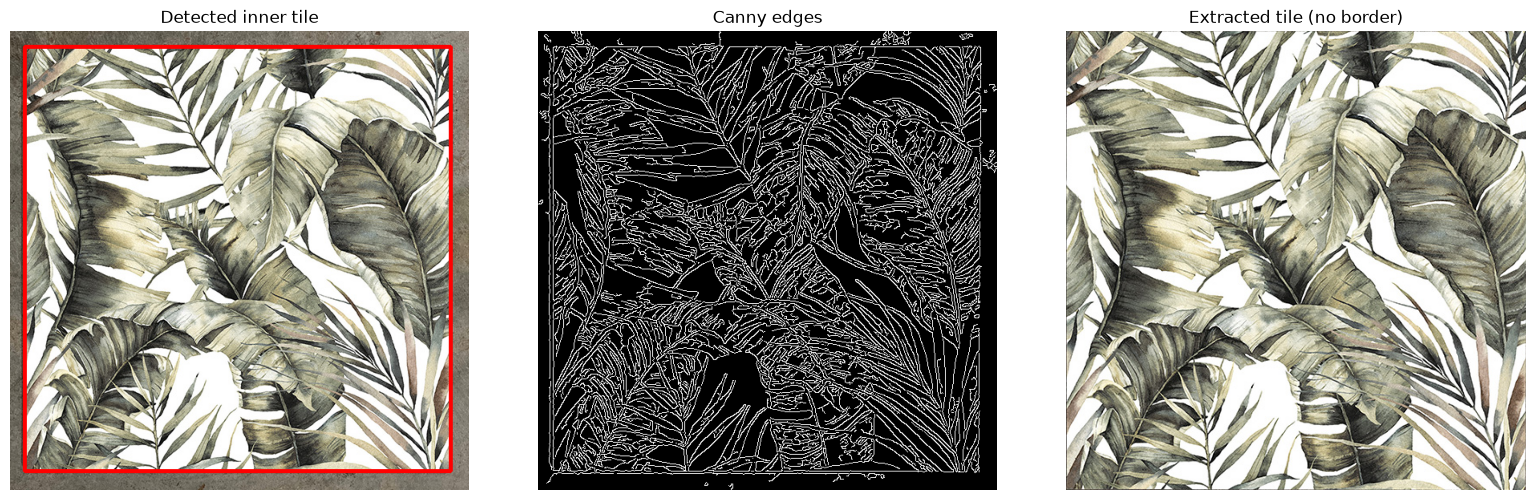

Saved: extracted_tile.png


In [5]:
image = load_image(IMAGE_PATH)
rectangle, edges, diagnostics = detect_tile(image, TILE_WIDTH_MM, TILE_HEIGHT_MM)
print("Boundary (x0, y0, x1, y1):", rectangle, diagnostics)
extracted = preview(image, rectangle, edges)
cv2.imwrite(OUTPUT_PATH, extracted)
print("Saved:", OUTPUT_PATH)


In [7]:
import io, math, json
import numpy as np
import cv2
import matplotlib.pyplot as plt
import ipywidgets as widgets
from PIL import Image, ImageDraw
from IPython.display import display, clear_output
from shapely.geometry import Polygon, box, MultiPolygon, GeometryCollection

UNIT = {"mm":1,"cm":10,"m":1000,"in":25.4,"ft":304.8}
def measure(label, default, unit):
    n=widgets.FloatText(value=default,description=label,style={"description_width":"120px"})
    u=widgets.Dropdown(options=list(UNIT),value=unit,layout=widgets.Layout(width="85px"))
    return n,u,widgets.HBox([n,u])
def mm(n,u):return float(n.value)*UNIT[u.value]

fw,fwu,fwui=measure("Floor width",2,"m")
fh,fhu,fhui=measure("Floor height",2,"m")
tw,twu,twui=measure("Tile width",600,"mm")
th,thu,thui=measure("Tile height",600,"mm")
gw,gwu,gwui=measure("Grout",3,"mm")
color=widgets.ColorPicker(value="#b0b0b0",description="Grout colour",style={"description_width":"120px"})
shape=widgets.Dropdown(options=["Rectangle","L-shaped (6 sides)","Six-sided (chamfered)","Custom polygon"],description="Floor shape",style={"description_width":"120px"})
custom=widgets.Textarea(value="0,0\n2000,0\n2000,1200\n1400,1200\n1400,2000\n0,2000",description="Vertices (mm)",layout=widgets.Layout(width="450px",height="125px"),style={"description_width":"120px"})
notch_w,notch_wu,notch_wui=measure("Notch width",600,"mm")
notch_h,notch_hu,notch_hui=measure("Notch height",800,"mm")
chamfer,chamferu,chamferui=measure("Chamfer",350,"mm")
corner=widgets.Dropdown(options=["Top left","Top right","Bottom left","Bottom right","Top — centre tile","Top — centre grout","Bottom — centre tile","Bottom — centre grout","Left — centre tile","Left — centre grout","Right — centre tile","Right — centre grout"],description="Layout",style={"description_width":"120px"})
upload=widgets.FileUpload(accept="image/*",multiple=False,description="Select tile image")
image_mode=widgets.Dropdown(options=[("Use original (safe)","original"),("Auto-crop if confident","auto"),("Use manual crop margins","manual")],description="Image handling",style={"description_width":"120px"})
left_margin=widgets.IntSlider(value=0,min=0,max=35,description="Left %",style={"description_width":"120px"})
right_margin=widgets.IntSlider(value=0,min=0,max=35,description="Right %",style={"description_width":"120px"})
top_margin=widgets.IntSlider(value=0,min=0,max=35,description="Top %",style={"description_width":"120px"})
bottom_margin=widgets.IntSlider(value=0,min=0,max=35,description="Bottom %",style={"description_width":"120px"})
preview_button=widgets.Button(description="Preview tile extraction",button_style="info")
generate_button=widgets.Button(description="Generate layout",button_style="success")
preview_out=widgets.Output()
out=widgets.Output()

def get_image():
    val=upload.value
    if not val: raise ValueError("Select a tile image first.")
    entry=next(iter(val.values())) if isinstance(val,dict) else val[0]
    return Image.open(io.BytesIO(bytes(entry["content"]))).convert("RGB")

def detect_inner_tile(pil, tile_ratio=1.0):
    """Conservative border detection: never remove content unless four sides agree.
    Combines Lab and HSV edge profiles, and checks a physically plausible aspect ratio.
    Returns (crop bounds, confidence diagnostic)."""
    rgb=np.asarray(pil.convert("RGB"));h,w=rgb.shape[:2]
    if min(h,w)<60:return (0,0,w,h),"Image too small for automatic crop"
    bgr=cv2.cvtColor(rgb,cv2.COLOR_RGB2BGR)
    lab=cv2.cvtColor(bgr,cv2.COLOR_BGR2LAB).astype(np.float32)
    hsv=cv2.cvtColor(bgr,cv2.COLOR_BGR2HSV).astype(np.float32)
    angle=hsv[:,:,0]*(2*np.pi/180)
    circular=np.stack([hsv[:,:,1]*np.cos(angle),hsv[:,:,1]*np.sin(angle),hsv[:,:,2]],axis=-1)
    def profiles(a):
        dx=np.linalg.norm(np.diff(a,axis=1),axis=2)
        dy=np.linalg.norm(np.diff(a,axis=0),axis=2)
        px=np.quantile(dx,.70,axis=0);py=np.quantile(dy,.70,axis=1)
        return np.convolve(px,np.ones(3)/3,'same'),np.convolve(py,np.ones(3)/3,'same')
    lx,ly=profiles(lab);hx,hy=profiles(circular)
    px=lx/(np.percentile(lx,98)+1e-6)+hx/(np.percentile(hx,98)+1e-6)
    py=ly/(np.percentile(ly,98)+1e-6)+hy/(np.percentile(hy,98)+1e-6)
    # Only consider borders close to the perimeter. Texture motifs in the middle
    # must never be interpreted as the tile boundary.
    def candidates(p,n):
        limit=max(6,int(n*.15))
        left=sorted(range(4,limit),key=lambda i:p[i],reverse=True)[:5]
        right=sorted(range(n-limit,n-4),key=lambda i:p[i],reverse=True)[:5]
        return left,right
    xl,xr=candidates(px,w);yt,yb=candidates(py,h)
    best=None
    for x0 in xl:
        for x1 in xr:
            for y0 in yt:
                for y1 in yb:
                    width=x1-x0;height=y1-y0
                    if width<=0 or height<=0:continue
                    ratio=width/height
                    deviation=abs(np.log(ratio/tile_ratio))
                    if deviation>.10:continue
                    strengths=[px[x0],px[x1],py[y0],py[y1]]
                    # All four sides must have convincing edge evidence.
                    if min(strengths)<1.8:continue
                    score=min(strengths)+.15*sum(strengths)-4*deviation
                    if best is None or score>best[0]:best=(score,(x0+1,y0+1,x1+1,y1+1))
    if best is None:return (0,0,w,h),"No confident inner border; kept original"
    return best[1],f"Candidate border (score {best[0]:.2f}); inspect preview"

def selected_tile(show=False):
    original=get_image();w,h=original.size
    if image_mode.value=="manual":
        x0=round(w*left_margin.value/100);x1=round(w*(1-right_margin.value/100))
        y0=round(h*top_margin.value/100);y1=round(h*(1-bottom_margin.value/100))
        reason="Manual margins"
    elif image_mode.value=="auto":
        x0,y0,x1,y1=detect_inner_tile(original,mm(tw,twu)/mm(th,thu))
        reason="Auto-detection; confirm visually"
    else:
        x0,y0,x1,y1=(0,0,w,h);reason="Original image unchanged"
    if x1-x0<10 or y1-y0<10:raise ValueError("Crop would remove almost all tile pixels.")
    crop=original.crop((x0,y0,x1,y1))
    if show:
        fig,axs=plt.subplots(1,2,figsize=(10,5))
        axs[0].imshow(original);axs[0].add_patch(plt.Rectangle((x0,y0),x1-x0,y1-y0,fill=False,color='red',linewidth=2))
        axs[0].set_title('Original + proposed crop')
        axs[1].imshow(crop);axs[1].set_title('Tile sent to layout')
        for ax in axs:ax.axis('off')
        plt.tight_layout();plt.show()
        print(reason,'| crop bounds:',(x0,y0,x1,y1),'| original size:',(w,h))
    return crop

def floor_polygon():
    W,H=mm(fw,fwu),mm(fh,fhu)
    if min(W,H)<=0:raise ValueError("Floor dimensions must be positive")
    if shape.value=="Rectangle":pts=[(0,0),(W,0),(W,H),(0,H)]
    elif shape.value=="L-shaped (6 sides)":
        nw,nh=mm(notch_w,notch_wu),mm(notch_h,notch_hu)
        if not (0<nw<W and 0<nh<H):raise ValueError("Notch must be smaller than the floor")
        pts=[(0,0),(W,0),(W,H-nh),(W-nw,H-nh),(W-nw,H),(0,H)]
    elif shape.value=="Six-sided (chamfered)":
        c=mm(chamfer,chamferu)
        if not 0<c<min(W,H)/2:raise ValueError("Chamfer must be less than half the shortest side")
        pts=[(c,0),(W-c,0),(W,H-c),(W,H),(0,H),(0,c)]
    else:
        pts=[]
        for line in custom.value.splitlines():
            if not line.strip():continue
            values=line.strip().split(',')
            if len(values)!=2:raise ValueError("Custom vertices: one 'x,y' pair per line, in mm")
            pts.append((float(values[0]),float(values[1])))
        if len(pts)<3:raise ValueError("Need at least 3 polygon vertices")
    polygon=Polygon(pts)
    if not polygon.is_valid or polygon.area<=0:raise ValueError("Polygon is invalid or self-intersecting; list perimeter points in order")
    return polygon

def alignment_modes(label):
    alignments={
        "Top left":("start","start"),"Top right":("end","start"),
        "Bottom left":("start","end"),"Bottom right":("end","end"),
        "Top — centre tile":("centre_tile","start"),"Top — centre grout":("centre_grout","start"),
        "Bottom — centre tile":("centre_tile","end"),"Bottom — centre grout":("centre_grout","end"),
        "Left — centre tile":("start","centre_tile"),"Left — centre grout":("start","centre_grout"),
        "Right — centre tile":("end","centre_tile"),"Right — centre grout":("end","centre_grout")}
    return alignments[label]

def segments(length, tile, grout, mode):
    """Physical tile ranges with texture offset, for corner or centered alignment."""
    pitch = tile + grout
    if mode == "start":
        origin = 0.0
    elif mode == "end":
        origin = length - tile
    elif mode == "centre_tile":
        origin = (length - tile) / 2
    elif mode == "centre_grout":
        origin = length / 2 + grout / 2
    else:
        raise ValueError("Unknown alignment")
    # Full tile start positions are origin + k*pitch.
    kmin = math.floor((-tile-origin)/pitch)+1
    kmax = math.ceil((length-origin)/pitch)-1
    if kmax-kmin > 10000:
        raise ValueError("Too many tiles.")
    result = []
    for k in range(kmin,kmax+1):
        a = origin+k*pitch
        b = a+tile
        left=max(0.,a);right=min(length,b)
        if right-left>1e-8:
            result.append((left,right,left-a,b-right))
    return sorted(result)


def tile_quantity(xs, ys, tile_w, tile_h, image, tolerance=24):
    """Beam-search cutting planner: jointly considers multiple offcuts.

    Pixel checks use only the installed region. Each stock rectangle retains
    coordinates on its original tile. A piece can be turned 180°, not mirrored.
    The search tries several cutting plans rather than committing greedily.
    This is still an estimate, not a proof of global optimality.
    """
    import numpy as np
    from PIL import Image as PILImage

    eps = 1e-5
    # Fixed full-tile image grid; physical positions map to these coordinates.
    rw = 250
    rh = max(1, round(rw * tile_h / tile_w))
    ref = np.asarray(image.convert("RGB").resize(
        (rw, rh), PILImage.Resampling.BILINEAR), dtype=np.int16)

    def crop(x, y, w, h):
        x0 = max(0, min(rw - 1, round(x / tile_w * rw)))
        y0 = max(0, min(rh - 1, round(y / tile_h * rh)))
        x1 = max(x0 + 1, min(rw, round((x + w) / tile_w * rw)))
        y1 = max(y0 + 1, min(rh, round((y + h) / tile_h * rh)))
        return ref[y0:y1, x0:x1]

    def error(x, y, source_w, source_h, target, angle):
        part = crop(x, y, source_w, source_h)
        # np.rot90 uses counterclockwise rotations; 90/270 are now supported.
        part = np.rot90(part, k=angle // 90)
        if part.shape != target.shape:
            part = np.asarray(PILImage.fromarray(part.astype("uint8")).resize(
                (target.shape[1], target.shape[0]),
                PILImage.Resampling.BILINEAR), dtype=np.int16)
        return float(np.mean(np.abs(part - target)))

    pieces = [(x1-x0, y1-y0, xc, yc, x0, y0)
              for y0,y1,yc,_ in ys for x0,x1,xc,_ in xs]
    full = sum(w >= tile_w-eps and h >= tile_h-eps for w,h,*_ in pieces)
    cuts = [p for p in pieces if p[0]<tile_w-eps or p[1]<tile_h-eps]
    # Largest pieces first is useful for packing, but several packing states
    # are retained at every step (beam search).
    cuts.sort(key=lambda p: (p[0]*p[1], max(p[:2])), reverse=True)

    def split(rect, px, py, w, h):
        tid, fx, fy, fw, fh = rect
        left, right = px-fx, fx+fw-px-w
        top, bottom = py-fy, fy+fh-py-h
        v = [(tid,fx,fy,left,fh),(tid,px+w,fy,right,fh),
             (tid,px,fy,w,top),(tid,px,py+h,w,bottom)]
        hsplit = [(tid,fx,fy,fw,top),(tid,fx,py+h,fw,bottom),
                  (tid,fx,py,left,h),(tid,px+w,py,right,h)]
        return [tuple(r for r in option if r[3]>eps and r[4]>eps)
                for option in (v,hsplit)]

    def placements(rect, w, h, tx, ty, target):
        _,fx,fy,fw,fh = rect
        matches = []
        for angle in (0, 90, 180, 270):
            # Dimensions BEFORE rotation: 90/270 swap width and height.
            sw, sh = (h, w) if angle in (90,270) else (w,h)
            if fw+eps < sw or fh+eps < sh:
                continue
            # Exact inverse-rotation reference coordinates are always tried.
            if angle == 0:
                reference = (tx,ty)
            elif angle == 90:
                reference = (tile_w-ty-sh,tx)
            elif angle == 180:
                reference = (tile_w-tx-sw,tile_h-ty-sh)
            else:
                reference = (ty,tile_h-tx-sw)
            coords = [reference,(tx,ty),
                      (tile_w-tx-sw,tile_h-ty-sh)]
            coords += [(x,y) for x in (fx,fx+fw-sw)
                       for y in (fy,fy+fh-sh)]
            nx = min(8,max(1,round((fw-sw)/max(tile_w/12,1))))
            ny = min(8,max(1,round((fh-sh)/max(tile_h/12,1))))
            coords += [(fx+(fw-sw)*i/nx,fy+(fh-sh)*j/ny)
                       for i in range(nx+1) for j in range(ny+1)]
            seen = set()
            for px,py in coords:
                if (px < fx-eps or py < fy-eps or
                    px+sw > fx+fw+eps or py+sh > fy+fh+eps):
                    continue
                key = (round(px,4),round(py,4))
                if key in seen:
                    continue
                seen.add(key)
                score = error(px,py,sw,sh,target,angle)
                if score <= tolerance:
                    matches.append((score,px,py,angle,sw,sh))
        matches.sort()
        return matches[:12]

    # State: (new tile count, reuse count, rotations, free rectangles,
    #         cutting instructions, accumulated pattern error)
    states = [(0,0,0,tuple(),tuple(),0.)]
    beam_width = 70
    for w,h,tx,ty,dx,dy in cuts:
        target=crop(tx,ty,w,h)
        next_states=[]
        for new,reuse,rot,free,plan,score in states:
            # Existing stock first, but retain alternatives.
            for idx,rect in enumerate(free):
                for e,px,py,angle,sw,sh in placements(rect,w,h,tx,ty,target):
                    for remnants in split(rect,px,py,sw,sh):
                        updated=free[:idx]+free[idx+1:]+remnants
                        step=(rect[0],round(px,2),round(py,2),
                              round(sw,2),round(sh,2),angle)
                        next_states.append((new,reuse+1,rot+int(angle!=0),
                                            updated,plan+(step,),score+e))
            # A fresh tile is always a valid fallback, and must be allowed
            # even if an offcut also fits (to improve later cuts).
            rect=(new+1,0.,0.,tile_w,tile_h)
            for remnants in split(rect,tx,ty,w,h):
                step=(new+1,round(tx,2),round(ty,2),
                      round(w,2),round(h,2),0)
                next_states.append((new+1,reuse,rot,free+remnants,
                                    plan+(step,),score))
        # Prefer fewer whole tiles, then more reusable stock area and accuracy.
        next_states.sort(key=lambda st:(
            st[0], -max((r[3]*r[4] for r in st[3]),default=0),
            st[5], -st[1]))
        # Deduplicate equivalent material states.
        unique={}
        for st in next_states:
            signature=(st[0],tuple(sorted(
                (r[0],round(r[1],1),round(r[2],1),
                 round(r[3],1),round(r[4],1)) for r in st[3])))
            if signature not in unique:
                unique[signature]=st
            if len(unique)>=beam_width:
                break
        states=list(unique.values())
    new,reused,rotated,free,plan,score=min(states,key=lambda st:(st[0],st[5]))
    total=full+new
    covered=sum(w*h for w,h,*_ in pieces)
    waste=max(0.,total*tile_w*tile_h-covered)
    # Same order as the cutting plan, with physical destination coordinates.
    destinations=tuple((dx,dy,w,h) for w,h,tx,ty,dx,dy in cuts)
    return total,full,new,len(cuts),waste,covered,rotated,reused,plan,destinations



def polygon_parts(geometry):
    if geometry.is_empty:return []
    if geometry.geom_type=='Polygon':return [geometry] if geometry.area>1e-6 else []
    if hasattr(geometry,'geoms'):
        return [p for g in geometry.geoms for p in polygon_parts(g)]
    return []

def render(_=None):
    with out:
        clear_output(wait=True)
        try:
            tile=selected_tile()
            floor=floor_polygon()
            Tw,Th,G=mm(tw,twu),mm(th,thu),mm(gw,gwu)
            if min(Tw,Th)<=0 or G<0:raise ValueError("Invalid tile or grout dimensions")
            xmin,ymin,xmax,ymax=floor.bounds
            W,H=xmax-xmin,ymax-ymin
            xmode,ymode=alignment_modes(corner.value)
            xs=segments(W,Tw,G,xmode);ys=segments(H,Th,G,ymode)
            if len(xs)*len(ys)>1200:raise ValueError("Too many pieces for an interactive preview; increase tile size")
            scale=min(1.5,1800/max(W,H));scale=max(.1,scale)
            cw,ch=max(1,round(W*scale)),max(1,round(H*scale))
            canvas=Image.new('RGB',(cw,ch),'#f1f1f1')
            tile_px=tile.resize((max(1,round(Tw*scale)),max(1,round(Th*scale))),Image.Resampling.LANCZOS)
            grout_color=color.value
            # The floor itself is the clipping region; outside stays light grey.
            floor_mask=Image.new('L',(cw,ch),0);md=ImageDraw.Draw(floor_mask)
            def pix(p):return (round((p[0]-xmin)*scale),round((p[1]-ymin)*scale))
            md.polygon([pix(p) for p in list(floor.exterior.coords)],fill=255)
            for interior in floor.interiors:md.polygon([pix(p) for p in list(interior.coords)],fill=0)
            canvas.paste(Image.new('RGB',(cw,ch),grout_color),(0,0),floor_mask)
            cut_dest=[];whole=0;occupied=0
            for y0,y1,cy,_ in ys:
                for x0,x1,cx,_ in xs:
                    # Local x/y origin is floor bounding-box origin.
                    region=box(xmin+x0,ymin+y0,xmin+x1,ymin+y1)
                    clipped=floor.intersection(region)
                    for part in polygon_parts(clipped):
                        occupied+=1
                        # Preserve source pixel coordinates for pattern continuity.
                        dx0,dy0,dx1,dy1=part.bounds
                        left=round((dx0-xmin)*scale);top=round((dy0-ymin)*scale)
                        right=round((dx1-xmin)*scale);bottom=round((dy1-ymin)*scale)
                        if right<=left or bottom<=top:continue
                        sx=round((cx+(dx0-(xmin+x0)))/Tw*tile_px.width)
                        sy=round((cy+(dy0-(ymin+y0)))/Th*tile_px.height)
                        sw=right-left;sh=bottom-top
                        tex=tile_px.crop((sx,sy,min(tile_px.width,sx+sw),min(tile_px.height,sy+sh)))
                        if tex.size!=(sw,sh):tex=tex.resize((sw,sh),Image.Resampling.BILINEAR)
                        mask=Image.new('L',(sw,sh),0);d=ImageDraw.Draw(mask)
                        d.polygon([(round((x-dx0)*scale),round((y-dy0)*scale)) for x,y in part.exterior.coords],fill=255)
                        for interior in part.interiors:
                            d.polygon([(round((x-dx0)*scale),round((y-dy0)*scale)) for x,y in interior.coords],fill=0)
                        canvas.paste(tex,(left,top),mask)
                        if abs(part.area-Tw*Th)<.05:
                            whole+=1
                        else:
                            cut_dest.append((part, (dx0,dy0,dx1,dy1)))
            fig,ax=plt.subplots(figsize=(11,8))
            ax.imshow(canvas,extent=(xmin,xmax,ymax,ymin))
            ax.set_xlim(xmin,xmax);ax.set_ylim(ymax,ymin)
            ax.set_aspect('equal')
            ax.set_xlabel('X (mm)');ax.set_ylabel('Y (mm)')
            ax.set_title(f'{shape.value} | {corner.value} | grout {G:g} mm')
            # Display floor boundary and coordinates.
            bx,by=floor.exterior.xy
            ax.plot(bx,by,color='black',linewidth=1.5)
            # For rectangles use the V13 planner's exact destination order.
            # For polygons use the order of clipped boundary pieces.
            rectangle_result = tile_quantity(xs,ys,Tw,Th,tile) if shape.value=='Rectangle' else None
            if rectangle_result is not None:
                label_points=[(xmin+dx+pw/2,ymin+dy+ph/2) for dx,dy,pw,ph in rectangle_result[-1]]
            else:
                label_points=[(part.representative_point().x,part.representative_point().y) for part,_ in cut_dest]
            for i,(label_x,label_y) in enumerate(label_points,1):
                ax.text(label_x,label_y,f'C{i}',ha='center',va='center',fontsize=8,
                        bbox=dict(facecolor='white',alpha=.9,edgecolor='black',boxstyle='round,pad=.15'))
            fig.tight_layout();plt.show();plt.close(fig)
            print(f'Floor area: {floor.area/1e6:.3f} m² | Tile: {Tw:g} × {Th:g} mm | Grout: {G:g} mm')
            print(f'Uncut tiles: {whole} | Boundary pieces: {len(cut_dest)}')
            if shape.value=='Rectangle':
                # Preserve the original V13 material reuse logic for rectangles.
                total,full,additional,cuts,waste,covered,rotated,reused,plan,destinations=rectangle_result
                print(f'Pattern-aware estimated whole tiles: {total} ({full} uncut + {additional} for cuts)')
                print(f'Reused cut pieces: {reused} | Rotated: {rotated} | Leftover: {waste/1e6:.3f} m²')
                for i,((tid,px,py,pw,ph,angle),(dx,dy,dw,dh)) in enumerate(zip(plan,destinations),1):
                    print(f'C{i}: source tile {tid} at ({px:g},{py:g}) mm; cut {pw:g} × {ph:g} mm; rotate {angle}°; install ({dx:g},{dy:g}) mm')
                print('Cutting plan is heuristic; does not include saw kerf or breakage.')
            else:
                # Irregular pieces are polygons, NOT rectangular cut stock.
                # A rectangle-based offcut planner would produce unsafe counts.
                lower_bound=math.ceil(floor.area/(Tw*Th))
                print(f'Area-only theoretical lower bound (ignores grout/cutting): {lower_bound} tiles')
                print('Exact whole-tile purchase estimate: NOT YET COMPUTED for polygon-shaped offcuts.')
                print('Boundary piece labels and shape are shown; a polygon cutting-stock solver is needed for reliable reuse.')
                for i,(part,bounds) in enumerate(cut_dest,1):
                    print(f'C{i}: bounding box ({bounds[0]:.1f},{bounds[1]:.1f}) to ({bounds[2]:.1f},{bounds[3]:.1f}) mm; area {part.area/1e6:.4f} m²')
        except Exception as exc:
            import traceback
            traceback.print_exc(limit=2)

def preview(_=None):
    with preview_out:
        clear_output(wait=True)
        try:selected_tile(show=True)
        except Exception as exc:print('Preview error:',exc)

def shape_visibility(_=None):
    custom.layout.display='block' if shape.value=='Custom polygon' else 'none'
    notch_wui.layout.display=notch_hui.layout.display='flex' if shape.value=='L-shaped (6 sides)' else 'none'
    chamferui.layout.display='flex' if shape.value=='Six-sided (chamfered)' else 'none'
shape.observe(shape_visibility,names='value');shape_visibility()
preview_button.on_click(preview);generate_button.on_click(render)
display(widgets.VBox([
    widgets.HTML('<h3>Tile Visualizer V14 — Image + Polygon Floors</h3><b>Floor</b>'),
    shape,fwui,fhui,notch_wui,notch_hui,chamferui,custom,
    widgets.HTML('<b>Tile and grout</b>'),twui,thui,gwui,color,corner,
    widgets.HTML('<b>Tile photograph / image</b>'),upload,image_mode,
    widgets.HTML('Manual crop margins (used only in manual mode):'),
    left_margin,right_margin,top_margin,bottom_margin,
    preview_button,preview_out,generate_button,out
]))


In [ ]:
"""Tile visualizer: polygon floors, actual offcut preview and illustrated instructions.
Run in Jupyter with %run tile_visualizer_shapes.py, or use the supplied notebook.
All geometry is millimetres; x is right and y is down. Rotations are clockwise.
"""
import io, math
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as PlotPolygon
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output
from shapely.geometry import Polygon, box
from shapely.affinity import affine_transform, translate, rotate
from shapely import contains_xy

EPS = 1e-6
ALIGNMENTS = {
    'Top left': ('start','start'), 'Top right': ('end','start'),
    'Bottom left': ('start','end'), 'Bottom right': ('end','end'),
    'Top — centre tile': ('centre_tile','start'), 'Top — centre grout': ('centre_grout','start'),
    'Bottom — centre tile': ('centre_tile','end'), 'Bottom — centre grout': ('centre_grout','end'),
    'Left — centre tile': ('start','centre_tile'), 'Left — centre grout': ('start','centre_grout'),
    'Right — centre tile': ('end','centre_tile'), 'Right — centre grout': ('end','centre_grout')}


def polygons(g):
    if g.is_empty:
        return []
    if g.geom_type == 'Polygon':
        return [g] if g.area > EPS else []
    return [p for part in getattr(g, 'geoms', []) for p in polygons(part)]


def make_floor(shape, width, height, notch_w=0, notch_h=0, notch_corner='Top right', custom=''):
    if not all(math.isfinite(v) and v > 0 for v in (width,height)):
        raise ValueError('Floor width and length must be positive finite numbers.')
    if shape == 'Rectangle':
        p = box(0,0,width,height)
    elif shape == 'Triangle':
        p = Polygon([(width/2,0),(width,height),(0,height)])
    elif shape == 'Right triangle':
        p = Polygon([(0,0),(width,height),(0,height)])
    elif shape == 'Rhombus / diamond':
        p = Polygon([(width/2,0),(width,height/2),(width/2,height),(0,height/2)])
    elif shape == 'L-shaped':
        if not (0 < notch_w < width and 0 < notch_h < height):
            raise ValueError('L-shape missing-corner width/length must be smaller than the floor.')
        x = width-notch_w if 'right' in notch_corner.lower() else 0
        y = 0 if 'top' in notch_corner.lower() else height-notch_h
        p = box(0,0,width,height).difference(box(x,y,x+notch_w,y+notch_h))
    elif shape == 'Custom polygon':
        try:
            points = [tuple(map(float,line.replace(',',' ').split())) for line in custom.splitlines() if line.strip()]
            if len(points)<3 or any(len(v)!=2 for v in points):
                raise ValueError()
            p = Polygon(points)
        except Exception:
            raise ValueError('Custom floor: enter one x,y pair per line, in mm, in boundary order.')
        if not p.is_valid or p.is_empty or p.area <= EPS:
            raise ValueError('Custom outline crosses itself or has zero area. List corners around the boundary.')
        if p.bounds[0] < 0 or p.bounds[1] < 0:
            raise ValueError('Custom floor coordinates must be zero or positive.')
        # Width/length are derived from the custom outline, with a common top-left origin.
        p = translate(p, -p.bounds[0], -p.bounds[1])
    else:
        raise ValueError('Unknown floor shape.')
    return p


def origin(lo, hi, tile, grout, mode):
    if mode=='start': return lo
    if mode=='end': return hi-tile
    if mode=='centre_tile': return (lo+hi-tile)/2
    return (lo+hi+grout)/2


@dataclass
class Piece:
    target: object                 # Installed shape in original tile coordinates.
    floor: object                  # Same shape in room coordinates.
    x: float                       # Tile origin in lattice frame.
    y: float
    grid_angle: float
    full: bool
    label: str = ''


def make_pieces(floor, tw, th, grout, alignment='Top left', layout='Straight'):
    if not all(math.isfinite(v) for v in (tw,th,grout)) or min(tw,th)<=0 or grout<0:
        raise ValueError('Tile sizes must be positive; grout must be zero or positive.')
    angle = 45 if layout=='Diagonal 45°' else 0
    grid_floor = rotate(floor, -angle, origin=(0,0))
    xmin,ymin,xmax,ymax = grid_floor.bounds
    ax,ay = ALIGNMENTS[alignment]
    ox = origin(xmin,xmax,tw,grout,ax)
    oy = origin(ymin,ymax,th,grout,ay)
    pitchx,pitchy=tw+grout,th+grout
    r0=math.floor((ymin-oy-th)/pitchy)+1
    r1=math.ceil((ymax-oy)/pitchy)
    estimated=(r1-r0)*(math.ceil((xmax-xmin)/pitchx)+3)
    if estimated>2500:
        raise ValueError('More than 2,500 candidate tiles. Increase tile size or reduce floor size.')
    result=[]
    for row in range(r0,r1):
        y=oy+row*pitchy
        shift=pitchx/2 if layout=='Half-offset / brick' and row%2 else 0
        xbase=ox+shift
        c0=math.floor((xmin-xbase-tw)/pitchx)+1
        c1=math.ceil((xmax-xbase)/pitchx)
        for col in range(c0,c1):
            x=xbase+col*pitchx
            clipped=grid_floor.intersection(box(x,y,x+tw,y+th))
            # A grid cell can meet disconnected arms of a custom floor: separate pieces.
            for p in polygons(clipped):
                local=translate(p,-x,-y)
                full=abs(local.area-tw*th)<=max(EPS,tw*th*1e-10)
                result.append(Piece(local,rotate(p,angle,origin=(0,0)),x,y,angle,full))
    if not result:
        raise ValueError('No tile intersects this floor. Reduce grout or choose another alignment.')
    if sum(not p.full for p in result)>160:
        raise ValueError('More than 160 cut pieces. Use larger tiles or plan the floor in sections.')
    for i,p in enumerate(sorted((p for p in result if not p.full),key=lambda p:(p.floor.bounds[1],p.floor.bounds[0])),1):
        p.label=f'C{i}'
    return result


class Pattern:
    """Compare actual physical positions, without stretching a candidate to fit."""
    def __init__(self,image,tw,th,mode='Strict pattern',tolerance=24):
        self.tw,self.th,self.mode,self.tolerance=tw,th,mode,tolerance
        self.ref=np.asarray(image.convert('RGB'),dtype=np.float32)
        self.cache={}

    def sample(self,x,y):
        h,w=self.ref.shape[:2]
        u=np.clip(np.asarray(x)/self.tw*w-0.5,0,w-1)
        v=np.clip(np.asarray(y)/self.th*h-0.5,0,h-1)
        x0=np.floor(u).astype(int); y0=np.floor(v).astype(int)
        x1=np.minimum(x0+1,w-1); y1=np.minimum(y0+1,h-1)
        fx=(u-x0)[...,None]; fy=(v-y0)[...,None]
        return ((1-fx)*(1-fy)*self.ref[y0,x0]+fx*(1-fy)*self.ref[y0,x1]
                +(1-fx)*fy*self.ref[y1,x0]+fx*fy*self.ref[y1,x1])

    def target_samples(self,p,dense=False):
        key=(p.target.wkb,dense)
        if key not in self.cache:
            x0,y0,x1,y1=p.target.bounds
            # Dense acceptance check: up to 512 samples per axis, including thin pieces.
            cap=512 if dense else 40
            iw,ih=self.ref.shape[1],self.ref.shape[0]
            nx=max(4,min(cap,math.ceil((x1-x0)/self.tw*iw)))
            ny=max(4,min(cap,math.ceil((y1-y0)/self.th*ih)))
            xx,yy=np.meshgrid(x0+(np.arange(nx)+.5)*(x1-x0)/nx,
                              y0+(np.arange(ny)+.5)*(y1-y0)/ny)
            mask=contains_xy(p.target,xx,yy)
            x,y=xx[mask],yy[mask]
            if not len(x):
                rp=p.target.representative_point(); x=np.array([rp.x]); y=np.array([rp.y])
            self.cache[key]=(x,y,self.sample(x,y))
        return self.cache[key]

    def check(self, p, angle, bx, by, dense=False):
        # Keep the existing optional modes.
        if self.mode == "Ignore pattern":
            return True, 0.0

        if angle == 0 and bx == 0 and by == 0:
            return True, 0.0

        if self.mode == "Exact source position":
            return False, float("inf")

        # Both Strict and Relaxed now require an EXACT pixel match.
        # The tolerance slider is no longer used.
        key = ("exact_pixels", p.target.wkb, angle, bx, by)
        if key in self.cache:
            return self.cache[key]

        def finish(matches):
            result = (matches, 0.0 if matches else float("inf"))
            self.cache[key] = result
            return result

        ih, iw = self.ref.shape[:2]
        pixel_w = self.tw / iw
        pixel_h = self.th / ih
        c, s = trig(angle)

        # Map target pixel centres onto source pixel centres.
        matrix = np.array([
            [c, s * pixel_h / pixel_w],
            [-s * pixel_w / pixel_h, c]
        ])

        offset = np.array([
            bx / pixel_w,
            by / pixel_h
        ]) + matrix @ np.array([0.5, 0.5]) - 0.5

        integer_matrix = np.rint(matrix).astype(int)
        integer_offset = np.rint(offset).astype(int)

        # Reject subpixel alignment or scaling instead of interpolating
        # pixels and accidentally accepting a different pattern.
        if (
            not np.allclose(matrix, integer_matrix, atol=1e-7, rtol=0)
            or not np.allclose(offset, integer_offset, atol=1e-7, rtol=0)
            or not np.all(np.abs(integer_matrix).sum(axis=0) == 1)
            or not np.all(np.abs(integer_matrix).sum(axis=1) == 1)
        ):
            return finish(False)

        x0, y0, x1, y1 = p.target.bounds
        left = max(0, math.floor(x0 / pixel_w))
        right = min(iw, math.ceil(x1 / pixel_w))
        top = max(0, math.floor(y0 / pixel_h))
        bottom = min(ih, math.ceil(y1 / pixel_h))

        checked = False

        # Check every original pixel centre inside the required shape.
        # Process rows in blocks to limit memory usage.
        for row in range(top, bottom, 128):
            xx, yy = np.meshgrid(
                np.arange(left, right),
                np.arange(row, min(row + 128, bottom))
            )

            inside = contains_xy(
                p.target,
                (xx + 0.5) * pixel_w,
                (yy + 0.5) * pixel_h
            )

            tx, ty = xx[inside], yy[inside]
            if tx.size == 0:
                continue

            checked = True

            sx = (
                integer_matrix[0, 0] * tx
                + integer_matrix[0, 1] * ty
                + integer_offset[0]
            )
            sy = (
                integer_matrix[1, 0] * tx
                + integer_matrix[1, 1] * ty
                + integer_offset[1]
            )

            if np.any(
                (sx < 0) | (sx >= iw) |
                (sy < 0) | (sy >= ih)
            ):
                return finish(False)

            if not np.array_equal(
                self.ref[ty, tx],
                self.ref[sy, sx]
            ):
                return finish(False)

        # Reject pieces too thin to verify at the image's resolution.
        return finish(checked)



def trig(angle):
    return round(math.cos(math.radians(angle)),12),round(math.sin(math.radians(angle)),12)


def source_shape(p,angle,bx,by):
    c,s=trig(angle)
    return affine_transform(p.target,[c,s,-s,c,bx,by])


def candidate_offsets(p,free,angle,tw,th):
    base=source_shape(p,angle,0,0)
    x0,y0,x1,y1=base.bounds
    coords=[(0.,0.)]
    # Full-tile rotation reference; especially useful for symmetric square textures.
    if angle==90: coords.append((0.,th))
    if angle==180: coords.append((tw,th))
    if angle==270: coords.append((tw,0.))
    for region in polygons(free):
        fx,fy,ex,ey=region.bounds
        if ex-fx+EPS<x1-x0 or ey-fy+EPS<y1-y0: continue
        coords += [(x,y) for x in (fx-x0,ex-x1) for y in (fy-y0,ey-y1)]
        # Align vertices: permits complementary triangular offcuts, not just boxes.
        sv=list(base.exterior.coords)[:-1]
        fv=list(region.exterior.coords)[:-1]
        coords += [(qx-px,qy-py) for qx,qy in fv[:32] for px,py in sv[:16]]
        coords += [(x,y) for x in np.linspace(fx-x0,ex-x1,3) for y in np.linspace(fy-y0,ey-y1,3)]
    seen=set()
    for bx,by in coords:
        key=(round(bx,6),round(by,6))
        if key not in seen:
            seen.add(key); yield bx,by


@dataclass
class Cut:
    piece: Piece
    tid: int
    angle: int
    bx: float
    by: float
    source: object
    error: float
    reused: bool


def plan_cuts(pieces,tw,th,pattern,kerf=0,allow_rotation=True,progress=None):
    if not math.isfinite(kerf) or kerf<0: raise ValueError('Blade width must be zero or positive.')
    stock=box(0,0,tw,th)
    cuts=[p for p in pieces if not p.full]
    # Try three placement orders; retain the best complete, physically validated plan.
    orders=[sorted(cuts,key=lambda p:p.target.area,reverse=True),
            sorted(cuts,key=lambda p:max(p.target.bounds[2]-p.target.bounds[0],p.target.bounds[3]-p.target.bounds[1]),reverse=True),
            sorted(cuts,key=lambda p:int(p.label[1:]))]
    best=None
    # Pattern acceptance is independent of the current free stock geometry.
    acceptance={}
    for order_idx,order in enumerate(orders):
        free=[]; plan=[]
        for index,p in enumerate(order):
            found=None
            for tid,region in enumerate(free,1):
                for angle in ((0,90,180,270) if allow_rotation else (0,)):
                    if pattern.mode=='Exact source position' and angle: continue
                    for bx,by in candidate_offsets(p,region,angle,tw,th):
                        shape=source_shape(p,angle,bx,by)
                        if not region.buffer(EPS).covers(shape): continue
                        key=(p.label,angle,round(bx,6),round(by,6))
                        if key not in acceptance:
                            ok,error=pattern.check(p,angle,bx,by)
                            if ok: ok,error=pattern.check(p,angle,bx,by,dense=True)
                            acceptance[key]=(ok,error)
                        ok,error=acceptance[key]
                        if ok:
                            # Prefer exact image match, then compact use of a stock tile.
                            rank=(error,region.area-shape.area,angle,tid)
                            if found is None or rank<found[0]:
                                found=(rank,tid,angle,bx,by,shape,error)
                            if error==0: break
                    if found is not None and found[-1]==0: break
                if found is not None and found[-1]==0: break
            if found is None:
                tid=len(free)+1; free.append(stock)
                angle,bx,by,shape,error=0,0.,0.,p.target,0.
                reused=False
            else:
                _,tid,angle,bx,by,shape,error=found
                reused=True
            # Reserve blade width outside the retained piece; no kerf into installed area.
            removed=shape.buffer(kerf,join_style=2) if kerf else shape
            free[tid-1]=free[tid-1].difference(removed)
            plan.append(Cut(p,tid,angle,bx,by,shape,error,reused))
            if progress: progress(order_idx*len(order)+index+1,max(1,3*len(order)))
        rank=(len(free),sum(c.error for c in plan))
        if best is None or rank<best[0]: best=(rank,plan,free)
    _,plan,free=best
    validate_plan(plan,tw,th,kerf)
    # Keep C numbers sequential in the actual cutting order, as in the original report.
    for number,cut in enumerate(plan,1): cut.piece.label=f'C{number}'
    return plan,free


def validate_plan(plan,tw,th,kerf):
    stock=box(0,0,tw,th); occupied={}
    for cut in plan:
        if not stock.buffer(EPS).covers(cut.source):
            raise RuntimeError('A cut extends outside its source tile.')
        if abs(cut.source.area-cut.piece.target.area)>max(EPS,cut.source.area*1e-9):
            raise RuntimeError('A cut changed size during rotation.')
        for previous in occupied.get(cut.tid,[]):
            if cut.source.intersection(previous).area>EPS:
                raise RuntimeError('Two cuts overlap on a source tile.')
            if kerf and cut.source.distance(previous)<kerf-1e-5:
                raise RuntimeError('Cuts do not leave the selected blade allowance.')
        occupied.setdefault(cut.tid,[]).append(cut.source)


def vertices(poly):
    # Start at top-most, then left-most point; stable labels in report and drawing.
    pts=list(poly.simplify(1e-7,preserve_topology=True).exterior.coords)[:-1]
    first=min(range(len(pts)),key=lambda i:(pts[i][1],pts[i][0]))
    return pts[first:]+pts[:first]


def fmt(v): return f'{v:.1f}'.rstrip('0').rstrip('.')


def draw_outline(ax,p,color='black',lw=1):
    for poly in polygons(p):
        ax.add_patch(PlotPolygon(np.asarray(poly.exterior.coords),fill=False,edgecolor=color,linewidth=lw))
        for ring in poly.interiors:
            ax.add_patch(PlotPolygon(np.asarray(ring.coords),fill=False,edgecolor=color,linewidth=lw))


def render_canvas(floor,pieces,plan,pattern,grout_color='#b0b0b0',max_pixels=1400):
    _,_,width,height=floor.bounds
    scale=min(1.5,max_pixels/max(width,height))
    pw,ph=max(1,math.ceil(width*scale)),max(1,math.ceil(height*scale))
    from PIL import ImageColor
    canvas=np.full((ph,pw,3),250,dtype=np.uint8)
    xx,yy=np.meshgrid((np.arange(pw)+.5)/pw*width,(np.arange(ph)+.5)/ph*height)
    mask=contains_xy(floor,xx,yy)
    canvas[mask]=ImageColor.getrgb(grout_color)
    lookup={c.piece.label:c for c in plan}
    for p in pieces:
        x0,y0,x1,y1=p.floor.bounds
        ix0=max(0,int(x0/width*pw)); ix1=min(pw,math.ceil(x1/width*pw))
        iy0=max(0,int(y0/height*ph)); iy1=min(ph,math.ceil(y1/height*ph))
        gx,gy=xx[iy0:iy1,ix0:ix1],yy[iy0:iy1,ix0:ix1]
        inside=contains_xy(p.floor,gx,gy)
        if not inside.any(): continue
        c,s=trig(p.grid_angle)
        tx=c*gx+s*gy-p.x; ty=-s*gx+c*gy-p.y
        if p.full: sx,sy=tx,ty
        else:
            cut=lookup[p.label]; c,s=trig(cut.angle)
            sx=c*tx+s*ty+cut.bx; sy=-s*tx+c*ty+cut.by
        rgb=np.clip(pattern.sample(sx,sy),0,255).astype(np.uint8)
        canvas[iy0:iy1,ix0:ix1][inside]=rgb[inside]
    return canvas


def show_floor(floor,pieces,plan,pattern,layout,alignment,grout,grout_color):
    _,_,w,h=floor.bounds
    fig,ax=plt.subplots(figsize=(11,8))
    ax.imshow(render_canvas(floor,pieces,plan,pattern,grout_color),extent=(0,w,h,0))
    draw_outline(ax,floor,lw=1.7)
    for p in pieces:
        if not p.full:
            point=p.floor.representative_point()
            ax.text(point.x,point.y,p.label,ha='center',va='center',fontsize=8,fontweight='bold',
                    bbox=dict(facecolor='white',edgecolor='black',alpha=.88,boxstyle='round,pad=.18'))
    ax.set(xlim=(0,w),ylim=(h,0),xlabel='Floor width (mm)',ylabel='Floor length (mm)',
           title=f'Actual selected pieces — {layout} | {alignment} | grout {grout:g} mm')
    ax.set_aspect('equal'); fig.tight_layout(); plt.show()
    return fig


def show_sources(plan,tw,th,image):
    count=max((c.tid for c in plan),default=0)
    for start in range(1,count+1,6):
        ids=list(range(start,min(count+1,start+6)))
        fig,axes=plt.subplots(math.ceil(len(ids)/3),min(3,len(ids)),figsize=(12,4*math.ceil(len(ids)/3)),squeeze=False)
        for ax,tid in zip(axes.flat,ids):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.6)
            for cut in (c for c in plan if c.tid==tid):
                draw_outline(ax,cut.source,color='black',lw=2)
                point=cut.source.representative_point()
                ax.text(point.x,point.y,cut.piece.label,ha='center',va='center',fontweight='bold',
                        bbox=dict(facecolor='white',alpha=.85,edgecolor='none'))
            ax.set(title=f'SOURCE TILE {tid} — keep image upright',xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.03,tw*1.03),ylim=(th*1.03,-th*.03),aspect='equal')
        for ax in list(axes.flat)[len(ids):]: ax.axis('off')
        fig.tight_layout(); plt.show()
    # Individual marking cards keep corner numbers legible when offcuts touch.
    for start in range(0,len(plan),4):
        group=plan[start:start+4]
        fig,axes=plt.subplots(math.ceil(len(group)/2),min(2,len(group)),
                              figsize=(11,5*math.ceil(len(group)/2)),squeeze=False)
        for ax,cut in zip(axes.flat,group):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.4)
            draw_outline(ax,cut.source,lw=2)
            for k,(x,y) in enumerate(vertices(cut.source),1):
                ax.plot(x,y,'ro',ms=4)
                ax.annotate(str(k),(x,y),xytext=(5,5),textcoords='offset points',
                            color='darkred',fontweight='bold',fontsize=10)
            ax.set(title=f'{cut.piece.label} — mark on SOURCE TILE {cut.tid}',
                   xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.04,tw*1.08),ylim=(th*1.04,-th*.08),aspect='equal')
        for ax in list(axes.flat)[len(group):]: ax.axis('off')
        fig.tight_layout(); plt.show()


def report(floor,pieces,plan,free,tw,th,grout,layout,alignment,pattern,kerf):
    _,_,Wmm,Hmm=floor.bounds
    full=sum(p.full for p in pieces); cut_tiles=len(free); total=full+cut_tiles
    cut_pieces=len(plan); reused=sum(c.reused for c in plan); rotated=sum(c.angle!=0 for c in plan)
    covered=sum(p.target.area for p in pieces)
    waste=max(0,total*tw*th-covered)
    print(f'FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {tw:g} × {th:g} mm | GROUT: {grout:g} mm')
    print(f'FLOOR AREA: {floor.area/1_000_000:.3f} m² | TILE ARRANGEMENT: {layout}')
    cols=len({round(p.x,6) for p in pieces}); rows=len({round(p.y,6) for p in pieces})
    if layout=='Straight': print(f'LAYOUT: {alignment} | {cols} columns × {rows} rows (some positions may be outside the floor)')
    else: print(f'LAYOUT: {alignment} | {rows} tile rows')
    print(f'Each full tile is {tw:g} × {th:g} mm; each interior grout joint is {grout:g} mm.')
    if floor.equals(box(0,0,Wmm,Hmm)) and layout=='Straight':
        for name,index,size,limit in [('X',0,tw,Wmm),('Y',1,th,Hmm)]:
            ranges=sorted({(max(0,p.x if index==0 else p.y),min(limit,(p.x if index==0 else p.y)+size)) for p in pieces})
            print(f'{name} tile ranges (mm):',', '.join(f'{a:g}–{b:g}' for a,b in ranges))
            for side,(a,b) in [('first',ranges[0]),('last',ranges[-1])]:
                if b-a<size-1e-7: print(f'  {name} {side} boundary cut: {b-a:g} mm (trim {size-b+a:g} mm)')
        ordered=sorted(pieces,key=lambda p:(p.y,p.x))
        for label,p in [('Top-left',ordered[0]),('Bottom-right',ordered[-1])]:
            a,b,c,d=p.target.bounds; print(f'{label} piece: {c-a:g} × {d-b:g} mm')
    print('\nPATTERN-AWARE TILE QUANTITY (including permitted rotations)')
    print(f'Full uncut tiles: {full}')
    print(f'Cut pieces required: {cut_pieces}')
    print(f'Additional whole tiles for cuts: {cut_tiles}')
    print(f'Cut pieces taken from existing offcuts: {reused}')
    print(f'Pieces installed after rotation: {rotated}')
    print(f'TOTAL WHOLE TILES NEEDED: {total}')
    print(f'Estimated leftover tile material: {waste/1_000_000:.3f} m² (includes blade loss)')
    print(f'Blade allowance: {kerf:g} mm outside kept shapes. Breakage and spare tiles are not included.')
    print('Offcuts must fit physically AND match the visible pattern.' if pattern.mode!='Ignore pattern' else 'PATTERN MATCHING IS OFF — physical fit only.')
    print(f'Pattern mode: {pattern.mode}. Rotations are CLOCKWISE, face UP; never flip a tile over.')
    if pattern.mode=='Strict pattern': print('Pattern check: mean ≤ 2/255 AND worst sampled channel difference ≤ 12/255; up to 512 × 512 samples per piece.')
    elif pattern.mode=='Relaxed pattern': print(f'Pattern tolerance: {pattern.tolerance:g}/255 mean RGB difference; 95% of sampled pixel errors ≤ {2*pattern.tolerance:g}/255.')
    elif pattern.mode=='Exact source position': print('Same position and orientation in the original tile image; no approximate matching.')
    print('CUTTING PLAN (tile number among additional cut tiles; source x/y in mm):')
    print('Keep each source tile image upright. Measure x from its LEFT edge; y from its TOP edge.')
    print('C numbers match the floor and source drawings. Cut in the ORDER printed below.')
    for cut in plan:
        p=cut.piece; tid=cut.tid; px,py,ex,ey=cut.source.bounds
        dx,dy,dex,dey=p.floor.bounds
        print(f'  {p.label}: source tile {tid} at ({fmt(px)},{fmt(py)}) mm, '
              f'cut {fmt(ex-px)} × {fmt(ey-py)} mm, rotate {cut.angle}°, '
              f'INSTALL at floor ({fmt(dx)},{fmt(dy)}) mm')
        is_rectangle=abs(cut.source.area-(ex-px)*(ey-py))<EPS
        if not is_rectangle:
            print('    ANGLED/SHAPED CUT: width × height above is only the outer size; follow these corners.')
        print('    Source corner marks (LEFT, TOP): '+' → '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(vertices(cut.source),1))+' → back to 1.')
        c,s=trig(cut.angle); gc,gs=trig(p.grid_angle)
        dest=[]
        for sx,sy in vertices(cut.source):
            tx=c*(sx-cut.bx)-s*(sy-cut.by); ty=s*(sx-cut.bx)+c*(sy-cut.by)
            gx,gy=tx+p.x,ty+p.y
            dest.append((gc*gx-gs*gy,gs*gx+gc*gy))
        print('    Put the SAME corners at floor (LEFT, TOP): '+'; '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(dest,1))+'.')
        if p.grid_angle: print(f'    After the {cut.angle}° piece rotation, turn with the whole grid another {p.grid_angle:g}° clockwise.')
        if cut.source.convex_hull.area-cut.source.area>EPS:
            print('    INSIDE CORNER: needs a suitable notch-cutting tool; do not continue a straight cut through the kept piece.')
    print('This is a cutting estimate, not an optimized or guaranteed minimum.')
    print('Geometric fit is checked; saw access and cut sequence feasibility need checking on the source drawings.')
    print('Measurements printed to 0.1 mm. Use the marked shape, not its outer rectangle, for angled cuts.')
    print('All source tiles are assumed to have the same image and orientation. Check real tiles before cutting.')


def measure(label,default,unit):
    n=widgets.FloatText(value=default,description=label,style={'description_width':'150px'})
    u=widgets.Dropdown(options=['mm','cm','m','in','ft'],value=unit,layout=widgets.Layout(width='85px'))
    return n,u,widgets.HBox([n,u])


def mm(n,u): return float(n.value)*{'mm':1,'cm':10,'m':1000,'in':25.4,'ft':304.8}[u.value]


def build_gui():
    style = {'description_width': '150px'}

    fw, fwu, fwui = measure('Floor width', 2, 'm')
    fh, fhu, fhui = measure('Floor length', 2, 'm')
    tw, twu, twui = measure('Tile width', 600, 'mm')
    th, thu, thui = measure('Tile length', 600, 'mm')
    gw, gwu, gwui = measure('Grout width', 3, 'mm')
    kw, kwu, kwui = measure('Blade width', 0, 'mm')
    nw, nwu, nwui = measure('Missing corner width', 800, 'mm')
    nh, nhu, nhui = measure('Missing corner length', 800, 'mm')

    shape = widgets.Dropdown(
        options=[
            'Rectangle', 'Triangle', 'Right triangle',
            'Rhombus / diamond', 'L-shaped', 'Custom polygon'
        ],
        description='Floor shape',
        style=style
    )

    notch = widgets.Dropdown(
        options=['Top right', 'Top left', 'Bottom right', 'Bottom left'],
        description='Missing corner',
        style=style
    )

    custom = widgets.Textarea(
        value='0,0\n2000,0\n2000,1200\n1000,2000\n0,2000',
        description='Corners in mm',
        style=style,
        layout=widgets.Layout(height='130px', width='500px')
    )

    corner = widgets.Dropdown(
        options=list(ALIGNMENTS),
        description='Layout start',
        style=style
    )

    layout = widgets.Dropdown(
        options=['Straight', 'Half-offset / brick', 'Diagonal 45°'],
        description='Tile arrangement',
        style=style
    )

    # Friendly displayed label; retain the existing internal mode name.
    mode = widgets.Dropdown(
        options=[
            ('Exact pixel match', 'Strict pattern'),
            ('Ignore pattern', 'Ignore pattern')
        ],
        value='Strict pattern',
        description='Pattern matching',
        style=style
    )

    rotations = widgets.Checkbox(
        value=True,
        description='Allow 90° / 180° / 270° offcut rotations',
        indent=False
    )

    color = widgets.ColorPicker(
        value='#b0b0b0',
        description='Grout colour',
        style=style
    )

    upload = widgets.FileUpload(
        accept='image/*',
        multiple=False,
        description='Select Tile Image'
    )

    diagrams = widgets.Checkbox(
        value=True,
        description='Show source-tile cutting drawings',
        indent=False
    )

    button = widgets.Button(
        description='Generate',
        button_style='success'
    )

    progress = widgets.IntProgress(
        value=0, min=0, max=100,
        description='Planning'
    )

    status = widgets.HTML('')
    out = widgets.Output()
    notch_box = widgets.VBox([notch, nwui, nhui])

    def controls(_=None):
        notch_box.layout.display = (
            '' if shape.value == 'L-shaped' else 'none'
        )
        custom.layout.display = (
            '' if shape.value == 'Custom polygon' else 'none'
        )
        fwui.layout.display = fhui.layout.display = (
            'none' if shape.value == 'Custom polygon' else ''
        )

    shape.observe(controls, names='value')
    controls()

    def render(_):
        button.disabled = True
        progress.value = 0
        status.value = 'Building floor and cutting plan…'

        with out:
            clear_output(wait=True)

            try:
                val = upload.value
                if not val:
                    raise ValueError('Select a tile image first.')

                entry = (
                    next(iter(val.values()))
                    if isinstance(val, dict)
                    else val[0]
                )

                tile = Image.open(
                    io.BytesIO(bytes(entry['content']))
                ).convert('RGB')

                floor = make_floor(
                    shape.value,
                    mm(fw, fwu),
                    mm(fh, fhu),
                    mm(nw, nwu),
                    mm(nh, nhu),
                    notch.value,
                    custom.value
                )

                Tw = mm(tw, twu)
                Th = mm(th, thu)
                G = mm(gw, gwu)
                K = mm(kw, kwu)

                pieces = make_pieces(
                    floor, Tw, Th, G,
                    corner.value, layout.value
                )

                # No tolerance slider: the updated check() uses exact equality.
                pattern = Pattern(
                    tile, Tw, Th,
                    mode=mode.value,
                    tolerance=0
                )

                def update(i, n):
                    progress.value = round(100 * i / n)

                plan, free = plan_cuts(
                    pieces, Tw, Th, pattern,
                    K, rotations.value, update
                )

                show_floor(
                    floor, pieces, plan, pattern,
                    layout.value, corner.value, G, color.value
                )

                report(
                    floor, pieces, plan, free,
                    Tw, Th, G,
                    layout.value, corner.value, pattern, K
                )

                if diagrams.value:
                    show_sources(plan, Tw, Th, tile)

                progress.value = 100
                status.value = (
                    'Done — cutting order and source measurements are below.'
                )

            except Exception as e:
                print('Error:', e)
                status.value = 'Check the input and try again.'

            finally:
                button.disabled = False

    button.on_click(render)

    ui = widgets.VBox([
        widgets.HTML(
            '<h3>Tile Visualizer — floor shapes & cutting plan</h3>'
        ),
        widgets.HTML(
            'Triangle uses base × height. '
            'Rhombus uses horizontal × vertical diagonals. '
            'L-shape removes a corner.'
        ),
        shape, fwui, fhui, notch_box, custom,

        widgets.HTML('<b>Tile dimensions</b>'),
        twui, thui,

        widgets.HTML('<b>Grout & blade allowance</b>'),
        gwui, color, kwui, corner, layout,

        widgets.HTML(
            '<b>Use a straight-on image of ONE whole tile, '
            'without grout or borders.</b>'
        ),
        mode, rotations, upload, diagrams,
        button, progress, status, out
    ])

    display(ui)
    return ui




if __name__=='__main__':
    build_gui()


In [15]:
"""Tile visualizer: polygon floors, actual offcut preview and illustrated instructions.
Run in Jupyter with %run tile_visualizer_v18_v13_calculations.py, or use the supplied notebook.
All geometry is millimetres; x is right and y is down. Rotations are clockwise.
"""
import io, math
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as PlotPolygon
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output
from shapely.geometry import Polygon, box
from shapely.affinity import affine_transform, translate, rotate
from shapely import contains_xy

EPS = 1e-6
ALIGNMENTS = {
    'Top left': ('start','start'), 'Top right': ('end','start'),
    'Bottom left': ('start','end'), 'Bottom right': ('end','end'),
    'Top — centre tile': ('centre_tile','start'), 'Top — centre grout': ('centre_grout','start'),
    'Bottom — centre tile': ('centre_tile','end'), 'Bottom — centre grout': ('centre_grout','end'),
    'Left — centre tile': ('start','centre_tile'), 'Left — centre grout': ('start','centre_grout'),
    'Right — centre tile': ('end','centre_tile'), 'Right — centre grout': ('end','centre_grout')}


def polygons(g):
    if g.is_empty:
        return []
    if g.geom_type == 'Polygon':
        return [g] if g.area > EPS else []
    return [p for part in getattr(g, 'geoms', []) for p in polygons(part)]


def make_floor(shape, width, height, notch_w=0, notch_h=0, notch_corner='Top right', custom=''):
    if not all(math.isfinite(v) and v > 0 for v in (width,height)):
        raise ValueError('Floor width and length must be positive finite numbers.')
    if shape == 'Rectangle':
        p = box(0,0,width,height)
    elif shape == 'Triangle':
        p = Polygon([(width/2,0),(width,height),(0,height)])
    elif shape == 'Right triangle':
        p = Polygon([(0,0),(width,height),(0,height)])
    elif shape == 'Rhombus / diamond':
        p = Polygon([(width/2,0),(width,height/2),(width/2,height),(0,height/2)])
    elif shape == 'L-shaped':
        if not (0 < notch_w < width and 0 < notch_h < height):
            raise ValueError('L-shape missing-corner width/length must be smaller than the floor.')
        x = width-notch_w if 'right' in notch_corner.lower() else 0
        y = 0 if 'top' in notch_corner.lower() else height-notch_h
        p = box(0,0,width,height).difference(box(x,y,x+notch_w,y+notch_h))
    elif shape == 'Custom polygon':
        try:
            points = [tuple(map(float,line.replace(',',' ').split())) for line in custom.splitlines() if line.strip()]
            if len(points)<3 or any(len(v)!=2 for v in points):
                raise ValueError()
            p = Polygon(points)
        except Exception:
            raise ValueError('Custom floor: enter one x,y pair per line, in mm, in boundary order.')
        if not p.is_valid or p.is_empty or p.area <= EPS:
            raise ValueError('Custom outline crosses itself or has zero area. List corners around the boundary.')
        if p.bounds[0] < 0 or p.bounds[1] < 0:
            raise ValueError('Custom floor coordinates must be zero or positive.')
        # Width/length are derived from the custom outline, with a common top-left origin.
        p = translate(p, -p.bounds[0], -p.bounds[1])
    else:
        raise ValueError('Unknown floor shape.')
    return p


def origin(lo, hi, tile, grout, mode):
    if mode=='start': return lo
    if mode=='end': return hi-tile
    if mode=='centre_tile': return (lo+hi-tile)/2
    return (lo+hi+grout)/2


@dataclass
class Piece:
    target: object                 # Installed shape in original tile coordinates.
    floor: object                  # Same shape in room coordinates.
    x: float                       # Tile origin in lattice frame.
    y: float
    grid_angle: float
    full: bool
    label: str = ''


def make_pieces(floor, tw, th, grout, alignment='Top left', layout='Straight'):
    if not all(math.isfinite(v) for v in (tw,th,grout)) or min(tw,th)<=0 or grout<0:
        raise ValueError('Tile sizes must be positive; grout must be zero or positive.')
    angle = 45 if layout=='Diagonal 45°' else 0
    grid_floor = rotate(floor, -angle, origin=(0,0))
    xmin,ymin,xmax,ymax = grid_floor.bounds
    ax,ay = ALIGNMENTS[alignment]
    ox = origin(xmin,xmax,tw,grout,ax)
    oy = origin(ymin,ymax,th,grout,ay)
    pitchx,pitchy=tw+grout,th+grout
    r0=math.floor((ymin-oy-th)/pitchy)+1
    r1=math.ceil((ymax-oy)/pitchy)
    estimated=(r1-r0)*(math.ceil((xmax-xmin)/pitchx)+3)
    if estimated>2500:
        raise ValueError('More than 2,500 candidate tiles. Increase tile size or reduce floor size.')
    result=[]
    for row in range(r0,r1):
        y=oy+row*pitchy
        shift=pitchx/2 if layout=='Half-offset / brick' and row%2 else 0
        xbase=ox+shift
        c0=math.floor((xmin-xbase-tw)/pitchx)+1
        c1=math.ceil((xmax-xbase)/pitchx)
        for col in range(c0,c1):
            x=xbase+col*pitchx
            clipped=grid_floor.intersection(box(x,y,x+tw,y+th))
            # A grid cell can meet disconnected arms of a custom floor: separate pieces.
            for p in polygons(clipped):
                local=translate(p,-x,-y)
                full=abs(local.area-tw*th)<=max(EPS,tw*th*1e-10)
                result.append(Piece(local,rotate(p,angle,origin=(0,0)),x,y,angle,full))
    if not result:
        raise ValueError('No tile intersects this floor. Reduce grout or choose another alignment.')
    if sum(not p.full for p in result)>160:
        raise ValueError('More than 160 cut pieces. Use larger tiles or plan the floor in sections.')
    for i,p in enumerate(sorted((p for p in result if not p.full),key=lambda p:(p.floor.bounds[1],p.floor.bounds[0])),1):
        p.label=f'C{i}'
    return result


class Pattern:
    """V13 matching: 250-pixel grid, bilinear resizing, mean RGB error <= 24."""
    def __init__(self, image, tw, th, mode='V13 pattern', tolerance=24):
        self.image = image.convert('RGB')
        self.tw, self.th, self.mode, self.tolerance = tw, th, mode, tolerance
        self.ref = np.asarray(self.image, dtype=np.uint8)

    def sample(self, x, y):
        h, w = self.ref.shape[:2]
        ix = np.clip(np.floor(np.asarray(x)*w/self.tw).astype(int), 0, w-1)
        iy = np.clip(np.floor(np.asarray(y)*h/self.th).astype(int), 0, h-1)
        return self.ref[iy, ix]


def trig(angle):
    return round(math.cos(math.radians(angle)),12),round(math.sin(math.radians(angle)),12)


def source_shape(p,angle,bx,by):
    c,s=trig(angle)
    return affine_transform(p.target,[c,s,-s,c,bx,by])


@dataclass
class Cut:
    piece: Piece
    tid: int
    angle: int
    bx: float
    by: float
    source: object
    error: float
    reused: bool


def _v13_quantity(piece_records, tile_w, tile_h, image, tolerance=24, allow_rotation=True, progress=None):
    """Beam-search cutting planner: jointly considers multiple offcuts.

    Pixel checks use only the installed region. Each stock rectangle retains
    coordinates on its original tile. A piece can be turned 180°, not mirrored.
    The search tries several cutting plans rather than committing greedily.
    This is still an estimate, not a proof of global optimality.
    """
    import numpy as np
    from PIL import Image as PILImage

    eps = 1e-5
    # Fixed full-tile image grid; physical positions map to these coordinates.
    rw = 250
    rh = max(1, round(rw * tile_h / tile_w))
    ref = np.asarray(image.convert("RGB").resize(
        (rw, rh), PILImage.Resampling.BILINEAR), dtype=np.int16)

    def crop(x, y, w, h):
        x0 = max(0, min(rw - 1, round(x / tile_w * rw)))
        y0 = max(0, min(rh - 1, round(y / tile_h * rh)))
        x1 = max(x0 + 1, min(rw, round((x + w) / tile_w * rw)))
        y1 = max(y0 + 1, min(rh, round((y + h) / tile_h * rh)))
        return ref[y0:y1, x0:x1]

    def error(x, y, source_w, source_h, target, angle):
        part = crop(x, y, source_w, source_h)
        # np.rot90 uses counterclockwise rotations; 90/270 are now supported.
        part = np.rot90(part, k=angle // 90)
        if part.shape != target.shape:
            part = np.asarray(PILImage.fromarray(part.astype("uint8")).resize(
                (target.shape[1], target.shape[0]),
                PILImage.Resampling.BILINEAR), dtype=np.int16)
        return float(np.mean(np.abs(part - target)))

    pieces = piece_records
    full = 0
    cuts = list(pieces)
    # Largest pieces first is useful for packing, but several packing states
    # are retained at every step (beam search).
    cuts.sort(key=lambda p: (p[0]*p[1], max(p[:2])), reverse=True)

    def split(rect, px, py, w, h):
        tid, fx, fy, fw, fh = rect
        left, right = px-fx, fx+fw-px-w
        top, bottom = py-fy, fy+fh-py-h
        v = [(tid,fx,fy,left,fh),(tid,px+w,fy,right,fh),
             (tid,px,fy,w,top),(tid,px,py+h,w,bottom)]
        hsplit = [(tid,fx,fy,fw,top),(tid,fx,py+h,fw,bottom),
                  (tid,fx,py,left,h),(tid,px+w,py,right,h)]
        return [tuple(r for r in option if r[3]>eps and r[4]>eps)
                for option in (v,hsplit)]

    def placements(rect, w, h, tx, ty, target):
        _,fx,fy,fw,fh = rect
        matches = []
        for angle in ((0, 90, 180, 270) if allow_rotation else (0,)):
            # Dimensions BEFORE rotation: 90/270 swap width and height.
            sw, sh = (h, w) if angle in (90,270) else (w,h)
            if fw+eps < sw or fh+eps < sh:
                continue
            # Exact inverse-rotation reference coordinates are always tried.
            if angle == 0:
                reference = (tx,ty)
            elif angle == 90:
                reference = (tile_w-ty-sh,tx)
            elif angle == 180:
                reference = (tile_w-tx-sw,tile_h-ty-sh)
            else:
                reference = (ty,tile_h-tx-sw)
            coords = [reference,(tx,ty),
                      (tile_w-tx-sw,tile_h-ty-sh)]
            coords += [(x,y) for x in (fx,fx+fw-sw)
                       for y in (fy,fy+fh-sh)]
            nx = min(8,max(1,round((fw-sw)/max(tile_w/12,1))))
            ny = min(8,max(1,round((fh-sh)/max(tile_h/12,1))))
            coords += [(fx+(fw-sw)*i/nx,fy+(fh-sh)*j/ny)
                       for i in range(nx+1) for j in range(ny+1)]
            seen = set()
            for px,py in coords:
                if (px < fx-eps or py < fy-eps or
                    px+sw > fx+fw+eps or py+sh > fy+fh+eps):
                    continue
                key = (round(px,4),round(py,4))
                if key in seen:
                    continue
                seen.add(key)
                score = error(px,py,sw,sh,target,angle)
                if score <= tolerance:
                    matches.append((score,px,py,angle,sw,sh))
        matches.sort()
        return matches[:12]

    # State: (new tile count, reuse count, rotations, free rectangles,
    #         cutting instructions, accumulated pattern error)
    states = [(0,0,0,tuple(),tuple(),0.)]
    beam_width = 70
    for cut_index, (w,h,tx,ty,dx,dy) in enumerate(cuts):
        target=crop(tx,ty,w,h)
        next_states=[]
        for new,reuse,rot,free,plan,score in states:
            # Existing stock first, but retain alternatives.
            for idx,rect in enumerate(free):
                for e,px,py,angle,sw,sh in placements(rect,w,h,tx,ty,target):
                    for remnants in split(rect,px,py,sw,sh):
                        updated=free[:idx]+free[idx+1:]+remnants
                        step=(rect[0],px,py,sw,sh,angle)
                        next_states.append((new,reuse+1,rot+int(angle!=0),
                                            updated,plan+(step,),score+e))
            # A fresh tile is always a valid fallback, and must be allowed
            # even if an offcut also fits (to improve later cuts).
            rect=(new+1,0.,0.,tile_w,tile_h)
            for remnants in split(rect,tx,ty,w,h):
                step=(new+1,tx,ty,w,h,0)
                next_states.append((new+1,reuse,rot,free+remnants,
                                    plan+(step,),score))
        # Prefer fewer whole tiles, then more reusable stock area and accuracy.
        next_states.sort(key=lambda st:(
            st[0], -max((r[3]*r[4] for r in st[3]),default=0),
            st[5], -st[1]))
        # Deduplicate equivalent material states.
        unique={}
        for st in next_states:
            signature=(st[0],tuple(sorted(
                (r[0],round(r[1],1),round(r[2],1),
                 round(r[3],1),round(r[4],1)) for r in st[3])))
            if signature not in unique:
                unique[signature]=st
            if len(unique)>=beam_width:
                break
        states=list(unique.values())
        if progress: progress(cut_index+1, max(1,len(cuts)))
    new,reused,rotated,free,plan,score=min(states,key=lambda st:(st[0],st[5]))
    total=full+new
    covered=sum(w*h for w,h,*_ in pieces)
    waste=max(0.,total*tile_w*tile_h-covered)
    # Same order as the cutting plan, with physical destination coordinates.
    destinations=tuple((dx,dy,w,h) for w,h,tx,ty,dx,dy in cuts)
    return total,full,new,len(cuts),waste,covered,rotated,reused,plan,destinations


def plan_cuts(pieces, tw, th, pattern, kerf=0, allow_rotation=True, progress=None):
    """Original v13 rectangle search, adapted to the existing drawing/report API.

    Shaped pieces reserve their enclosing rectangle. No polygon nesting or
    blade allowance is added to v13's original calculations.
    """
    if kerf != 0:
        raise ValueError('Original v13 calculations use zero blade allowance.')
    cut_pieces = [p for p in pieces if not p.full]
    # Match v13 stable row/column order before its descending size sort.
    cut_pieces.sort(key=lambda p:(p.y,p.x))
    def dims(p):
        x0,y0,x1,y1=p.target.bounds
        return x1-x0,y1-y0,x0,y0
    records=[]
    for p in cut_pieces:
        w,h,x,y=dims(p)
        records.append((w,h,x,y,p.floor.bounds[0],p.floor.bounds[1]))
    tolerance = 255 if pattern.mode == 'Ignore pattern' else 24
    result = _v13_quantity(records,tw,th,pattern.image,tolerance,
                           allow_rotation,progress)
    ordered=sorted(cut_pieces,key=lambda p:(dims(p)[0]*dims(p)[1],max(dims(p)[:2])),reverse=True)
    stock=box(0,0,tw,th)
    free=[stock for _ in range(result[2])]
    plan=[]; seen=set()
    for number,(p,step) in enumerate(zip(ordered,result[8]),1):
        tid,px,py,sw,sh,v13_angle=step
        # V13 uses np.rot90 (counterclockwise). Convert to the current report's
        # CLOCKWISE convention so source corners and installation agree.
        angle=(-v13_angle)%360
        base=source_shape(p,angle,0,0)
        bx,by=px-base.bounds[0],py-base.bounds[1]
        source=source_shape(p,angle,bx,by)
        p.label=f'C{number}'
        plan.append(Cut(p,tid,angle,bx,by,source,0.,tid in seen))
        seen.add(tid)
        # Keep rectangle leftovers: angled scrap is not reused by v13.
        free[tid-1]=free[tid-1].difference(box(px,py,px+sw,py+sh))
    validate_plan(plan,tw,th,0)
    if len(plan)!=len(cut_pieces):
        raise RuntimeError('A required piece is missing from the cutting plan.')
    if progress: progress(1,1)
    return plan,free


def validate_plan(plan,tw,th,kerf):
    stock=box(0,0,tw,th); occupied={}
    for cut in plan:
        if not stock.buffer(EPS).covers(cut.source):
            raise RuntimeError('A cut extends outside its source tile.')
        if abs(cut.source.area-cut.piece.target.area)>max(EPS,cut.source.area*1e-9):
            raise RuntimeError('A cut changed size during rotation.')
        for previous in occupied.get(cut.tid,[]):
            if cut.source.intersection(previous).area>EPS:
                raise RuntimeError('Two cuts overlap on a source tile.')
            if kerf and cut.source.distance(previous)<kerf-1e-5:
                raise RuntimeError('Cuts do not leave the selected blade allowance.')
        occupied.setdefault(cut.tid,[]).append(cut.source)


def vertices(poly):
    # Start at top-most, then left-most point; stable labels in report and drawing.
    pts=list(poly.simplify(1e-7,preserve_topology=True).exterior.coords)[:-1]
    first=min(range(len(pts)),key=lambda i:(pts[i][1],pts[i][0]))
    return pts[first:]+pts[:first]


def fmt(v): return f'{v:.1f}'.rstrip('0').rstrip('.')


def draw_outline(ax,p,color='black',lw=1):
    for poly in polygons(p):
        ax.add_patch(PlotPolygon(np.asarray(poly.exterior.coords),fill=False,edgecolor=color,linewidth=lw))
        for ring in poly.interiors:
            ax.add_patch(PlotPolygon(np.asarray(ring.coords),fill=False,edgecolor=color,linewidth=lw))


def render_canvas(floor,pieces,plan,pattern,grout_color='#b0b0b0',max_pixels=1400):
    _,_,width,height=floor.bounds
    scale=min(1.5,max_pixels/max(width,height))
    pw,ph=max(1,math.ceil(width*scale)),max(1,math.ceil(height*scale))
    from PIL import ImageColor
    canvas=np.full((ph,pw,3),250,dtype=np.uint8)
    xx,yy=np.meshgrid((np.arange(pw)+.5)/pw*width,(np.arange(ph)+.5)/ph*height)
    mask=contains_xy(floor,xx,yy)
    canvas[mask]=ImageColor.getrgb(grout_color)
    lookup={c.piece.label:c for c in plan}
    for p in pieces:
        x0,y0,x1,y1=p.floor.bounds
        ix0=max(0,int(x0/width*pw)); ix1=min(pw,math.ceil(x1/width*pw))
        iy0=max(0,int(y0/height*ph)); iy1=min(ph,math.ceil(y1/height*ph))
        gx,gy=xx[iy0:iy1,ix0:ix1],yy[iy0:iy1,ix0:ix1]
        inside=contains_xy(p.floor,gx,gy)
        if not inside.any(): continue
        c,s=trig(p.grid_angle)
        tx=c*gx+s*gy-p.x; ty=-s*gx+c*gy-p.y
        if p.full: sx,sy=tx,ty
        else:
            cut=lookup[p.label]; c,s=trig(cut.angle)
            sx=c*tx+s*ty+cut.bx; sy=-s*tx+c*ty+cut.by
        rgb=np.clip(pattern.sample(sx,sy),0,255).astype(np.uint8)
        canvas[iy0:iy1,ix0:ix1][inside]=rgb[inside]
    return canvas


def show_floor(floor,pieces,plan,pattern,layout,alignment,grout,grout_color):
    _,_,w,h=floor.bounds
    fig,ax=plt.subplots(figsize=(11,8))
    ax.imshow(render_canvas(floor,pieces,plan,pattern,grout_color),extent=(0,w,h,0))
    draw_outline(ax,floor,lw=1.7)
    for p in pieces:
        if not p.full:
            point=p.floor.representative_point()
            ax.text(point.x,point.y,p.label,ha='center',va='center',fontsize=8,fontweight='bold',
                    bbox=dict(facecolor='white',edgecolor='black',alpha=.88,boxstyle='round,pad=.18'))
    ax.set(xlim=(0,w),ylim=(h,0),xlabel='Floor width (mm)',ylabel='Floor length (mm)',
           title=f'Actual selected pieces — {layout} | {alignment} | grout {grout:g} mm')
    ax.set_aspect('equal'); fig.tight_layout(); plt.show()
    return fig


def show_sources(plan,tw,th,image):
    count=max((c.tid for c in plan),default=0)
    for start in range(1,count+1,6):
        ids=list(range(start,min(count+1,start+6)))
        fig,axes=plt.subplots(math.ceil(len(ids)/3),min(3,len(ids)),figsize=(12,4*math.ceil(len(ids)/3)),squeeze=False)
        for ax,tid in zip(axes.flat,ids):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.6)
            for cut in (c for c in plan if c.tid==tid):
                draw_outline(ax,cut.source,color='black',lw=2)
                point=cut.source.representative_point()
                ax.text(point.x,point.y,cut.piece.label,ha='center',va='center',fontweight='bold',
                        bbox=dict(facecolor='white',alpha=.85,edgecolor='none'))
            ax.set(title=f'SOURCE TILE {tid} — keep image upright',xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.03,tw*1.03),ylim=(th*1.03,-th*.03),aspect='equal')
        for ax in list(axes.flat)[len(ids):]: ax.axis('off')
        fig.tight_layout(); plt.show()
    # Individual marking cards keep corner numbers legible when offcuts touch.
    for start in range(0,len(plan),4):
        group=plan[start:start+4]
        fig,axes=plt.subplots(math.ceil(len(group)/2),min(2,len(group)),
                              figsize=(11,5*math.ceil(len(group)/2)),squeeze=False)
        for ax,cut in zip(axes.flat,group):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.4)
            draw_outline(ax,cut.source,lw=2)
            for k,(x,y) in enumerate(vertices(cut.source),1):
                ax.plot(x,y,'ro',ms=4)
                ax.annotate(str(k),(x,y),xytext=(5,5),textcoords='offset points',
                            color='darkred',fontweight='bold',fontsize=10)
            ax.set(title=f'{cut.piece.label} — mark on SOURCE TILE {cut.tid}',
                   xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.04,tw*1.08),ylim=(th*1.04,-th*.08),aspect='equal')
        for ax in list(axes.flat)[len(group):]: ax.axis('off')
        fig.tight_layout(); plt.show()


def report(floor,pieces,plan,free,tw,th,grout,layout,alignment,pattern,kerf):
    _,_,Wmm,Hmm=floor.bounds
    full=sum(p.full for p in pieces); cut_tiles=len(free); total=full+cut_tiles
    cut_pieces=len(plan); reused=sum(c.reused for c in plan); rotated=sum(c.angle!=0 for c in plan)
    covered=sum(p.target.area for p in pieces)
    waste=max(0,total*tw*th-covered)
    print(f'FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {tw:g} × {th:g} mm | GROUT: {grout:g} mm')
    print(f'FLOOR AREA: {floor.area/1_000_000:.3f} m² | TILE ARRANGEMENT: {layout}')
    cols=len({round(p.x,6) for p in pieces}); rows=len({round(p.y,6) for p in pieces})
    if layout=='Straight': print(f'LAYOUT: {alignment} | {cols} columns × {rows} rows (some positions may be outside the floor)')
    else: print(f'LAYOUT: {alignment} | {rows} tile rows')
    print(f'Each full tile is {tw:g} × {th:g} mm; each interior grout joint is {grout:g} mm.')
    if floor.equals(box(0,0,Wmm,Hmm)) and layout=='Straight':
        for name,index,size,limit in [('X',0,tw,Wmm),('Y',1,th,Hmm)]:
            ranges=sorted({(max(0,p.x if index==0 else p.y),min(limit,(p.x if index==0 else p.y)+size)) for p in pieces})
            print(f'{name} tile ranges (mm):',', '.join(f'{a:g}–{b:g}' for a,b in ranges))
            for side,(a,b) in [('first',ranges[0]),('last',ranges[-1])]:
                if b-a<size-1e-7: print(f'  {name} {side} boundary cut: {b-a:g} mm (trim {size-b+a:g} mm)')
        ordered=sorted(pieces,key=lambda p:(p.y,p.x))
        for label,p in [('Top-left',ordered[0]),('Bottom-right',ordered[-1])]:
            a,b,c,d=p.target.bounds; print(f'{label} piece: {c-a:g} × {d-b:g} mm')
    print('\nPATTERN-AWARE TILE QUANTITY (including permitted rotations)')
    print(f'Full uncut tiles: {full}')
    print(f'Cut pieces required: {cut_pieces}')
    print(f'Additional whole tiles for cuts: {cut_tiles}')
    print(f'Cut pieces taken from existing offcuts: {reused}')
    print(f'Pieces installed after rotation: {rotated}')
    print(f'TOTAL WHOLE TILES NEEDED: {total}')
    print(f'Estimated leftover tile material: {waste/1_000_000:.3f} m² (includes blade loss)')
    print(f'Blade allowance: {kerf:g} mm outside kept shapes. Breakage and spare tiles are not included.')
    print('Offcuts must fit physically AND match the visible pattern.' if pattern.mode!='Ignore pattern' else 'PATTERN MATCHING IS OFF — physical fit only.')
    print(f'Pattern mode: {pattern.mode}. Rotations are CLOCKWISE, face UP; never flip a tile over.')
    if pattern.mode=='V13 pattern': print('V13 pattern check: 250-pixel-wide reference, bilinear crop resizing; mean RGB difference ≤ 24/255.')
    elif pattern.mode=='Relaxed pattern': print(f'Pattern tolerance: {pattern.tolerance:g}/255 mean RGB difference; 95% of sampled pixel errors ≤ {2*pattern.tolerance:g}/255.')
    elif pattern.mode=='Exact source position': print('Same position and orientation in the original tile image; no approximate matching.')
    print('CUTTING PLAN (tile number among additional cut tiles; source x/y in mm):')
    print('Keep each source tile image upright. Measure x from its LEFT edge; y from its TOP edge.')
    print('C numbers match the floor and source drawings. Cut in the ORDER printed below.')
    for cut in plan:
        p=cut.piece; tid=cut.tid; px,py,ex,ey=cut.source.bounds
        dx,dy,dex,dey=p.floor.bounds
        print(f'  {p.label}: source tile {tid} at ({fmt(px)},{fmt(py)}) mm, '
              f'cut {fmt(ex-px)} × {fmt(ey-py)} mm, rotate {cut.angle}°, '
              f'INSTALL at floor ({fmt(dx)},{fmt(dy)}) mm')
        is_rectangle=abs(cut.source.area-(ex-px)*(ey-py))<EPS
        if not is_rectangle:
            print('    ANGLED/SHAPED CUT: width × height above is only the outer size; follow these corners.')
        print('    Source corner marks (LEFT, TOP): '+' → '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(vertices(cut.source),1))+' → back to 1.')
        c,s=trig(cut.angle); gc,gs=trig(p.grid_angle)
        dest=[]
        for sx,sy in vertices(cut.source):
            tx=c*(sx-cut.bx)-s*(sy-cut.by); ty=s*(sx-cut.bx)+c*(sy-cut.by)
            gx,gy=tx+p.x,ty+p.y
            dest.append((gc*gx-gs*gy,gs*gx+gc*gy))
        print('    Put the SAME corners at floor (LEFT, TOP): '+'; '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(dest,1))+'.')
        if p.grid_angle: print(f'    After the {cut.angle}° piece rotation, turn with the whole grid another {p.grid_angle:g}° clockwise.')
        if cut.source.convex_hull.area-cut.source.area>EPS:
            print('    INSIDE CORNER: needs a suitable notch-cutting tool; do not continue a straight cut through the kept piece.')
    print('Original v13 rectangle beam search (70 states). Minimum quantity is not guaranteed.')
    print('Shaped cuts reserve their enclosing rectangles; angled remnants are not reused.')
    print('Geometric fit is checked; saw access and cut sequence feasibility need checking on the source drawings.')
    print('Measurements printed to 0.1 mm. Use the marked shape, not its outer rectangle, for angled cuts.')
    print('All source tiles are assumed to have the same image and orientation. Check real tiles before cutting.')


def measure(label,default,unit):
    n=widgets.FloatText(value=default,description=label,style={'description_width':'150px'})
    u=widgets.Dropdown(options=['mm','cm','m','in','ft'],value=unit,layout=widgets.Layout(width='85px'))
    return n,u,widgets.HBox([n,u])


def mm(n,u): return float(n.value)*{'mm':1,'cm':10,'m':1000,'in':25.4,'ft':304.8}[u.value]


def build_gui():
    style = {'description_width': '150px'}

    fw, fwu, fwui = measure('Floor width', 2, 'm')
    fh, fhu, fhui = measure('Floor length', 2, 'm')
    tw, twu, twui = measure('Tile width', 600, 'mm')
    th, thu, thui = measure('Tile length', 600, 'mm')
    gw, gwu, gwui = measure('Grout width', 3, 'mm')
    kw, kwu, kwui = measure('Blade width', 0, 'mm')
    kw.disabled = True
    kwu.disabled = True
    nw, nwu, nwui = measure('Missing corner width', 800, 'mm')
    nh, nhu, nhui = measure('Missing corner length', 800, 'mm')

    shape = widgets.Dropdown(
        options=[
            'Rectangle', 'Triangle', 'Right triangle',
            'Rhombus / diamond', 'L-shaped', 'Custom polygon'
        ],
        description='Floor shape',
        style=style
    )

    notch = widgets.Dropdown(
        options=['Top right', 'Top left', 'Bottom right', 'Bottom left'],
        description='Missing corner',
        style=style
    )

    custom = widgets.Textarea(
        value='0,0\n2000,0\n2000,1200\n1000,2000\n0,2000',
        description='Corners in mm',
        style=style,
        layout=widgets.Layout(height='130px', width='500px')
    )

    corner = widgets.Dropdown(
        options=list(ALIGNMENTS),
        description='Layout start',
        style=style
    )

    layout = widgets.Dropdown(
        options=['Straight', 'Half-offset / brick', 'Diagonal 45°'],
        description='Tile arrangement',
        style=style
    )

    # Friendly displayed label; retain the existing internal mode name.
    mode = widgets.Dropdown(
        options=[
            ('Original v13 matching', 'V13 pattern'),
            ('Ignore pattern', 'Ignore pattern')
        ],
        value='V13 pattern',
        description='Pattern matching',
        style=style
    )

    rotations = widgets.Checkbox(
        value=True,
        description='Allow 90° / 180° / 270° offcut rotations',
        indent=False
    )

    color = widgets.ColorPicker(
        value='#b0b0b0',
        description='Grout colour',
        style=style
    )

    upload = widgets.FileUpload(
        accept='image/*',
        multiple=False,
        description='Select Tile Image'
    )

    diagrams = widgets.Checkbox(
        value=True,
        description='Show source-tile cutting drawings',
        indent=False
    )

    button = widgets.Button(
        description='Generate',
        button_style='success'
    )

    progress = widgets.IntProgress(
        value=0, min=0, max=100,
        description='Planning'
    )

    status = widgets.HTML('')
    out = widgets.Output()
    notch_box = widgets.VBox([notch, nwui, nhui])

    def controls(_=None):
        notch_box.layout.display = (
            '' if shape.value == 'L-shaped' else 'none'
        )
        custom.layout.display = (
            '' if shape.value == 'Custom polygon' else 'none'
        )
        fwui.layout.display = fhui.layout.display = (
            'none' if shape.value == 'Custom polygon' else ''
        )

    shape.observe(controls, names='value')
    controls()

    def render(_):
        button.disabled = True
        progress.value = 0
        status.value = 'Building floor and cutting plan…'

        with out:
            clear_output(wait=True)

            try:
                val = upload.value
                if not val:
                    raise ValueError('Select a tile image first.')

                entry = (
                    next(iter(val.values()))
                    if isinstance(val, dict)
                    else val[0]
                )

                tile = Image.open(
                    io.BytesIO(bytes(entry['content']))
                ).convert('RGB')

                floor = make_floor(
                    shape.value,
                    mm(fw, fwu),
                    mm(fh, fhu),
                    mm(nw, nwu),
                    mm(nh, nhu),
                    notch.value,
                    custom.value
                )

                Tw = mm(tw, twu)
                Th = mm(th, thu)
                G = mm(gw, gwu)
                K = mm(kw, kwu)

                pieces = make_pieces(
                    floor, Tw, Th, G,
                    corner.value, layout.value
                )

                # Original v13 threshold; no v17 exact-pixel check.
                pattern = Pattern(
                    tile, Tw, Th,
                    mode=mode.value,
                    tolerance=24
                )

                def update(i, n):
                    progress.value = round(100 * i / n)

                plan, free = plan_cuts(
                    pieces, Tw, Th, pattern,
                    K, rotations.value, update
                )

                show_floor(
                    floor, pieces, plan, pattern,
                    layout.value, corner.value, G, color.value
                )

                report(
                    floor, pieces, plan, free,
                    Tw, Th, G,
                    layout.value, corner.value, pattern, K
                )

                if diagrams.value:
                    show_sources(plan, Tw, Th, tile)

                progress.value = 100
                status.value = (
                    'Done — cutting order and source measurements are below.'
                )

            except Exception as e:
                print('Error:', e)
                status.value = 'Check the input and try again.'

            finally:
                button.disabled = False

    button.on_click(render)

    ui = widgets.VBox([
        widgets.HTML(
            '<h3>Tile Visualizer — floor shapes & cutting plan</h3>'
        ),
        widgets.HTML(
            'Triangle uses base × height. '
            'Rhombus uses horizontal × vertical diagonals. '
            'L-shape removes a corner.'
        ),
        shape, fwui, fhui, notch_box, custom,

        widgets.HTML('<b>Tile dimensions</b>'),
        twui, thui,

        widgets.HTML('<b>Grout — original v13 assumes zero blade loss</b>'),
        gwui, color, kwui, corner, layout,

        widgets.HTML(
            '<b>Use a straight-on image of ONE whole tile, '
            'without grout or borders.</b>'
        ),
        mode, rotations, upload, diagrams,
        button, progress, status, out
    ])

    display(ui)
    return ui




if __name__=='__main__':
    build_gui()


In [1]:
"""Tile visualizer: polygon floors, actual offcut preview and illustrated instructions.
Run in Jupyter with %run tile_visualizer_v18_v13_calculations.py, or use the supplied notebook.
All geometry is millimetres; x is right and y is down. Rotations are clockwise.
"""
import io, math
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as PlotPolygon
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output
from shapely.geometry import Polygon, box
from shapely.affinity import affine_transform, translate, rotate
from shapely import contains_xy

EPS = 1e-6
ALIGNMENTS = {
    'Top left': ('start','start'), 'Top right': ('end','start'),
    'Bottom left': ('start','end'), 'Bottom right': ('end','end'),
    'Top — centre tile': ('centre_tile','start'), 'Top — centre grout': ('centre_grout','start'),
    'Bottom — centre tile': ('centre_tile','end'), 'Bottom — centre grout': ('centre_grout','end'),
    'Left — centre tile': ('start','centre_tile'), 'Left — centre grout': ('start','centre_grout'),
    'Right — centre tile': ('end','centre_tile'), 'Right — centre grout': ('end','centre_grout')}


def polygons(g):
    if g.is_empty:
        return []
    if g.geom_type == 'Polygon':
        return [g] if g.area > EPS else []
    return [p for part in getattr(g, 'geoms', []) for p in polygons(part)]


def make_floor(shape, width, height, notch_w=0, notch_h=0, notch_corner='Top right', custom=''):
    if not all(math.isfinite(v) and v > 0 for v in (width,height)):
        raise ValueError('Floor width and length must be positive finite numbers.')
    if shape == 'Rectangle':
        p = box(0,0,width,height)
    elif shape == 'Triangle':
        p = Polygon([(width/2,0),(width,height),(0,height)])
    elif shape == 'Right triangle':
        p = Polygon([(0,0),(width,height),(0,height)])
    elif shape == 'Rhombus / diamond':
        p = Polygon([(width/2,0),(width,height/2),(width/2,height),(0,height/2)])
    elif shape == 'L-shaped':
        if not (0 < notch_w < width and 0 < notch_h < height):
            raise ValueError('L-shape missing-corner width/length must be smaller than the floor.')
        x = width-notch_w if 'right' in notch_corner.lower() else 0
        y = 0 if 'top' in notch_corner.lower() else height-notch_h
        p = box(0,0,width,height).difference(box(x,y,x+notch_w,y+notch_h))
    elif shape == 'Custom polygon':
        try:
            points = [tuple(map(float,line.replace(',',' ').split())) for line in custom.splitlines() if line.strip()]
            if len(points)<3 or any(len(v)!=2 for v in points):
                raise ValueError()
            p = Polygon(points)
        except Exception:
            raise ValueError('Custom floor: enter one x,y pair per line, in mm, in boundary order.')
        if not p.is_valid or p.is_empty or p.area <= EPS:
            raise ValueError('Custom outline crosses itself or has zero area. List corners around the boundary.')
        if p.bounds[0] < 0 or p.bounds[1] < 0:
            raise ValueError('Custom floor coordinates must be zero or positive.')
        # Width/length are derived from the custom outline, with a common top-left origin.
        p = translate(p, -p.bounds[0], -p.bounds[1])
    else:
        raise ValueError('Unknown floor shape.')
    return p


def origin(lo, hi, tile, grout, mode):
    if mode=='start': return lo
    if mode=='end': return hi-tile
    if mode=='centre_tile': return (lo+hi-tile)/2
    return (lo+hi+grout)/2


@dataclass
class Piece:
    target: object                 # Installed shape in original tile coordinates.
    floor: object                  # Same shape in room coordinates.
    x: float                       # Tile origin in lattice frame.
    y: float
    grid_angle: float
    full: bool
    label: str = ''


def make_pieces(floor, tw, th, grout, alignment='Top left', layout='Straight'):
    if not all(math.isfinite(v) for v in (tw,th,grout)) or min(tw,th)<=0 or grout<0:
        raise ValueError('Tile sizes must be positive; grout must be zero or positive.')
    angle = 45 if layout=='Diagonal 45°' else 0
    grid_floor = rotate(floor, -angle, origin=(0,0))
    xmin,ymin,xmax,ymax = grid_floor.bounds
    ax,ay = ALIGNMENTS[alignment]
    ox = origin(xmin,xmax,tw,grout,ax)
    oy = origin(ymin,ymax,th,grout,ay)
    pitchx,pitchy=tw+grout,th+grout
    r0=math.floor((ymin-oy-th)/pitchy)+1
    r1=math.ceil((ymax-oy)/pitchy)
    estimated=(r1-r0)*(math.ceil((xmax-xmin)/pitchx)+3)
    if estimated>2500:
        raise ValueError('More than 2,500 candidate tiles. Increase tile size or reduce floor size.')
    result=[]
    for row in range(r0,r1):
        y=oy+row*pitchy
        shift=pitchx/2 if layout=='Half-offset / brick' and row%2 else 0
        xbase=ox+shift
        c0=math.floor((xmin-xbase-tw)/pitchx)+1
        c1=math.ceil((xmax-xbase)/pitchx)
        for col in range(c0,c1):
            x=xbase+col*pitchx
            clipped=grid_floor.intersection(box(x,y,x+tw,y+th))
            # A grid cell can meet disconnected arms of a custom floor: separate pieces.
            for p in polygons(clipped):
                local=translate(p,-x,-y)
                full=abs(local.area-tw*th)<=max(EPS,tw*th*1e-10)
                result.append(Piece(local,rotate(p,angle,origin=(0,0)),x,y,angle,full))
    if not result:
        raise ValueError('No tile intersects this floor. Reduce grout or choose another alignment.')
    if sum(not p.full for p in result)>160:
        raise ValueError('More than 160 cut pieces. Use larger tiles or plan the floor in sections.')
    for i,p in enumerate(sorted((p for p in result if not p.full),key=lambda p:(p.floor.bounds[1],p.floor.bounds[0])),1):
        p.label=f'C{i}'
    return result


class Pattern:
    """V13 matching: 250-pixel grid, bilinear resizing, mean RGB error <= 24."""
    def __init__(self, image, tw, th, mode='V13 pattern', tolerance=24):
        self.image = image.convert('RGB')
        self.tw, self.th, self.mode, self.tolerance = tw, th, mode, tolerance
        self.ref = np.asarray(self.image, dtype=np.uint8)

    def sample(self, x, y):
        h, w = self.ref.shape[:2]
        ix = np.clip(np.floor(np.asarray(x)*w/self.tw).astype(int), 0, w-1)
        iy = np.clip(np.floor(np.asarray(y)*h/self.th).astype(int), 0, h-1)
        return self.ref[iy, ix]


def trig(angle):
    return round(math.cos(math.radians(angle)),12),round(math.sin(math.radians(angle)),12)


def source_shape(p,angle,bx,by):
    c,s=trig(angle)
    return affine_transform(p.target,[c,s,-s,c,bx,by])


@dataclass
class Cut:
    piece: Piece
    tid: int
    angle: int
    bx: float
    by: float
    source: object
    error: float
    reused: bool


def _v13_quantity(piece_records, tile_w, tile_h, image, tolerance=24, allow_rotation=True, progress=None):
    """Beam-search cutting planner: jointly considers multiple offcuts.

    Pixel checks use only the installed region. Each stock rectangle retains
    coordinates on its original tile. A piece can be turned 180°, not mirrored.
    The search tries several cutting plans rather than committing greedily.
    This is still an estimate, not a proof of global optimality.
    """
    import numpy as np
    from PIL import Image as PILImage

    eps = 1e-5
    # Fixed full-tile image grid; physical positions map to these coordinates.
    rw = 250
    rh = max(1, round(rw * tile_h / tile_w))
    ref = np.asarray(image.convert("RGB").resize(
        (rw, rh), PILImage.Resampling.BILINEAR), dtype=np.int16)

    def crop(x, y, w, h):
        x0 = max(0, min(rw - 1, round(x / tile_w * rw)))
        y0 = max(0, min(rh - 1, round(y / tile_h * rh)))
        x1 = max(x0 + 1, min(rw, round((x + w) / tile_w * rw)))
        y1 = max(y0 + 1, min(rh, round((y + h) / tile_h * rh)))
        return ref[y0:y1, x0:x1]

    def error(x, y, source_w, source_h, target, angle):
        part = crop(x, y, source_w, source_h)
        # np.rot90 uses counterclockwise rotations; 90/270 are now supported.
        part = np.rot90(part, k=angle // 90)
        if part.shape != target.shape:
            part = np.asarray(PILImage.fromarray(part.astype("uint8")).resize(
                (target.shape[1], target.shape[0]),
                PILImage.Resampling.BILINEAR), dtype=np.int16)
        return float(np.mean(np.abs(part - target)))

    pieces = piece_records
    full = 0
    cuts = list(pieces)
    # Largest pieces first is useful for packing, but several packing states
    # are retained at every step (beam search).
    cuts.sort(key=lambda p: (p[0]*p[1], max(p[:2])), reverse=True)

    def split(rect, px, py, w, h):
        tid, fx, fy, fw, fh = rect
        left, right = px-fx, fx+fw-px-w
        top, bottom = py-fy, fy+fh-py-h
        v = [(tid,fx,fy,left,fh),(tid,px+w,fy,right,fh),
             (tid,px,fy,w,top),(tid,px,py+h,w,bottom)]
        hsplit = [(tid,fx,fy,fw,top),(tid,fx,py+h,fw,bottom),
                  (tid,fx,py,left,h),(tid,px+w,py,right,h)]
        return [tuple(r for r in option if r[3]>eps and r[4]>eps)
                for option in (v,hsplit)]

    def placements(rect, w, h, tx, ty, target):
        _,fx,fy,fw,fh = rect
        matches = []
        for angle in ((0, 90, 180, 270) if allow_rotation else (0,)):
            # Dimensions BEFORE rotation: 90/270 swap width and height.
            sw, sh = (h, w) if angle in (90,270) else (w,h)
            if fw+eps < sw or fh+eps < sh:
                continue
            # Exact inverse-rotation reference coordinates are always tried.
            if angle == 0:
                reference = (tx,ty)
            elif angle == 90:
                reference = (tile_w-ty-sh,tx)
            elif angle == 180:
                reference = (tile_w-tx-sw,tile_h-ty-sh)
            else:
                reference = (ty,tile_h-tx-sw)
            coords = [reference,(tx,ty),
                      (tile_w-tx-sw,tile_h-ty-sh)]
            coords += [(x,y) for x in (fx,fx+fw-sw)
                       for y in (fy,fy+fh-sh)]
            nx = min(8,max(1,round((fw-sw)/max(tile_w/12,1))))
            ny = min(8,max(1,round((fh-sh)/max(tile_h/12,1))))
            coords += [(fx+(fw-sw)*i/nx,fy+(fh-sh)*j/ny)
                       for i in range(nx+1) for j in range(ny+1)]
            seen = set()
            for px,py in coords:
                if (px < fx-eps or py < fy-eps or
                    px+sw > fx+fw+eps or py+sh > fy+fh+eps):
                    continue
                key = (round(px,4),round(py,4))
                if key in seen:
                    continue
                seen.add(key)
                score = error(px,py,sw,sh,target,angle)
                if score <= tolerance:
                    matches.append((score,px,py,angle,sw,sh))
        matches.sort()
        return matches[:12]

    # State: (new tile count, reuse count, rotations, free rectangles,
    #         cutting instructions, accumulated pattern error)
    states = [(0,0,0,tuple(),tuple(),0.)]
    beam_width = 70
    for cut_index, (w,h,tx,ty,dx,dy) in enumerate(cuts):
        target=crop(tx,ty,w,h)
        next_states=[]
        for new,reuse,rot,free,plan,score in states:
            # Existing stock first, but retain alternatives.
            for idx,rect in enumerate(free):
                for e,px,py,angle,sw,sh in placements(rect,w,h,tx,ty,target):
                    for remnants in split(rect,px,py,sw,sh):
                        updated=free[:idx]+free[idx+1:]+remnants
                        step=(rect[0],px,py,sw,sh,angle)
                        next_states.append((new,reuse+1,rot+int(angle!=0),
                                            updated,plan+(step,),score+e))
            # A fresh tile is always a valid fallback, and must be allowed
            # even if an offcut also fits (to improve later cuts).
            rect=(new+1,0.,0.,tile_w,tile_h)
            for remnants in split(rect,tx,ty,w,h):
                step=(new+1,tx,ty,w,h,0)
                next_states.append((new+1,reuse,rot,free+remnants,
                                    plan+(step,),score))
        # Prefer fewer whole tiles, then more reusable stock area and accuracy.
        next_states.sort(key=lambda st:(
            st[0], -max((r[3]*r[4] for r in st[3]),default=0),
            st[5], -st[1]))
        # Deduplicate equivalent material states.
        unique={}
        for st in next_states:
            signature=(st[0],tuple(sorted(
                (r[0],round(r[1],1),round(r[2],1),
                 round(r[3],1),round(r[4],1)) for r in st[3])))
            if signature not in unique:
                unique[signature]=st
            if len(unique)>=beam_width:
                break
        states=list(unique.values())
        if progress: progress(cut_index+1, max(1,len(cuts)))
    new,reused,rotated,free,plan,score=min(states,key=lambda st:(st[0],st[5]))
    total=full+new
    covered=sum(w*h for w,h,*_ in pieces)
    waste=max(0.,total*tile_w*tile_h-covered)
    # Same order as the cutting plan, with physical destination coordinates.
    destinations=tuple((dx,dy,w,h) for w,h,tx,ty,dx,dy in cuts)
    return total,full,new,len(cuts),waste,covered,rotated,reused,plan,destinations


def plan_cuts(pieces, tw, th, pattern, kerf=0, allow_rotation=True, progress=None):
    """Original v13 rectangle search, adapted to the existing drawing/report API.

    Shaped pieces reserve their enclosing rectangle. No polygon nesting or
    blade allowance is added to v13's original calculations.
    """
    if kerf != 0:
        raise ValueError('Original v13 calculations use zero blade allowance.')
    cut_pieces = [p for p in pieces if not p.full]
    # Match v13 stable row/column order before its descending size sort.
    cut_pieces.sort(key=lambda p:(p.y,p.x))
    def dims(p):
        x0,y0,x1,y1=p.target.bounds
        return x1-x0,y1-y0,x0,y0
    records=[]
    for p in cut_pieces:
        w,h,x,y=dims(p)
        records.append((w,h,x,y,p.floor.bounds[0],p.floor.bounds[1]))
    tolerance = 255 if pattern.mode == 'Ignore pattern' else 24
    result = _v13_quantity(records,tw,th,pattern.image,tolerance,
                           allow_rotation,progress)
    ordered=sorted(cut_pieces,key=lambda p:(dims(p)[0]*dims(p)[1],max(dims(p)[:2])),reverse=True)
    stock=box(0,0,tw,th)
    free=[stock for _ in range(result[2])]
    plan=[]; seen=set()
    for number,(p,step) in enumerate(zip(ordered,result[8]),1):
        tid,px,py,sw,sh,v13_angle=step
        # V13 uses np.rot90 (counterclockwise). Convert to the current report's
        # CLOCKWISE convention so source corners and installation agree.
        angle=(-v13_angle)%360
        base=source_shape(p,angle,0,0)
        bx,by=px-base.bounds[0],py-base.bounds[1]
        source=source_shape(p,angle,bx,by)
        p.label=f'C{number}'
        plan.append(Cut(p,tid,angle,bx,by,source,0.,tid in seen))
        seen.add(tid)
        # Keep rectangle leftovers: angled scrap is not reused by v13.
        free[tid-1]=free[tid-1].difference(box(px,py,px+sw,py+sh))
    validate_plan(plan,tw,th,0)
    if len(plan)!=len(cut_pieces):
        raise RuntimeError('A required piece is missing from the cutting plan.')
    if progress: progress(1,1)
    return plan,free


def validate_plan(plan,tw,th,kerf):
    stock=box(0,0,tw,th); occupied={}
    for cut in plan:
        if not stock.buffer(EPS).covers(cut.source):
            raise RuntimeError('A cut extends outside its source tile.')
        if abs(cut.source.area-cut.piece.target.area)>max(EPS,cut.source.area*1e-9):
            raise RuntimeError('A cut changed size during rotation.')
        for previous in occupied.get(cut.tid,[]):
            if cut.source.intersection(previous).area>EPS:
                raise RuntimeError('Two cuts overlap on a source tile.')
            if kerf and cut.source.distance(previous)<kerf-1e-5:
                raise RuntimeError('Cuts do not leave the selected blade allowance.')
        occupied.setdefault(cut.tid,[]).append(cut.source)


def vertices(poly):
    # Start at top-most, then left-most point; stable labels in report and drawing.
    pts=list(poly.simplify(1e-7,preserve_topology=True).exterior.coords)[:-1]
    first=min(range(len(pts)),key=lambda i:(pts[i][1],pts[i][0]))
    return pts[first:]+pts[:first]


def fmt(v): return f'{v:.1f}'.rstrip('0').rstrip('.')


def draw_outline(ax,p,color='black',lw=1):
    for poly in polygons(p):
        ax.add_patch(PlotPolygon(np.asarray(poly.exterior.coords),fill=False,edgecolor=color,linewidth=lw))
        for ring in poly.interiors:
            ax.add_patch(PlotPolygon(np.asarray(ring.coords),fill=False,edgecolor=color,linewidth=lw))


def render_canvas(floor,pieces,plan,pattern,grout_color='#b0b0b0',max_pixels=1400):
    _,_,width,height=floor.bounds
    scale=min(1.5,max_pixels/max(width,height))
    pw,ph=max(1,math.ceil(width*scale)),max(1,math.ceil(height*scale))
    from PIL import ImageColor
    canvas=np.full((ph,pw,3),250,dtype=np.uint8)
    xx,yy=np.meshgrid((np.arange(pw)+.5)/pw*width,(np.arange(ph)+.5)/ph*height)
    mask=contains_xy(floor,xx,yy)
    canvas[mask]=ImageColor.getrgb(grout_color)
    lookup={c.piece.label:c for c in plan}
    for p in pieces:
        x0,y0,x1,y1=p.floor.bounds
        ix0=max(0,int(x0/width*pw)); ix1=min(pw,math.ceil(x1/width*pw))
        iy0=max(0,int(y0/height*ph)); iy1=min(ph,math.ceil(y1/height*ph))
        gx,gy=xx[iy0:iy1,ix0:ix1],yy[iy0:iy1,ix0:ix1]
        inside=contains_xy(p.floor,gx,gy)
        if not inside.any(): continue
        c,s=trig(p.grid_angle)
        tx=c*gx+s*gy-p.x; ty=-s*gx+c*gy-p.y
        if p.full: sx,sy=tx,ty
        else:
            cut=lookup[p.label]; c,s=trig(cut.angle)
            sx=c*tx+s*ty+cut.bx; sy=-s*tx+c*ty+cut.by
        rgb=np.clip(pattern.sample(sx,sy),0,255).astype(np.uint8)
        canvas[iy0:iy1,ix0:ix1][inside]=rgb[inside]
    return canvas


def show_floor(floor,pieces,plan,pattern,layout,alignment,grout,grout_color):
    _,_,w,h=floor.bounds
    fig,ax=plt.subplots(figsize=(11,8))
    ax.imshow(render_canvas(floor,pieces,plan,pattern,grout_color),extent=(0,w,h,0))
    draw_outline(ax,floor,lw=1.7)
    for p in pieces:
        if not p.full:
            point=p.floor.representative_point()
            ax.text(point.x,point.y,p.label,ha='center',va='center',fontsize=8,fontweight='bold',
                    bbox=dict(facecolor='white',edgecolor='black',alpha=.88,boxstyle='round,pad=.18'))
    ax.set(xlim=(0,w),ylim=(h,0),xlabel='Floor width (mm)',ylabel='Floor length (mm)',
           title=f'Actual selected pieces — {layout} | {alignment} | grout {grout:g} mm')
    ax.set_aspect('equal'); fig.tight_layout(); plt.show()
    return fig


def show_sources(plan,tw,th,image):
    count=max((c.tid for c in plan),default=0)
    for start in range(1,count+1,6):
        ids=list(range(start,min(count+1,start+6)))
        fig,axes=plt.subplots(math.ceil(len(ids)/3),min(3,len(ids)),figsize=(12,4*math.ceil(len(ids)/3)),squeeze=False)
        for ax,tid in zip(axes.flat,ids):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.6)
            for cut in (c for c in plan if c.tid==tid):
                draw_outline(ax,cut.source,color='black',lw=2)
                point=cut.source.representative_point()
                ax.text(point.x,point.y,cut.piece.label,ha='center',va='center',fontweight='bold',
                        bbox=dict(facecolor='white',alpha=.85,edgecolor='none'))
            ax.set(title=f'SOURCE TILE {tid} — keep image upright',xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.03,tw*1.03),ylim=(th*1.03,-th*.03),aspect='equal')
        for ax in list(axes.flat)[len(ids):]: ax.axis('off')
        fig.tight_layout(); plt.show()
    # Individual marking cards keep corner numbers legible when offcuts touch.
    for start in range(0,len(plan),4):
        group=plan[start:start+4]
        fig,axes=plt.subplots(math.ceil(len(group)/2),min(2,len(group)),
                              figsize=(11,5*math.ceil(len(group)/2)),squeeze=False)
        for ax,cut in zip(axes.flat,group):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.4)
            draw_outline(ax,cut.source,lw=2)
            for k,(x,y) in enumerate(vertices(cut.source),1):
                ax.plot(x,y,'ro',ms=4)
                ax.annotate(str(k),(x,y),xytext=(5,5),textcoords='offset points',
                            color='darkred',fontweight='bold',fontsize=10)
            ax.set(title=f'{cut.piece.label} — mark on SOURCE TILE {cut.tid}',
                   xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.04,tw*1.08),ylim=(th*1.04,-th*.08),aspect='equal')
        for ax in list(axes.flat)[len(group):]: ax.axis('off')
        fig.tight_layout(); plt.show()


def report(floor,pieces,plan,free,tw,th,grout,layout,alignment,pattern,kerf):
    _,_,Wmm,Hmm=floor.bounds
    full=sum(p.full for p in pieces); cut_tiles=len(free); total=full+cut_tiles
    cut_pieces=len(plan); reused=sum(c.reused for c in plan); rotated=sum(c.angle!=0 for c in plan)
    covered=sum(p.target.area for p in pieces)
    waste=max(0,total*tw*th-covered)
    print(f'FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {tw:g} × {th:g} mm | GROUT: {grout:g} mm')
    print(f'FLOOR AREA: {floor.area/1_000_000:.3f} m² | TILE ARRANGEMENT: {layout}')
    cols=len({round(p.x,6) for p in pieces}); rows=len({round(p.y,6) for p in pieces})
    if layout=='Straight': print(f'LAYOUT: {alignment} | {cols} columns × {rows} rows (some positions may be outside the floor)')
    else: print(f'LAYOUT: {alignment} | {rows} tile rows')
    print(f'Each full tile is {tw:g} × {th:g} mm; each interior grout joint is {grout:g} mm.')
    if floor.equals(box(0,0,Wmm,Hmm)) and layout=='Straight':
        for name,index,size,limit in [('X',0,tw,Wmm),('Y',1,th,Hmm)]:
            ranges=sorted({(max(0,p.x if index==0 else p.y),min(limit,(p.x if index==0 else p.y)+size)) for p in pieces})
            print(f'{name} tile ranges (mm):',', '.join(f'{a:g}–{b:g}' for a,b in ranges))
            for side,(a,b) in [('first',ranges[0]),('last',ranges[-1])]:
                if b-a<size-1e-7: print(f'  {name} {side} boundary cut: {b-a:g} mm (trim {size-b+a:g} mm)')
        ordered=sorted(pieces,key=lambda p:(p.y,p.x))
        for label,p in [('Top-left',ordered[0]),('Bottom-right',ordered[-1])]:
            a,b,c,d=p.target.bounds; print(f'{label} piece: {c-a:g} × {d-b:g} mm')
    print('\nPATTERN-AWARE TILE QUANTITY (including permitted rotations)')
    print(f'Full uncut tiles: {full}')
    print(f'Cut pieces required: {cut_pieces}')
    print(f'Additional whole tiles for cuts: {cut_tiles}')
    print(f'Cut pieces taken from existing offcuts: {reused}')
    print(f'Pieces installed after rotation: {rotated}')
    print(f'TOTAL WHOLE TILES NEEDED: {total}')
    print(f'Estimated leftover tile material: {waste/1_000_000:.3f} m² (includes blade loss)')
    print(f'Blade allowance: {kerf:g} mm outside kept shapes. Breakage and spare tiles are not included.')
    print('Offcuts must fit physically AND match the visible pattern.' if pattern.mode!='Ignore pattern' else 'PATTERN MATCHING IS OFF — physical fit only.')
    print(f'Pattern mode: {pattern.mode}. Rotations are CLOCKWISE, face UP; never flip a tile over.')
    if pattern.mode=='V13 pattern': print('V13 pattern check: 250-pixel-wide reference, bilinear crop resizing; mean RGB difference ≤ 24/255.')
    elif pattern.mode=='Relaxed pattern': print(f'Pattern tolerance: {pattern.tolerance:g}/255 mean RGB difference; 95% of sampled pixel errors ≤ {2*pattern.tolerance:g}/255.')
    elif pattern.mode=='Exact source position': print('Same position and orientation in the original tile image; no approximate matching.')
    print('CUTTING PLAN (tile number among additional cut tiles; source x/y in mm):')
    print('Keep each source tile image upright. Measure x from its LEFT edge; y from its TOP edge.')
    print('C numbers match the floor and source drawings. Cut in the ORDER printed below.')
    for cut in plan:
        p=cut.piece; tid=cut.tid; px,py,ex,ey=cut.source.bounds
        dx,dy,dex,dey=p.floor.bounds
        print(f'  {p.label}: source tile {tid} at ({fmt(px)},{fmt(py)}) mm, '
              f'cut {fmt(ex-px)} × {fmt(ey-py)} mm, rotate {cut.angle}°, '
              f'INSTALL at floor ({fmt(dx)},{fmt(dy)}) mm')
        is_rectangle=abs(cut.source.area-(ex-px)*(ey-py))<EPS
        if not is_rectangle:
            print('    ANGLED/SHAPED CUT: width × height above is only the outer size; follow these corners.')
        print('    Source corner marks (LEFT, TOP): '+' → '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(vertices(cut.source),1))+' → back to 1.')
        c,s=trig(cut.angle); gc,gs=trig(p.grid_angle)
        dest=[]
        for sx,sy in vertices(cut.source):
            tx=c*(sx-cut.bx)-s*(sy-cut.by); ty=s*(sx-cut.bx)+c*(sy-cut.by)
            gx,gy=tx+p.x,ty+p.y
            dest.append((gc*gx-gs*gy,gs*gx+gc*gy))
        print('    Put the SAME corners at floor (LEFT, TOP): '+'; '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(dest,1))+'.')
        if p.grid_angle: print(f'    After the {cut.angle}° piece rotation, turn with the whole grid another {p.grid_angle:g}° clockwise.')
        if cut.source.convex_hull.area-cut.source.area>EPS:
            print('    INSIDE CORNER: needs a suitable notch-cutting tool; do not continue a straight cut through the kept piece.')
    print('Original v13 rectangle beam search (70 states). Minimum quantity is not guaranteed.')
    print('Shaped cuts reserve their enclosing rectangles; angled remnants are not reused.')
    print('Geometric fit is checked; saw access and cut sequence feasibility need checking on the source drawings.')
    print('Measurements printed to 0.1 mm. Use the marked shape, not its outer rectangle, for angled cuts.')
    print('All source tiles are assumed to have the same image and orientation. Check real tiles before cutting.')


def measure(label,default,unit):
    n=widgets.FloatText(value=default,description=label,style={'description_width':'150px'})
    u=widgets.Dropdown(options=['mm','cm','m','in','ft'],value=unit,layout=widgets.Layout(width='85px'))
    return n,u,widgets.HBox([n,u])


def mm(n,u): return float(n.value)*{'mm':1,'cm':10,'m':1000,'in':25.4,'ft':304.8}[u.value]


class FloorSketch:
    """Mouse-editable outline; supplies the existing custom polygon input."""
    def __init__(self, coordinate_input):
        from ipycanvas import Canvas, hold_canvas
        self.hold_canvas = hold_canvas
        self.coordinate_input = coordinate_input
        self.points = [tuple(map(float, row.replace(',', ' ').split()))
                       for row in coordinate_input.value.splitlines() if row.strip()]
        self.closed = True
        self.dragging = None
        self.history = []
        self.updating = False
        self.margin = 42
        self.canvas = Canvas(width=720, height=480)
        self.canvas.layout = widgets.Layout(border='1px solid #94a3b8', flex='0 0 auto')
        self.view_w = max(1000., max(x for x,y in self.points)*1.2)
        self.view_h = max(1000., max(y for x,y in self.points)*1.2)
        self.corner = widgets.Dropdown(description='Corner', style={'description_width':'60px'}, layout=widgets.Layout(width='160px'))
        self.wall = widgets.Dropdown(description='Wall', style={'description_width':'45px'}, layout=widgets.Layout(width='190px'))
        self.length = widgets.FloatText(description='Length', style={'description_width':'55px'}, layout=widgets.Layout(width='200px'))
        self.units = widgets.Dropdown(options=['mm','cm','m'], value='mm', layout=widgets.Layout(width='75px'))
        self.snap = widgets.Dropdown(options=[('Off',0),('1 mm',1),('10 mm',10),('50 mm',50),('100 mm',100)],value=50,description='Snap',style={'description_width':'45px'},layout=widgets.Layout(width='160px'))
        self.info = widgets.HTML()
        self.message = widgets.HTML()
        self.table = widgets.HTML()
        self.new_button = widgets.Button(description='Draw new outline',button_style='info')
        self.close_button = widgets.Button(description='Close outline')
        self.add_button = widgets.Button(description='Add corner on wall')
        self.remove_button = widgets.Button(description='Delete corner')
        self.undo_button = widgets.Button(description='Undo',layout=widgets.Layout(width='75px'))
        self.fit_button = widgets.Button(description='Fit view',layout=widgets.Layout(width='85px'))
        self.zoom_out = widgets.Button(description='Zoom out',layout=widgets.Layout(width='95px'))
        self.apply_button = widgets.Button(description='Set wall length',button_style='success')
        self.new_button.on_click(lambda _:self.start_new())
        self.close_button.on_click(lambda _:self.close_outline())
        self.add_button.on_click(lambda _:self.insert_corner())
        self.remove_button.on_click(lambda _:self.delete_corner())
        self.undo_button.on_click(lambda _:self.undo())
        self.fit_button.on_click(lambda _:self.fit())
        self.zoom_out.on_click(lambda _:self.zoom())
        self.apply_button.on_click(lambda _:self.set_length())
        self.corner.observe(self.selection_changed,names='value')
        self.wall.observe(self.selection_changed,names='value')
        self.units.observe(self.selection_changed,names='value')
        self.canvas.on_mouse_down(self.mouse_down)
        self.canvas.on_mouse_move(self.mouse_move)
        self.canvas.on_mouse_up(self.mouse_up)
        self.canvas.on_mouse_out(self.mouse_out)
        self.canvas.on_client_ready(self.redraw)
        coordinate_input.layout.width='540px'
        self.load_button = widgets.Button(description='Load coordinates')
        self.load_button.on_click(lambda _:self.load_coordinates())
        advanced = widgets.Accordion(children=[widgets.VBox([coordinate_input,self.load_button])],selected_index=None)
        advanced.set_title(0,'Optional: edit coordinates in mm')
        self.ui = widgets.VBox([
            widgets.HTML('<b>Draw your floor</b> — drag the numbered corners. To start fresh, click <b>Draw new outline</b>, click each corner in boundary order, then <b>Close outline</b>.'),
            widgets.HBox([self.new_button,self.close_button,self.undo_button,self.fit_button,self.zoom_out]),
            widgets.HBox([self.corner,self.add_button,self.remove_button,self.snap]),
            widgets.Box([self.canvas],layout=widgets.Layout(max_width='100%',overflow='auto')),
            widgets.HBox([self.wall,self.length,self.units,self.apply_button]),
            widgets.HTML('Setting a wall length keeps its start corner and direction, and moves its end corner. Connected walls change too; lengths are not locked. Snap applies only to mouse movement.'),
            self.message,self.info,self.table,advanced])
        self.refresh()

    def scale(self):
        return min((self.canvas.width-2*self.margin)/self.view_w,
                   (self.canvas.height-2*self.margin)/self.view_h)

    def screen(self, p):
        scale=self.scale()
        return self.margin+p[0]*scale,self.margin+p[1]*scale

    def physical(self, x, y):
        scale=self.scale()
        px=max(0.,min(self.view_w,(x-self.margin)/scale))
        py=max(0.,min(self.view_h,(y-self.margin)/scale))
        step=self.snap.value
        if step:
            px=round(px/step)*step; py=round(py/step)*step
        return min(self.view_w,px),min(self.view_h,py)

    def remember(self):
        self.history.append((self.points.copy(),self.closed))
        self.history=self.history[-50:]
        self.message.value=''

    def error(self):
        if not self.closed: return 'Finish drawing: add at least three corners, then close the outline.'
        if len(self.points)<3: return 'The floor needs at least three corners.'
        if not all(math.isfinite(v) and v>=0 for p in self.points for v in p):
            return 'Corner coordinates must be finite and nonnegative.'
        if any(math.dist(self.points[i],self.points[(i+1)%len(self.points)])<1e-6 for i in range(len(self.points))):
            return 'Two neighbouring corners are in the same place. Move or delete one.'
        polygon=Polygon(self.points)
        if not polygon.is_valid or polygon.area<=EPS:
            return 'The outline crosses itself or has no area. Move a corner or use Undo.'
        return None

    def commit(self):
        problem=self.error()
        if problem: raise ValueError(problem)
        self.coordinate_input.value='\n'.join(f'{x:.12g},{y:.12g}' for x,y in self.points)
        return self.coordinate_input.value

    def edges(self):
        return range(len(self.points) if self.closed else max(0,len(self.points)-1))

    def refresh(self):
        self.updating=True
        old_corner=self.corner.value; old_wall=self.wall.value
        self.corner.options=[(str(i+1),i) for i in range(len(self.points))]
        self.wall.options=[(f'{i+1} → {(i+1)%len(self.points)+1}',i) for i in self.edges()]
        if self.points: self.corner.value=min(old_corner or 0,len(self.points)-1)
        if len(self.wall.options): self.wall.value=min(old_wall or 0,len(self.wall.options)-1)
        self.updating=False
        self.undo_button.disabled=not self.history
        self.close_button.disabled=self.closed or len(self.points)<3
        self.add_button.disabled=not bool(self.wall.options)
        self.remove_button.disabled=not bool(self.points)
        self.apply_button.disabled=not bool(self.wall.options)
        self.update_length()
        problem=self.error()
        if problem:
            self.info.value=f'<span style="color:#b45309">{problem}</span>'
        else:
            polygon=Polygon(self.points)
            self.info.value=f'<b>Ready:</b> {len(self.points)} corners · area {polygon.area/1e6:.3f} m² · perimeter {polygon.length/1000:.3f} m. Click Generate below to tile this outline.'
            self.commit()
        rows=''.join(f'<tr><td style="padding:3px 16px">{i+1} → {(i+1)%len(self.points)+1}</td><td style="padding:3px 16px">{math.dist(self.points[i],self.points[(i+1)%len(self.points)]):.1f} mm</td></tr>' for i in self.edges())
        self.table.value='<table><tr><th>Wall</th><th>Current length</th></tr>'+rows+'</table>'
        self.redraw()

    def update_length(self):
        if self.wall.value is not None and self.points:
            i=self.wall.value
            self.length.value=math.dist(self.points[i],self.points[(i+1)%len(self.points)])/{'mm':1,'cm':10,'m':1000}[self.units.value]

    def selection_changed(self, change):
        if self.updating: return
        self.update_length()
        self.redraw()

    def start_new(self):
        self.remember(); self.points=[]; self.closed=False; self.dragging=None; self.refresh()

    def close_outline(self):
        if len(self.points)<3: return
        self.remember(); self.closed=True; self.refresh()

    def insert_corner(self):
        if self.wall.value is None: return
        self.remember();i=self.wall.value
        a=self.points[i];b=self.points[(i+1)%len(self.points)]
        self.points.insert(i+1,((a[0]+b[0])/2,(a[1]+b[1])/2))
        self.refresh();self.corner.value=i+1

    def delete_corner(self):
        if self.corner.value is None: return
        self.remember();self.points.pop(self.corner.value)
        if len(self.points)<3: self.closed=False
        self.refresh()

    def undo(self):
        if not self.history: return
        self.points,self.closed=self.history.pop();self.dragging=None
        self.message.value='';self.refresh()

    def fit(self):
        if self.points:
            self.view_w=max(100.,max(x for x,y in self.points)*1.2)
            self.view_h=max(100.,max(y for x,y in self.points)*1.2)
        self.redraw()

    def zoom(self):
        self.view_w*=1.5;self.view_h*=1.5;self.redraw()

    def set_length(self):
        if self.wall.value is None: return
        wanted=self.length.value*{'mm':1,'cm':10,'m':1000}[self.units.value]
        if not math.isfinite(wanted) or wanted<=0:
            self.message.value='<span style="color:#b91c1c">Enter a positive, finite wall length.</span>';return
        i=self.wall.value;j=(i+1)%len(self.points)
        a=np.array(self.points[i]);b=np.array(self.points[j]);distance=np.linalg.norm(b-a)
        if distance<1e-9:
            self.message.value='<span style="color:#b91c1c">Move the end corner first to give this wall a direction.</span>';return
        endpoint=a+(b-a)*wanted/distance
        if (endpoint< -1e-8).any():
            self.message.value='<span style="color:#b91c1c">This length would move the end past the top or left origin. Move the starting corner first.</span>';return
        self.remember();self.points[j]=tuple(np.maximum(endpoint,0))
        self.view_w=max(self.view_w,self.points[j][0]*1.1)
        self.view_h=max(self.view_h,self.points[j][1]*1.1)
        self.refresh()

    def load_coordinates(self):
        try:
            points=[tuple(map(float,line.replace(',',' ').split())) for line in self.coordinate_input.value.splitlines() if line.strip()]
            if len(points)<3 or any(len(p)!=2 or not all(math.isfinite(v) and v>=0 for v in p) for p in points):
                raise ValueError()
        except Exception:
            self.message.value='<span style="color:#b91c1c">Enter at least three x,y pairs in mm.</span>';return
        self.remember();self.points=points;self.closed=True;self.fit();self.refresh()

    def mouse_down(self, x, y):
        self.message.value=''
        near=next((i for i,p in enumerate(self.points) if math.dist(self.screen(p),(x,y))<=11),None)
        if near is not None:
            if not self.closed and near==0 and len(self.points)>=3:
                self.close_outline();return
            self.remember();self.dragging=near;self.corner.value=near
            if near in self.edges(): self.wall.value=near
            return
        if not self.closed and self.margin<=x<=self.margin+self.view_w*self.scale() and self.margin<=y<=self.margin+self.view_h*self.scale():
            self.remember();self.points.append(self.physical(x,y));self.refresh()
            self.corner.value=len(self.points)-1
        elif self.closed:
            # Clicking a wall selects it for exact length entry.
            for i in self.edges():
                a=np.array(self.screen(self.points[i]));b=np.array(self.screen(self.points[(i+1)%len(self.points)]))
                v=b-a;t=np.clip(np.dot(np.array([x,y])-a,v)/max(np.dot(v,v),1e-12),0,1)
                if np.linalg.norm(np.array([x,y])-a-t*v)<9:
                    self.wall.value=i;break

    def mouse_move(self, x, y):
        if self.dragging is not None:
            self.points[self.dragging]=self.physical(x,y);self.refresh()

    def mouse_up(self, x, y):
        if self.dragging is not None:
            self.points[self.dragging]=self.physical(x,y);self.dragging=None;self.refresh()

    def mouse_out(self, x, y):
        self.dragging=None

    def redraw(self, *args):
        c=self.canvas
        with self.hold_canvas(c):
            c.clear();c.fill_style='#f8fafc';c.fill_rect(0,0,c.width,c.height)
            # Adaptive grid keeps the drawing responsive at any room size.
            raw=max(self.view_w,self.view_h)/12
            base=10**math.floor(math.log10(max(raw,1)))
            step=next(v*base for v in (1,2,5,10) if v*base>=raw)
            c.stroke_style='#e2e8f0';c.line_width=1
            c.font='10px sans-serif';c.fill_style='#64748b';c.text_align='center'
            for x in np.arange(0,self.view_w+step*.001,step):
                sx,sy=self.screen((x,0));_,bottom=self.screen((x,self.view_h))
                c.stroke_line(sx,sy,sx,bottom);c.fill_text(f'{x:g}',sx,sy-12)
            c.text_align='right'
            for y in np.arange(0,self.view_h+step*.001,step):
                sx,sy=self.screen((0,y));right,_=self.screen((self.view_w,y))
                c.stroke_line(sx,sy,right,sy);c.fill_text(f'{y:g}',sx-6,sy+3)
            c.text_align='left';c.fill_text('mm',8,16)
            if self.points:
                coords=np.array([self.screen(p) for p in self.points])
                c.begin_path();c.move_to(*coords[0])
                for xy in coords[1:]:c.line_to(*xy)
                if self.closed:
                    c.close_path();c.fill_style='#dbeafe' if self.error() is None else '#fee2e2';c.fill()
                c.stroke_style='#334155';c.line_width=2;c.stroke()
                c.font='12px sans-serif';c.text_align='center'
                for i in self.edges():
                    a=coords[i];b=coords[(i+1)%len(coords)]
                    if i==self.wall.value:
                        c.stroke_style='#f97316';c.line_width=4;c.stroke_line(*a,*b)
                    midpoint=(a+b)/2;v=b-a
                    normal=np.array([-v[1],v[0]])/max(np.linalg.norm(v),1)
                    label=midpoint+normal*18
                    c.fill_style='#0f172a'
                    c.fill_text(f'{i+1}→{(i+1)%len(coords)+1}: {math.dist(self.points[i],self.points[(i+1)%len(coords)]):.1f} mm',*label)
                for i,xy in enumerate(coords):
                    c.fill_style='#ea580c' if i==self.corner.value else '#2563eb'
                    c.fill_circle(*xy,9);c.fill_style='white';c.fill_text(str(i+1),xy[0],xy[1]+4)


def build_gui():
    style = {'description_width': '150px'}

    fw, fwu, fwui = measure('Floor width', 2, 'm')
    fh, fhu, fhui = measure('Floor length', 2, 'm')
    tw, twu, twui = measure('Tile width', 600, 'mm')
    th, thu, thui = measure('Tile length', 600, 'mm')
    gw, gwu, gwui = measure('Grout width', 3, 'mm')
    kw, kwu, kwui = measure('Blade width', 0, 'mm')
    kw.disabled = True
    kwu.disabled = True
    nw, nwu, nwui = measure('Missing corner width', 800, 'mm')
    nh, nhu, nhui = measure('Missing corner length', 800, 'mm')

    shape = widgets.Dropdown(
        options=[
            'Rectangle', 'Triangle', 'Right triangle',
            'Rhombus / diamond', 'L-shaped', 'Custom polygon'
        ],
        description='Floor shape',
        style=style
    )

    notch = widgets.Dropdown(
        options=['Top right', 'Top left', 'Bottom right', 'Bottom left'],
        description='Missing corner',
        style=style
    )

    custom = widgets.Textarea(
        value='0,0\n2000,0\n2000,1200\n1000,2000\n0,2000',
        description='Corners in mm',
        style=style,
        layout=widgets.Layout(height='130px', width='500px')
    )

    sketch = FloorSketch(custom)

    corner = widgets.Dropdown(
        options=list(ALIGNMENTS),
        description='Layout start',
        style=style
    )

    layout = widgets.Dropdown(
        options=['Straight', 'Half-offset / brick', 'Diagonal 45°'],
        description='Tile arrangement',
        style=style
    )

    # Friendly displayed label; retain the existing internal mode name.
    mode = widgets.Dropdown(
        options=[
            ('Original v13 matching', 'V13 pattern'),
            ('Ignore pattern', 'Ignore pattern')
        ],
        value='V13 pattern',
        description='Pattern matching',
        style=style
    )

    rotations = widgets.Checkbox(
        value=True,
        description='Allow 90° / 180° / 270° offcut rotations',
        indent=False
    )

    color = widgets.ColorPicker(
        value='#b0b0b0',
        description='Grout colour',
        style=style
    )

    upload = widgets.FileUpload(
        accept='image/*',
        multiple=False,
        description='Select Tile Image'
    )

    diagrams = widgets.Checkbox(
        value=True,
        description='Show source-tile cutting drawings',
        indent=False
    )

    button = widgets.Button(
        description='Generate',
        button_style='success'
    )

    progress = widgets.IntProgress(
        value=0, min=0, max=100,
        description='Planning'
    )

    status = widgets.HTML('')
    out = widgets.Output()
    notch_box = widgets.VBox([notch, nwui, nhui])

    def controls(_=None):
        notch_box.layout.display = (
            '' if shape.value == 'L-shaped' else 'none'
        )
        sketch.ui.layout.display = (
            '' if shape.value == 'Custom polygon' else 'none'
        )
        fwui.layout.display = fhui.layout.display = (
            'none' if shape.value == 'Custom polygon' else ''
        )

    shape.observe(controls, names='value')
    controls()

    def render(_):
        button.disabled = True
        progress.value = 0
        status.value = 'Building floor and cutting plan…'

        with out:
            clear_output(wait=True)

            try:
                val = upload.value
                if not val:
                    raise ValueError('Select a tile image first.')

                entry = (
                    next(iter(val.values()))
                    if isinstance(val, dict)
                    else val[0]
                )

                tile = Image.open(
                    io.BytesIO(bytes(entry['content']))
                ).convert('RGB')

                if shape.value == 'Custom polygon':
                    sketch.commit()

                floor = make_floor(
                    shape.value,
                    mm(fw, fwu),
                    mm(fh, fhu),
                    mm(nw, nwu),
                    mm(nh, nhu),
                    notch.value,
                    custom.value
                )

                Tw = mm(tw, twu)
                Th = mm(th, thu)
                G = mm(gw, gwu)
                K = mm(kw, kwu)

                pieces = make_pieces(
                    floor, Tw, Th, G,
                    corner.value, layout.value
                )

                # Original v13 threshold; no v17 exact-pixel check.
                pattern = Pattern(
                    tile, Tw, Th,
                    mode=mode.value,
                    tolerance=24
                )

                def update(i, n):
                    progress.value = round(100 * i / n)

                plan, free = plan_cuts(
                    pieces, Tw, Th, pattern,
                    K, rotations.value, update
                )

                show_floor(
                    floor, pieces, plan, pattern,
                    layout.value, corner.value, G, color.value
                )

                report(
                    floor, pieces, plan, free,
                    Tw, Th, G,
                    layout.value, corner.value, pattern, K
                )

                if diagrams.value:
                    show_sources(plan, Tw, Th, tile)

                progress.value = 100
                status.value = (
                    'Done — cutting order and source measurements are below.'
                )

            except Exception as e:
                print('Error:', e)
                status.value = 'Check the input and try again.'

            finally:
                button.disabled = False

    button.on_click(render)

    ui = widgets.VBox([
        widgets.HTML(
            '<h3>Tile Visualizer — floor shapes & cutting plan</h3>'
        ),
        widgets.HTML(
            'Triangle uses base × height. '
            'Rhombus uses horizontal × vertical diagonals. '
            'L-shape removes a corner.'
        ),
        shape, fwui, fhui, notch_box, sketch.ui,

        widgets.HTML('<b>Tile dimensions</b>'),
        twui, thui,

        widgets.HTML('<b>Grout — original v13 assumes zero blade loss</b>'),
        gwui, color, kwui, corner, layout,

        widgets.HTML(
            '<b>Use a straight-on image of ONE whole tile, '
            'without grout or borders.</b>'
        ),
        mode, rotations, upload, diagrams,
        button, progress, status, out
    ])

    display(ui)
    return ui




if __name__=='__main__':
    build_gui()


In [4]:
"""Tile visualizer: polygon floors, actual offcut preview and illustrated instructions.
Run in Jupyter with %run tile_visualizer_v18_v13_calculations.py, or use the supplied notebook.
All geometry is millimetres; x is right and y is down. Rotations are clockwise.
"""
import io, math
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as PlotPolygon
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output
from shapely.geometry import Polygon, box
from shapely.affinity import affine_transform, translate, rotate
from shapely import contains_xy

EPS = 1e-6
ALIGNMENTS = {
    'Top left': ('start','start'), 'Top right': ('end','start'),
    'Bottom left': ('start','end'), 'Bottom right': ('end','end'),
    'Top — centre tile': ('centre_tile','start'), 'Top — centre grout': ('centre_grout','start'),
    'Bottom — centre tile': ('centre_tile','end'), 'Bottom — centre grout': ('centre_grout','end'),
    'Left — centre tile': ('start','centre_tile'), 'Left — centre grout': ('start','centre_grout'),
    'Right — centre tile': ('end','centre_tile'), 'Right — centre grout': ('end','centre_grout')}


def polygons(g):
    if g.is_empty:
        return []
    if g.geom_type == 'Polygon':
        return [g] if g.area > EPS else []
    return [p for part in getattr(g, 'geoms', []) for p in polygons(part)]


def make_floor(shape, width, height, notch_w=0, notch_h=0, notch_corner='Top right', custom=''):
    if not all(math.isfinite(v) and v > 0 for v in (width,height)):
        raise ValueError('Floor width and length must be positive finite numbers.')
    if shape == 'Rectangle':
        p = box(0,0,width,height)
    elif shape == 'Triangle':
        p = Polygon([(width/2,0),(width,height),(0,height)])
    elif shape == 'Right triangle':
        p = Polygon([(0,0),(width,height),(0,height)])
    elif shape == 'Rhombus / diamond':
        p = Polygon([(width/2,0),(width,height/2),(width/2,height),(0,height/2)])
    elif shape == 'L-shaped':
        if not (0 < notch_w < width and 0 < notch_h < height):
            raise ValueError('L-shape missing-corner width/length must be smaller than the floor.')
        x = width-notch_w if 'right' in notch_corner.lower() else 0
        y = 0 if 'top' in notch_corner.lower() else height-notch_h
        p = box(0,0,width,height).difference(box(x,y,x+notch_w,y+notch_h))
    elif shape == 'Custom polygon':
        try:
            points = [tuple(map(float,line.replace(',',' ').split())) for line in custom.splitlines() if line.strip()]
            if len(points)<3 or any(len(v)!=2 for v in points):
                raise ValueError()
            p = Polygon(points)
        except Exception:
            raise ValueError('Custom floor: enter one x,y pair per line, in mm, in boundary order.')
        if not p.is_valid or p.is_empty or p.area <= EPS:
            raise ValueError('Custom outline crosses itself or has zero area. List corners around the boundary.')
        if p.bounds[0] < 0 or p.bounds[1] < 0:
            raise ValueError('Custom floor coordinates must be zero or positive.')
        # Width/length are derived from the custom outline, with a common top-left origin.
        p = translate(p, -p.bounds[0], -p.bounds[1])
    else:
        raise ValueError('Unknown floor shape.')
    return p


def origin(lo, hi, tile, grout, mode):
    if mode=='start': return lo
    if mode=='end': return hi-tile
    if mode=='centre_tile': return (lo+hi-tile)/2
    return (lo+hi+grout)/2


@dataclass
class Piece:
    target: object                 # Installed shape in original tile coordinates.
    floor: object                  # Same shape in room coordinates.
    x: float                       # Tile origin in lattice frame.
    y: float
    grid_angle: float
    full: bool
    label: str = ''


def make_pieces(floor, tw, th, grout, alignment='Top left', layout='Straight'):
    if not all(math.isfinite(v) for v in (tw,th,grout)) or min(tw,th)<=0 or grout<0:
        raise ValueError('Tile sizes must be positive; grout must be zero or positive.')
    angle = 45 if layout=='Diagonal 45°' else 0
    grid_floor = rotate(floor, -angle, origin=(0,0))
    xmin,ymin,xmax,ymax = grid_floor.bounds
    ax,ay = ALIGNMENTS[alignment]
    ox = origin(xmin,xmax,tw,grout,ax)
    oy = origin(ymin,ymax,th,grout,ay)
    pitchx,pitchy=tw+grout,th+grout
    r0=math.floor((ymin-oy-th)/pitchy)+1
    r1=math.ceil((ymax-oy)/pitchy)
    estimated=(r1-r0)*(math.ceil((xmax-xmin)/pitchx)+3)
    if estimated>2500:
        raise ValueError('More than 2,500 candidate tiles. Increase tile size or reduce floor size.')
    result=[]
    for row in range(r0,r1):
        y=oy+row*pitchy
        shift=pitchx/2 if layout=='Half-offset / brick' and row%2 else 0
        xbase=ox+shift
        c0=math.floor((xmin-xbase-tw)/pitchx)+1
        c1=math.ceil((xmax-xbase)/pitchx)
        for col in range(c0,c1):
            x=xbase+col*pitchx
            clipped=grid_floor.intersection(box(x,y,x+tw,y+th))
            # A grid cell can meet disconnected arms of a custom floor: separate pieces.
            for p in polygons(clipped):
                local=translate(p,-x,-y)
                full=abs(local.area-tw*th)<=max(EPS,tw*th*1e-10)
                result.append(Piece(local,rotate(p,angle,origin=(0,0)),x,y,angle,full))
    if not result:
        raise ValueError('No tile intersects this floor. Reduce grout or choose another alignment.')
    if sum(not p.full for p in result)>160:
        raise ValueError('More than 160 cut pieces. Use larger tiles or plan the floor in sections.')
    for i,p in enumerate(sorted((p for p in result if not p.full),key=lambda p:(p.floor.bounds[1],p.floor.bounds[0])),1):
        p.label=f'C{i}'
    return result


class Pattern:
    """V13 matching: 250-pixel grid, bilinear resizing, mean RGB error <= 24."""
    def __init__(self, image, tw, th, mode='V13 pattern', tolerance=24):
        self.image = image.convert('RGB')
        self.tw, self.th, self.mode, self.tolerance = tw, th, mode, tolerance
        self.ref = np.asarray(self.image, dtype=np.uint8)

    def sample(self, x, y):
        h, w = self.ref.shape[:2]
        ix = np.clip(np.floor(np.asarray(x)*w/self.tw).astype(int), 0, w-1)
        iy = np.clip(np.floor(np.asarray(y)*h/self.th).astype(int), 0, h-1)
        return self.ref[iy, ix]


def trig(angle):
    return round(math.cos(math.radians(angle)),12),round(math.sin(math.radians(angle)),12)


def source_shape(p,angle,bx,by):
    c,s=trig(angle)
    return affine_transform(p.target,[c,s,-s,c,bx,by])


@dataclass
class Cut:
    piece: Piece
    tid: int
    angle: int
    bx: float
    by: float
    source: object
    error: float
    reused: bool


def _v13_quantity(piece_records, tile_w, tile_h, image, tolerance=24, allow_rotation=True, progress=None):
    """Beam-search cutting planner: jointly considers multiple offcuts.

    Pixel checks use only the installed region. Each stock rectangle retains
    coordinates on its original tile. A piece can be turned 180°, not mirrored.
    The search tries several cutting plans rather than committing greedily.
    This is still an estimate, not a proof of global optimality.
    """
    import numpy as np
    from PIL import Image as PILImage

    eps = 1e-5
    # Fixed full-tile image grid; physical positions map to these coordinates.
    rw = 250
    rh = max(1, round(rw * tile_h / tile_w))
    ref = np.asarray(image.convert("RGB").resize(
        (rw, rh), PILImage.Resampling.BILINEAR), dtype=np.int16)

    def crop(x, y, w, h):
        x0 = max(0, min(rw - 1, round(x / tile_w * rw)))
        y0 = max(0, min(rh - 1, round(y / tile_h * rh)))
        x1 = max(x0 + 1, min(rw, round((x + w) / tile_w * rw)))
        y1 = max(y0 + 1, min(rh, round((y + h) / tile_h * rh)))
        return ref[y0:y1, x0:x1]

    def error(x, y, source_w, source_h, target, angle):
        part = crop(x, y, source_w, source_h)
        # np.rot90 uses counterclockwise rotations; 90/270 are now supported.
        part = np.rot90(part, k=angle // 90)
        if part.shape != target.shape:
            part = np.asarray(PILImage.fromarray(part.astype("uint8")).resize(
                (target.shape[1], target.shape[0]),
                PILImage.Resampling.BILINEAR), dtype=np.int16)
        return float(np.mean(np.abs(part - target)))

    pieces = piece_records
    full = 0
    cuts = list(pieces)
    # Largest pieces first is useful for packing, but several packing states
    # are retained at every step (beam search).
    cuts.sort(key=lambda p: (p[0]*p[1], max(p[:2])), reverse=True)

    def split(rect, px, py, w, h):
        tid, fx, fy, fw, fh = rect
        left, right = px-fx, fx+fw-px-w
        top, bottom = py-fy, fy+fh-py-h
        v = [(tid,fx,fy,left,fh),(tid,px+w,fy,right,fh),
             (tid,px,fy,w,top),(tid,px,py+h,w,bottom)]
        hsplit = [(tid,fx,fy,fw,top),(tid,fx,py+h,fw,bottom),
                  (tid,fx,py,left,h),(tid,px+w,py,right,h)]
        return [tuple(r for r in option if r[3]>eps and r[4]>eps)
                for option in (v,hsplit)]

    def placements(rect, w, h, tx, ty, target):
        _,fx,fy,fw,fh = rect
        matches = []
        for angle in ((0, 90, 180, 270) if allow_rotation else (0,)):
            # Dimensions BEFORE rotation: 90/270 swap width and height.
            sw, sh = (h, w) if angle in (90,270) else (w,h)
            if fw+eps < sw or fh+eps < sh:
                continue
            # Exact inverse-rotation reference coordinates are always tried.
            if angle == 0:
                reference = (tx,ty)
            elif angle == 90:
                reference = (tile_w-ty-sh,tx)
            elif angle == 180:
                reference = (tile_w-tx-sw,tile_h-ty-sh)
            else:
                reference = (ty,tile_h-tx-sw)
            coords = [reference,(tx,ty),
                      (tile_w-tx-sw,tile_h-ty-sh)]
            coords += [(x,y) for x in (fx,fx+fw-sw)
                       for y in (fy,fy+fh-sh)]
            nx = min(8,max(1,round((fw-sw)/max(tile_w/12,1))))
            ny = min(8,max(1,round((fh-sh)/max(tile_h/12,1))))
            coords += [(fx+(fw-sw)*i/nx,fy+(fh-sh)*j/ny)
                       for i in range(nx+1) for j in range(ny+1)]
            seen = set()
            for px,py in coords:
                if (px < fx-eps or py < fy-eps or
                    px+sw > fx+fw+eps or py+sh > fy+fh+eps):
                    continue
                key = (round(px,4),round(py,4))
                if key in seen:
                    continue
                seen.add(key)
                score = error(px,py,sw,sh,target,angle)
                if score <= tolerance:
                    matches.append((score,px,py,angle,sw,sh))
        matches.sort()
        return matches[:12]

    # State: (new tile count, reuse count, rotations, free rectangles,
    #         cutting instructions, accumulated pattern error)
    states = [(0,0,0,tuple(),tuple(),0.)]
    beam_width = 70
    for cut_index, (w,h,tx,ty,dx,dy) in enumerate(cuts):
        target=crop(tx,ty,w,h)
        next_states=[]
        for new,reuse,rot,free,plan,score in states:
            # Existing stock first, but retain alternatives.
            for idx,rect in enumerate(free):
                for e,px,py,angle,sw,sh in placements(rect,w,h,tx,ty,target):
                    for remnants in split(rect,px,py,sw,sh):
                        updated=free[:idx]+free[idx+1:]+remnants
                        step=(rect[0],px,py,sw,sh,angle)
                        next_states.append((new,reuse+1,rot+int(angle!=0),
                                            updated,plan+(step,),score+e))
            # A fresh tile is always a valid fallback, and must be allowed
            # even if an offcut also fits (to improve later cuts).
            rect=(new+1,0.,0.,tile_w,tile_h)
            for remnants in split(rect,tx,ty,w,h):
                step=(new+1,tx,ty,w,h,0)
                next_states.append((new+1,reuse,rot,free+remnants,
                                    plan+(step,),score))
        # Prefer fewer whole tiles, then more reusable stock area and accuracy.
        next_states.sort(key=lambda st:(
            st[0], -max((r[3]*r[4] for r in st[3]),default=0),
            st[5], -st[1]))
        # Deduplicate equivalent material states.
        unique={}
        for st in next_states:
            signature=(st[0],tuple(sorted(
                (r[0],round(r[1],1),round(r[2],1),
                 round(r[3],1),round(r[4],1)) for r in st[3])))
            if signature not in unique:
                unique[signature]=st
            if len(unique)>=beam_width:
                break
        states=list(unique.values())
        if progress: progress(cut_index+1, max(1,len(cuts)))
    new,reused,rotated,free,plan,score=min(states,key=lambda st:(st[0],st[5]))
    total=full+new
    covered=sum(w*h for w,h,*_ in pieces)
    waste=max(0.,total*tile_w*tile_h-covered)
    # Same order as the cutting plan, with physical destination coordinates.
    destinations=tuple((dx,dy,w,h) for w,h,tx,ty,dx,dy in cuts)
    return total,full,new,len(cuts),waste,covered,rotated,reused,plan,destinations


class V13ReuseMatcher:
    """Same v13 pixel grid, crop rounding, rotation, resize and mean error."""
    def __init__(self, pattern, tw, th):
        self.tw,self.th,self.ignore=tw,th,pattern.mode=='Ignore pattern'
        self.rw=250;self.rh=max(1,round(250*th/tw))
        self.ref=np.asarray(pattern.image.convert('RGB').resize((self.rw,self.rh),Image.Resampling.BILINEAR),dtype=np.int16)
        self.cache={};self.targets={}

    def crop(self,x,y,w,h):
        x0=max(0,min(self.rw-1,round(x/self.tw*self.rw)))
        y0=max(0,min(self.rh-1,round(y/self.th*self.rh)))
        x1=max(x0+1,min(self.rw,round((x+w)/self.tw*self.rw)))
        y1=max(y0+1,min(self.rh,round((y+h)/self.th*self.rh)))
        return self.ref[y0:y1,x0:x1]

    def error(self,p,shape,clockwise_angle):
        if self.ignore:return 0.
        x,y,ex,ey=shape.bounds
        key=(p.target.wkb,clockwise_angle,x,y,ex,ey)
        if key in self.cache:return self.cache[key]
        target_key=p.target.wkb
        if target_key not in self.targets:
            tx,ty,tx1,ty1=p.target.bounds
            self.targets[target_key]=self.crop(tx,ty,tx1-tx,ty1-ty)
        target=self.targets[target_key]
        part=np.rot90(self.crop(x,y,ex-x,ey-y),k=(-clockwise_angle%360)//90)
        if part.shape!=target.shape:
            part=np.asarray(Image.fromarray(part.astype('uint8')).resize((target.shape[1],target.shape[0]),Image.Resampling.BILINEAR),dtype=np.int16)
        error=float(np.mean(np.abs(part-target)))
        if len(self.cache)>20000:self.cache.clear()
        self.cache[key]=error
        return error


def consolidate_sources(plan,tw,th,pattern,allow_rotation=True,progress=None,
                        node_limit=2500,placement_limit=24):
    """Keep v13's plan unless complete, validated tile removal succeeds.

    First relocate a source's pieces to actual leftovers. If needed, repack
    that source together with a receiver's pieces, allowing the receiver's
    earlier cuts to move too. No new tiles are opened by this final pass.
    """
    from dataclasses import replace
    from shapely.ops import unary_union
    stock=box(0,0,tw,th)
    matcher=V13ReuseMatcher(pattern,tw,th)
    angles=(0,90,180,270) if allow_rotation else (0,)
    fit_cache={}
    tested=0
    initial_count=len({c.tid for c in plan})
    # Polygon geometry remains unrounded. Rounding only deduplicates offsets.
    def fits(piece,free):
        if free.area+EPS<piece.target.area:return []
        key=(piece.target.wkb,free.wkb)
        if key in fit_cache:return fit_cache[key]
        found=[]
        for angle in angles:
            base=source_shape(piece,angle,0,0)
            x0,y0,x1,y1=base.bounds;w=x1-x0;h=y1-y0
            offsets=[(0.,0.)]
            # Whole-stock inverse rotation: preserve the image's symmetry axes.
            if angle==90:offsets.append((0.,tw))
            if angle==180:offsets.append((tw,th))
            if angle==270:offsets.append((th,0.))
            vertices=list(base.exterior.coords)[:-1]
            for region in polygons(free):
                if region.area+EPS<piece.target.area:continue
                fx,fy,ex,ey=region.bounds
                if ex-fx+EPS<w or ey-fy+EPS<h:continue
                offsets.extend((x,y) for x in (fx-x0,ex-x1) for y in (fy-y0,ey-y1))
                boundary=list(region.exterior.coords)[:-1]
                for ring in region.interiors:boundary.extend(list(ring.coords)[:-1])
                offsets.extend((qx-px,qy-py) for qx,qy in boundary for px,py in vertices)
                # Preserve the v13 grid density for positions between boundaries.
                nx=min(8,max(1,round((ex-fx-w)/max(tw/12,1))))
                ny=min(8,max(1,round((ey-fy-h)/max(th/12,1))))
                offsets.extend((fx-x0+(ex-fx-w)*i/nx,fy-y0+(ey-fy-h)*j/ny)
                               for i in range(nx+1) for j in range(ny+1))
            seen=set()
            for bx,by in offsets:
                k=(round(bx,7),round(by,7))
                if k in seen:continue
                seen.add(k)
                shape=translate(base,bx,by)
                # Positive-area tests avoid rounding accepted geometry or
                # silently accepting overlap through a buffered free region.
                if shape.difference(stock).area>EPS or shape.difference(free).area>EPS:continue
                error=matcher.error(piece,shape,angle)
                if error>24:continue
                remaining=free.difference(shape)
                parts=polygons(remaining)
                score=(error,len(parts),-max((p.area for p in parts),default=0),angle,bx,by)
                found.append((score,angle,bx,by,shape,error,remaining))
        found.sort(key=lambda item:item[0])
        # Keep both pattern accuracy and rotation diversity in the bounded search.
        result=[];seen=set()
        for angle in angles:
            for item in [v for v in found if v[1]==angle][:max(1,placement_limit//len(angles))]:
                result.append(item);seen.add((item[1],item[2],item[3]))
        for item in found:
            if len(result)>=placement_limit:break
            if (item[1],item[2],item[3]) not in seen:
                result.append(item);seen.add((item[1],item[2],item[3]))
        result.sort(key=lambda item:item[0])
        if len(fit_cache)>3000:fit_cache.clear()
        fit_cache[key]=result
        return result

    def pack(moving,available):
        nodes=0;failed=set()
        def visit(todo,free,placed):
            nonlocal nodes
            nodes+=1
            if nodes>node_limit:return None
            if not todo:return placed
            if sum(p.target.area for p in todo)>sum(g.area for g in free.values())+EPS:return None
            key=(tuple(sorted(id(p) for p in todo)),tuple((tid,g.wkb) for tid,g in sorted(free.items())))
            if key in failed:return None
            # Largest first, with alternative piece orders: earlier receiver cuts
            # are not forced to remain in their original place.
            choices=sorted(todo,key=lambda p:-p.target.area)[:3]
            for p in choices:
                rest=[q for q in todo if q is not p]
                for tid in sorted(free,key=lambda t:free[t].area):
                    for _,angle,bx,by,shape,error,left in fits(p,free[tid]):
                        nxt=free.copy();nxt[tid]=left
                        outcome=visit(rest,nxt,placed+[Cut(p,tid,angle,bx,by,shape,error,True)])
                        if outcome is not None:return outcome
                        if nodes>node_limit:return None
            failed.add(key)
            return None
        return visit(moving,available,[])

    while plan:
        ids=sorted({c.tid for c in plan})
        if len(ids)<2:break
        groups={tid:[c for c in plan if c.tid==tid] for tid in ids}
        # Highest tile number first makes the final partly used tile a priority.
        improved=False
        for victim in reversed(ids):
            moving=[c.piece for c in groups[victim]]
            keep=[c for c in plan if c.tid!=victim]
            free={tid:stock.difference(unary_union([c.source for c in groups[tid]]))
                  for tid in ids if tid!=victim}
            proposed=pack(moving,free)
            if proposed is not None:
                candidate=keep+proposed
            else:
                candidate=None
                # Repack a pair completely, instead of insisting the receiver's
                # original cuts stay put. Area rejects impossible pairs cheaply.
                for receiver in sorted(free,key=lambda tid:-free[tid].area):
                    group=groups[victim]+groups[receiver]
                    if sum(c.source.area for c in group)>tw*th+EPS:continue
                    proposed=pack([c.piece for c in group],{receiver:stock})
                    if proposed is not None:
                        candidate=[c for c in plan if c.tid not in (victim,receiver)]+proposed
                        break
            tested+=1
            if progress:progress(tested,tested+1)
            if candidate is None:continue
            validate_plan(candidate,tw,th,0)
            if len(candidate)!=len(plan) or {id(c.piece) for c in candidate}!={id(c.piece) for c in plan}:
                raise RuntimeError('Reuse pass lost or duplicated a required piece.')
            if len({c.tid for c in candidate})>=len(ids):continue
            # Preserve the original C labels/order for easy comparison.
            by_piece={id(c.piece):c for c in candidate}
            plan=[by_piece[id(c.piece)] for c in plan]
            improved=True
            break
        if not improved:break
    ids=sorted({c.tid for c in plan});remap={tid:i+1 for i,tid in enumerate(ids)}
    final=[];seen=set()
    for c in plan:
        tid=remap[c.tid]
        final.append(replace(c,tid=tid,reused=tid in seen));seen.add(tid)
    free=[stock.difference(unary_union([c.source for c in final if c.tid==tid]))
          for tid in range(1,len(ids)+1)]
    pattern.reuse_summary=(initial_count,len(ids))
    return final,free


def plan_cuts(pieces, tw, th, pattern, kerf=0, allow_rotation=True, progress=None):
    """Original v13 rectangle search, adapted to the existing drawing/report API.

    V13 supplies the baseline. A final polygon reuse pass may remove entire
    source tiles. Pixel matching and zero blade allowance remain as in v13.
    """
    if kerf != 0:
        raise ValueError('Original v13 calculations use zero blade allowance.')
    cut_pieces = [p for p in pieces if not p.full]
    # Match v13 stable row/column order before its descending size sort.
    cut_pieces.sort(key=lambda p:(p.y,p.x))
    def dims(p):
        x0,y0,x1,y1=p.target.bounds
        return x1-x0,y1-y0,x0,y0
    records=[]
    for p in cut_pieces:
        w,h,x,y=dims(p)
        records.append((w,h,x,y,p.floor.bounds[0],p.floor.bounds[1]))
    tolerance = 255 if pattern.mode == 'Ignore pattern' else 24
    result = _v13_quantity(records,tw,th,pattern.image,tolerance,
                           allow_rotation,(lambda i,n:progress(int(80*i/n),100)) if progress else None)
    ordered=sorted(cut_pieces,key=lambda p:(dims(p)[0]*dims(p)[1],max(dims(p)[:2])),reverse=True)
    stock=box(0,0,tw,th)
    free=[stock for _ in range(result[2])]
    plan=[]; seen=set()
    for number,(p,step) in enumerate(zip(ordered,result[8]),1):
        tid,px,py,sw,sh,v13_angle=step
        # V13 uses np.rot90 (counterclockwise). Convert to the current report's
        # CLOCKWISE convention so source corners and installation agree.
        angle=(-v13_angle)%360
        base=source_shape(p,angle,0,0)
        bx,by=px-base.bounds[0],py-base.bounds[1]
        source=source_shape(p,angle,bx,by)
        p.label=f'C{number}'
        plan.append(Cut(p,tid,angle,bx,by,source,0.,tid in seen))
        seen.add(tid)
        # Keep rectangle leftovers: angled scrap is not reused by v13.
        free[tid-1]=free[tid-1].difference(box(px,py,px+sw,py+sh))
    validate_plan(plan,tw,th,0)
    if len(plan)!=len(cut_pieces):
        raise RuntimeError('A required piece is missing from the cutting plan.')
    plan,free=consolidate_sources(plan,tw,th,pattern,allow_rotation,
                                  (lambda i,n:progress(85+int(14*i/n),100)) if progress else None)
    validate_plan(plan,tw,th,0)
    if progress: progress(1,1)
    return plan,free


def validate_plan(plan,tw,th,kerf):
    stock=box(0,0,tw,th); occupied={}
    for cut in plan:
        if not stock.buffer(EPS).covers(cut.source):
            raise RuntimeError('A cut extends outside its source tile.')
        if abs(cut.source.area-cut.piece.target.area)>max(EPS,cut.source.area*1e-9):
            raise RuntimeError('A cut changed size during rotation.')
        for previous in occupied.get(cut.tid,[]):
            if cut.source.intersection(previous).area>EPS:
                raise RuntimeError('Two cuts overlap on a source tile.')
            if kerf and cut.source.distance(previous)<kerf-1e-5:
                raise RuntimeError('Cuts do not leave the selected blade allowance.')
        occupied.setdefault(cut.tid,[]).append(cut.source)


def vertices(poly):
    # Start at top-most, then left-most point; stable labels in report and drawing.
    pts=list(poly.simplify(1e-7,preserve_topology=True).exterior.coords)[:-1]
    first=min(range(len(pts)),key=lambda i:(pts[i][1],pts[i][0]))
    return pts[first:]+pts[:first]


def fmt(v): return f'{v:.1f}'.rstrip('0').rstrip('.')


def draw_outline(ax,p,color='black',lw=1):
    for poly in polygons(p):
        ax.add_patch(PlotPolygon(np.asarray(poly.exterior.coords),fill=False,edgecolor=color,linewidth=lw))
        for ring in poly.interiors:
            ax.add_patch(PlotPolygon(np.asarray(ring.coords),fill=False,edgecolor=color,linewidth=lw))


def render_canvas(floor,pieces,plan,pattern,grout_color='#b0b0b0',max_pixels=1400):
    _,_,width,height=floor.bounds
    scale=min(1.5,max_pixels/max(width,height))
    pw,ph=max(1,math.ceil(width*scale)),max(1,math.ceil(height*scale))
    from PIL import ImageColor
    canvas=np.full((ph,pw,3),250,dtype=np.uint8)
    xx,yy=np.meshgrid((np.arange(pw)+.5)/pw*width,(np.arange(ph)+.5)/ph*height)
    mask=contains_xy(floor,xx,yy)
    canvas[mask]=ImageColor.getrgb(grout_color)
    lookup={c.piece.label:c for c in plan}
    for p in pieces:
        x0,y0,x1,y1=p.floor.bounds
        ix0=max(0,int(x0/width*pw)); ix1=min(pw,math.ceil(x1/width*pw))
        iy0=max(0,int(y0/height*ph)); iy1=min(ph,math.ceil(y1/height*ph))
        gx,gy=xx[iy0:iy1,ix0:ix1],yy[iy0:iy1,ix0:ix1]
        inside=contains_xy(p.floor,gx,gy)
        if not inside.any(): continue
        c,s=trig(p.grid_angle)
        tx=c*gx+s*gy-p.x; ty=-s*gx+c*gy-p.y
        if p.full: sx,sy=tx,ty
        else:
            cut=lookup[p.label]; c,s=trig(cut.angle)
            sx=c*tx+s*ty+cut.bx; sy=-s*tx+c*ty+cut.by
        rgb=np.clip(pattern.sample(sx,sy),0,255).astype(np.uint8)
        canvas[iy0:iy1,ix0:ix1][inside]=rgb[inside]
    return canvas


def show_floor(floor,pieces,plan,pattern,layout,alignment,grout,grout_color):
    _,_,w,h=floor.bounds
    fig,ax=plt.subplots(figsize=(11,8))
    ax.imshow(render_canvas(floor,pieces,plan,pattern,grout_color),extent=(0,w,h,0))
    draw_outline(ax,floor,lw=1.7)
    for p in pieces:
        if not p.full:
            point=p.floor.representative_point()
            ax.text(point.x,point.y,p.label,ha='center',va='center',fontsize=8,fontweight='bold',
                    bbox=dict(facecolor='white',edgecolor='black',alpha=.88,boxstyle='round,pad=.18'))
    ax.set(xlim=(0,w),ylim=(h,0),xlabel='Floor width (mm)',ylabel='Floor length (mm)',
           title=f'Actual selected pieces — {layout} | {alignment} | grout {grout:g} mm')
    ax.set_aspect('equal'); fig.tight_layout(); plt.show()
    return fig


def show_sources(plan,tw,th,image):
    count=max((c.tid for c in plan),default=0)
    for start in range(1,count+1,6):
        ids=list(range(start,min(count+1,start+6)))
        fig,axes=plt.subplots(math.ceil(len(ids)/3),min(3,len(ids)),figsize=(12,4*math.ceil(len(ids)/3)),squeeze=False)
        for ax,tid in zip(axes.flat,ids):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.6)
            for cut in (c for c in plan if c.tid==tid):
                draw_outline(ax,cut.source,color='black',lw=2)
                point=cut.source.representative_point()
                ax.text(point.x,point.y,cut.piece.label,ha='center',va='center',fontweight='bold',
                        bbox=dict(facecolor='white',alpha=.85,edgecolor='none'))
            ax.set(title=f'SOURCE TILE {tid} — keep image upright',xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.03,tw*1.03),ylim=(th*1.03,-th*.03),aspect='equal')
        for ax in list(axes.flat)[len(ids):]: ax.axis('off')
        fig.tight_layout(); plt.show()
    # Individual marking cards keep corner numbers legible when offcuts touch.
    for start in range(0,len(plan),4):
        group=plan[start:start+4]
        fig,axes=plt.subplots(math.ceil(len(group)/2),min(2,len(group)),
                              figsize=(11,5*math.ceil(len(group)/2)),squeeze=False)
        for ax,cut in zip(axes.flat,group):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.4)
            draw_outline(ax,cut.source,lw=2)
            for k,(x,y) in enumerate(vertices(cut.source),1):
                ax.plot(x,y,'ro',ms=4)
                ax.annotate(str(k),(x,y),xytext=(5,5),textcoords='offset points',
                            color='darkred',fontweight='bold',fontsize=10)
            ax.set(title=f'{cut.piece.label} — mark on SOURCE TILE {cut.tid}',
                   xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.04,tw*1.08),ylim=(th*1.04,-th*.08),aspect='equal')
        for ax in list(axes.flat)[len(group):]: ax.axis('off')
        fig.tight_layout(); plt.show()


def report(floor,pieces,plan,free,tw,th,grout,layout,alignment,pattern,kerf):
    _,_,Wmm,Hmm=floor.bounds
    full=sum(p.full for p in pieces); cut_tiles=len(free); total=full+cut_tiles
    cut_pieces=len(plan); reused=sum(c.reused for c in plan); rotated=sum(c.angle!=0 for c in plan)
    covered=sum(p.target.area for p in pieces)
    waste=max(0,total*tw*th-covered)
    print(f'FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {tw:g} × {th:g} mm | GROUT: {grout:g} mm')
    print(f'FLOOR AREA: {floor.area/1_000_000:.3f} m² | TILE ARRANGEMENT: {layout}')
    cols=len({round(p.x,6) for p in pieces}); rows=len({round(p.y,6) for p in pieces})
    if layout=='Straight': print(f'LAYOUT: {alignment} | {cols} columns × {rows} rows (some positions may be outside the floor)')
    else: print(f'LAYOUT: {alignment} | {rows} tile rows')
    print(f'Each full tile is {tw:g} × {th:g} mm; each interior grout joint is {grout:g} mm.')
    if floor.equals(box(0,0,Wmm,Hmm)) and layout=='Straight':
        for name,index,size,limit in [('X',0,tw,Wmm),('Y',1,th,Hmm)]:
            ranges=sorted({(max(0,p.x if index==0 else p.y),min(limit,(p.x if index==0 else p.y)+size)) for p in pieces})
            print(f'{name} tile ranges (mm):',', '.join(f'{a:g}–{b:g}' for a,b in ranges))
            for side,(a,b) in [('first',ranges[0]),('last',ranges[-1])]:
                if b-a<size-1e-7: print(f'  {name} {side} boundary cut: {b-a:g} mm (trim {size-b+a:g} mm)')
        ordered=sorted(pieces,key=lambda p:(p.y,p.x))
        for label,p in [('Top-left',ordered[0]),('Bottom-right',ordered[-1])]:
            a,b,c,d=p.target.bounds; print(f'{label} piece: {c-a:g} × {d-b:g} mm')
    print('\nPATTERN-AWARE TILE QUANTITY (including permitted rotations)')
    print(f'Full uncut tiles: {full}')
    print(f'Cut pieces required: {cut_pieces}')
    print(f'Additional whole tiles for cuts: {cut_tiles}')
    print(f'Cut pieces taken from existing offcuts: {reused}')
    print(f'Pieces installed after rotation: {rotated}')
    print(f'TOTAL WHOLE TILES NEEDED: {total}')
    print(f'Estimated leftover tile material: {waste/1_000_000:.3f} m² (includes blade loss)')
    print(f'Blade allowance: {kerf:g} mm outside kept shapes. Breakage and spare tiles are not included.')
    print('Offcuts must fit physically AND match the visible pattern.' if pattern.mode!='Ignore pattern' else 'PATTERN MATCHING IS OFF — physical fit only.')
    print(f'Pattern mode: {pattern.mode}. Rotations are CLOCKWISE, face UP; never flip a tile over.')
    if pattern.mode=='V13 pattern': print('V13 pattern check: 250-pixel-wide reference, bilinear crop resizing; mean RGB difference ≤ 24/255.')
    elif pattern.mode=='Relaxed pattern': print(f'Pattern tolerance: {pattern.tolerance:g}/255 mean RGB difference; 95% of sampled pixel errors ≤ {2*pattern.tolerance:g}/255.')
    elif pattern.mode=='Exact source position': print('Same position and orientation in the original tile image; no approximate matching.')
    print('CUTTING PLAN (tile number among additional cut tiles; source x/y in mm):')
    print('Keep each source tile image upright. Measure x from its LEFT edge; y from its TOP edge.')
    print('C numbers match the floor and source drawings. Cut in the ORDER printed below.')
    for cut in plan:
        p=cut.piece; tid=cut.tid; px,py,ex,ey=cut.source.bounds
        dx,dy,dex,dey=p.floor.bounds
        print(f'  {p.label}: source tile {tid} at ({fmt(px)},{fmt(py)}) mm, '
              f'cut {fmt(ex-px)} × {fmt(ey-py)} mm, rotate {cut.angle}°, '
              f'INSTALL at floor ({fmt(dx)},{fmt(dy)}) mm')
        is_rectangle=abs(cut.source.area-(ex-px)*(ey-py))<EPS
        if not is_rectangle:
            print('    ANGLED/SHAPED CUT: width × height above is only the outer size; follow these corners.')
        print('    Source corner marks (LEFT, TOP): '+' → '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(vertices(cut.source),1))+' → back to 1.')
        c,s=trig(cut.angle); gc,gs=trig(p.grid_angle)
        dest=[]
        for sx,sy in vertices(cut.source):
            tx=c*(sx-cut.bx)-s*(sy-cut.by); ty=s*(sx-cut.bx)+c*(sy-cut.by)
            gx,gy=tx+p.x,ty+p.y
            dest.append((gc*gx-gs*gy,gs*gx+gc*gy))
        print('    Put the SAME corners at floor (LEFT, TOP): '+'; '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(dest,1))+'.')
        if p.grid_angle: print(f'    After the {cut.angle}° piece rotation, turn with the whole grid another {p.grid_angle:g}° clockwise.')
        if cut.source.convex_hull.area-cut.source.area>EPS:
            print('    INSIDE CORNER: needs a suitable notch-cutting tool; do not continue a straight cut through the kept piece.')
    print('Original v13 rectangle beam search (70 states). Minimum quantity is not guaranteed.')
    print('Final reuse pass uses actual shaped leftovers and tries repacking source-tile pairs.')
    before,after=getattr(pattern,'reuse_summary',(cut_tiles,cut_tiles))
    print(f'Cut-source tiles: {before} before reuse check → {after} after; {before-after} saved.')
    print('Geometric fit is checked; saw access and cut sequence feasibility need checking on the source drawings.')
    print('Measurements printed to 0.1 mm. Use the marked shape, not its outer rectangle, for angled cuts.')
    print('All source tiles are assumed to have the same image and orientation. Check real tiles before cutting.')


def measure(label,default,unit):
    n=widgets.FloatText(value=default,description=label,style={'description_width':'150px'})
    u=widgets.Dropdown(options=['mm','cm','m','in','ft'],value=unit,layout=widgets.Layout(width='85px'))
    return n,u,widgets.HBox([n,u])


def mm(n,u): return float(n.value)*{'mm':1,'cm':10,'m':1000,'in':25.4,'ft':304.8}[u.value]


class FloorSketch:
    """Mouse-editable outline; supplies the existing custom polygon input."""
    def __init__(self, coordinate_input):
        from ipycanvas import Canvas, hold_canvas
        self.hold_canvas = hold_canvas
        self.coordinate_input = coordinate_input
        self.points = [tuple(map(float, row.replace(',', ' ').split()))
                       for row in coordinate_input.value.splitlines() if row.strip()]
        self.closed = True
        self.dragging = None
        self.history = []
        self.updating = False
        self.margin = 42
        self.canvas = Canvas(width=720, height=480)
        self.canvas.layout = widgets.Layout(border='1px solid #94a3b8', flex='0 0 auto')
        self.view_w = max(1000., max(x for x,y in self.points)*1.2)
        self.view_h = max(1000., max(y for x,y in self.points)*1.2)
        self.corner = widgets.Dropdown(description='Corner', style={'description_width':'60px'}, layout=widgets.Layout(width='160px'))
        self.wall = widgets.Dropdown(description='Wall', style={'description_width':'45px'}, layout=widgets.Layout(width='190px'))
        self.length = widgets.FloatText(description='Length', style={'description_width':'55px'}, layout=widgets.Layout(width='200px'))
        self.units = widgets.Dropdown(options=['mm','cm','m'], value='mm', layout=widgets.Layout(width='75px'))
        self.snap = widgets.Dropdown(options=[('Off',0),('1 mm',1),('10 mm',10),('50 mm',50),('100 mm',100)],value=50,description='Snap',style={'description_width':'45px'},layout=widgets.Layout(width='160px'))
        self.info = widgets.HTML()
        self.message = widgets.HTML()
        self.table = widgets.HTML()
        self.new_button = widgets.Button(description='Draw new outline',button_style='info')
        self.close_button = widgets.Button(description='Close outline')
        self.add_button = widgets.Button(description='Add corner on wall')
        self.remove_button = widgets.Button(description='Delete corner')
        self.undo_button = widgets.Button(description='Undo',layout=widgets.Layout(width='75px'))
        self.fit_button = widgets.Button(description='Fit view',layout=widgets.Layout(width='85px'))
        self.zoom_out = widgets.Button(description='Zoom out',layout=widgets.Layout(width='95px'))
        self.apply_button = widgets.Button(description='Set wall length',button_style='success')
        self.new_button.on_click(lambda _:self.start_new())
        self.close_button.on_click(lambda _:self.close_outline())
        self.add_button.on_click(lambda _:self.insert_corner())
        self.remove_button.on_click(lambda _:self.delete_corner())
        self.undo_button.on_click(lambda _:self.undo())
        self.fit_button.on_click(lambda _:self.fit())
        self.zoom_out.on_click(lambda _:self.zoom())
        self.apply_button.on_click(lambda _:self.set_length())
        self.corner.observe(self.selection_changed,names='value')
        self.wall.observe(self.selection_changed,names='value')
        self.units.observe(self.selection_changed,names='value')
        self.canvas.on_mouse_down(self.mouse_down)
        self.canvas.on_mouse_move(self.mouse_move)
        self.canvas.on_mouse_up(self.mouse_up)
        self.canvas.on_mouse_out(self.mouse_out)
        self.canvas.on_client_ready(self.redraw)
        coordinate_input.layout.width='540px'
        self.load_button = widgets.Button(description='Load coordinates')
        self.load_button.on_click(lambda _:self.load_coordinates())
        advanced = widgets.Accordion(children=[widgets.VBox([coordinate_input,self.load_button])],selected_index=None)
        advanced.set_title(0,'Optional: edit coordinates in mm')
        self.ui = widgets.VBox([
            widgets.HTML('<b>Draw your floor</b> — drag the numbered corners. To start fresh, click <b>Draw new outline</b>, click each corner in boundary order, then <b>Close outline</b>.'),
            widgets.HBox([self.new_button,self.close_button,self.undo_button,self.fit_button,self.zoom_out]),
            widgets.HBox([self.corner,self.add_button,self.remove_button,self.snap]),
            widgets.Box([self.canvas],layout=widgets.Layout(max_width='100%',overflow='auto')),
            widgets.HBox([self.wall,self.length,self.units,self.apply_button]),
            widgets.HTML('Setting a wall length keeps its start corner and direction, and moves its end corner. Connected walls change too; lengths are not locked. Snap applies only to mouse movement.'),
            self.message,self.info,self.table,advanced])
        self.refresh()

    def scale(self):
        return min((self.canvas.width-2*self.margin)/self.view_w,
                   (self.canvas.height-2*self.margin)/self.view_h)

    def screen(self, p):
        scale=self.scale()
        return self.margin+p[0]*scale,self.margin+p[1]*scale

    def physical(self, x, y):
        scale=self.scale()
        px=max(0.,min(self.view_w,(x-self.margin)/scale))
        py=max(0.,min(self.view_h,(y-self.margin)/scale))
        step=self.snap.value
        if step:
            px=round(px/step)*step; py=round(py/step)*step
        return min(self.view_w,px),min(self.view_h,py)

    def remember(self):
        self.history.append((self.points.copy(),self.closed))
        self.history=self.history[-50:]
        self.message.value=''

    def error(self):
        if not self.closed: return 'Finish drawing: add at least three corners, then close the outline.'
        if len(self.points)<3: return 'The floor needs at least three corners.'
        if not all(math.isfinite(v) and v>=0 for p in self.points for v in p):
            return 'Corner coordinates must be finite and nonnegative.'
        if any(math.dist(self.points[i],self.points[(i+1)%len(self.points)])<1e-6 for i in range(len(self.points))):
            return 'Two neighbouring corners are in the same place. Move or delete one.'
        polygon=Polygon(self.points)
        if not polygon.is_valid or polygon.area<=EPS:
            return 'The outline crosses itself or has no area. Move a corner or use Undo.'
        return None

    def commit(self):
        problem=self.error()
        if problem: raise ValueError(problem)
        self.coordinate_input.value='\n'.join(f'{x:.12g},{y:.12g}' for x,y in self.points)
        return self.coordinate_input.value

    def edges(self):
        return range(len(self.points) if self.closed else max(0,len(self.points)-1))

    def refresh(self):
        self.updating=True
        old_corner=self.corner.value; old_wall=self.wall.value
        self.corner.options=[(str(i+1),i) for i in range(len(self.points))]
        self.wall.options=[(f'{i+1} → {(i+1)%len(self.points)+1}',i) for i in self.edges()]
        if self.points: self.corner.value=min(old_corner or 0,len(self.points)-1)
        if len(self.wall.options): self.wall.value=min(old_wall or 0,len(self.wall.options)-1)
        self.updating=False
        self.undo_button.disabled=not self.history
        self.close_button.disabled=self.closed or len(self.points)<3
        self.add_button.disabled=not bool(self.wall.options)
        self.remove_button.disabled=not bool(self.points)
        self.apply_button.disabled=not bool(self.wall.options)
        self.update_length()
        problem=self.error()
        if problem:
            self.info.value=f'<span style="color:#b45309">{problem}</span>'
        else:
            polygon=Polygon(self.points)
            self.info.value=f'<b>Ready:</b> {len(self.points)} corners · area {polygon.area/1e6:.3f} m² · perimeter {polygon.length/1000:.3f} m. Click Generate below to tile this outline.'
            self.commit()
        rows=''.join(f'<tr><td style="padding:3px 16px">{i+1} → {(i+1)%len(self.points)+1}</td><td style="padding:3px 16px">{math.dist(self.points[i],self.points[(i+1)%len(self.points)]):.1f} mm</td></tr>' for i in self.edges())
        self.table.value='<table><tr><th>Wall</th><th>Current length</th></tr>'+rows+'</table>'
        self.redraw()

    def update_length(self):
        if self.wall.value is not None and self.points:
            i=self.wall.value
            self.length.value=math.dist(self.points[i],self.points[(i+1)%len(self.points)])/{'mm':1,'cm':10,'m':1000}[self.units.value]

    def selection_changed(self, change):
        if self.updating: return
        self.update_length()
        self.redraw()

    def start_new(self):
        self.remember(); self.points=[]; self.closed=False; self.dragging=None; self.refresh()

    def close_outline(self):
        if len(self.points)<3: return
        self.remember(); self.closed=True; self.refresh()

    def insert_corner(self):
        if self.wall.value is None: return
        self.remember();i=self.wall.value
        a=self.points[i];b=self.points[(i+1)%len(self.points)]
        self.points.insert(i+1,((a[0]+b[0])/2,(a[1]+b[1])/2))
        self.refresh();self.corner.value=i+1

    def delete_corner(self):
        if self.corner.value is None: return
        self.remember();self.points.pop(self.corner.value)
        if len(self.points)<3: self.closed=False
        self.refresh()

    def undo(self):
        if not self.history: return
        self.points,self.closed=self.history.pop();self.dragging=None
        self.message.value='';self.refresh()

    def fit(self):
        if self.points:
            self.view_w=max(100.,max(x for x,y in self.points)*1.2)
            self.view_h=max(100.,max(y for x,y in self.points)*1.2)
        self.redraw()

    def zoom(self):
        self.view_w*=1.5;self.view_h*=1.5;self.redraw()

    def set_length(self):
        if self.wall.value is None: return
        wanted=self.length.value*{'mm':1,'cm':10,'m':1000}[self.units.value]
        if not math.isfinite(wanted) or wanted<=0:
            self.message.value='<span style="color:#b91c1c">Enter a positive, finite wall length.</span>';return
        i=self.wall.value;j=(i+1)%len(self.points)
        a=np.array(self.points[i]);b=np.array(self.points[j]);distance=np.linalg.norm(b-a)
        if distance<1e-9:
            self.message.value='<span style="color:#b91c1c">Move the end corner first to give this wall a direction.</span>';return
        endpoint=a+(b-a)*wanted/distance
        if (endpoint< -1e-8).any():
            self.message.value='<span style="color:#b91c1c">This length would move the end past the top or left origin. Move the starting corner first.</span>';return
        self.remember();self.points[j]=tuple(np.maximum(endpoint,0))
        self.view_w=max(self.view_w,self.points[j][0]*1.1)
        self.view_h=max(self.view_h,self.points[j][1]*1.1)
        self.refresh()

    def load_coordinates(self):
        try:
            points=[tuple(map(float,line.replace(',',' ').split())) for line in self.coordinate_input.value.splitlines() if line.strip()]
            if len(points)<3 or any(len(p)!=2 or not all(math.isfinite(v) and v>=0 for v in p) for p in points):
                raise ValueError()
        except Exception:
            self.message.value='<span style="color:#b91c1c">Enter at least three x,y pairs in mm.</span>';return
        self.remember();self.points=points;self.closed=True;self.fit();self.refresh()

    def mouse_down(self, x, y):
        self.message.value=''
        near=next((i for i,p in enumerate(self.points) if math.dist(self.screen(p),(x,y))<=11),None)
        if near is not None:
            if not self.closed and near==0 and len(self.points)>=3:
                self.close_outline();return
            self.remember();self.dragging=near;self.corner.value=near
            if near in self.edges(): self.wall.value=near
            return
        if not self.closed and self.margin<=x<=self.margin+self.view_w*self.scale() and self.margin<=y<=self.margin+self.view_h*self.scale():
            self.remember();self.points.append(self.physical(x,y));self.refresh()
            self.corner.value=len(self.points)-1
        elif self.closed:
            # Clicking a wall selects it for exact length entry.
            for i in self.edges():
                a=np.array(self.screen(self.points[i]));b=np.array(self.screen(self.points[(i+1)%len(self.points)]))
                v=b-a;t=np.clip(np.dot(np.array([x,y])-a,v)/max(np.dot(v,v),1e-12),0,1)
                if np.linalg.norm(np.array([x,y])-a-t*v)<9:
                    self.wall.value=i;break

    def mouse_move(self, x, y):
        if self.dragging is not None:
            self.points[self.dragging]=self.physical(x,y);self.refresh()

    def mouse_up(self, x, y):
        if self.dragging is not None:
            self.points[self.dragging]=self.physical(x,y);self.dragging=None;self.refresh()

    def mouse_out(self, x, y):
        self.dragging=None

    def redraw(self, *args):
        c=self.canvas
        with self.hold_canvas(c):
            c.clear();c.fill_style='#f8fafc';c.fill_rect(0,0,c.width,c.height)
            # Adaptive grid keeps the drawing responsive at any room size.
            raw=max(self.view_w,self.view_h)/12
            base=10**math.floor(math.log10(max(raw,1)))
            step=next(v*base for v in (1,2,5,10) if v*base>=raw)
            c.stroke_style='#e2e8f0';c.line_width=1
            c.font='10px sans-serif';c.fill_style='#64748b';c.text_align='center'
            for x in np.arange(0,self.view_w+step*.001,step):
                sx,sy=self.screen((x,0));_,bottom=self.screen((x,self.view_h))
                c.stroke_line(sx,sy,sx,bottom);c.fill_text(f'{x:g}',sx,sy-12)
            c.text_align='right'
            for y in np.arange(0,self.view_h+step*.001,step):
                sx,sy=self.screen((0,y));right,_=self.screen((self.view_w,y))
                c.stroke_line(sx,sy,right,sy);c.fill_text(f'{y:g}',sx-6,sy+3)
            c.text_align='left';c.fill_text('mm',8,16)
            if self.points:
                coords=np.array([self.screen(p) for p in self.points])
                c.begin_path();c.move_to(*coords[0])
                for xy in coords[1:]:c.line_to(*xy)
                if self.closed:
                    c.close_path();c.fill_style='#dbeafe' if self.error() is None else '#fee2e2';c.fill()
                c.stroke_style='#334155';c.line_width=2;c.stroke()
                c.font='12px sans-serif';c.text_align='center'
                for i in self.edges():
                    a=coords[i];b=coords[(i+1)%len(coords)]
                    if i==self.wall.value:
                        c.stroke_style='#f97316';c.line_width=4;c.stroke_line(*a,*b)
                    midpoint=(a+b)/2;v=b-a
                    normal=np.array([-v[1],v[0]])/max(np.linalg.norm(v),1)
                    label=midpoint+normal*18
                    c.fill_style='#0f172a'
                    c.fill_text(f'{i+1}→{(i+1)%len(coords)+1}: {math.dist(self.points[i],self.points[(i+1)%len(coords)]):.1f} mm',*label)
                for i,xy in enumerate(coords):
                    c.fill_style='#ea580c' if i==self.corner.value else '#2563eb'
                    c.fill_circle(*xy,9);c.fill_style='white';c.fill_text(str(i+1),xy[0],xy[1]+4)


def build_gui():
    style = {'description_width': '150px'}

    fw, fwu, fwui = measure('Floor width', 2, 'm')
    fh, fhu, fhui = measure('Floor length', 2, 'm')
    tw, twu, twui = measure('Tile width', 600, 'mm')
    th, thu, thui = measure('Tile length', 600, 'mm')
    gw, gwu, gwui = measure('Grout width', 3, 'mm')
    kw, kwu, kwui = measure('Blade width', 0, 'mm')
    #kw.disabled = True
    #kwu.disabled = True
    nw, nwu, nwui = measure('Missing corner width', 800, 'mm')
    nh, nhu, nhui = measure('Missing corner length', 800, 'mm')

    shape = widgets.Dropdown(
        options=[
            'Rectangle', 'Triangle', 'Right triangle',
            'Rhombus / diamond', 'L-shaped', 'Custom polygon'
        ],
        description='Floor shape',
        style=style
    )

    notch = widgets.Dropdown(
        options=['Top right', 'Top left', 'Bottom right', 'Bottom left'],
        description='Missing corner',
        style=style
    )

    custom = widgets.Textarea(
        value='0,0\n2000,0\n2000,1200\n1000,2000\n0,2000',
        description='Corners in mm',
        style=style,
        layout=widgets.Layout(height='130px', width='500px')
    )

    sketch = FloorSketch(custom)

    corner = widgets.Dropdown(
        options=list(ALIGNMENTS),
        description='Layout start',
        style=style
    )

    layout = widgets.Dropdown(
        options=['Straight', 'Half-offset / brick', 'Diagonal 45°'],
        description='Tile arrangement',
        style=style
    )

    # Friendly displayed label; retain the existing internal mode name.
    mode = widgets.Dropdown(
        options=[
            ('Original v13 matching', 'V13 pattern'),
            ('Ignore pattern', 'Ignore pattern')
        ],
        value='V13 pattern',
        description='Pattern matching',
        style=style
    )

    rotations = widgets.Checkbox(
        value=True,
        description='Allow 90° / 180° / 270° offcut rotations',
        indent=False
    )

    color = widgets.ColorPicker(
        value='#b0b0b0',
        description='Grout colour',
        style=style
    )

    upload = widgets.FileUpload(
        accept='image/*',
        multiple=False,
        description='Select Tile Image'
    )

    diagrams = widgets.Checkbox(
        value=True,
        description='Show source-tile cutting drawings',
        indent=False
    )

    button = widgets.Button(
        description='Generate',
        button_style='success'
    )

    progress = widgets.IntProgress(
        value=0, min=0, max=100,
        description='Planning'
    )

    status = widgets.HTML('')
    out = widgets.Output()
    notch_box = widgets.VBox([notch, nwui, nhui])

    def controls(_=None):
        notch_box.layout.display = (
            '' if shape.value == 'L-shaped' else 'none'
        )
        sketch.ui.layout.display = (
            '' if shape.value == 'Custom polygon' else 'none'
        )
        fwui.layout.display = fhui.layout.display = (
            'none' if shape.value == 'Custom polygon' else ''
        )

    shape.observe(controls, names='value')
    controls()

    def render(_):
        button.disabled = True
        progress.value = 0
        status.value = 'Building floor and cutting plan…'

        with out:
            clear_output(wait=True)

            try:
                val = upload.value
                if not val:
                    raise ValueError('Select a tile image first.')

                entry = (
                    next(iter(val.values()))
                    if isinstance(val, dict)
                    else val[0]
                )

                tile = Image.open(
                    io.BytesIO(bytes(entry['content']))
                ).convert('RGB')

                if shape.value == 'Custom polygon':
                    sketch.commit()

                floor = make_floor(
                    shape.value,
                    mm(fw, fwu),
                    mm(fh, fhu),
                    mm(nw, nwu),
                    mm(nh, nhu),
                    notch.value,
                    custom.value
                )

                Tw = mm(tw, twu)
                Th = mm(th, thu)
                G = mm(gw, gwu)
                K = mm(kw, kwu)

                pieces = make_pieces(
                    floor, Tw, Th, G,
                    corner.value, layout.value
                )

                # Original v13 threshold; no v17 exact-pixel check.
                pattern = Pattern(
                    tile, Tw, Th,
                    mode=mode.value,
                    tolerance=24
                )

                def update(i, n):
                    progress.value = round(100 * i / n)

                plan, free = plan_cuts(
                    pieces, Tw, Th, pattern,
                    K, rotations.value, update
                )

                show_floor(
                    floor, pieces, plan, pattern,
                    layout.value, corner.value, G, color.value
                )

                report(
                    floor, pieces, plan, free,
                    Tw, Th, G,
                    layout.value, corner.value, pattern, K
                )

                if diagrams.value:
                    show_sources(plan, Tw, Th, tile)

                progress.value = 100
                status.value = (
                    'Done — cutting order and source measurements are below.'
                )

            except Exception as e:
                print('Error:', e)
                status.value = 'Check the input and try again.'

            finally:
                button.disabled = False

    button.on_click(render)

    ui = widgets.VBox([
        widgets.HTML(
            '<h3>Tile Visualizer — floor shapes & cutting plan</h3>'
        ),
        widgets.HTML(
            'Triangle uses base × height. '
            'Rhombus uses horizontal × vertical diagonals. '
            'L-shape removes a corner.'
        ),
        shape, fwui, fhui, notch_box, sketch.ui,

        widgets.HTML('<b>Tile dimensions</b>'),
        twui, thui,

        widgets.HTML('<b>Grout — original v13 assumes zero blade loss</b>'),
        gwui, color, kwui, corner, layout,

        widgets.HTML(
            '<b>Use a straight-on image of ONE whole tile, '
            'without grout or borders.</b>'
        ),
        mode, rotations, upload, diagrams,
        button, progress, status, out
    ])

    display(ui)
    return ui




if __name__=='__main__':
    build_gui()


In [ ]:
"""Tile visualizer: polygon floors, actual offcut preview and illustrated instructions.
Run in Jupyter with %run tile_visualizer_v18_v13_calculations.py, or use the supplied notebook.
All geometry is millimetres; x is right and y is down. Rotations are clockwise.
"""
import io, math
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as PlotPolygon
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output
from shapely.geometry import Polygon, box
from shapely.affinity import affine_transform, translate, rotate
from shapely import contains_xy

EPS = 1e-6
ALIGNMENTS = {
    'Top left': ('start','start'), 'Top right': ('end','start'),
    'Bottom left': ('start','end'), 'Bottom right': ('end','end'),
    'Top — centre tile': ('centre_tile','start'), 'Top — centre grout': ('centre_grout','start'),
    'Bottom — centre tile': ('centre_tile','end'), 'Bottom — centre grout': ('centre_grout','end'),
    'Left — centre tile': ('start','centre_tile'), 'Left — centre grout': ('start','centre_grout'),
    'Right — centre tile': ('end','centre_tile'), 'Right — centre grout': ('end','centre_grout')}


def polygons(g):
    if g.is_empty:
        return []
    if g.geom_type == 'Polygon':
        return [g] if g.area > EPS else []
    return [p for part in getattr(g, 'geoms', []) for p in polygons(part)]


def make_floor(shape, width, height, notch_w=0, notch_h=0, notch_corner='Top right', custom=''):
    if not all(math.isfinite(v) and v > 0 for v in (width,height)):
        raise ValueError('Floor width and length must be positive finite numbers.')
    if shape == 'Rectangle':
        p = box(0,0,width,height)
    elif shape == 'Triangle':
        p = Polygon([(width/2,0),(width,height),(0,height)])
    elif shape == 'Right triangle':
        p = Polygon([(0,0),(width,height),(0,height)])
    elif shape == 'Rhombus / diamond':
        p = Polygon([(width/2,0),(width,height/2),(width/2,height),(0,height/2)])
    elif shape == 'L-shaped':
        if not (0 < notch_w < width and 0 < notch_h < height):
            raise ValueError('L-shape missing-corner width/length must be smaller than the floor.')
        x = width-notch_w if 'right' in notch_corner.lower() else 0
        y = 0 if 'top' in notch_corner.lower() else height-notch_h
        p = box(0,0,width,height).difference(box(x,y,x+notch_w,y+notch_h))
    elif shape == 'Custom polygon':
        try:
            points = [tuple(map(float,line.replace(',',' ').split())) for line in custom.splitlines() if line.strip()]
            if len(points)<3 or any(len(v)!=2 for v in points):
                raise ValueError()
            p = Polygon(points)
        except Exception:
            raise ValueError('Custom floor: enter one x,y pair per line, in mm, in boundary order.')
        if not p.is_valid or p.is_empty or p.area <= EPS:
            raise ValueError('Custom outline crosses itself or has zero area. List corners around the boundary.')
        if p.bounds[0] < 0 or p.bounds[1] < 0:
            raise ValueError('Custom floor coordinates must be zero or positive.')
        # Width/length are derived from the custom outline, with a common top-left origin.
        p = translate(p, -p.bounds[0], -p.bounds[1])
    else:
        raise ValueError('Unknown floor shape.')
    return p


def origin(lo, hi, tile, grout, mode):
    if mode=='start': return lo
    if mode=='end': return hi-tile
    if mode=='centre_tile': return (lo+hi-tile)/2
    return (lo+hi+grout)/2


@dataclass
class Piece:
    target: object                 # Installed shape in original tile coordinates.
    floor: object                  # Same shape in room coordinates.
    x: float                       # Tile origin in lattice frame.
    y: float
    grid_angle: float
    full: bool
    label: str = ''


def make_pieces(floor, tw, th, grout, alignment='Top left', layout='Straight'):
    if not all(math.isfinite(v) for v in (tw,th,grout)) or min(tw,th)<=0 or grout<0:
        raise ValueError('Tile sizes must be positive; grout must be zero or positive.')
    angle = 45 if layout=='Diagonal 45°' else 0
    grid_floor = rotate(floor, -angle, origin=(0,0))
    xmin,ymin,xmax,ymax = grid_floor.bounds
    ax,ay = ALIGNMENTS[alignment]
    ox = origin(xmin,xmax,tw,grout,ax)
    oy = origin(ymin,ymax,th,grout,ay)
    pitchx,pitchy=tw+grout,th+grout
    r0=math.floor((ymin-oy-th)/pitchy)+1
    r1=math.ceil((ymax-oy)/pitchy)
    estimated=(r1-r0)*(math.ceil((xmax-xmin)/pitchx)+3)
    if estimated>2500:
        raise ValueError('More than 2,500 candidate tiles. Increase tile size or reduce floor size.')
    result=[]
    for row in range(r0,r1):
        y=oy+row*pitchy
        shift=pitchx/2 if layout=='Half-offset / brick' and row%2 else 0
        xbase=ox+shift
        c0=math.floor((xmin-xbase-tw)/pitchx)+1
        c1=math.ceil((xmax-xbase)/pitchx)
        for col in range(c0,c1):
            x=xbase+col*pitchx
            clipped=grid_floor.intersection(box(x,y,x+tw,y+th))
            # A grid cell can meet disconnected arms of a custom floor: separate pieces.
            for p in polygons(clipped):
                local=translate(p,-x,-y)
                full=abs(local.area-tw*th)<=max(EPS,tw*th*1e-10)
                result.append(Piece(local,rotate(p,angle,origin=(0,0)),x,y,angle,full))
    if not result:
        raise ValueError('No tile intersects this floor. Reduce grout or choose another alignment.')
    if sum(not p.full for p in result)>160:
        raise ValueError('More than 160 cut pieces. Use larger tiles or plan the floor in sections.')
    for i,p in enumerate(sorted((p for p in result if not p.full),key=lambda p:(p.floor.bounds[1],p.floor.bounds[0])),1):
        p.label=f'C{i}'
    return result


class Pattern:
    """V13 matching: 250-pixel grid, bilinear resizing, mean RGB error <= 24."""
    def __init__(self, image, tw, th, mode='V13 pattern', tolerance=24):
        self.image = image.convert('RGB')
        self.tw, self.th, self.mode, self.tolerance = tw, th, mode, tolerance
        self.ref = np.asarray(self.image, dtype=np.uint8)

    def sample(self, x, y):
        h, w = self.ref.shape[:2]
        ix = np.clip(np.floor(np.asarray(x)*w/self.tw).astype(int), 0, w-1)
        iy = np.clip(np.floor(np.asarray(y)*h/self.th).astype(int), 0, h-1)
        return self.ref[iy, ix]


def trig(angle):
    return round(math.cos(math.radians(angle)),12),round(math.sin(math.radians(angle)),12)


def source_shape(p,angle,bx,by):
    c,s=trig(angle)
    return affine_transform(p.target,[c,s,-s,c,bx,by])


@dataclass
class Cut:
    piece: Piece
    tid: int
    angle: int
    bx: float
    by: float
    source: object
    error: float
    reused: bool


def _v13_quantity(piece_records, tile_w, tile_h, image, tolerance=24, allow_rotation=True, progress=None, kerf=0):
    """Beam-search cutting planner: jointly considers multiple offcuts.

    Pixel checks use only the installed region. Each stock rectangle retains
    coordinates on its original tile. A piece can be turned 180°, not mirrored.
    The search tries several cutting plans rather than committing greedily.
    This is still an estimate, not a proof of global optimality.
    """
    import numpy as np
    from PIL import Image as PILImage

    eps = 1e-5
    # Fixed full-tile image grid; physical positions map to these coordinates.
    rw = 250
    rh = max(1, round(rw * tile_h / tile_w))
    ref = np.asarray(image.convert("RGB").resize(
        (rw, rh), PILImage.Resampling.BILINEAR), dtype=np.int16)

    def crop(x, y, w, h):
        x0 = max(0, min(rw - 1, round(x / tile_w * rw)))
        y0 = max(0, min(rh - 1, round(y / tile_h * rh)))
        x1 = max(x0 + 1, min(rw, round((x + w) / tile_w * rw)))
        y1 = max(y0 + 1, min(rh, round((y + h) / tile_h * rh)))
        return ref[y0:y1, x0:x1]

    def error(x, y, source_w, source_h, target, angle):
        part = crop(x, y, source_w, source_h)
        # np.rot90 uses counterclockwise rotations; 90/270 are now supported.
        part = np.rot90(part, k=angle // 90)
        if part.shape != target.shape:
            part = np.asarray(PILImage.fromarray(part.astype("uint8")).resize(
                (target.shape[1], target.shape[0]),
                PILImage.Resampling.BILINEAR), dtype=np.int16)
        return float(np.mean(np.abs(part - target)))

    pieces = piece_records
    full = 0
    cuts = list(pieces)
    # Largest pieces first is useful for packing, but several packing states
    # are retained at every step (beam search).
    cuts.sort(key=lambda p: (p[0]*p[1], max(p[:2])), reverse=True)

    def split(rect, px, py, w, h):
        tid, fx, fy, fw, fh = rect
        if kerf:
            # Reserve blade clearance around this cut within the free rectangle.
            right_edge = min(fx + fw, px + w + kerf)
            bottom_edge = min(fy + fh, py + h + kerf)
            px, py = max(fx, px - kerf), max(fy, py - kerf)
            w, h = right_edge - px, bottom_edge - py
        left, right = px-fx, fx+fw-px-w
        top, bottom = py-fy, fy+fh-py-h
        v = [(tid,fx,fy,left,fh),(tid,px+w,fy,right,fh),
             (tid,px,fy,w,top),(tid,px,py+h,w,bottom)]
        hsplit = [(tid,fx,fy,fw,top),(tid,fx,py+h,fw,bottom),
                  (tid,fx,py,left,h),(tid,px+w,py,right,h)]
        return [tuple(r for r in option if r[3]>eps and r[4]>eps)
                for option in (v,hsplit)]

    def placements(rect, w, h, tx, ty, target, plan):
        _,fx,fy,fw,fh = rect
        matches = []
        for angle in ((0, 90, 180, 270) if allow_rotation else (0,)):
            # Dimensions BEFORE rotation: 90/270 swap width and height.
            sw, sh = (h, w) if angle in (90,270) else (w,h)
            if fw+eps < sw or fh+eps < sh:
                continue
            # Exact inverse-rotation reference coordinates are always tried.
            if angle == 0:
                reference = (tx,ty)
            elif angle == 90:
                reference = (tile_w-ty-sh,tx)
            elif angle == 180:
                reference = (tile_w-tx-sw,tile_h-ty-sh)
            else:
                reference = (ty,tile_h-tx-sw)
            coords = [reference,(tx,ty),
                      (tile_w-tx-sw,tile_h-ty-sh)]
            coords += [(x,y) for x in (fx,fx+fw-sw)
                       for y in (fy,fy+fh-sh)]
            nx = min(8,max(1,round((fw-sw)/max(tile_w/12,1))))
            ny = min(8,max(1,round((fh-sh)/max(tile_h/12,1))))
            coords += [(fx+(fw-sw)*i/nx,fy+(fh-sh)*j/ny)
                       for i in range(nx+1) for j in range(ny+1)]
            seen = set()
            for px,py in coords:
                if (px < fx-eps or py < fy-eps or
                    px+sw > fx+fw+eps or py+sh > fy+fh+eps):
                    continue
                if kerf:
                    # Other free rectangles can border this one. Check cuts
                    # across those boundaries as well as within this rectangle.
                    too_close = False
                    for tid, x, y, width, height, _ in plan:
                        if tid != rect[0]:
                            continue
                        gap_x = max(x - (px + sw), px - (x + width), 0)
                        gap_y = max(y - (py + sh), py - (y + height), 0)
                        if math.hypot(gap_x, gap_y) < kerf - eps:
                            too_close = True
                            break
                    if too_close:
                        continue
                key = (round(px,4),round(py,4))
                if key in seen:
                    continue
                seen.add(key)
                score = error(px,py,sw,sh,target,angle)
                if score <= tolerance:
                    matches.append((score,px,py,angle,sw,sh))
        matches.sort()
        return matches[:12]

    # State: (new tile count, reuse count, rotations, free rectangles,
    #         cutting instructions, accumulated pattern error)
    states = [(0,0,0,tuple(),tuple(),0.)]
    beam_width = 70
    for cut_index, (w,h,tx,ty,dx,dy) in enumerate(cuts):
        target=crop(tx,ty,w,h)
        next_states=[]
        for new,reuse,rot,free,plan,score in states:
            # Existing stock first, but retain alternatives.
            for idx,rect in enumerate(free):
                for e,px,py,angle,sw,sh in placements(rect,w,h,tx,ty,target,plan):
                    for remnants in split(rect,px,py,sw,sh):
                        updated=free[:idx]+free[idx+1:]+remnants
                        step=(rect[0],px,py,sw,sh,angle)
                        next_states.append((new,reuse+1,rot+int(angle!=0),
                                            updated,plan+(step,),score+e))
            # A fresh tile is always a valid fallback, and must be allowed
            # even if an offcut also fits (to improve later cuts).
            rect=(new+1,0.,0.,tile_w,tile_h)
            for remnants in split(rect,tx,ty,w,h):
                step=(new+1,tx,ty,w,h,0)
                next_states.append((new+1,reuse,rot,free+remnants,
                                    plan+(step,),score))
        # Prefer fewer whole tiles, then more reusable stock area and accuracy.
        next_states.sort(key=lambda st:(
            st[0], -max((r[3]*r[4] for r in st[3]),default=0),
            st[5], -st[1]))
        # Deduplicate equivalent material states.
        unique={}
        for st in next_states:
            signature=(st[0],tuple(sorted(
                (r[0],round(r[1],1),round(r[2],1),
                 round(r[3],1),round(r[4],1)) for r in st[3])))
            if signature not in unique:
                unique[signature]=st
            if len(unique)>=beam_width:
                break
        states=list(unique.values())
        if progress: progress(cut_index+1, max(1,len(cuts)))
    new,reused,rotated,free,plan,score=min(states,key=lambda st:(st[0],st[5]))
    total=full+new
    covered=sum(w*h for w,h,*_ in pieces)
    waste=max(0.,total*tile_w*tile_h-covered)
    # Same order as the cutting plan, with physical destination coordinates.
    destinations=tuple((dx,dy,w,h) for w,h,tx,ty,dx,dy in cuts)
    return total,full,new,len(cuts),waste,covered,rotated,reused,plan,destinations


class V13ReuseMatcher:
    """Same v13 pixel grid, crop rounding, rotation, resize and mean error."""
    def __init__(self, pattern, tw, th):
        self.tw,self.th,self.ignore=tw,th,pattern.mode=='Ignore pattern'
        self.rw=250;self.rh=max(1,round(250*th/tw))
        self.ref=np.asarray(pattern.image.convert('RGB').resize((self.rw,self.rh),Image.Resampling.BILINEAR),dtype=np.int16)
        self.cache={};self.targets={}

    def crop(self,x,y,w,h):
        x0=max(0,min(self.rw-1,round(x/self.tw*self.rw)))
        y0=max(0,min(self.rh-1,round(y/self.th*self.rh)))
        x1=max(x0+1,min(self.rw,round((x+w)/self.tw*self.rw)))
        y1=max(y0+1,min(self.rh,round((y+h)/self.th*self.rh)))
        return self.ref[y0:y1,x0:x1]

    def error(self,p,shape,clockwise_angle):
        if self.ignore:return 0.
        x,y,ex,ey=shape.bounds
        key=(p.target.wkb,clockwise_angle,x,y,ex,ey)
        if key in self.cache:return self.cache[key]
        target_key=p.target.wkb
        if target_key not in self.targets:
            tx,ty,tx1,ty1=p.target.bounds
            self.targets[target_key]=self.crop(tx,ty,tx1-tx,ty1-ty)
        target=self.targets[target_key]
        part=np.rot90(self.crop(x,y,ex-x,ey-y),k=(-clockwise_angle%360)//90)
        if part.shape!=target.shape:
            part=np.asarray(Image.fromarray(part.astype('uint8')).resize((target.shape[1],target.shape[0]),Image.Resampling.BILINEAR),dtype=np.int16)
        error=float(np.mean(np.abs(part-target)))
        if len(self.cache)>20000:self.cache.clear()
        self.cache[key]=error
        return error


def consolidate_sources(plan,tw,th,pattern,allow_rotation=True,progress=None,
                        node_limit=2500,placement_limit=24,kerf=0):
    """Keep v13's plan unless complete, validated tile removal succeeds.

    First relocate a source's pieces to actual leftovers. If needed, repack
    that source together with a receiver's pieces, allowing the receiver's
    earlier cuts to move too. No new tiles are opened by this final pass.
    """
    from dataclasses import replace
    from shapely.ops import unary_union
    stock=box(0,0,tw,th)
    def reserved(shape):
        if not kerf:
            return shape
        # Keep straight-edge clearance exact and reserve extra at corners.
        return shape.buffer(kerf, join_style='mitre')

    matcher=V13ReuseMatcher(pattern,tw,th)
    angles=(0,90,180,270) if allow_rotation else (0,)
    fit_cache={}
    tested=0
    initial_count=len({c.tid for c in plan})
    # Polygon geometry remains unrounded. Rounding only deduplicates offsets.
    def fits(piece,free):
        if free.area+EPS<piece.target.area:return []
        key=(piece.target.wkb,free.wkb)
        if key in fit_cache:return fit_cache[key]
        found=[]
        for angle in angles:
            base=source_shape(piece,angle,0,0)
            x0,y0,x1,y1=base.bounds;w=x1-x0;h=y1-y0
            offsets=[(0.,0.)]
            # Whole-stock inverse rotation: preserve the image's symmetry axes.
            if angle==90:offsets.append((0.,tw))
            if angle==180:offsets.append((tw,th))
            if angle==270:offsets.append((th,0.))
            vertices=list(base.exterior.coords)[:-1]
            for region in polygons(free):
                if region.area+EPS<piece.target.area:continue
                fx,fy,ex,ey=region.bounds
                if ex-fx+EPS<w or ey-fy+EPS<h:continue
                offsets.extend((x,y) for x in (fx-x0,ex-x1) for y in (fy-y0,ey-y1))
                boundary=list(region.exterior.coords)[:-1]
                for ring in region.interiors:boundary.extend(list(ring.coords)[:-1])
                offsets.extend((qx-px,qy-py) for qx,qy in boundary for px,py in vertices)
                # Preserve the v13 grid density for positions between boundaries.
                nx=min(8,max(1,round((ex-fx-w)/max(tw/12,1))))
                ny=min(8,max(1,round((ey-fy-h)/max(th/12,1))))
                offsets.extend((fx-x0+(ex-fx-w)*i/nx,fy-y0+(ey-fy-h)*j/ny)
                               for i in range(nx+1) for j in range(ny+1))
            seen=set()
            for bx,by in offsets:
                k=(round(bx,7),round(by,7))
                if k in seen:continue
                seen.add(k)
                shape=translate(base,bx,by)
                # Positive-area tests avoid rounding accepted geometry or
                # silently accepting overlap through a buffered free region.
                if shape.difference(stock).area>EPS or shape.difference(free).area>EPS:continue
                error=matcher.error(piece,shape,angle)
                if error>24:continue
                remaining=free.difference(reserved(shape))
                parts=polygons(remaining)
                score=(error,len(parts),-max((p.area for p in parts),default=0),angle,bx,by)
                found.append((score,angle,bx,by,shape,error,remaining))
        found.sort(key=lambda item:item[0])
        # Keep both pattern accuracy and rotation diversity in the bounded search.
        result=[];seen=set()
        for angle in angles:
            for item in [v for v in found if v[1]==angle][:max(1,placement_limit//len(angles))]:
                result.append(item);seen.add((item[1],item[2],item[3]))
        for item in found:
            if len(result)>=placement_limit:break
            if (item[1],item[2],item[3]) not in seen:
                result.append(item);seen.add((item[1],item[2],item[3]))
        result.sort(key=lambda item:item[0])
        if len(fit_cache)>3000:fit_cache.clear()
        fit_cache[key]=result
        return result

    def pack(moving,available):
        nodes=0;failed=set()
        def visit(todo,free,placed):
            nonlocal nodes
            nodes+=1
            if nodes>node_limit:return None
            if not todo:return placed
            if sum(p.target.area for p in todo)>sum(g.area for g in free.values())+EPS:return None
            key=(tuple(sorted(id(p) for p in todo)),tuple((tid,g.wkb) for tid,g in sorted(free.items())))
            if key in failed:return None
            # Largest first, with alternative piece orders: earlier receiver cuts
            # are not forced to remain in their original place.
            choices=sorted(todo,key=lambda p:-p.target.area)[:3]
            for p in choices:
                rest=[q for q in todo if q is not p]
                for tid in sorted(free,key=lambda t:free[t].area):
                    for _,angle,bx,by,shape,error,left in fits(p,free[tid]):
                        nxt=free.copy();nxt[tid]=left
                        outcome=visit(rest,nxt,placed+[Cut(p,tid,angle,bx,by,shape,error,True)])
                        if outcome is not None:return outcome
                        if nodes>node_limit:return None
            failed.add(key)
            return None
        return visit(moving,available,[])

    while plan:
        ids=sorted({c.tid for c in plan})
        if len(ids)<2:break
        groups={tid:[c for c in plan if c.tid==tid] for tid in ids}
        # Highest tile number first makes the final partly used tile a priority.
        improved=False
        for victim in reversed(ids):
            moving=[c.piece for c in groups[victim]]
            keep=[c for c in plan if c.tid!=victim]
            free={tid:stock.difference(unary_union([reserved(c.source) for c in groups[tid]]))
                  for tid in ids if tid!=victim}
            proposed=pack(moving,free)
            if proposed is not None:
                candidate=keep+proposed
            else:
                candidate=None
                # Repack a pair completely, instead of insisting the receiver's
                # original cuts stay put. Area rejects impossible pairs cheaply.
                for receiver in sorted(free,key=lambda tid:-free[tid].area):
                    group=groups[victim]+groups[receiver]
                    if sum(c.source.area for c in group)>tw*th+EPS:continue
                    proposed=pack([c.piece for c in group],{receiver:stock})
                    if proposed is not None:
                        candidate=[c for c in plan if c.tid not in (victim,receiver)]+proposed
                        break
            tested+=1
            if progress:progress(tested,tested+1)
            if candidate is None:continue
            validate_plan(candidate,tw,th,kerf)
            if len(candidate)!=len(plan) or {id(c.piece) for c in candidate}!={id(c.piece) for c in plan}:
                raise RuntimeError('Reuse pass lost or duplicated a required piece.')
            if len({c.tid for c in candidate})>=len(ids):continue
            # Preserve the original C labels/order for easy comparison.
            by_piece={id(c.piece):c for c in candidate}
            plan=[by_piece[id(c.piece)] for c in plan]
            improved=True
            break
        if not improved:break
    ids=sorted({c.tid for c in plan});remap={tid:i+1 for i,tid in enumerate(ids)}
    final=[];seen=set()
    for c in plan:
        tid=remap[c.tid]
        final.append(replace(c,tid=tid,reused=tid in seen));seen.add(tid)
    free=[stock.difference(unary_union([reserved(c.source) for c in final if c.tid==tid]))
          for tid in range(1,len(ids)+1)]
    pattern.reuse_summary=(initial_count,len(ids))
    return final,free


def plan_cuts(pieces, tw, th, pattern, kerf=0, allow_rotation=True, progress=None):
    """Original v13 rectangle search, adapted to the existing drawing/report API.

    V13 supplies the baseline. A final polygon reuse pass may remove entire
    source tiles. Both stages reserve the requested blade clearance.
    """
    if not math.isfinite(kerf) or kerf < 0:
        raise ValueError('Blade width must be a finite, nonnegative number.')
    cut_pieces = [p for p in pieces if not p.full]
    # Match v13 stable row/column order before its descending size sort.
    cut_pieces.sort(key=lambda p:(p.y,p.x))
    def dims(p):
        x0,y0,x1,y1=p.target.bounds
        return x1-x0,y1-y0,x0,y0
    records=[]
    for p in cut_pieces:
        w,h,x,y=dims(p)
        records.append((w,h,x,y,p.floor.bounds[0],p.floor.bounds[1]))
    tolerance = 255 if pattern.mode == 'Ignore pattern' else 24
    result = _v13_quantity(records,tw,th,pattern.image,tolerance,
                           allow_rotation,(lambda i,n:progress(int(80*i/n),100)) if progress else None,
                           kerf=kerf)
    ordered=sorted(cut_pieces,key=lambda p:(dims(p)[0]*dims(p)[1],max(dims(p)[:2])),reverse=True)
    stock=box(0,0,tw,th)
    free=[stock for _ in range(result[2])]
    plan=[]; seen=set()
    for number,(p,step) in enumerate(zip(ordered,result[8]),1):
        tid,px,py,sw,sh,v13_angle=step
        # V13 uses np.rot90 (counterclockwise). Convert to the current report's
        # CLOCKWISE convention so source corners and installation agree.
        angle=(-v13_angle)%360
        base=source_shape(p,angle,0,0)
        bx,by=px-base.bounds[0],py-base.bounds[1]
        source=source_shape(p,angle,bx,by)
        p.label=f'C{number}'
        plan.append(Cut(p,tid,angle,bx,by,source,0.,tid in seen))
        seen.add(tid)
        # Keep rectangle leftovers: angled scrap is not reused by v13.
        free[tid-1]=free[tid-1].difference(box(px,py,px+sw,py+sh))
    validate_plan(plan,tw,th,kerf)
    if len(plan)!=len(cut_pieces):
        raise RuntimeError('A required piece is missing from the cutting plan.')
    plan,free=consolidate_sources(plan,tw,th,pattern,allow_rotation,
                                  (lambda i,n:progress(85+int(14*i/n),100)) if progress else None,
                                  kerf=kerf)
    validate_plan(plan,tw,th,kerf)
    if progress: progress(1,1)
    return plan,free


def validate_plan(plan,tw,th,kerf):
    stock=box(0,0,tw,th); occupied={}
    for cut in plan:
        if not stock.buffer(EPS).covers(cut.source):
            raise RuntimeError('A cut extends outside its source tile.')
        if abs(cut.source.area-cut.piece.target.area)>max(EPS,cut.source.area*1e-9):
            raise RuntimeError('A cut changed size during rotation.')
        for previous in occupied.get(cut.tid,[]):
            if cut.source.intersection(previous).area>EPS:
                raise RuntimeError('Two cuts overlap on a source tile.')
            if kerf and cut.source.distance(previous)<kerf-1e-5:
                raise RuntimeError('Cuts do not leave the selected blade allowance.')
        occupied.setdefault(cut.tid,[]).append(cut.source)


def vertices(poly):
    # Start at top-most, then left-most point; stable labels in report and drawing.
    pts=list(poly.simplify(1e-7,preserve_topology=True).exterior.coords)[:-1]
    first=min(range(len(pts)),key=lambda i:(pts[i][1],pts[i][0]))
    return pts[first:]+pts[:first]


def fmt(v): return f'{v:.1f}'.rstrip('0').rstrip('.')


def draw_outline(ax,p,color='black',lw=1):
    for poly in polygons(p):
        ax.add_patch(PlotPolygon(np.asarray(poly.exterior.coords),fill=False,edgecolor=color,linewidth=lw))
        for ring in poly.interiors:
            ax.add_patch(PlotPolygon(np.asarray(ring.coords),fill=False,edgecolor=color,linewidth=lw))


def render_canvas(floor,pieces,plan,pattern,grout_color='#b0b0b0',max_pixels=1400):
    _,_,width,height=floor.bounds
    scale=min(1.5,max_pixels/max(width,height))
    pw,ph=max(1,math.ceil(width*scale)),max(1,math.ceil(height*scale))
    from PIL import ImageColor
    canvas=np.full((ph,pw,3),250,dtype=np.uint8)
    xx,yy=np.meshgrid((np.arange(pw)+.5)/pw*width,(np.arange(ph)+.5)/ph*height)
    mask=contains_xy(floor,xx,yy)
    canvas[mask]=ImageColor.getrgb(grout_color)
    lookup={c.piece.label:c for c in plan}
    for p in pieces:
        x0,y0,x1,y1=p.floor.bounds
        ix0=max(0,int(x0/width*pw)); ix1=min(pw,math.ceil(x1/width*pw))
        iy0=max(0,int(y0/height*ph)); iy1=min(ph,math.ceil(y1/height*ph))
        gx,gy=xx[iy0:iy1,ix0:ix1],yy[iy0:iy1,ix0:ix1]
        inside=contains_xy(p.floor,gx,gy)
        if not inside.any(): continue
        c,s=trig(p.grid_angle)
        tx=c*gx+s*gy-p.x; ty=-s*gx+c*gy-p.y
        if p.full: sx,sy=tx,ty
        else:
            cut=lookup[p.label]; c,s=trig(cut.angle)
            sx=c*tx+s*ty+cut.bx; sy=-s*tx+c*ty+cut.by
        rgb=np.clip(pattern.sample(sx,sy),0,255).astype(np.uint8)
        canvas[iy0:iy1,ix0:ix1][inside]=rgb[inside]
    return canvas


def show_floor(floor,pieces,plan,pattern,layout,alignment,grout,grout_color):
    _,_,w,h=floor.bounds
    fig,ax=plt.subplots(figsize=(11,8))
    ax.imshow(render_canvas(floor,pieces,plan,pattern,grout_color),extent=(0,w,h,0))
    draw_outline(ax,floor,lw=1.7)
    for p in pieces:
        if not p.full:
            point=p.floor.representative_point()
            ax.text(point.x,point.y,p.label,ha='center',va='center',fontsize=8,fontweight='bold',
                    bbox=dict(facecolor='white',edgecolor='black',alpha=.88,boxstyle='round,pad=.18'))
    ax.set(xlim=(0,w),ylim=(h,0),xlabel='Floor width (mm)',ylabel='Floor length (mm)',
           title=f'Actual selected pieces — {layout} | {alignment} | grout {grout:g} mm')
    ax.set_aspect('equal'); fig.tight_layout(); plt.show()
    return fig


def show_sources(plan,tw,th,image):
    count=max((c.tid for c in plan),default=0)
    for start in range(1,count+1,6):
        ids=list(range(start,min(count+1,start+6)))
        fig,axes=plt.subplots(math.ceil(len(ids)/3),min(3,len(ids)),figsize=(12,4*math.ceil(len(ids)/3)),squeeze=False)
        for ax,tid in zip(axes.flat,ids):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.6)
            for cut in (c for c in plan if c.tid==tid):
                draw_outline(ax,cut.source,color='black',lw=2)
                point=cut.source.representative_point()
                ax.text(point.x,point.y,cut.piece.label,ha='center',va='center',fontweight='bold',
                        bbox=dict(facecolor='white',alpha=.85,edgecolor='none'))
            ax.set(title=f'SOURCE TILE {tid} — keep image upright',xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.03,tw*1.03),ylim=(th*1.03,-th*.03),aspect='equal')
        for ax in list(axes.flat)[len(ids):]: ax.axis('off')
        fig.tight_layout(); plt.show()
    # Individual marking cards keep corner numbers legible when offcuts touch.
    for start in range(0,len(plan),4):
        group=plan[start:start+4]
        fig,axes=plt.subplots(math.ceil(len(group)/2),min(2,len(group)),
                              figsize=(11,5*math.ceil(len(group)/2)),squeeze=False)
        for ax,cut in zip(axes.flat,group):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.4)
            draw_outline(ax,cut.source,lw=2)
            for k,(x,y) in enumerate(vertices(cut.source),1):
                ax.plot(x,y,'ro',ms=4)
                ax.annotate(str(k),(x,y),xytext=(5,5),textcoords='offset points',
                            color='darkred',fontweight='bold',fontsize=10)
            ax.set(title=f'{cut.piece.label} — mark on SOURCE TILE {cut.tid}',
                   xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.04,tw*1.08),ylim=(th*1.04,-th*.08),aspect='equal')
        for ax in list(axes.flat)[len(group):]: ax.axis('off')
        fig.tight_layout(); plt.show()


def report(floor,pieces,plan,free,tw,th,grout,layout,alignment,pattern,kerf):
    _,_,Wmm,Hmm=floor.bounds
    full=sum(p.full for p in pieces); cut_tiles=len(free); total=full+cut_tiles
    cut_pieces=len(plan); reused=sum(c.reused for c in plan); rotated=sum(c.angle!=0 for c in plan)
    covered=sum(p.target.area for p in pieces)
    waste=max(0,total*tw*th-covered)
    print(f'FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {tw:g} × {th:g} mm | GROUT: {grout:g} mm')
    print(f'FLOOR AREA: {floor.area/1_000_000:.3f} m² | TILE ARRANGEMENT: {layout}')
    cols=len({round(p.x,6) for p in pieces}); rows=len({round(p.y,6) for p in pieces})
    if layout=='Straight': print(f'LAYOUT: {alignment} | {cols} columns × {rows} rows (some positions may be outside the floor)')
    else: print(f'LAYOUT: {alignment} | {rows} tile rows')
    print(f'Each full tile is {tw:g} × {th:g} mm; each interior grout joint is {grout:g} mm.')
    if floor.equals(box(0,0,Wmm,Hmm)) and layout=='Straight':
        for name,index,size,limit in [('X',0,tw,Wmm),('Y',1,th,Hmm)]:
            ranges=sorted({(max(0,p.x if index==0 else p.y),min(limit,(p.x if index==0 else p.y)+size)) for p in pieces})
            print(f'{name} tile ranges (mm):',', '.join(f'{a:g}–{b:g}' for a,b in ranges))
            for side,(a,b) in [('first',ranges[0]),('last',ranges[-1])]:
                if b-a<size-1e-7: print(f'  {name} {side} boundary cut: {b-a:g} mm (trim {size-b+a:g} mm)')
        ordered=sorted(pieces,key=lambda p:(p.y,p.x))
        for label,p in [('Top-left',ordered[0]),('Bottom-right',ordered[-1])]:
            a,b,c,d=p.target.bounds; print(f'{label} piece: {c-a:g} × {d-b:g} mm')
    print('\nPATTERN-AWARE TILE QUANTITY (including permitted rotations)')
    print(f'Full uncut tiles: {full}')
    print(f'Cut pieces required: {cut_pieces}')
    print(f'Additional whole tiles for cuts: {cut_tiles}')
    print(f'Cut pieces taken from existing offcuts: {reused}')
    print(f'Pieces installed after rotation: {rotated}')
    print(f'TOTAL WHOLE TILES NEEDED: {total}')
    print(f'Estimated leftover tile material: {waste/1_000_000:.3f} m² (includes blade loss)')
    print(f'Blade allowance: {kerf:g} mm outside kept shapes. Breakage and spare tiles are not included.')
    print('Offcuts must fit physically AND match the visible pattern.' if pattern.mode!='Ignore pattern' else 'PATTERN MATCHING IS OFF — physical fit only.')
    print(f'Pattern mode: {pattern.mode}. Rotations are CLOCKWISE, face UP; never flip a tile over.')
    if pattern.mode=='V13 pattern': print('V13 pattern check: 250-pixel-wide reference, bilinear crop resizing; mean RGB difference ≤ 24/255.')
    elif pattern.mode=='Relaxed pattern': print(f'Pattern tolerance: {pattern.tolerance:g}/255 mean RGB difference; 95% of sampled pixel errors ≤ {2*pattern.tolerance:g}/255.')
    elif pattern.mode=='Exact source position': print('Same position and orientation in the original tile image; no approximate matching.')
    print('CUTTING PLAN (tile number among additional cut tiles; source x/y in mm):')
    print('Keep each source tile image upright. Measure x from its LEFT edge; y from its TOP edge.')
    print('C numbers match the floor and source drawings. Cut in the ORDER printed below.')
    for cut in plan:
        p=cut.piece; tid=cut.tid; px,py,ex,ey=cut.source.bounds
        dx,dy,dex,dey=p.floor.bounds
        print(f'  {p.label}: source tile {tid} at ({fmt(px)},{fmt(py)}) mm, '
              f'cut {fmt(ex-px)} × {fmt(ey-py)} mm, rotate {cut.angle}°, '
              f'INSTALL at floor ({fmt(dx)},{fmt(dy)}) mm')
        is_rectangle=abs(cut.source.area-(ex-px)*(ey-py))<EPS
        if not is_rectangle:
            print('    ANGLED/SHAPED CUT: width × height above is only the outer size; follow these corners.')
        print('    Source corner marks (LEFT, TOP): '+' → '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(vertices(cut.source),1))+' → back to 1.')
        c,s=trig(cut.angle); gc,gs=trig(p.grid_angle)
        dest=[]
        for sx,sy in vertices(cut.source):
            tx=c*(sx-cut.bx)-s*(sy-cut.by); ty=s*(sx-cut.bx)+c*(sy-cut.by)
            gx,gy=tx+p.x,ty+p.y
            dest.append((gc*gx-gs*gy,gs*gx+gc*gy))
        print('    Put the SAME corners at floor (LEFT, TOP): '+'; '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(dest,1))+'.')
        if p.grid_angle: print(f'    After the {cut.angle}° piece rotation, turn with the whole grid another {p.grid_angle:g}° clockwise.')
        if cut.source.convex_hull.area-cut.source.area>EPS:
            print('    INSIDE CORNER: needs a suitable notch-cutting tool; do not continue a straight cut through the kept piece.')
    print('Original v13 rectangle beam search (70 states). Minimum quantity is not guaranteed.')
    print('Final reuse pass uses actual shaped leftovers and tries repacking source-tile pairs.')
    before,after=getattr(pattern,'reuse_summary',(cut_tiles,cut_tiles))
    print(f'Cut-source tiles: {before} before reuse check → {after} after; {before-after} saved.')
    print('Geometric fit is checked; saw access and cut sequence feasibility need checking on the source drawings.')
    print('Measurements printed to 0.1 mm. Use the marked shape, not its outer rectangle, for angled cuts.')
    print('All source tiles are assumed to have the same image and orientation. Check real tiles before cutting.')


def measure(label,default,unit):
    n=widgets.FloatText(value=default,description=label,style={'description_width':'150px'})
    u=widgets.Dropdown(options=['mm','cm','m','in','ft'],value=unit,layout=widgets.Layout(width='85px'))
    return n,u,widgets.HBox([n,u])


def mm(n,u): return float(n.value)*{'mm':1,'cm':10,'m':1000,'in':25.4,'ft':304.8}[u.value]


class FloorSketch:
    """Mouse-editable outline; supplies the existing custom polygon input."""
    def __init__(self, coordinate_input):
        from ipycanvas import Canvas, hold_canvas
        self.hold_canvas = hold_canvas
        self.coordinate_input = coordinate_input
        self.points = [tuple(map(float, row.replace(',', ' ').split()))
                       for row in coordinate_input.value.splitlines() if row.strip()]
        self.closed = True
        self.dragging = None
        self.history = []
        self.updating = False
        self.margin = 42
        self.canvas = Canvas(width=720, height=480)
        self.canvas.layout = widgets.Layout(border='1px solid #94a3b8', flex='0 0 auto')
        self.view_w = max(1000., max(x for x,y in self.points)*1.2)
        self.view_h = max(1000., max(y for x,y in self.points)*1.2)
        self.corner = widgets.Dropdown(description='Corner', style={'description_width':'60px'}, layout=widgets.Layout(width='160px'))
        self.wall = widgets.Dropdown(description='Wall', style={'description_width':'45px'}, layout=widgets.Layout(width='190px'))
        self.length = widgets.FloatText(description='Length', style={'description_width':'55px'}, layout=widgets.Layout(width='200px'))
        self.units = widgets.Dropdown(options=['mm','cm','m'], value='mm', layout=widgets.Layout(width='75px'))
        self.snap = widgets.Dropdown(options=[('Off',0),('1 mm',1),('10 mm',10),('50 mm',50),('100 mm',100)],value=50,description='Snap',style={'description_width':'45px'},layout=widgets.Layout(width='160px'))
        self.info = widgets.HTML()
        self.message = widgets.HTML()
        self.table = widgets.HTML()
        self.new_button = widgets.Button(description='Draw new outline',button_style='info')
        self.close_button = widgets.Button(description='Close outline')
        self.add_button = widgets.Button(description='Add corner on wall')
        self.remove_button = widgets.Button(description='Delete corner')
        self.undo_button = widgets.Button(description='Undo',layout=widgets.Layout(width='75px'))
        self.fit_button = widgets.Button(description='Fit view',layout=widgets.Layout(width='85px'))
        self.zoom_out = widgets.Button(description='Zoom out',layout=widgets.Layout(width='95px'))
        self.apply_button = widgets.Button(description='Set wall length',button_style='success')
        self.new_button.on_click(lambda _:self.start_new())
        self.close_button.on_click(lambda _:self.close_outline())
        self.add_button.on_click(lambda _:self.insert_corner())
        self.remove_button.on_click(lambda _:self.delete_corner())
        self.undo_button.on_click(lambda _:self.undo())
        self.fit_button.on_click(lambda _:self.fit())
        self.zoom_out.on_click(lambda _:self.zoom())
        self.apply_button.on_click(lambda _:self.set_length())
        self.corner.observe(self.selection_changed,names='value')
        self.wall.observe(self.selection_changed,names='value')
        self.units.observe(self.selection_changed,names='value')
        self.canvas.on_mouse_down(self.mouse_down)
        self.canvas.on_mouse_move(self.mouse_move)
        self.canvas.on_mouse_up(self.mouse_up)
        self.canvas.on_mouse_out(self.mouse_out)
        self.canvas.on_client_ready(self.redraw)
        coordinate_input.layout.width='540px'
        self.load_button = widgets.Button(description='Load coordinates')
        self.load_button.on_click(lambda _:self.load_coordinates())
        advanced = widgets.Accordion(children=[widgets.VBox([coordinate_input,self.load_button])],selected_index=None)
        advanced.set_title(0,'Optional: edit coordinates in mm')
        self.ui = widgets.VBox([
            widgets.HTML('<b>Draw your floor</b> — drag the numbered corners. To start fresh, click <b>Draw new outline</b>, click each corner in boundary order, then <b>Close outline</b>.'),
            widgets.HBox([self.new_button,self.close_button,self.undo_button,self.fit_button,self.zoom_out]),
            widgets.HBox([self.corner,self.add_button,self.remove_button,self.snap]),
            widgets.Box([self.canvas],layout=widgets.Layout(max_width='100%',overflow='auto')),
            widgets.HBox([self.wall,self.length,self.units,self.apply_button]),
            widgets.HTML('Setting a wall length keeps its start corner and direction, and moves its end corner. Connected walls change too; lengths are not locked. Snap applies only to mouse movement.'),
            self.message,self.info,self.table,advanced])
        self.refresh()

    def scale(self):
        return min((self.canvas.width-2*self.margin)/self.view_w,
                   (self.canvas.height-2*self.margin)/self.view_h)

    def screen(self, p):
        scale=self.scale()
        return self.margin+p[0]*scale,self.margin+p[1]*scale

    def physical(self, x, y):
        scale=self.scale()
        px=max(0.,min(self.view_w,(x-self.margin)/scale))
        py=max(0.,min(self.view_h,(y-self.margin)/scale))
        step=self.snap.value
        if step:
            px=round(px/step)*step; py=round(py/step)*step
        return min(self.view_w,px),min(self.view_h,py)

    def remember(self):
        self.history.append((self.points.copy(),self.closed))
        self.history=self.history[-50:]
        self.message.value=''

    def error(self):
        if not self.closed: return 'Finish drawing: add at least three corners, then close the outline.'
        if len(self.points)<3: return 'The floor needs at least three corners.'
        if not all(math.isfinite(v) and v>=0 for p in self.points for v in p):
            return 'Corner coordinates must be finite and nonnegative.'
        if any(math.dist(self.points[i],self.points[(i+1)%len(self.points)])<1e-6 for i in range(len(self.points))):
            return 'Two neighbouring corners are in the same place. Move or delete one.'
        polygon=Polygon(self.points)
        if not polygon.is_valid or polygon.area<=EPS:
            return 'The outline crosses itself or has no area. Move a corner or use Undo.'
        return None

    def commit(self):
        problem=self.error()
        if problem: raise ValueError(problem)
        self.coordinate_input.value='\n'.join(f'{x:.12g},{y:.12g}' for x,y in self.points)
        return self.coordinate_input.value

    def edges(self):
        return range(len(self.points) if self.closed else max(0,len(self.points)-1))

    def refresh(self):
        self.updating=True
        old_corner=self.corner.value; old_wall=self.wall.value
        self.corner.options=[(str(i+1),i) for i in range(len(self.points))]
        self.wall.options=[(f'{i+1} → {(i+1)%len(self.points)+1}',i) for i in self.edges()]
        if self.points: self.corner.value=min(old_corner or 0,len(self.points)-1)
        if len(self.wall.options): self.wall.value=min(old_wall or 0,len(self.wall.options)-1)
        self.updating=False
        self.undo_button.disabled=not self.history
        self.close_button.disabled=self.closed or len(self.points)<3
        self.add_button.disabled=not bool(self.wall.options)
        self.remove_button.disabled=not bool(self.points)
        self.apply_button.disabled=not bool(self.wall.options)
        self.update_length()
        problem=self.error()
        if problem:
            self.info.value=f'<span style="color:#b45309">{problem}</span>'
        else:
            polygon=Polygon(self.points)
            self.info.value=f'<b>Ready:</b> {len(self.points)} corners · area {polygon.area/1e6:.3f} m² · perimeter {polygon.length/1000:.3f} m. Click Generate below to tile this outline.'
            self.commit()
        rows=''.join(f'<tr><td style="padding:3px 16px">{i+1} → {(i+1)%len(self.points)+1}</td><td style="padding:3px 16px">{math.dist(self.points[i],self.points[(i+1)%len(self.points)]):.1f} mm</td></tr>' for i in self.edges())
        self.table.value='<table><tr><th>Wall</th><th>Current length</th></tr>'+rows+'</table>'
        self.redraw()

    def update_length(self):
        if self.wall.value is not None and self.points:
            i=self.wall.value
            self.length.value=math.dist(self.points[i],self.points[(i+1)%len(self.points)])/{'mm':1,'cm':10,'m':1000}[self.units.value]

    def selection_changed(self, change):
        if self.updating: return
        self.update_length()
        self.redraw()

    def start_new(self):
        self.remember(); self.points=[]; self.closed=False; self.dragging=None; self.refresh()

    def close_outline(self):
        if len(self.points)<3: return
        self.remember(); self.closed=True; self.refresh()

    def insert_corner(self):
        if self.wall.value is None: return
        self.remember();i=self.wall.value
        a=self.points[i];b=self.points[(i+1)%len(self.points)]
        self.points.insert(i+1,((a[0]+b[0])/2,(a[1]+b[1])/2))
        self.refresh();self.corner.value=i+1

    def delete_corner(self):
        if self.corner.value is None: return
        self.remember();self.points.pop(self.corner.value)
        if len(self.points)<3: self.closed=False
        self.refresh()

    def undo(self):
        if not self.history: return
        self.points,self.closed=self.history.pop();self.dragging=None
        self.message.value='';self.refresh()

    def fit(self):
        if self.points:
            self.view_w=max(100.,max(x for x,y in self.points)*1.2)
            self.view_h=max(100.,max(y for x,y in self.points)*1.2)
        self.redraw()

    def zoom(self):
        self.view_w*=1.5;self.view_h*=1.5;self.redraw()

    def set_length(self):
        if self.wall.value is None: return
        wanted=self.length.value*{'mm':1,'cm':10,'m':1000}[self.units.value]
        if not math.isfinite(wanted) or wanted<=0:
            self.message.value='<span style="color:#b91c1c">Enter a positive, finite wall length.</span>';return
        i=self.wall.value;j=(i+1)%len(self.points)
        a=np.array(self.points[i]);b=np.array(self.points[j]);distance=np.linalg.norm(b-a)
        if distance<1e-9:
            self.message.value='<span style="color:#b91c1c">Move the end corner first to give this wall a direction.</span>';return
        endpoint=a+(b-a)*wanted/distance
        if (endpoint< -1e-8).any():
            self.message.value='<span style="color:#b91c1c">This length would move the end past the top or left origin. Move the starting corner first.</span>';return
        self.remember();self.points[j]=tuple(np.maximum(endpoint,0))
        self.view_w=max(self.view_w,self.points[j][0]*1.1)
        self.view_h=max(self.view_h,self.points[j][1]*1.1)
        self.refresh()

    def load_coordinates(self):
        try:
            points=[tuple(map(float,line.replace(',',' ').split())) for line in self.coordinate_input.value.splitlines() if line.strip()]
            if len(points)<3 or any(len(p)!=2 or not all(math.isfinite(v) and v>=0 for v in p) for p in points):
                raise ValueError()
        except Exception:
            self.message.value='<span style="color:#b91c1c">Enter at least three x,y pairs in mm.</span>';return
        self.remember();self.points=points;self.closed=True;self.fit();self.refresh()

    def mouse_down(self, x, y):
        self.message.value=''
        near=next((i for i,p in enumerate(self.points) if math.dist(self.screen(p),(x,y))<=11),None)
        if near is not None:
            if not self.closed and near==0 and len(self.points)>=3:
                self.close_outline();return
            self.remember();self.dragging=near;self.corner.value=near
            if near in self.edges(): self.wall.value=near
            return
        if not self.closed and self.margin<=x<=self.margin+self.view_w*self.scale() and self.margin<=y<=self.margin+self.view_h*self.scale():
            self.remember();self.points.append(self.physical(x,y));self.refresh()
            self.corner.value=len(self.points)-1
        elif self.closed:
            # Clicking a wall selects it for exact length entry.
            for i in self.edges():
                a=np.array(self.screen(self.points[i]));b=np.array(self.screen(self.points[(i+1)%len(self.points)]))
                v=b-a;t=np.clip(np.dot(np.array([x,y])-a,v)/max(np.dot(v,v),1e-12),0,1)
                if np.linalg.norm(np.array([x,y])-a-t*v)<9:
                    self.wall.value=i;break

    def mouse_move(self, x, y):
        if self.dragging is not None:
            self.points[self.dragging]=self.physical(x,y);self.refresh()

    def mouse_up(self, x, y):
        if self.dragging is not None:
            self.points[self.dragging]=self.physical(x,y);self.dragging=None;self.refresh()

    def mouse_out(self, x, y):
        self.dragging=None

    def redraw(self, *args):
        c=self.canvas
        with self.hold_canvas(c):
            c.clear();c.fill_style='#f8fafc';c.fill_rect(0,0,c.width,c.height)
            # Adaptive grid keeps the drawing responsive at any room size.
            raw=max(self.view_w,self.view_h)/12
            base=10**math.floor(math.log10(max(raw,1)))
            step=next(v*base for v in (1,2,5,10) if v*base>=raw)
            c.stroke_style='#e2e8f0';c.line_width=1
            c.font='10px sans-serif';c.fill_style='#64748b';c.text_align='center'
            for x in np.arange(0,self.view_w+step*.001,step):
                sx,sy=self.screen((x,0));_,bottom=self.screen((x,self.view_h))
                c.stroke_line(sx,sy,sx,bottom);c.fill_text(f'{x:g}',sx,sy-12)
            c.text_align='right'
            for y in np.arange(0,self.view_h+step*.001,step):
                sx,sy=self.screen((0,y));right,_=self.screen((self.view_w,y))
                c.stroke_line(sx,sy,right,sy);c.fill_text(f'{y:g}',sx-6,sy+3)
            c.text_align='left';c.fill_text('mm',8,16)
            if self.points:
                coords=np.array([self.screen(p) for p in self.points])
                c.begin_path();c.move_to(*coords[0])
                for xy in coords[1:]:c.line_to(*xy)
                if self.closed:
                    c.close_path();c.fill_style='#dbeafe' if self.error() is None else '#fee2e2';c.fill()
                c.stroke_style='#334155';c.line_width=2;c.stroke()
                c.font='12px sans-serif';c.text_align='center'
                for i in self.edges():
                    a=coords[i];b=coords[(i+1)%len(coords)]
                    if i==self.wall.value:
                        c.stroke_style='#f97316';c.line_width=4;c.stroke_line(*a,*b)
                    midpoint=(a+b)/2;v=b-a
                    normal=np.array([-v[1],v[0]])/max(np.linalg.norm(v),1)
                    label=midpoint+normal*18
                    c.fill_style='#0f172a'
                    c.fill_text(f'{i+1}→{(i+1)%len(coords)+1}: {math.dist(self.points[i],self.points[(i+1)%len(coords)]):.1f} mm',*label)
                for i,xy in enumerate(coords):
                    c.fill_style='#ea580c' if i==self.corner.value else '#2563eb'
                    c.fill_circle(*xy,9);c.fill_style='white';c.fill_text(str(i+1),xy[0],xy[1]+4)


def build_gui():
    style = {'description_width': '150px'}

    fw, fwu, fwui = measure('Floor width', 2, 'm')
    fh, fhu, fhui = measure('Floor length', 2, 'm')
    tw, twu, twui = measure('Tile width', 600, 'mm')
    th, thu, thui = measure('Tile length', 600, 'mm')
    gw, gwu, gwui = measure('Grout width', 3, 'mm')
    kw, kwu, kwui = measure('Blade width', 0, 'mm')
    nw, nwu, nwui = measure('Missing corner width', 800, 'mm')
    nh, nhu, nhui = measure('Missing corner length', 800, 'mm')

    shape = widgets.Dropdown(
        options=[
            'Rectangle', 'Triangle', 'Right triangle',
            'Rhombus / diamond', 'L-shaped', 'Custom polygon'
        ],
        description='Floor shape',
        style=style
    )

    notch = widgets.Dropdown(
        options=['Top right', 'Top left', 'Bottom right', 'Bottom left'],
        description='Missing corner',
        style=style
    )

    custom = widgets.Textarea(
        value='0,0\n2000,0\n2000,1200\n1000,2000\n0,2000',
        description='Corners in mm',
        style=style,
        layout=widgets.Layout(height='130px', width='500px')
    )

    sketch = FloorSketch(custom)

    corner = widgets.Dropdown(
        options=list(ALIGNMENTS),
        description='Layout start',
        style=style
    )

    layout = widgets.Dropdown(
        options=['Straight', 'Half-offset / brick', 'Diagonal 45°'],
        description='Tile arrangement',
        style=style
    )

    # Friendly displayed label; retain the existing internal mode name.
    mode = widgets.Dropdown(
        options=[
            ('Original v13 matching', 'V13 pattern'),
            ('Ignore pattern', 'Ignore pattern')
        ],
        value='V13 pattern',
        description='Pattern matching',
        style=style
    )

    rotations = widgets.Checkbox(
        value=True,
        description='Allow 90° / 180° / 270° offcut rotations',
        indent=False
    )

    color = widgets.ColorPicker(
        value='#b0b0b0',
        description='Grout colour',
        style=style
    )

    upload = widgets.FileUpload(
        accept='image/*',
        multiple=False,
        description='Select Tile Image'
    )

    diagrams = widgets.Checkbox(
        value=True,
        description='Show source-tile cutting drawings',
        indent=False
    )

    button = widgets.Button(
        description='Generate',
        button_style='success'
    )

    progress = widgets.IntProgress(
        value=0, min=0, max=100,
        description='Planning'
    )

    status = widgets.HTML('')
    out = widgets.Output()
    notch_box = widgets.VBox([notch, nwui, nhui])

    def controls(_=None):
        notch_box.layout.display = (
            '' if shape.value == 'L-shaped' else 'none'
        )
        sketch.ui.layout.display = (
            '' if shape.value == 'Custom polygon' else 'none'
        )
        fwui.layout.display = fhui.layout.display = (
            'none' if shape.value == 'Custom polygon' else ''
        )

    shape.observe(controls, names='value')
    controls()

    def render(_):
        button.disabled = True
        progress.value = 0
        status.value = 'Building floor and cutting plan…'

        with out:
            clear_output(wait=True)

            try:
                val = upload.value
                if not val:
                    raise ValueError('Select a tile image first.')

                entry = (
                    next(iter(val.values()))
                    if isinstance(val, dict)
                    else val[0]
                )

                tile = Image.open(
                    io.BytesIO(bytes(entry['content']))
                ).convert('RGB')

                if shape.value == 'Custom polygon':
                    sketch.commit()

                floor = make_floor(
                    shape.value,
                    mm(fw, fwu),
                    mm(fh, fhu),
                    mm(nw, nwu),
                    mm(nh, nhu),
                    notch.value,
                    custom.value
                )

                Tw = mm(tw, twu)
                Th = mm(th, thu)
                G = mm(gw, gwu)
                K = mm(kw, kwu)

                pieces = make_pieces(
                    floor, Tw, Th, G,
                    corner.value, layout.value
                )

                # Original v13 threshold; no v17 exact-pixel check.
                pattern = Pattern(
                    tile, Tw, Th,
                    mode=mode.value,
                    tolerance=24
                )

                def update(i, n):
                    progress.value = round(100 * i / n)

                plan, free = plan_cuts(
                    pieces, Tw, Th, pattern,
                    K, rotations.value, update
                )

                show_floor(
                    floor, pieces, plan, pattern,
                    layout.value, corner.value, G, color.value
                )

                report(
                    floor, pieces, plan, free,
                    Tw, Th, G,
                    layout.value, corner.value, pattern, K
                )

                if diagrams.value:
                    show_sources(plan, Tw, Th, tile)

                progress.value = 100
                status.value = (
                    'Done — cutting order and source measurements are below.'
                )

            except Exception as e:
                print('Error:', e)
                status.value = 'Check the input and try again.'

            finally:
                button.disabled = False

    button.on_click(render)

    ui = widgets.VBox([
        widgets.HTML(
            '<h3>Tile Visualizer — floor shapes & cutting plan</h3>'
        ),
        widgets.HTML(
            'Triangle uses base × height. '
            'Rhombus uses horizontal × vertical diagonals. '
            'L-shape removes a corner.'
        ),
        shape, fwui, fhui, notch_box, sketch.ui,

        widgets.HTML('<b>Tile dimensions</b>'),
        twui, thui,

        widgets.HTML('<b>Grout & blade allowance</b>'),
        gwui, color, kwui, corner, layout,

        widgets.HTML(
            '<b>Use a straight-on image of ONE whole tile, '
            'without grout or borders.</b>'
        ),
        mode, rotations, upload, diagrams,
        button, progress, status, out
    ])

    display(ui)
    return ui




if __name__=='__main__':
    build_gui()


In [9]:
"""Tile visualizer: polygon floors, actual offcut preview and illustrated instructions.
Run in Jupyter with %run tile_visualizer_v18_v13_calculations.py, or use the supplied notebook.
All geometry is millimetres; x is right and y is down. Rotations are clockwise.
"""
import io, math
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as PlotPolygon
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output
from shapely.geometry import Polygon, box
from shapely.affinity import affine_transform, translate, rotate
from shapely import contains_xy

EPS = 1e-6
ALIGNMENTS = {
    'Top left': ('start','start'), 'Top right': ('end','start'),
    'Bottom left': ('start','end'), 'Bottom right': ('end','end'),
    'Top — centre tile': ('centre_tile','start'), 'Top — centre grout': ('centre_grout','start'),
    'Bottom — centre tile': ('centre_tile','end'), 'Bottom — centre grout': ('centre_grout','end'),
    'Left — centre tile': ('start','centre_tile'), 'Left — centre grout': ('start','centre_grout'),
    'Right — centre tile': ('end','centre_tile'), 'Right — centre grout': ('end','centre_grout')}


def polygons(g):
    if g.is_empty:
        return []
    if g.geom_type == 'Polygon':
        return [g] if g.area > EPS else []
    return [p for part in getattr(g, 'geoms', []) for p in polygons(part)]


def make_floor(shape, width, height, notch_w=0, notch_h=0, notch_corner='Top right', custom=''):
    if not all(math.isfinite(v) and v > 0 for v in (width,height)):
        raise ValueError('Floor width and length must be positive finite numbers.')
    if shape == 'Rectangle':
        p = box(0,0,width,height)
    elif shape == 'Triangle':
        p = Polygon([(width/2,0),(width,height),(0,height)])
    elif shape == 'Right triangle':
        p = Polygon([(0,0),(width,height),(0,height)])
    elif shape == 'Rhombus / diamond':
        p = Polygon([(width/2,0),(width,height/2),(width/2,height),(0,height/2)])
    elif shape == 'L-shaped':
        if not (0 < notch_w < width and 0 < notch_h < height):
            raise ValueError('L-shape missing-corner width/length must be smaller than the floor.')
        x = width-notch_w if 'right' in notch_corner.lower() else 0
        y = 0 if 'top' in notch_corner.lower() else height-notch_h
        p = box(0,0,width,height).difference(box(x,y,x+notch_w,y+notch_h))
    elif shape == 'Custom polygon':
        try:
            points = [tuple(map(float,line.replace(',',' ').split())) for line in custom.splitlines() if line.strip()]
            if len(points)<3 or any(len(v)!=2 for v in points):
                raise ValueError()
            p = Polygon(points)
        except Exception:
            raise ValueError('Custom floor: enter one x,y pair per line, in mm, in boundary order.')
        if not p.is_valid or p.is_empty or p.area <= EPS:
            raise ValueError('Custom outline crosses itself or has zero area. List corners around the boundary.')
        if p.bounds[0] < 0 or p.bounds[1] < 0:
            raise ValueError('Custom floor coordinates must be zero or positive.')
        # Width/length are derived from the custom outline, with a common top-left origin.
        p = translate(p, -p.bounds[0], -p.bounds[1])
    else:
        raise ValueError('Unknown floor shape.')
    return p


def origin(lo, hi, tile, grout, mode):
    if mode=='start': return lo
    if mode=='end': return hi-tile
    if mode=='centre_tile': return (lo+hi-tile)/2
    return (lo+hi+grout)/2


@dataclass
class Piece:
    target: object                 # Installed shape in original tile coordinates.
    floor: object                  # Same shape in room coordinates.
    x: float                       # Tile origin in lattice frame.
    y: float
    grid_angle: float
    full: bool
    label: str = ''


def make_pieces(floor, tw, th, grout, alignment='Top left', layout='Straight'):
    if not all(math.isfinite(v) for v in (tw,th,grout)) or min(tw,th)<=0 or grout<0:
        raise ValueError('Tile sizes must be positive; grout must be zero or positive.')
    angle = 45 if layout=='Diagonal 45°' else 0
    grid_floor = rotate(floor, -angle, origin=(0,0))
    xmin,ymin,xmax,ymax = grid_floor.bounds
    ax,ay = ALIGNMENTS[alignment]
    ox = origin(xmin,xmax,tw,grout,ax)
    oy = origin(ymin,ymax,th,grout,ay)
    pitchx,pitchy=tw+grout,th+grout
    r0=math.floor((ymin-oy-th)/pitchy)+1
    r1=math.ceil((ymax-oy)/pitchy)
    estimated=(r1-r0)*(math.ceil((xmax-xmin)/pitchx)+3)
    if estimated>2500:
        raise ValueError('More than 2,500 candidate tiles. Increase tile size or reduce floor size.')
    result=[]
    for row in range(r0,r1):
        y=oy+row*pitchy
        shift=pitchx/2 if layout=='Half-offset / brick' and row%2 else 0
        xbase=ox+shift
        c0=math.floor((xmin-xbase-tw)/pitchx)+1
        c1=math.ceil((xmax-xbase)/pitchx)
        for col in range(c0,c1):
            x=xbase+col*pitchx
            clipped=grid_floor.intersection(box(x,y,x+tw,y+th))
            # A grid cell can meet disconnected arms of a custom floor: separate pieces.
            for p in polygons(clipped):
                local=translate(p,-x,-y)
                full=abs(local.area-tw*th)<=max(EPS,tw*th*1e-10)
                result.append(Piece(local,rotate(p,angle,origin=(0,0)),x,y,angle,full))
    if not result:
        raise ValueError('No tile intersects this floor. Reduce grout or choose another alignment.')
    if sum(not p.full for p in result)>160:
        raise ValueError('More than 160 cut pieces. Use larger tiles or plan the floor in sections.')
    for i,p in enumerate(sorted((p for p in result if not p.full),key=lambda p:(p.floor.bounds[1],p.floor.bounds[0])),1):
        p.label=f'C{i}'
    return result


class Pattern:
    """V13 matching: 250-pixel grid, bilinear resizing, mean RGB error <= 24."""
    def __init__(self, image, tw, th, mode='V13 pattern', tolerance=24):
        self.image = image.convert('RGB')
        self.tw, self.th, self.mode, self.tolerance = tw, th, mode, tolerance
        self.ref = np.asarray(self.image, dtype=np.uint8)

    def sample(self, x, y):
        h, w = self.ref.shape[:2]
        ix = np.clip(np.floor(np.asarray(x)*w/self.tw).astype(int), 0, w-1)
        iy = np.clip(np.floor(np.asarray(y)*h/self.th).astype(int), 0, h-1)
        return self.ref[iy, ix]


def trig(angle):
    return round(math.cos(math.radians(angle)),12),round(math.sin(math.radians(angle)),12)


def source_shape(p,angle,bx,by):
    c,s=trig(angle)
    return affine_transform(p.target,[c,s,-s,c,bx,by])


@dataclass
class Cut:
    piece: Piece
    tid: int
    angle: int
    bx: float
    by: float
    source: object
    error: float
    reused: bool


def _v13_quantity(piece_records, tile_w, tile_h, image, tolerance=24, allow_rotation=True, progress=None, kerf=0):
    """Beam-search cutting planner: jointly considers multiple offcuts.

    Pixel checks use only the installed region. Each stock rectangle retains
    coordinates on its original tile. A piece can be turned 180°, not mirrored.
    The search tries several cutting plans rather than committing greedily.
    This is still an estimate, not a proof of global optimality.
    """
    import numpy as np
    from PIL import Image as PILImage

    eps = 1e-5
    # Fixed full-tile image grid; physical positions map to these coordinates.
    rw = 250
    rh = max(1, round(rw * tile_h / tile_w))
    ref = np.asarray(image.convert("RGB").resize(
        (rw, rh), PILImage.Resampling.BILINEAR), dtype=np.int16)

    def crop(x, y, w, h):
        x0 = max(0, min(rw - 1, round(x / tile_w * rw)))
        y0 = max(0, min(rh - 1, round(y / tile_h * rh)))
        x1 = max(x0 + 1, min(rw, round((x + w) / tile_w * rw)))
        y1 = max(y0 + 1, min(rh, round((y + h) / tile_h * rh)))
        return ref[y0:y1, x0:x1]

    def error(x, y, source_w, source_h, target, angle):
        part = crop(x, y, source_w, source_h)
        # np.rot90 uses counterclockwise rotations; 90/270 are now supported.
        part = np.rot90(part, k=angle // 90)
        if part.shape != target.shape:
            part = np.asarray(PILImage.fromarray(part.astype("uint8")).resize(
                (target.shape[1], target.shape[0]),
                PILImage.Resampling.BILINEAR), dtype=np.int16)
        return float(np.mean(np.abs(part - target)))

    pieces = piece_records
    full = 0
    cuts = list(pieces)
    # Largest pieces first is useful for packing, but several packing states
    # are retained at every step (beam search).
    cuts.sort(key=lambda p: (p[0]*p[1], max(p[:2])), reverse=True)

    def split(rect, px, py, w, h):
        tid, fx, fy, fw, fh = rect
        if kerf:
            # Reserve blade clearance around this cut within the free rectangle.
            right_edge = min(fx + fw, px + w + kerf)
            bottom_edge = min(fy + fh, py + h + kerf)
            px, py = max(fx, px - kerf), max(fy, py - kerf)
            w, h = right_edge - px, bottom_edge - py
        left, right = px-fx, fx+fw-px-w
        top, bottom = py-fy, fy+fh-py-h
        v = [(tid,fx,fy,left,fh),(tid,px+w,fy,right,fh),
             (tid,px,fy,w,top),(tid,px,py+h,w,bottom)]
        hsplit = [(tid,fx,fy,fw,top),(tid,fx,py+h,fw,bottom),
                  (tid,fx,py,left,h),(tid,px+w,py,right,h)]
        return [tuple(r for r in option if r[3]>eps and r[4]>eps)
                for option in (v,hsplit)]

    def placements(rect, w, h, tx, ty, target, plan):
        _,fx,fy,fw,fh = rect
        matches = []
        for angle in ((0, 90, 180, 270) if allow_rotation else (0,)):
            # Dimensions BEFORE rotation: 90/270 swap width and height.
            sw, sh = (h, w) if angle in (90,270) else (w,h)
            if fw+eps < sw or fh+eps < sh:
                continue
            # Exact inverse-rotation reference coordinates are always tried.
            if angle == 0:
                reference = (tx,ty)
            elif angle == 90:
                reference = (tile_w-ty-sh,tx)
            elif angle == 180:
                reference = (tile_w-tx-sw,tile_h-ty-sh)
            else:
                reference = (ty,tile_h-tx-sw)
            coords = [reference,(tx,ty),
                      (tile_w-tx-sw,tile_h-ty-sh)]
            coords += [(x,y) for x in (fx,fx+fw-sw)
                       for y in (fy,fy+fh-sh)]
            nx = min(8,max(1,round((fw-sw)/max(tile_w/12,1))))
            ny = min(8,max(1,round((fh-sh)/max(tile_h/12,1))))
            coords += [(fx+(fw-sw)*i/nx,fy+(fh-sh)*j/ny)
                       for i in range(nx+1) for j in range(ny+1)]
            seen = set()
            for px,py in coords:
                if (px < fx-eps or py < fy-eps or
                    px+sw > fx+fw+eps or py+sh > fy+fh+eps):
                    continue
                if kerf:
                    # Other free rectangles can border this one. Check cuts
                    # across those boundaries as well as within this rectangle.
                    too_close = False
                    for tid, x, y, width, height, _ in plan:
                        if tid != rect[0]:
                            continue
                        gap_x = max(x - (px + sw), px - (x + width), 0)
                        gap_y = max(y - (py + sh), py - (y + height), 0)
                        if math.hypot(gap_x, gap_y) < kerf - eps:
                            too_close = True
                            break
                    if too_close:
                        continue
                key = (round(px,4),round(py,4))
                if key in seen:
                    continue
                seen.add(key)
                score = error(px,py,sw,sh,target,angle)
                if score <= tolerance:
                    matches.append((score,px,py,angle,sw,sh))
        matches.sort()
        return matches[:12]

    # State: (new tile count, reuse count, rotations, free rectangles,
    #         cutting instructions, accumulated pattern error)
    states = [(0,0,0,tuple(),tuple(),0.)]
    beam_width = 70
    for cut_index, (w,h,tx,ty,dx,dy) in enumerate(cuts):
        target=crop(tx,ty,w,h)
        next_states=[]
        for new,reuse,rot,free,plan,score in states:
            # Existing stock first, but retain alternatives.
            for idx,rect in enumerate(free):
                for e,px,py,angle,sw,sh in placements(rect,w,h,tx,ty,target,plan):
                    for remnants in split(rect,px,py,sw,sh):
                        updated=free[:idx]+free[idx+1:]+remnants
                        step=(rect[0],px,py,sw,sh,angle)
                        next_states.append((new,reuse+1,rot+int(angle!=0),
                                            updated,plan+(step,),score+e))
            # A fresh tile is always a valid fallback, and must be allowed
            # even if an offcut also fits (to improve later cuts).
            rect=(new+1,0.,0.,tile_w,tile_h)
            for remnants in split(rect,tx,ty,w,h):
                step=(new+1,tx,ty,w,h,0)
                next_states.append((new+1,reuse,rot,free+remnants,
                                    plan+(step,),score))
        # Prefer fewer whole tiles, then more reusable stock area and accuracy.
        next_states.sort(key=lambda st:(
            st[0], -max((r[3]*r[4] for r in st[3]),default=0),
            st[5], -st[1]))
        # Deduplicate equivalent material states.
        unique={}
        for st in next_states:
            signature=(st[0],tuple(sorted(
                (r[0],round(r[1],1),round(r[2],1),
                 round(r[3],1),round(r[4],1)) for r in st[3])))
            if signature not in unique:
                unique[signature]=st
            if len(unique)>=beam_width:
                break
        states=list(unique.values())
        if progress: progress(cut_index+1, max(1,len(cuts)))
    new,reused,rotated,free,plan,score=min(states,key=lambda st:(st[0],st[5]))
    total=full+new
    covered=sum(w*h for w,h,*_ in pieces)
    waste=max(0.,total*tile_w*tile_h-covered)
    # Same order as the cutting plan, with physical destination coordinates.
    destinations=tuple((dx,dy,w,h) for w,h,tx,ty,dx,dy in cuts)
    return total,full,new,len(cuts),waste,covered,rotated,reused,plan,destinations


class V13ReuseMatcher:
    """Same v13 pixel grid, crop rounding, rotation, resize and mean error."""
    def __init__(self, pattern, tw, th):
        self.tw,self.th,self.ignore=tw,th,pattern.mode=='Ignore pattern'
        self.rw=250;self.rh=max(1,round(250*th/tw))
        self.ref=np.asarray(pattern.image.convert('RGB').resize((self.rw,self.rh),Image.Resampling.BILINEAR),dtype=np.int16)
        self.cache={};self.targets={}

    def crop(self,x,y,w,h):
        x0=max(0,min(self.rw-1,round(x/self.tw*self.rw)))
        y0=max(0,min(self.rh-1,round(y/self.th*self.rh)))
        x1=max(x0+1,min(self.rw,round((x+w)/self.tw*self.rw)))
        y1=max(y0+1,min(self.rh,round((y+h)/self.th*self.rh)))
        return self.ref[y0:y1,x0:x1]

    def error(self,p,shape,clockwise_angle):
        if self.ignore:return 0.
        x,y,ex,ey=shape.bounds
        key=(p.target.wkb,clockwise_angle,x,y,ex,ey)
        if key in self.cache:return self.cache[key]
        target_key=p.target.wkb
        if target_key not in self.targets:
            tx,ty,tx1,ty1=p.target.bounds
            self.targets[target_key]=self.crop(tx,ty,tx1-tx,ty1-ty)
        target=self.targets[target_key]
        part=np.rot90(self.crop(x,y,ex-x,ey-y),k=(-clockwise_angle%360)//90)
        if part.shape!=target.shape:
            part=np.asarray(Image.fromarray(part.astype('uint8')).resize((target.shape[1],target.shape[0]),Image.Resampling.BILINEAR),dtype=np.int16)
        error=float(np.mean(np.abs(part-target)))
        if len(self.cache)>20000:self.cache.clear()
        self.cache[key]=error
        return error


def consolidate_sources(plan,tw,th,pattern,allow_rotation=True,progress=None,
                        node_limit=2500,placement_limit=24,kerf=0):
    """Keep v13's plan unless complete, validated tile removal succeeds.

    First relocate a source's pieces to actual leftovers. If needed, repack
    that source together with a receiver's pieces, allowing the receiver's
    earlier cuts to move too. No new tiles are opened by this final pass.
    """
    from dataclasses import replace
    from shapely.ops import unary_union
    stock=box(0,0,tw,th)
    def reserved(shape):
        if not kerf:
            return shape
        # Keep straight-edge clearance exact and reserve extra at corners.
        return shape.buffer(kerf, join_style='mitre')

    matcher=V13ReuseMatcher(pattern,tw,th)
    angles=(0,90,180,270) if allow_rotation else (0,)
    fit_cache={}
    tested=0
    initial_count=len({c.tid for c in plan})
    # Polygon geometry remains unrounded. Rounding only deduplicates offsets.
    def fits(piece,free):
        if free.area+EPS<piece.target.area:return []
        key=(piece.target.wkb,free.wkb)
        if key in fit_cache:return fit_cache[key]
        found=[]
        for angle in angles:
            base=source_shape(piece,angle,0,0)
            x0,y0,x1,y1=base.bounds;w=x1-x0;h=y1-y0
            offsets=[(0.,0.)]
            # Whole-stock inverse rotation: preserve the image's symmetry axes.
            if angle==90:offsets.append((0.,tw))
            if angle==180:offsets.append((tw,th))
            if angle==270:offsets.append((th,0.))
            vertices=list(base.exterior.coords)[:-1]
            for region in polygons(free):
                if region.area+EPS<piece.target.area:continue
                fx,fy,ex,ey=region.bounds
                if ex-fx+EPS<w or ey-fy+EPS<h:continue
                offsets.extend((x,y) for x in (fx-x0,ex-x1) for y in (fy-y0,ey-y1))
                boundary=list(region.exterior.coords)[:-1]
                for ring in region.interiors:boundary.extend(list(ring.coords)[:-1])
                offsets.extend((qx-px,qy-py) for qx,qy in boundary for px,py in vertices)
                # Preserve the v13 grid density for positions between boundaries.
                nx=min(8,max(1,round((ex-fx-w)/max(tw/12,1))))
                ny=min(8,max(1,round((ey-fy-h)/max(th/12,1))))
                offsets.extend((fx-x0+(ex-fx-w)*i/nx,fy-y0+(ey-fy-h)*j/ny)
                               for i in range(nx+1) for j in range(ny+1))
            seen=set()
            for bx,by in offsets:
                k=(round(bx,7),round(by,7))
                if k in seen:continue
                seen.add(k)
                shape=translate(base,bx,by)
                # Positive-area tests avoid rounding accepted geometry or
                # silently accepting overlap through a buffered free region.
                if shape.difference(stock).area>EPS or shape.difference(free).area>EPS:continue
                error=matcher.error(piece,shape,angle)
                if error>24:continue
                remaining=free.difference(reserved(shape))
                parts=polygons(remaining)
                score=(error,len(parts),-max((p.area for p in parts),default=0),angle,bx,by)
                found.append((score,angle,bx,by,shape,error,remaining))
        found.sort(key=lambda item:item[0])
        # Keep both pattern accuracy and rotation diversity in the bounded search.
        result=[];seen=set()
        for angle in angles:
            for item in [v for v in found if v[1]==angle][:max(1,placement_limit//len(angles))]:
                result.append(item);seen.add((item[1],item[2],item[3]))
        for item in found:
            if len(result)>=placement_limit:break
            if (item[1],item[2],item[3]) not in seen:
                result.append(item);seen.add((item[1],item[2],item[3]))
        result.sort(key=lambda item:item[0])
        if len(fit_cache)>3000:fit_cache.clear()
        fit_cache[key]=result
        return result

    def pack(moving,available):
        nodes=0;failed=set()
        def visit(todo,free,placed):
            nonlocal nodes
            nodes+=1
            if nodes>node_limit:return None
            if not todo:return placed
            if sum(p.target.area for p in todo)>sum(g.area for g in free.values())+EPS:return None
            key=(tuple(sorted(id(p) for p in todo)),tuple((tid,g.wkb) for tid,g in sorted(free.items())))
            if key in failed:return None
            # Largest first, with alternative piece orders: earlier receiver cuts
            # are not forced to remain in their original place.
            choices=sorted(todo,key=lambda p:-p.target.area)[:3]
            for p in choices:
                rest=[q for q in todo if q is not p]
                for tid in sorted(free,key=lambda t:free[t].area):
                    for _,angle,bx,by,shape,error,left in fits(p,free[tid]):
                        nxt=free.copy();nxt[tid]=left
                        outcome=visit(rest,nxt,placed+[Cut(p,tid,angle,bx,by,shape,error,True)])
                        if outcome is not None:return outcome
                        if nodes>node_limit:return None
            failed.add(key)
            return None
        return visit(moving,available,[])

    while plan:
        ids=sorted({c.tid for c in plan})
        if len(ids)<2:break
        groups={tid:[c for c in plan if c.tid==tid] for tid in ids}
        # Highest tile number first makes the final partly used tile a priority.
        improved=False
        for victim in reversed(ids):
            moving=[c.piece for c in groups[victim]]
            keep=[c for c in plan if c.tid!=victim]
            free={tid:stock.difference(unary_union([reserved(c.source) for c in groups[tid]]))
                  for tid in ids if tid!=victim}
            proposed=pack(moving,free)
            if proposed is not None:
                candidate=keep+proposed
            else:
                candidate=None
                # Repack a pair completely, instead of insisting the receiver's
                # original cuts stay put. Area rejects impossible pairs cheaply.
                for receiver in sorted(free,key=lambda tid:-free[tid].area):
                    group=groups[victim]+groups[receiver]
                    if sum(c.source.area for c in group)>tw*th+EPS:continue
                    proposed=pack([c.piece for c in group],{receiver:stock})
                    if proposed is not None:
                        candidate=[c for c in plan if c.tid not in (victim,receiver)]+proposed
                        break
            tested+=1
            if progress:progress(tested,tested+1)
            if candidate is None:continue
            validate_plan(candidate,tw,th,kerf)
            if len(candidate)!=len(plan) or {id(c.piece) for c in candidate}!={id(c.piece) for c in plan}:
                raise RuntimeError('Reuse pass lost or duplicated a required piece.')
            if len({c.tid for c in candidate})>=len(ids):continue
            # Preserve the original C labels/order for easy comparison.
            by_piece={id(c.piece):c for c in candidate}
            plan=[by_piece[id(c.piece)] for c in plan]
            improved=True
            break
        if not improved:break
    ids=sorted({c.tid for c in plan});remap={tid:i+1 for i,tid in enumerate(ids)}
    final=[];seen=set()
    for c in plan:
        tid=remap[c.tid]
        final.append(replace(c,tid=tid,reused=tid in seen));seen.add(tid)
    free=[stock.difference(unary_union([reserved(c.source) for c in final if c.tid==tid]))
          for tid in range(1,len(ids)+1)]
    pattern.reuse_summary=(initial_count,len(ids))
    return final,free


def plan_cuts(pieces, tw, th, pattern, kerf=0, allow_rotation=True, progress=None):
    """Original v13 rectangle search, adapted to the existing drawing/report API.

    V13 supplies the baseline. A final polygon reuse pass may remove entire
    source tiles. Both stages reserve the requested blade clearance.
    """
    if not math.isfinite(kerf) or kerf < 0:
        raise ValueError('Blade width must be a finite, nonnegative number.')
    cut_pieces = [p for p in pieces if not p.full]
    # Match v13 stable row/column order before its descending size sort.
    cut_pieces.sort(key=lambda p:(p.y,p.x))
    def dims(p):
        x0,y0,x1,y1=p.target.bounds
        return x1-x0,y1-y0,x0,y0
    records=[]
    for p in cut_pieces:
        w,h,x,y=dims(p)
        records.append((w,h,x,y,p.floor.bounds[0],p.floor.bounds[1]))
    tolerance = 255 if pattern.mode == 'Ignore pattern' else 24
    result = _v13_quantity(records,tw,th,pattern.image,tolerance,
                           allow_rotation,(lambda i,n:progress(int(80*i/n),100)) if progress else None,
                           kerf=kerf)
    ordered=sorted(cut_pieces,key=lambda p:(dims(p)[0]*dims(p)[1],max(dims(p)[:2])),reverse=True)
    stock=box(0,0,tw,th)
    free=[stock for _ in range(result[2])]
    plan=[]; seen=set()
    for number,(p,step) in enumerate(zip(ordered,result[8]),1):
        tid,px,py,sw,sh,v13_angle=step
        # V13 uses np.rot90 (counterclockwise). Convert to the current report's
        # CLOCKWISE convention so source corners and installation agree.
        angle=(-v13_angle)%360
        base=source_shape(p,angle,0,0)
        bx,by=px-base.bounds[0],py-base.bounds[1]
        source=source_shape(p,angle,bx,by)
        p.label=f'C{number}'
        plan.append(Cut(p,tid,angle,bx,by,source,0.,tid in seen))
        seen.add(tid)
        # Keep rectangle leftovers: angled scrap is not reused by v13.
        free[tid-1]=free[tid-1].difference(box(px,py,px+sw,py+sh))
    validate_plan(plan,tw,th,kerf)
    if len(plan)!=len(cut_pieces):
        raise RuntimeError('A required piece is missing from the cutting plan.')
    plan,free=consolidate_sources(plan,tw,th,pattern,allow_rotation,
                                  (lambda i,n:progress(85+int(14*i/n),100)) if progress else None,
                                  kerf=kerf)
    validate_plan(plan,tw,th,kerf)
    if progress: progress(1,1)
    return plan,free


def validate_plan(plan,tw,th,kerf):
    stock=box(0,0,tw,th); occupied={}
    for cut in plan:
        if not stock.buffer(EPS).covers(cut.source):
            raise RuntimeError('A cut extends outside its source tile.')
        if abs(cut.source.area-cut.piece.target.area)>max(EPS,cut.source.area*1e-9):
            raise RuntimeError('A cut changed size during rotation.')
        for previous in occupied.get(cut.tid,[]):
            if cut.source.intersection(previous).area>EPS:
                raise RuntimeError('Two cuts overlap on a source tile.')
            if kerf and cut.source.distance(previous)<kerf-1e-5:
                raise RuntimeError('Cuts do not leave the selected blade allowance.')
        occupied.setdefault(cut.tid,[]).append(cut.source)


def vertices(poly):
    # Start at top-most, then left-most point; stable labels in report and drawing.
    pts=list(poly.simplify(1e-7,preserve_topology=True).exterior.coords)[:-1]
    first=min(range(len(pts)),key=lambda i:(pts[i][1],pts[i][0]))
    return pts[first:]+pts[:first]


def fmt(v): return f'{v:.1f}'.rstrip('0').rstrip('.')


def draw_outline(ax,p,color='black',lw=1):
    for poly in polygons(p):
        ax.add_patch(PlotPolygon(np.asarray(poly.exterior.coords),fill=False,edgecolor=color,linewidth=lw))
        for ring in poly.interiors:
            ax.add_patch(PlotPolygon(np.asarray(ring.coords),fill=False,edgecolor=color,linewidth=lw))


def render_canvas(floor,pieces,plan,pattern,grout_color='#b0b0b0',max_pixels=1400):
    _,_,width,height=floor.bounds
    scale=min(1.5,max_pixels/max(width,height))
    pw,ph=max(1,math.ceil(width*scale)),max(1,math.ceil(height*scale))
    from PIL import ImageColor
    canvas=np.full((ph,pw,3),250,dtype=np.uint8)
    xx,yy=np.meshgrid((np.arange(pw)+.5)/pw*width,(np.arange(ph)+.5)/ph*height)
    mask=contains_xy(floor,xx,yy)
    canvas[mask]=ImageColor.getrgb(grout_color)
    lookup={c.piece.label:c for c in plan}
    for p in pieces:
        x0,y0,x1,y1=p.floor.bounds
        ix0=max(0,int(x0/width*pw)); ix1=min(pw,math.ceil(x1/width*pw))
        iy0=max(0,int(y0/height*ph)); iy1=min(ph,math.ceil(y1/height*ph))
        gx,gy=xx[iy0:iy1,ix0:ix1],yy[iy0:iy1,ix0:ix1]
        inside=contains_xy(p.floor,gx,gy)
        if not inside.any(): continue
        c,s=trig(p.grid_angle)
        tx=c*gx+s*gy-p.x; ty=-s*gx+c*gy-p.y
        if p.full: sx,sy=tx,ty
        else:
            cut=lookup[p.label]; c,s=trig(cut.angle)
            sx=c*tx+s*ty+cut.bx; sy=-s*tx+c*ty+cut.by
        rgb=np.clip(pattern.sample(sx,sy),0,255).astype(np.uint8)
        canvas[iy0:iy1,ix0:ix1][inside]=rgb[inside]
    return canvas


def show_floor(floor,pieces,plan,pattern,layout,alignment,grout,grout_color):
    _,_,w,h=floor.bounds
    fig,ax=plt.subplots(figsize=(11,8))
    ax.imshow(render_canvas(floor,pieces,plan,pattern,grout_color),extent=(0,w,h,0))
    draw_outline(ax,floor,lw=1.7)
    for p in pieces:
        if not p.full:
            point=p.floor.representative_point()
            ax.text(point.x,point.y,p.label,ha='center',va='center',fontsize=8,fontweight='bold',
                    bbox=dict(facecolor='white',edgecolor='black',alpha=.88,boxstyle='round,pad=.18'))
    ax.set(xlim=(0,w),ylim=(h,0),xlabel='Floor width (mm)',ylabel='Floor length (mm)',
           title=f'Actual selected pieces — {layout} | {alignment} | grout {grout:g} mm')
    ax.set_aspect('equal'); fig.tight_layout(); plt.show()
    return fig


def show_sources(plan,tw,th,image):
    count=max((c.tid for c in plan),default=0)
    for start in range(1,count+1,6):
        ids=list(range(start,min(count+1,start+6)))
        fig,axes=plt.subplots(math.ceil(len(ids)/3),min(3,len(ids)),figsize=(12,4*math.ceil(len(ids)/3)),squeeze=False)
        for ax,tid in zip(axes.flat,ids):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.6)
            for cut in (c for c in plan if c.tid==tid):
                draw_outline(ax,cut.source,color='black',lw=2)
                point=cut.source.representative_point()
                ax.text(point.x,point.y,cut.piece.label,ha='center',va='center',fontweight='bold',
                        bbox=dict(facecolor='white',alpha=.85,edgecolor='none'))
            ax.set(title=f'SOURCE TILE {tid} — keep image upright',xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.03,tw*1.03),ylim=(th*1.03,-th*.03),aspect='equal')
        for ax in list(axes.flat)[len(ids):]: ax.axis('off')
        fig.tight_layout(); plt.show()
    # Individual marking cards keep corner numbers legible when offcuts touch.
    for start in range(0,len(plan),4):
        group=plan[start:start+4]
        fig,axes=plt.subplots(math.ceil(len(group)/2),min(2,len(group)),
                              figsize=(11,5*math.ceil(len(group)/2)),squeeze=False)
        for ax,cut in zip(axes.flat,group):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.4)
            draw_outline(ax,cut.source,lw=2)
            for k,(x,y) in enumerate(vertices(cut.source),1):
                ax.plot(x,y,'ro',ms=4)
                ax.annotate(str(k),(x,y),xytext=(5,5),textcoords='offset points',
                            color='darkred',fontweight='bold',fontsize=10)
            ax.set(title=f'{cut.piece.label} — mark on SOURCE TILE {cut.tid}',
                   xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.04,tw*1.08),ylim=(th*1.04,-th*.08),aspect='equal')
        for ax in list(axes.flat)[len(group):]: ax.axis('off')
        fig.tight_layout(); plt.show()


def report(floor,pieces,plan,free,tw,th,grout,layout,alignment,pattern,kerf):
    _,_,Wmm,Hmm=floor.bounds
    full=sum(p.full for p in pieces); cut_tiles=len(free); total=full+cut_tiles
    cut_pieces=len(plan); reused=sum(c.reused for c in plan); rotated=sum(c.angle!=0 for c in plan)
    covered=sum(p.target.area for p in pieces)
    waste=max(0,total*tw*th-covered)
    print(f'FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {tw:g} × {th:g} mm | GROUT: {grout:g} mm')
    print(f'FLOOR AREA: {floor.area/1_000_000:.3f} m² | TILE ARRANGEMENT: {layout}')
    cols=len({round(p.x,6) for p in pieces}); rows=len({round(p.y,6) for p in pieces})
    if layout=='Straight': print(f'LAYOUT: {alignment} | {cols} columns × {rows} rows (some positions may be outside the floor)')
    else: print(f'LAYOUT: {alignment} | {rows} tile rows')
    print(f'Each full tile is {tw:g} × {th:g} mm; each interior grout joint is {grout:g} mm.')
    if floor.equals(box(0,0,Wmm,Hmm)) and layout=='Straight':
        for name,index,size,limit in [('X',0,tw,Wmm),('Y',1,th,Hmm)]:
            ranges=sorted({(max(0,p.x if index==0 else p.y),min(limit,(p.x if index==0 else p.y)+size)) for p in pieces})
            print(f'{name} tile ranges (mm):',', '.join(f'{a:g}–{b:g}' for a,b in ranges))
            for side,(a,b) in [('first',ranges[0]),('last',ranges[-1])]:
                if b-a<size-1e-7: print(f'  {name} {side} boundary cut: {b-a:g} mm (trim {size-b+a:g} mm)')
        ordered=sorted(pieces,key=lambda p:(p.y,p.x))
        for label,p in [('Top-left',ordered[0]),('Bottom-right',ordered[-1])]:
            a,b,c,d=p.target.bounds; print(f'{label} piece: {c-a:g} × {d-b:g} mm')
    print('\nPATTERN-AWARE TILE QUANTITY (including permitted rotations)')
    print(f'Full uncut tiles: {full}')
    print(f'Cut pieces required: {cut_pieces}')
    print(f'Additional whole tiles for cuts: {cut_tiles}')
    print(f'Cut pieces taken from existing offcuts: {reused}')
    print(f'Pieces installed after rotation: {rotated}')
    print(f'TOTAL WHOLE TILES NEEDED: {total}')
    print(f'Estimated leftover tile material: {waste/1_000_000:.3f} m² (includes blade loss)')
    print(f'Blade allowance: {kerf:g} mm outside kept shapes. Breakage and spare tiles are not included.')
    print('Offcuts must fit physically AND match the visible pattern.' if pattern.mode!='Ignore pattern' else 'PATTERN MATCHING IS OFF — physical fit only.')
    print(f'Pattern mode: {pattern.mode}. Rotations are CLOCKWISE, face UP; never flip a tile over.')
    if pattern.mode=='V13 pattern': print('V13 pattern check: 250-pixel-wide reference, bilinear crop resizing; mean RGB difference ≤ 24/255.')
    elif pattern.mode=='Relaxed pattern': print(f'Pattern tolerance: {pattern.tolerance:g}/255 mean RGB difference; 95% of sampled pixel errors ≤ {2*pattern.tolerance:g}/255.')
    elif pattern.mode=='Exact source position': print('Same position and orientation in the original tile image; no approximate matching.')
    print('CUTTING PLAN (tile number among additional cut tiles; source x/y in mm):')
    print('Keep each source tile image upright. Measure x from its LEFT edge; y from its TOP edge.')
    print('C numbers match the floor and source drawings. Cut in the ORDER printed below.')
    for cut in plan:
        p=cut.piece; tid=cut.tid; px,py,ex,ey=cut.source.bounds
        dx,dy,dex,dey=p.floor.bounds
        print(f'  {p.label}: source tile {tid} at ({fmt(px)},{fmt(py)}) mm, '
              f'cut {fmt(ex-px)} × {fmt(ey-py)} mm, rotate {cut.angle}°, '
              f'INSTALL at floor ({fmt(dx)},{fmt(dy)}) mm')
        is_rectangle=abs(cut.source.area-(ex-px)*(ey-py))<EPS
        if not is_rectangle:
            print('    ANGLED/SHAPED CUT: width × height above is only the outer size; follow these corners.')
        print('    Source corner marks (LEFT, TOP): '+' → '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(vertices(cut.source),1))+' → back to 1.')
        c,s=trig(cut.angle); gc,gs=trig(p.grid_angle)
        dest=[]
        for sx,sy in vertices(cut.source):
            tx=c*(sx-cut.bx)-s*(sy-cut.by); ty=s*(sx-cut.bx)+c*(sy-cut.by)
            gx,gy=tx+p.x,ty+p.y
            dest.append((gc*gx-gs*gy,gs*gx+gc*gy))
        print('    Put the SAME corners at floor (LEFT, TOP): '+'; '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(dest,1))+'.')
        if p.grid_angle: print(f'    After the {cut.angle}° piece rotation, turn with the whole grid another {p.grid_angle:g}° clockwise.')
        if cut.source.convex_hull.area-cut.source.area>EPS:
            print('    INSIDE CORNER: needs a suitable notch-cutting tool; do not continue a straight cut through the kept piece.')
    print('Original v13 rectangle beam search (70 states). Minimum quantity is not guaranteed.')
    print('Final reuse pass uses actual shaped leftovers and tries repacking source-tile pairs.')
    before,after=getattr(pattern,'reuse_summary',(cut_tiles,cut_tiles))
    print(f'Cut-source tiles: {before} before reuse check → {after} after; {before-after} saved.')
    print('Geometric fit is checked; saw access and cut sequence feasibility need checking on the source drawings.')
    print('Measurements printed to 0.1 mm. Use the marked shape, not its outer rectangle, for angled cuts.')
    print('All source tiles are assumed to have the same image and orientation. Check real tiles before cutting.')


def measure(label,default,unit):
    n=widgets.FloatText(value=default,description=label,style={'description_width':'150px'})
    u=widgets.Dropdown(options=['mm','cm','m','in','ft'],value=unit,layout=widgets.Layout(width='85px'))
    return n,u,widgets.HBox([n,u])


def mm(n,u): return float(n.value)*{'mm':1,'cm':10,'m':1000,'in':25.4,'ft':304.8}[u.value]


class FloorSketch:
    """Mouse-editable outline; supplies the existing custom polygon input."""
    def __init__(self, coordinate_input):
        from ipycanvas import Canvas, hold_canvas
        self.hold_canvas = hold_canvas
        self.coordinate_input = coordinate_input
        self.points = [tuple(map(float, row.replace(',', ' ').split()))
                       for row in coordinate_input.value.splitlines() if row.strip()]
        self.closed = True
        self.dragging = None
        self.history = []
        self.updating = False
        self.margin = 42
        self.canvas = Canvas(width=720, height=480)
        self.canvas.layout = widgets.Layout(border='1px solid #94a3b8', flex='0 0 auto')
        self.view_w = max(1000., max(x for x,y in self.points)*1.2)
        self.view_h = max(1000., max(y for x,y in self.points)*1.2)
        self.corner = widgets.Dropdown(description='Corner', style={'description_width':'60px'}, layout=widgets.Layout(width='160px'))
        self.wall = widgets.Dropdown(description='Wall', style={'description_width':'45px'}, layout=widgets.Layout(width='190px'))
        self.length = widgets.FloatText(description='Length', style={'description_width':'55px'}, layout=widgets.Layout(width='200px'))
        self.units = widgets.Dropdown(options=['mm','cm','m'], value='mm', layout=widgets.Layout(width='75px'))
        self.snap = widgets.Dropdown(options=[('Off',0),('1 mm',1),('10 mm',10),('50 mm',50),('100 mm',100)],value=50,description='Snap',style={'description_width':'45px'},layout=widgets.Layout(width='160px'))
        self.info = widgets.HTML()
        self.message = widgets.HTML()
        self.table = widgets.HTML()
        self.new_button = widgets.Button(description='Draw new outline',button_style='info')
        self.close_button = widgets.Button(description='Close outline')
        self.add_button = widgets.Button(description='Add corner on wall')
        self.remove_button = widgets.Button(description='Delete corner')
        self.undo_button = widgets.Button(description='Undo',layout=widgets.Layout(width='75px'))
        self.fit_button = widgets.Button(description='Fit view',layout=widgets.Layout(width='85px'))
        self.zoom_out = widgets.Button(description='Zoom out',layout=widgets.Layout(width='95px'))
        self.apply_button = widgets.Button(description='Set wall length',button_style='success')
        self.new_button.on_click(lambda _:self.start_new())
        self.close_button.on_click(lambda _:self.close_outline())
        self.add_button.on_click(lambda _:self.insert_corner())
        self.remove_button.on_click(lambda _:self.delete_corner())
        self.undo_button.on_click(lambda _:self.undo())
        self.fit_button.on_click(lambda _:self.fit())
        self.zoom_out.on_click(lambda _:self.zoom())
        self.apply_button.on_click(lambda _:self.set_length())
        self.corner.observe(self.selection_changed,names='value')
        self.wall.observe(self.selection_changed,names='value')
        self.units.observe(self.selection_changed,names='value')
        self.canvas.on_mouse_down(self.mouse_down)
        self.canvas.on_mouse_move(self.mouse_move)
        self.canvas.on_mouse_up(self.mouse_up)
        self.canvas.on_mouse_out(self.mouse_out)
        self.canvas.on_client_ready(self.redraw)
        coordinate_input.layout.width='540px'
        self.load_button = widgets.Button(description='Load coordinates')
        self.load_button.on_click(lambda _:self.load_coordinates())
        advanced = widgets.Accordion(children=[widgets.VBox([coordinate_input,self.load_button])],selected_index=None)
        advanced.set_title(0,'Optional: edit coordinates in mm')
        self.ui = widgets.VBox([
            widgets.HTML('<b>Draw your floor</b> — drag the numbered corners. To start fresh, click <b>Draw new outline</b>, click each corner in boundary order, then <b>Close outline</b>.'),
            widgets.HBox([self.new_button,self.close_button,self.undo_button,self.fit_button,self.zoom_out]),
            widgets.HBox([self.corner,self.add_button,self.remove_button,self.snap]),
            widgets.Box([self.canvas],layout=widgets.Layout(max_width='100%',overflow='auto')),
            widgets.HBox([self.wall,self.length,self.units,self.apply_button]),
            widgets.HTML('Setting a wall length keeps its start corner and direction, and moves its end corner. Connected walls change too; lengths are not locked. Snap applies only to mouse movement.'),
            self.message,self.info,self.table,advanced])
        self.refresh()

    def scale(self):
        return min((self.canvas.width-2*self.margin)/self.view_w,
                   (self.canvas.height-2*self.margin)/self.view_h)

    def screen(self, p):
        scale=self.scale()
        return self.margin+p[0]*scale,self.margin+p[1]*scale

    def physical(self, x, y):
        scale=self.scale()
        px=max(0.,min(self.view_w,(x-self.margin)/scale))
        py=max(0.,min(self.view_h,(y-self.margin)/scale))
        step=self.snap.value
        if step:
            px=round(px/step)*step; py=round(py/step)*step
        return min(self.view_w,px),min(self.view_h,py)

    def remember(self):
        self.history.append((self.points.copy(),self.closed))
        self.history=self.history[-50:]
        self.message.value=''

    def error(self):
        if not self.closed: return 'Finish drawing: add at least three corners, then close the outline.'
        if len(self.points)<3: return 'The floor needs at least three corners.'
        if not all(math.isfinite(v) and v>=0 for p in self.points for v in p):
            return 'Corner coordinates must be finite and nonnegative.'
        if any(math.dist(self.points[i],self.points[(i+1)%len(self.points)])<1e-6 for i in range(len(self.points))):
            return 'Two neighbouring corners are in the same place. Move or delete one.'
        polygon=Polygon(self.points)
        if not polygon.is_valid or polygon.area<=EPS:
            return 'The outline crosses itself or has no area. Move a corner or use Undo.'
        return None

    def commit(self):
        problem=self.error()
        if problem: raise ValueError(problem)
        self.coordinate_input.value='\n'.join(f'{x:.12g},{y:.12g}' for x,y in self.points)
        return self.coordinate_input.value

    def edges(self):
        return range(len(self.points) if self.closed else max(0,len(self.points)-1))

    def refresh(self):
        self.updating=True
        old_corner=self.corner.value; old_wall=self.wall.value
        self.corner.options=[(str(i+1),i) for i in range(len(self.points))]
        self.wall.options=[(f'{i+1} → {(i+1)%len(self.points)+1}',i) for i in self.edges()]
        if self.points: self.corner.value=min(old_corner or 0,len(self.points)-1)
        if len(self.wall.options): self.wall.value=min(old_wall or 0,len(self.wall.options)-1)
        self.updating=False
        self.undo_button.disabled=not self.history
        self.close_button.disabled=self.closed or len(self.points)<3
        self.add_button.disabled=not bool(self.wall.options)
        self.remove_button.disabled=not bool(self.points)
        self.apply_button.disabled=not bool(self.wall.options)
        self.update_length()
        problem=self.error()
        if problem:
            self.info.value=f'<span style="color:#b45309">{problem}</span>'
        else:
            polygon=Polygon(self.points)
            self.info.value=f'<b>Ready:</b> {len(self.points)} corners · area {polygon.area/1e6:.3f} m² · perimeter {polygon.length/1000:.3f} m. Click Generate below to tile this outline.'
            self.commit()
        rows=''.join(f'<tr><td style="padding:3px 16px">{i+1} → {(i+1)%len(self.points)+1}</td><td style="padding:3px 16px">{math.dist(self.points[i],self.points[(i+1)%len(self.points)]):.1f} mm</td></tr>' for i in self.edges())
        self.table.value='<table><tr><th>Wall</th><th>Current length</th></tr>'+rows+'</table>'
        self.redraw()

    def update_length(self):
        if self.wall.value is not None and self.points:
            i=self.wall.value
            self.length.value=math.dist(self.points[i],self.points[(i+1)%len(self.points)])/{'mm':1,'cm':10,'m':1000}[self.units.value]

    def selection_changed(self, change):
        if self.updating: return
        self.update_length()
        self.redraw()

    def start_new(self):
        self.remember(); self.points=[]; self.closed=False; self.dragging=None; self.refresh()

    def close_outline(self):
        if len(self.points)<3: return
        self.remember(); self.closed=True; self.refresh()

    def insert_corner(self):
        if self.wall.value is None: return
        self.remember();i=self.wall.value
        a=self.points[i];b=self.points[(i+1)%len(self.points)]
        self.points.insert(i+1,((a[0]+b[0])/2,(a[1]+b[1])/2))
        self.refresh();self.corner.value=i+1

    def delete_corner(self):
        if self.corner.value is None: return
        self.remember();self.points.pop(self.corner.value)
        if len(self.points)<3: self.closed=False
        self.refresh()

    def undo(self):
        if not self.history: return
        self.points,self.closed=self.history.pop();self.dragging=None
        self.message.value='';self.refresh()

    def fit(self):
        if self.points:
            self.view_w=max(100.,max(x for x,y in self.points)*1.2)
            self.view_h=max(100.,max(y for x,y in self.points)*1.2)
        self.redraw()

    def zoom(self):
        self.view_w*=1.5;self.view_h*=1.5;self.redraw()

    def set_length(self):
        if self.wall.value is None: return
        wanted=self.length.value*{'mm':1,'cm':10,'m':1000}[self.units.value]
        if not math.isfinite(wanted) or wanted<=0:
            self.message.value='<span style="color:#b91c1c">Enter a positive, finite wall length.</span>';return
        i=self.wall.value;j=(i+1)%len(self.points)
        a=np.array(self.points[i]);b=np.array(self.points[j]);distance=np.linalg.norm(b-a)
        if distance<1e-9:
            self.message.value='<span style="color:#b91c1c">Move the end corner first to give this wall a direction.</span>';return
        endpoint=a+(b-a)*wanted/distance
        if (endpoint< -1e-8).any():
            self.message.value='<span style="color:#b91c1c">This length would move the end past the top or left origin. Move the starting corner first.</span>';return
        self.remember();self.points[j]=tuple(np.maximum(endpoint,0))
        self.view_w=max(self.view_w,self.points[j][0]*1.1)
        self.view_h=max(self.view_h,self.points[j][1]*1.1)
        self.refresh()

    def load_coordinates(self):
        try:
            points=[tuple(map(float,line.replace(',',' ').split())) for line in self.coordinate_input.value.splitlines() if line.strip()]
            if len(points)<3 or any(len(p)!=2 or not all(math.isfinite(v) and v>=0 for v in p) for p in points):
                raise ValueError()
        except Exception:
            self.message.value='<span style="color:#b91c1c">Enter at least three x,y pairs in mm.</span>';return
        self.remember();self.points=points;self.closed=True;self.fit();self.refresh()

    def mouse_down(self, x, y):
        self.message.value=''
        near=next((i for i,p in enumerate(self.points) if math.dist(self.screen(p),(x,y))<=11),None)
        if near is not None:
            if not self.closed and near==0 and len(self.points)>=3:
                self.close_outline();return
            self.remember();self.dragging=near;self.corner.value=near
            if near in self.edges(): self.wall.value=near
            return
        if not self.closed and self.margin<=x<=self.margin+self.view_w*self.scale() and self.margin<=y<=self.margin+self.view_h*self.scale():
            self.remember();self.points.append(self.physical(x,y));self.refresh()
            self.corner.value=len(self.points)-1
        elif self.closed:
            # Clicking a wall selects it for exact length entry.
            for i in self.edges():
                a=np.array(self.screen(self.points[i]));b=np.array(self.screen(self.points[(i+1)%len(self.points)]))
                v=b-a;t=np.clip(np.dot(np.array([x,y])-a,v)/max(np.dot(v,v),1e-12),0,1)
                if np.linalg.norm(np.array([x,y])-a-t*v)<9:
                    self.wall.value=i;break

    def mouse_move(self, x, y):
        if self.dragging is not None:
            self.points[self.dragging]=self.physical(x,y);self.refresh()

    def mouse_up(self, x, y):
        if self.dragging is not None:
            self.points[self.dragging]=self.physical(x,y);self.dragging=None;self.refresh()

    def mouse_out(self, x, y):
        self.dragging=None

    def redraw(self, *args):
        c=self.canvas
        with self.hold_canvas(c):
            c.clear();c.fill_style='#f8fafc';c.fill_rect(0,0,c.width,c.height)
            # Adaptive grid keeps the drawing responsive at any room size.
            raw=max(self.view_w,self.view_h)/12
            base=10**math.floor(math.log10(max(raw,1)))
            step=next(v*base for v in (1,2,5,10) if v*base>=raw)
            c.stroke_style='#e2e8f0';c.line_width=1
            c.font='10px sans-serif';c.fill_style='#64748b';c.text_align='center'
            for x in np.arange(0,self.view_w+step*.001,step):
                sx,sy=self.screen((x,0));_,bottom=self.screen((x,self.view_h))
                c.stroke_line(sx,sy,sx,bottom);c.fill_text(f'{x:g}',sx,sy-12)
            c.text_align='right'
            for y in np.arange(0,self.view_h+step*.001,step):
                sx,sy=self.screen((0,y));right,_=self.screen((self.view_w,y))
                c.stroke_line(sx,sy,right,sy);c.fill_text(f'{y:g}',sx-6,sy+3)
            c.text_align='left';c.fill_text('mm',8,16)
            if self.points:
                coords=np.array([self.screen(p) for p in self.points])
                c.begin_path();c.move_to(*coords[0])
                for xy in coords[1:]:c.line_to(*xy)
                if self.closed:
                    c.close_path();c.fill_style='#dbeafe' if self.error() is None else '#fee2e2';c.fill()
                c.stroke_style='#334155';c.line_width=2;c.stroke()
                c.font='12px sans-serif';c.text_align='center'
                for i in self.edges():
                    a=coords[i];b=coords[(i+1)%len(coords)]
                    if i==self.wall.value:
                        c.stroke_style='#f97316';c.line_width=4;c.stroke_line(*a,*b)
                    midpoint=(a+b)/2;v=b-a
                    normal=np.array([-v[1],v[0]])/max(np.linalg.norm(v),1)
                    label=midpoint+normal*18
                    c.fill_style='#0f172a'
                    c.fill_text(f'{i+1}→{(i+1)%len(coords)+1}: {math.dist(self.points[i],self.points[(i+1)%len(coords)]):.1f} mm',*label)
                for i,xy in enumerate(coords):
                    c.fill_style='#ea580c' if i==self.corner.value else '#2563eb'
                    c.fill_circle(*xy,9);c.fill_style='white';c.fill_text(str(i+1),xy[0],xy[1]+4)


def detect_uploaded_outline(image):
    """Extract the major straight sides of one tile, including rounded corners."""
    import cv2
    from collections import Counter
    from PIL import ImageOps

    original = ImageOps.exif_transpose(image).convert('RGBA')
    if min(original.size) < 40:
        raise ValueError('Use a larger, sharp image of one complete tile.')
    working = original.copy()
    working.thumbnail((900, 900))
    rgba = np.asarray(working)
    rgb = np.ascontiguousarray(rgba[:, :, :3])
    alpha = rgba[:, :, 3]
    height, width = alpha.shape
    diagonal = math.hypot(width, height)

    def largest_object(mask):
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        if not contours or cv2.contourArea(contours[0]) < .06 * width * height:
            raise ValueError('No clear tile outline found in this photo.')
        if len(contours) > 1 and cv2.contourArea(contours[1]) > .15 * cv2.contourArea(contours[0]):
            raise ValueError('More than one large object detected. Upload one tile.')
        return contours[0]

    transparent = np.count_nonzero(alpha < 128) > .01 * alpha.size
    if transparent:
        # The alpha channel supplies the silhouette even when a tip touches
        # the frame. Transparent RGB values must not enter segmentation.
        mask = (alpha > 127).astype(np.uint8) * 255
    else:
        # The border can be textured wood. Separate it in LAB colour space,
        # then refine the foreground with a foreground/background colour model.
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
        border = np.concatenate((lab[0], lab[-1], lab[:, 0], lab[:, -1]))
        background = np.median(border, axis=0)
        distance = np.linalg.norm(lab - background, axis=2)
        if float(np.quantile(distance, .95)) < 8:
            raise ValueError('The tile and background have insufficient contrast.')
        distance = np.clip(distance / max(float(distance.max()), 1) * 255, 0, 255).astype(np.uint8)
        _, mask = cv2.threshold(distance, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        contour = largest_object(mask)
        mask = np.zeros((height, width), np.uint8)
        cv2.drawContours(mask, [contour], -1, 255, cv2.FILLED)
        radius = max(3, round(min(width, height) * .014))
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*radius+1, 2*radius+1))
        inside = cv2.erode(mask, kernel) > 0
        outside = cv2.dilate(mask, kernel) == 0
        if not inside.any() or not outside.any():
            raise ValueError('Include visible background around the tile.')
        labels = np.full(mask.shape, cv2.GC_PR_BGD, np.uint8)
        labels[mask > 0] = cv2.GC_PR_FGD
        labels[inside] = cv2.GC_FGD
        labels[outside] = cv2.GC_BGD
        cv2.grabCut(rgb, labels, None, np.zeros((1, 65)), np.zeros((1, 65)),
                    4, cv2.GC_INIT_WITH_MASK)
        mask = np.isin(labels, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8) * 255

    contour = largest_object(mask)
    area = cv2.contourArea(contour)
    if area > .96 * width * height:
        raise ValueError('The full outline is not distinguishable from the image frame.')
    # A vertex touching the frame is supported. A substantial straight edge
    # along the frame indicates clipping, so its missing geometry is unknown.
    boundary = contour[:, 0, :]
    touching = ((boundary[:, 0] <= 1) | (boundary[:, 0] >= width-2) |
                (boundary[:, 1] <= 1) | (boundary[:, 1] >= height-2))
    if float(touching.mean()) > .10:
        raise ValueError('Part of the tile appears cropped. Include its complete outline.')

    perimeter = cv2.arcLength(contour, True)
    approximations = [
        cv2.approxPolyDP(contour, factor * perimeter, True)[:, 0, :].astype(float)
        for factor in (.005, .008, .012, .016)
    ]
    counts = Counter(len(points) for points in approximations)
    side_count, votes = counts.most_common(1)[0]
    if votes < 2 or not 3 <= side_count <= 12:
        raise ValueError('A stable set of straight sides could not be detected.')
    approximate = next(points for points in approximations if len(points) == side_count)
    polygon = Polygon(approximate)
    if not polygon.is_valid or abs(polygon.area-area)/area > .07:
        raise ValueError('The outline is too irregular to measure reliably.')

    # Fit each long side separately, omitting the rounded corner regions.
    # Intersecting fitted side lines recovers the ideal measurement vertices.
    boundary = boundary.astype(float)
    lines = []
    for start, end in zip(approximate, np.roll(approximate, -1, axis=0)):
        vector = end - start
        length = np.linalg.norm(vector)
        if length < .025 * diagonal:
            raise ValueError('One detected side is too small to measure reliably.')
        direction = vector / length
        relative = boundary - start
        along = relative @ direction
        normal_distance = np.abs(relative[:, 0]*direction[1] - relative[:, 1]*direction[0])
        selected = boundary[(along > .12*length) & (along < .88*length) &
                            (normal_distance < .025*diagonal)]
        if len(selected) < 6:
            raise ValueError('A tile edge is obscured or unclear.')
        vx, vy, px, py = cv2.fitLine(selected.astype(np.float32),
                                    cv2.DIST_HUBER, 0, .01, .01).ravel()
        residual = np.abs((selected[:, 0]-px)*vy - (selected[:, 1]-py)*vx)
        if np.quantile(residual, .90) > max(1.5, .0035*diagonal):
            raise ValueError('The outline has curved or obscured sides.')
        lines.append((np.array([px, py], float), np.array([vx, vy], float)))

    points = []
    for index in range(len(lines)):
        previous_point, previous_direction = lines[index-1]
        point, direction = lines[index]
        matrix = np.column_stack((previous_direction, -direction))
        if abs(np.linalg.det(matrix)) < .08:
            raise ValueError('Two adjacent sides cannot be distinguished.')
        offset = np.linalg.solve(matrix, point-previous_point)[0]
        intersection = previous_point + offset*previous_direction
        if np.linalg.norm(intersection-approximate[index]) > .035*diagonal:
            raise ValueError('The corner positions are uncertain.')
        points.append(intersection)
    points = np.asarray(points)
    # Subpixel extrapolation at an antialiased corner may fall slightly outside.
    if np.any(points < -2) or np.any(points > np.array([width-1, height-1])+2):
        raise ValueError('A corner appears outside the photograph.')
    points = np.clip(points, [0, 0], [width-1, height-1])
    polygon = Polygon(points)
    if not polygon.is_valid or abs(polygon.area-area)/area > .07:
        raise ValueError('Fitted edges do not agree with the visible tile.')
    if not polygon.exterior.is_ccw:
        points = points[::-1]
    first = min(range(len(points)), key=lambda index:(points[index, 1], points[index, 0]))
    points = np.roll(points, -first, axis=0)
    points *= np.array([original.width/width, original.height/height])
    return original, points


class TileUploadPanel:
    def __init__(self, upload):
        self.image = None
        self.points = None
        self.fields = []
        self.notice = widgets.HTML('Upload one complete tile. Transparent images and contrasting backgrounds are supported.')
        self.preview = widgets.Image(format='png')
        self.inputs = widgets.VBox()
        self.ui = widgets.VBox([self.notice, self.preview, self.inputs])
        upload.observe(self.process, names='value')

    def process(self, change):
        from PIL import ImageDraw, ImageFont
        import html
        self.image = self.points = None
        self.fields = []
        self.inputs.children = ()
        self.preview.value = b''
        self.notice.value = 'Detecting tile outline…'
        try:
            value = change['new']
            if not value:
                self.notice.value = 'Select a tile image.'
                return
            entry = next(iter(value.values())) if isinstance(value, dict) else value[0]
            image, points = detect_uploaded_outline(Image.open(io.BytesIO(bytes(entry['content']))))
            self.image, self.points = image, points
            count = len(points)
            name = {3:'Triangle',4:'Quadrilateral',6:'Hexagon'}.get(count, f'{count}-sided polygon')
            self.fields = [widgets.FloatText(value=0,description=f'Side {i+1} (mm)',style={'description_width':'110px'}) for i in range(count)]
            self.inputs.children = tuple(self.fields)
            # Draw labels at display resolution so they stay readable on
            # high-resolution photos. Composite transparency onto white.
            background = Image.new('RGBA', image.size, 'white')
            display_image = Image.alpha_composite(background, image).convert('RGB')
            display_image.thumbnail((560, 420))
            preview_points = points * np.array([
                display_image.width/image.width, display_image.height/image.height])
            draw = ImageDraw.Draw(display_image)
            draw.line([tuple(point) for point in preview_points] +
                      [tuple(preview_points[0])], fill='#ef4444', width=3)
            try:
                font = ImageFont.truetype('DejaVuSans.ttf', 17)
            except OSError:
                font = ImageFont.load_default()
            centre = np.mean(preview_points, axis=0)
            for index, point in enumerate(preview_points):
                midpoint = (point + preview_points[(index+1) % count])/2
                inward = centre-midpoint
                inward /= max(np.linalg.norm(inward), 1)
                x, y = midpoint + 16*inward
                draw.ellipse((x-13, y-13, x+13, y+13), fill='white', outline='#ef4444', width=2)
                draw.text((x, y), str(index+1), font=font, fill='#991b1b', anchor='mm')
            data=io.BytesIO()
            display_image.save(data,format='PNG')
            self.preview.value=data.getvalue()
            self.notice.value=f'<b>{name} detected.</b> Enter all {count} side lengths in millimetres.'
            if count != 4:
                self.notice.value += ' Outline and side entry are available. Floor layout for this tile shape still requires a polygon-tile layout engine.'
        except Exception as error:
            self.image = self.points = None
            self.fields = []
            self.inputs.children = ()
            self.preview.value = b''
            self.notice.value='<span style="color:#b91c1c">'+html.escape(str(error))+'</span>'

    def rectangular_tile(self):
        import cv2
        if self.points is None:
            raise ValueError('Upload a photo with a clear tile outline first.')
        lengths=np.array([field.value for field in self.fields],dtype=float)
        if not np.all(np.isfinite(lengths)) or np.any(lengths<=0):
            raise ValueError('Enter a positive length for every numbered tile side.')
        if len(lengths)!=4:
            raise ValueError('This outline was detected successfully, but floor layout and cutting for triangular/hexagonal stock are not implemented in this version.')
        points=self.points
        edges=np.roll(points,-1,axis=0)-points
        unit=edges/np.linalg.norm(edges,axis=1)[:,None]
        if np.max(np.abs(np.sum(unit*np.roll(unit,-1,axis=0),axis=1)))>.12:
            raise ValueError('The four-sided tile is skewed. Use a straight-on rectangular tile photo.')
        if not np.allclose(lengths[:2],lengths[2:],rtol=0,atol=.1):
            raise ValueError('A rectangular tile needs matching opposite sides: 1 = 3 and 2 = 4.')
        # Corner order is kept identical to the numbered measurement diagram.
        width,height=lengths[:2]
        output_width=800
        output_height=max(2,round(output_width*height/width))
        if output_height>4000:
            raise ValueError('The entered side lengths have an unusually large aspect ratio.')
        destination=np.float32([[0,0],[output_width-1,0],[output_width-1,output_height-1],[0,output_height-1]])
        transform=cv2.getPerspectiveTransform(points.astype(np.float32),destination)
        texture=cv2.warpPerspective(np.asarray(self.image.convert('RGB')),transform,(output_width,output_height))
        return Image.fromarray(texture),float(width),float(height)


def build_gui():
    style = {'description_width': '150px'}

    fw, fwu, fwui = measure('Floor width', 2, 'm')
    fh, fhu, fhui = measure('Floor length', 2, 'm')
    tw, twu, twui = measure('Tile width', 600, 'mm')
    th, thu, thui = measure('Tile length', 600, 'mm')
    gw, gwu, gwui = measure('Grout width', 3, 'mm')
    kw, kwu, kwui = measure('Blade width', 0, 'mm')
    nw, nwu, nwui = measure('Missing corner width', 800, 'mm')
    nh, nhu, nhui = measure('Missing corner length', 800, 'mm')

    shape = widgets.Dropdown(
        options=[
            'Rectangle', 'Triangle', 'Right triangle',
            'Rhombus / diamond', 'L-shaped', 'Custom polygon'
        ],
        description='Floor shape',
        style=style
    )

    notch = widgets.Dropdown(
        options=['Top right', 'Top left', 'Bottom right', 'Bottom left'],
        description='Missing corner',
        style=style
    )

    custom = widgets.Textarea(
        value='0,0\n2000,0\n2000,1200\n1000,2000\n0,2000',
        description='Corners in mm',
        style=style,
        layout=widgets.Layout(height='130px', width='500px')
    )

    sketch = FloorSketch(custom)

    corner = widgets.Dropdown(
        options=list(ALIGNMENTS),
        description='Layout start',
        style=style
    )

    layout = widgets.Dropdown(
        options=['Straight', 'Half-offset / brick', 'Diagonal 45°'],
        description='Tile arrangement',
        style=style
    )

    # Friendly displayed label; retain the existing internal mode name.
    mode = widgets.Dropdown(
        options=[
            ('Original v13 matching', 'V13 pattern'),
            ('Ignore pattern', 'Ignore pattern')
        ],
        value='V13 pattern',
        description='Pattern matching',
        style=style
    )

    rotations = widgets.Checkbox(
        value=True,
        description='Allow 90° / 180° / 270° offcut rotations',
        indent=False
    )

    color = widgets.ColorPicker(
        value='#b0b0b0',
        description='Grout colour',
        style=style
    )

    upload = widgets.FileUpload(
        accept='image/*',
        multiple=False,
        description='Select Tile Image'
    )

    tile_panel = TileUploadPanel(upload)

    diagrams = widgets.Checkbox(
        value=True,
        description='Show source-tile cutting drawings',
        indent=False
    )

    button = widgets.Button(
        description='Generate',
        button_style='success'
    )

    progress = widgets.IntProgress(
        value=0, min=0, max=100,
        description='Planning'
    )

    status = widgets.HTML('')
    out = widgets.Output()
    notch_box = widgets.VBox([notch, nwui, nhui])

    def controls(_=None):
        notch_box.layout.display = (
            '' if shape.value == 'L-shaped' else 'none'
        )
        sketch.ui.layout.display = (
            '' if shape.value == 'Custom polygon' else 'none'
        )
        fwui.layout.display = fhui.layout.display = (
            'none' if shape.value == 'Custom polygon' else ''
        )

    shape.observe(controls, names='value')
    controls()

    def render(_):
        button.disabled = True
        progress.value = 0
        status.value = 'Building floor and cutting plan…'

        with out:
            clear_output(wait=True)

            try:
                val = upload.value
                if not val:
                    raise ValueError('Select a tile image first.')

                entry = (
                    next(iter(val.values()))
                    if isinstance(val, dict)
                    else val[0]
                )

                tile, detected_width, detected_height = tile_panel.rectangular_tile()

                if shape.value == 'Custom polygon':
                    sketch.commit()

                floor = make_floor(
                    shape.value,
                    mm(fw, fwu),
                    mm(fh, fhu),
                    mm(nw, nwu),
                    mm(nh, nhu),
                    notch.value,
                    custom.value
                )

                Tw = detected_width
                Th = detected_height
                G = mm(gw, gwu)
                K = mm(kw, kwu)

                pieces = make_pieces(
                    floor, Tw, Th, G,
                    corner.value, layout.value
                )

                # Original v13 threshold; no v17 exact-pixel check.
                pattern = Pattern(
                    tile, Tw, Th,
                    mode=mode.value,
                    tolerance=24
                )

                def update(i, n):
                    progress.value = round(100 * i / n)

                plan, free = plan_cuts(
                    pieces, Tw, Th, pattern,
                    K, rotations.value, update
                )

                show_floor(
                    floor, pieces, plan, pattern,
                    layout.value, corner.value, G, color.value
                )

                report(
                    floor, pieces, plan, free,
                    Tw, Th, G,
                    layout.value, corner.value, pattern, K
                )

                if diagrams.value:
                    show_sources(plan, Tw, Th, tile)

                progress.value = 100
                status.value = (
                    'Done — cutting order and source measurements are below.'
                )

            except Exception as e:
                print('Error:', e)
                status.value = 'Check the input and try again.'

            finally:
                button.disabled = False

    button.on_click(render)

    ui = widgets.VBox([
        widgets.HTML(
            '<h3>Tile Visualizer — floor shapes & cutting plan</h3>'
        ),
        widgets.HTML(
            'Triangle uses base × height. '
            'Rhombus uses horizontal × vertical diagonals. '
            'L-shape removes a corner.'
        ),
        shape, fwui, fhui, notch_box, sketch.ui,

        widgets.HTML('<b>Tile dimensions</b>'),


        widgets.HTML('<b>Grout & blade allowance</b>'),
        gwui, color, kwui, corner, layout,

        widgets.HTML(
            '<b>Use a straight-on image of ONE whole tile, '
            'without grout or borders.</b>'
        ),
        mode, rotations, upload, tile_panel.ui, diagrams,
        button, progress, status, out
    ])

    display(ui)
    return ui




if __name__=='__main__':
    build_gui()


In [11]:
"""Tile visualizer: polygon floors, actual offcut preview and illustrated instructions.
Run the supplied notebook cells from top to bottom.
All geometry is millimetres; x is right and y is down. Rotations are clockwise.
"""
import io, math
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as PlotPolygon
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output
from shapely.geometry import Polygon, box
from shapely.affinity import affine_transform, translate, rotate
from shapely import contains_xy

EPS = 1e-6
ALIGNMENTS = {
    'Top left': ('start','start'), 'Top right': ('end','start'),
    'Bottom left': ('start','end'), 'Bottom right': ('end','end'),
    'Top — centre tile': ('centre_tile','start'), 'Top — centre grout': ('centre_grout','start'),
    'Bottom — centre tile': ('centre_tile','end'), 'Bottom — centre grout': ('centre_grout','end'),
    'Left — centre tile': ('start','centre_tile'), 'Left — centre grout': ('start','centre_grout'),
    'Right — centre tile': ('end','centre_tile'), 'Right — centre grout': ('end','centre_grout')}


def polygons(g):
    if g.is_empty:
        return []
    if g.geom_type == 'Polygon':
        return [g] if g.area > EPS else []
    return [p for part in getattr(g, 'geoms', []) for p in polygons(part)]


def make_floor(shape, width, height, notch_w=0, notch_h=0, notch_corner='Top right', custom=''):
    if not all(math.isfinite(v) and v > 0 for v in (width,height)):
        raise ValueError('Floor width and length must be positive finite numbers.')
    if shape == 'Rectangle':
        p = box(0,0,width,height)
    elif shape == 'Triangle':
        p = Polygon([(width/2,0),(width,height),(0,height)])
    elif shape == 'Right triangle':
        p = Polygon([(0,0),(width,height),(0,height)])
    elif shape == 'Rhombus / diamond':
        p = Polygon([(width/2,0),(width,height/2),(width/2,height),(0,height/2)])
    elif shape == 'L-shaped':
        if not (0 < notch_w < width and 0 < notch_h < height):
            raise ValueError('L-shape missing-corner width/length must be smaller than the floor.')
        x = width-notch_w if 'right' in notch_corner.lower() else 0
        y = 0 if 'top' in notch_corner.lower() else height-notch_h
        p = box(0,0,width,height).difference(box(x,y,x+notch_w,y+notch_h))
    elif shape == 'Custom polygon':
        try:
            points = [tuple(map(float,line.replace(',',' ').split())) for line in custom.splitlines() if line.strip()]
            if len(points)<3 or any(len(v)!=2 for v in points):
                raise ValueError()
            p = Polygon(points)
        except Exception:
            raise ValueError('Custom floor: enter one x,y pair per line, in mm, in boundary order.')
        if not p.is_valid or p.is_empty or p.area <= EPS:
            raise ValueError('Custom outline crosses itself or has zero area. List corners around the boundary.')
        if p.bounds[0] < 0 or p.bounds[1] < 0:
            raise ValueError('Custom floor coordinates must be zero or positive.')
        # Width/length are derived from the custom outline, with a common top-left origin.
        p = translate(p, -p.bounds[0], -p.bounds[1])
    else:
        raise ValueError('Unknown floor shape.')
    return p


def origin(lo, hi, tile, grout, mode):
    if mode=='start': return lo
    if mode=='end': return hi-tile
    if mode=='centre_tile': return (lo+hi-tile)/2
    return (lo+hi+grout)/2


@dataclass
class Piece:
    target: object                 # Installed shape in original tile coordinates.
    floor: object                  # Same shape in room coordinates.
    x: float                       # Tile origin in lattice frame.
    y: float
    grid_angle: float
    full: bool
    label: str = ''


def make_pieces(floor, tw, th, grout, alignment='Top left', layout='Straight'):
    if not all(math.isfinite(v) for v in (tw,th,grout)) or min(tw,th)<=0 or grout<0:
        raise ValueError('Tile sizes must be positive; grout must be zero or positive.')
    angle = 45 if layout=='Diagonal 45°' else 0
    grid_floor = rotate(floor, -angle, origin=(0,0))
    xmin,ymin,xmax,ymax = grid_floor.bounds
    ax,ay = ALIGNMENTS[alignment]
    ox = origin(xmin,xmax,tw,grout,ax)
    oy = origin(ymin,ymax,th,grout,ay)
    pitchx,pitchy=tw+grout,th+grout
    r0=math.floor((ymin-oy-th)/pitchy)+1
    r1=math.ceil((ymax-oy)/pitchy)
    estimated=(r1-r0)*(math.ceil((xmax-xmin)/pitchx)+3)
    if estimated>2500:
        raise ValueError('More than 2,500 candidate tiles. Increase tile size or reduce floor size.')
    result=[]
    for row in range(r0,r1):
        y=oy+row*pitchy
        shift=pitchx/2 if layout=='Half-offset / brick' and row%2 else 0
        xbase=ox+shift
        c0=math.floor((xmin-xbase-tw)/pitchx)+1
        c1=math.ceil((xmax-xbase)/pitchx)
        for col in range(c0,c1):
            x=xbase+col*pitchx
            clipped=grid_floor.intersection(box(x,y,x+tw,y+th))
            # A grid cell can meet disconnected arms of a custom floor: separate pieces.
            for p in polygons(clipped):
                local=translate(p,-x,-y)
                full=abs(local.area-tw*th)<=max(EPS,tw*th*1e-10)
                result.append(Piece(local,rotate(p,angle,origin=(0,0)),x,y,angle,full))
    if not result:
        raise ValueError('No tile intersects this floor. Reduce grout or choose another alignment.')
    if sum(not p.full for p in result)>160:
        raise ValueError('More than 160 cut pieces. Use larger tiles or plan the floor in sections.')
    for i,p in enumerate(sorted((p for p in result if not p.full),key=lambda p:(p.floor.bounds[1],p.floor.bounds[0])),1):
        p.label=f'C{i}'
    return result


class Pattern:
    """V13 matching: 250-pixel grid, bilinear resizing, mean RGB error <= 24."""
    def __init__(self, image, tw, th, mode='V13 pattern', tolerance=24):
        self.image = image.convert('RGB')
        self.tw, self.th, self.mode, self.tolerance = tw, th, mode, tolerance
        self.ref = np.asarray(self.image, dtype=np.uint8)

    def sample(self, x, y):
        h, w = self.ref.shape[:2]
        ix = np.clip(np.floor(np.asarray(x)*w/self.tw).astype(int), 0, w-1)
        iy = np.clip(np.floor(np.asarray(y)*h/self.th).astype(int), 0, h-1)
        return self.ref[iy, ix]


def trig(angle):
    return round(math.cos(math.radians(angle)),12),round(math.sin(math.radians(angle)),12)


def source_shape(p,angle,bx,by):
    c,s=trig(angle)
    return affine_transform(p.target,[c,s,-s,c,bx,by])


@dataclass
class Cut:
    piece: Piece
    tid: int
    angle: int
    bx: float
    by: float
    source: object
    error: float
    reused: bool


class V13ReuseMatcher:
    """Same v13 pixel grid, crop rounding, rotation, resize and mean error."""
    def __init__(self, pattern, tw, th):
        self.tw,self.th,self.ignore=tw,th,pattern.mode=='Ignore pattern'
        self.rw=250;self.rh=max(1,round(250*th/tw))
        self.ref=np.asarray(pattern.image.convert('RGB').resize((self.rw,self.rh),Image.Resampling.BILINEAR),dtype=np.int16)
        self.cache={};self.targets={}

    def crop(self,x,y,w,h):
        x0=max(0,min(self.rw-1,round(x/self.tw*self.rw)))
        y0=max(0,min(self.rh-1,round(y/self.th*self.rh)))
        x1=max(x0+1,min(self.rw,round((x+w)/self.tw*self.rw)))
        y1=max(y0+1,min(self.rh,round((y+h)/self.th*self.rh)))
        return self.ref[y0:y1,x0:x1]

    def error(self,p,shape,clockwise_angle):
        if self.ignore:return 0.
        x,y,ex,ey=shape.bounds
        key=(p.target.wkb,clockwise_angle,x,y,ex,ey)
        if key in self.cache:return self.cache[key]
        target_key=p.target.wkb
        if target_key not in self.targets:
            tx,ty,tx1,ty1=p.target.bounds
            self.targets[target_key]=self.crop(tx,ty,tx1-tx,ty1-ty)
        target=self.targets[target_key]
        part=np.rot90(self.crop(x,y,ex-x,ey-y),k=(-clockwise_angle%360)//90)
        if part.shape!=target.shape:
            part=np.asarray(Image.fromarray(part.astype('uint8')).resize((target.shape[1],target.shape[0]),Image.Resampling.BILINEAR),dtype=np.int16)
        error=float(np.mean(np.abs(part-target)))
        if len(self.cache)>20000:self.cache.clear()
        self.cache[key]=error
        return error


def consolidate_sources(plan,tw,th,pattern,allow_rotation=True,progress=None,
                        node_limit=2500,placement_limit=24,kerf=0,stock=None,matcher=None,angles=None):
    """Reduce a feasible polygon plan by complete, validated source-tile removal.

    First relocate a source's pieces to actual leftovers. If needed, repack
    that source together with a receiver's pieces, allowing the receiver's
    earlier cuts to move too. No new tiles are opened by this final pass.
    """
    from dataclasses import replace
    from shapely.ops import unary_union
    stock=box(0,0,tw,th) if stock is None else stock
    def reserved(shape):
        if not kerf:
            return shape
        # Keep straight-edge clearance exact and reserve extra at corners.
        return shape.buffer(kerf, join_style='mitre')

    matcher=matcher or V13ReuseMatcher(pattern,tw,th)
    angles=(angles or (0,90,180,270)) if allow_rotation else (0,)
    fit_cache={}
    tested=0
    initial_count=len({c.tid for c in plan})
    # Polygon geometry remains unrounded. Rounding only deduplicates offsets.
    def fits(piece,free):
        if free.area+EPS<piece.target.area:return []
        key=(piece.target.wkb,free.wkb)
        if key in fit_cache:return fit_cache[key]
        found=[]
        for angle in angles:
            base=source_shape(piece,angle,0,0)
            x0,y0,x1,y1=base.bounds;w=x1-x0;h=y1-y0
            cx,cy=stock.centroid.coords[0]; c,s=trig(angle)
            offsets=[(0.,0.),(cx-c*cx-s*cy,cy+s*cx-c*cy)]
            # Whole-stock inverse rotation: preserve the image's symmetry axes.
            if angle==90:offsets.append((0.,tw))
            if angle==180:offsets.append((tw,th))
            if angle==270:offsets.append((th,0.))
            vertices=list(base.exterior.coords)[:-1]
            for region in polygons(free):
                if region.area+EPS<piece.target.area:continue
                fx,fy,ex,ey=region.bounds
                if ex-fx+EPS<w or ey-fy+EPS<h:continue
                offsets.extend((x,y) for x in (fx-x0,ex-x1) for y in (fy-y0,ey-y1))
                boundary=list(region.exterior.coords)[:-1]
                for ring in region.interiors:boundary.extend(list(ring.coords)[:-1])
                offsets.extend((qx-px,qy-py) for qx,qy in boundary for px,py in vertices)
                # Preserve the v13 grid density for positions between boundaries.
                nx=min(8,max(1,round((ex-fx-w)/max(tw/12,1))))
                ny=min(8,max(1,round((ey-fy-h)/max(th/12,1))))
                offsets.extend((fx-x0+(ex-fx-w)*i/nx,fy-y0+(ey-fy-h)*j/ny)
                               for i in range(nx+1) for j in range(ny+1))
            seen=set()
            for bx,by in offsets:
                k=(round(bx,7),round(by,7))
                if k in seen:continue
                seen.add(k)
                shape=translate(base,bx,by)
                # Positive-area tests avoid rounding accepted geometry or
                # silently accepting overlap through a buffered free region.
                if shape.difference(stock).area>EPS or shape.difference(free).area>EPS:continue
                error=matcher.error(piece,shape,angle)
                if error>24:continue
                remaining=free.difference(reserved(shape))
                parts=polygons(remaining)
                score=(error,len(parts),-max((p.area for p in parts),default=0),angle,bx,by)
                found.append((score,angle,bx,by,shape,error,remaining))
        found.sort(key=lambda item:item[0])
        # Keep both pattern accuracy and rotation diversity in the bounded search.
        result=[];seen=set()
        for angle in angles:
            for item in [v for v in found if v[1]==angle][:max(1,placement_limit//len(angles))]:
                result.append(item);seen.add((item[1],item[2],item[3]))
        for item in found:
            if len(result)>=placement_limit:break
            if (item[1],item[2],item[3]) not in seen:
                result.append(item);seen.add((item[1],item[2],item[3]))
        result.sort(key=lambda item:item[0])
        if len(fit_cache)>3000:fit_cache.clear()
        fit_cache[key]=result
        return result

    def pack(moving,available):
        nodes=0;failed=set()
        def visit(todo,free,placed):
            nonlocal nodes
            nodes+=1
            if nodes>node_limit:return None
            if not todo:return placed
            if sum(p.target.area for p in todo)>sum(g.area for g in free.values())+EPS:return None
            key=(tuple(sorted(id(p) for p in todo)),tuple((tid,g.wkb) for tid,g in sorted(free.items())))
            if key in failed:return None
            # Largest first, with alternative piece orders: earlier receiver cuts
            # are not forced to remain in their original place.
            choices=sorted(todo,key=lambda p:-p.target.area)[:3]
            for p in choices:
                rest=[q for q in todo if q is not p]
                for tid in sorted(free,key=lambda t:free[t].area):
                    for _,angle,bx,by,shape,error,left in fits(p,free[tid]):
                        nxt=free.copy();nxt[tid]=left
                        outcome=visit(rest,nxt,placed+[Cut(p,tid,angle,bx,by,shape,error,True)])
                        if outcome is not None:return outcome
                        if nodes>node_limit:return None
            failed.add(key)
            return None
        return visit(moving,available,[])

    while plan:
        ids=sorted({c.tid for c in plan})
        if len(ids)<2:break
        groups={tid:[c for c in plan if c.tid==tid] for tid in ids}
        # Highest tile number first makes the final partly used tile a priority.
        improved=False
        for victim in reversed(ids):
            moving=[c.piece for c in groups[victim]]
            keep=[c for c in plan if c.tid!=victim]
            free={tid:stock.difference(unary_union([reserved(c.source) for c in groups[tid]]))
                  for tid in ids if tid!=victim}
            proposed=pack(moving,free)
            if proposed is not None:
                candidate=keep+proposed
            else:
                candidate=None
                # Repack a pair completely, instead of insisting the receiver's
                # original cuts stay put. Area rejects impossible pairs cheaply.
                for receiver in sorted(free,key=lambda tid:-free[tid].area):
                    group=groups[victim]+groups[receiver]
                    if sum(c.source.area for c in group)>stock.area+EPS:continue
                    proposed=pack([c.piece for c in group],{receiver:stock})
                    if proposed is not None:
                        candidate=[c for c in plan if c.tid not in (victim,receiver)]+proposed
                        break
            tested+=1
            if progress:progress(tested,tested+1)
            if candidate is None:continue
            validate_plan(candidate,tw,th,kerf,stock)
            if len(candidate)!=len(plan) or {id(c.piece) for c in candidate}!={id(c.piece) for c in plan}:
                raise RuntimeError('Reuse pass lost or duplicated a required piece.')
            if len({c.tid for c in candidate})>=len(ids):continue
            # Preserve the original C labels/order for easy comparison.
            by_piece={id(c.piece):c for c in candidate}
            plan=[by_piece[id(c.piece)] for c in plan]
            improved=True
            break
        if not improved:break
    ids=sorted({c.tid for c in plan});remap={tid:i+1 for i,tid in enumerate(ids)}
    final=[];seen=set()
    for c in plan:
        tid=remap[c.tid]
        final.append(replace(c,tid=tid,reused=tid in seen));seen.add(tid)
    free=[stock.difference(unary_union([reserved(c.source) for c in final if c.tid==tid]))
          for tid in range(1,len(ids)+1)]
    pattern.reuse_summary=(initial_count,len(ids))
    return final,free


def validate_plan(plan,tw,th,kerf,stock=None):
    stock=box(0,0,tw,th) if stock is None else stock
    occupied={}
    for cut in plan:
        if not stock.buffer(EPS).covers(cut.source):
            raise RuntimeError('A cut extends outside its source tile.')
        if abs(cut.source.area-cut.piece.target.area)>max(EPS,cut.source.area*1e-9):
            raise RuntimeError('A cut changed size during rotation.')
        for previous in occupied.get(cut.tid,[]):
            if cut.source.intersection(previous).area>EPS:
                raise RuntimeError('Two cuts overlap on a source tile.')
            if kerf and cut.source.distance(previous)<kerf-1e-5:
                raise RuntimeError('Cuts do not leave the selected blade allowance.')
        occupied.setdefault(cut.tid,[]).append(cut.source)


def vertices(poly):
    # Start at top-most, then left-most point; stable labels in report and drawing.
    pts=list(poly.simplify(1e-7,preserve_topology=True).exterior.coords)[:-1]
    first=min(range(len(pts)),key=lambda i:(pts[i][1],pts[i][0]))
    return pts[first:]+pts[:first]


def fmt(v): return f'{v:.1f}'.rstrip('0').rstrip('.')


def draw_outline(ax,p,color='black',lw=1):
    for poly in polygons(p):
        ax.add_patch(PlotPolygon(np.asarray(poly.exterior.coords),fill=False,edgecolor=color,linewidth=lw))
        for ring in poly.interiors:
            ax.add_patch(PlotPolygon(np.asarray(ring.coords),fill=False,edgecolor=color,linewidth=lw))


def render_canvas(floor,pieces,plan,pattern,grout_color='#b0b0b0',max_pixels=1400):
    _,_,width,height=floor.bounds
    scale=min(1.5,max_pixels/max(width,height))
    pw,ph=max(1,math.ceil(width*scale)),max(1,math.ceil(height*scale))
    from PIL import ImageColor
    canvas=np.full((ph,pw,3),250,dtype=np.uint8)
    xx,yy=np.meshgrid((np.arange(pw)+.5)/pw*width,(np.arange(ph)+.5)/ph*height)
    mask=contains_xy(floor,xx,yy)
    canvas[mask]=ImageColor.getrgb(grout_color)
    lookup={c.piece.label:c for c in plan}
    for p in pieces:
        x0,y0,x1,y1=p.floor.bounds
        ix0=max(0,int(x0/width*pw)); ix1=min(pw,math.ceil(x1/width*pw))
        iy0=max(0,int(y0/height*ph)); iy1=min(ph,math.ceil(y1/height*ph))
        gx,gy=xx[iy0:iy1,ix0:ix1],yy[iy0:iy1,ix0:ix1]
        inside=contains_xy(p.floor,gx,gy)
        if not inside.any(): continue
        c,s=trig(p.grid_angle)
        tx=c*gx+s*gy-p.x; ty=-s*gx+c*gy-p.y
        if p.full: sx,sy=tx,ty
        else:
            cut=lookup[p.label]; c,s=trig(cut.angle)
            sx=c*tx+s*ty+cut.bx; sy=-s*tx+c*ty+cut.by
        rgb=np.clip(pattern.sample(sx,sy),0,255).astype(np.uint8)
        canvas[iy0:iy1,ix0:ix1][inside]=rgb[inside]
    return canvas


def show_floor(floor,pieces,plan,pattern,layout,alignment,grout,grout_color):
    _,_,w,h=floor.bounds
    fig,ax=plt.subplots(figsize=(11,8))
    ax.imshow(render_canvas(floor,pieces,plan,pattern,grout_color),extent=(0,w,h,0))
    draw_outline(ax,floor,lw=1.7)
    for p in pieces:
        if not p.full:
            point=p.floor.representative_point()
            ax.text(point.x,point.y,p.label,ha='center',va='center',fontsize=8,fontweight='bold',
                    bbox=dict(facecolor='white',edgecolor='black',alpha=.88,boxstyle='round,pad=.18'))
    ax.set(xlim=(0,w),ylim=(h,0),xlabel='Floor width (mm)',ylabel='Floor length (mm)',
           title=f'Actual selected pieces — {layout} | {alignment} | grout {grout:g} mm')
    ax.set_aspect('equal'); fig.tight_layout(); plt.show()
    return fig


def show_sources(plan,tw,th,image,stock=None):
    stock=box(0,0,tw,th) if stock is None else stock
    count=max((c.tid for c in plan),default=0)
    for start in range(1,count+1,6):
        ids=list(range(start,min(count+1,start+6)))
        fig,axes=plt.subplots(math.ceil(len(ids)/3),min(3,len(ids)),figsize=(12,4*math.ceil(len(ids)/3)),squeeze=False)
        for ax,tid in zip(axes.flat,ids):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.6)
            draw_outline(ax,stock,color='#666666',lw=1)
            for cut in (c for c in plan if c.tid==tid):
                draw_outline(ax,cut.source,color='black',lw=2)
                point=cut.source.representative_point()
                ax.text(point.x,point.y,cut.piece.label,ha='center',va='center',fontweight='bold',
                        bbox=dict(facecolor='white',alpha=.85,edgecolor='none'))
            ax.set(title=f'SOURCE TILE {tid} — keep image upright',xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.03,tw*1.03),ylim=(th*1.03,-th*.03),aspect='equal')
        for ax in list(axes.flat)[len(ids):]: ax.axis('off')
        fig.tight_layout(); plt.show()
    # Individual marking cards keep corner numbers legible when offcuts touch.
    for start in range(0,len(plan),4):
        group=plan[start:start+4]
        fig,axes=plt.subplots(math.ceil(len(group)/2),min(2,len(group)),
                              figsize=(11,5*math.ceil(len(group)/2)),squeeze=False)
        for ax,cut in zip(axes.flat,group):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.4)
            draw_outline(ax,stock,color='#666666',lw=1)
            draw_outline(ax,cut.source,lw=2)
            for k,(x,y) in enumerate(vertices(cut.source),1):
                ax.plot(x,y,'ro',ms=4)
                ax.annotate(str(k),(x,y),xytext=(5,5),textcoords='offset points',
                            color='darkred',fontweight='bold',fontsize=10)
            ax.set(title=f'{cut.piece.label} — mark on SOURCE TILE {cut.tid}',
                   xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.04,tw*1.08),ylim=(th*1.04,-th*.08),aspect='equal')
        for ax in list(axes.flat)[len(group):]: ax.axis('off')
        fig.tight_layout(); plt.show()


def report(floor,pieces,plan,free,tw,th,grout,layout,alignment,pattern,kerf):
    _,_,Wmm,Hmm=floor.bounds
    full=sum(p.full for p in pieces); cut_tiles=len(free); total=full+cut_tiles
    cut_pieces=len(plan); reused=sum(c.reused for c in plan); rotated=sum(c.angle!=0 for c in plan)
    covered=sum(p.target.area for p in pieces)
    stock=getattr(pattern,"stock",box(0,0,tw,th))
    waste=max(0,total*stock.area-covered)
    print(f"STOCK SHAPE: {getattr(pattern,'stock_kind','Rectangle')} | tile area {stock.area/1e6:.4f} m²")
    print(f'FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {tw:g} × {th:g} mm | GROUT: {grout:g} mm')
    print(f'FLOOR AREA: {floor.area/1_000_000:.3f} m² | TILE ARRANGEMENT: {layout}')
    cols=len({round(p.x,6) for p in pieces}); rows=len({round(p.y,6) for p in pieces})
    if stock.equals(box(0,0,tw,th)) and layout=='Straight': print(f'LAYOUT: {alignment} | {cols} columns × {rows} rows (some positions may be outside the floor)')
    else: print(f'LAYOUT: {alignment} | {len(pieces)} placed tile pieces')
    print(f'Each tile bounding box is {tw:g} × {th:g} mm; each interior grout joint is {grout:g} mm.')
    if stock.equals(box(0,0,tw,th)) and floor.equals(box(0,0,Wmm,Hmm)) and layout=='Straight':
        for name,index,size,limit in [('X',0,tw,Wmm),('Y',1,th,Hmm)]:
            ranges=sorted({(max(0,p.x if index==0 else p.y),min(limit,(p.x if index==0 else p.y)+size)) for p in pieces})
            print(f'{name} tile ranges (mm):',', '.join(f'{a:g}–{b:g}' for a,b in ranges))
            for side,(a,b) in [('first',ranges[0]),('last',ranges[-1])]:
                if b-a<size-1e-7: print(f'  {name} {side} boundary cut: {b-a:g} mm (trim {size-b+a:g} mm)')
        ordered=sorted(pieces,key=lambda p:(p.y,p.x))
        for label,p in [('Top-left',ordered[0]),('Bottom-right',ordered[-1])]:
            a,b,c,d=p.target.bounds; print(f'{label} piece: {c-a:g} × {d-b:g} mm')
    print('\nPATTERN-AWARE TILE QUANTITY (including permitted rotations)')
    print(f'Full uncut tiles: {full}')
    print(f'Cut pieces required: {cut_pieces}')
    print(f'Additional whole tiles for cuts: {cut_tiles}')
    print(f'Cut pieces taken from existing offcuts: {reused}')
    print(f'Pieces installed after rotation: {rotated}')
    print(f'TOTAL WHOLE TILES NEEDED: {total}')
    print(f'Estimated leftover tile material: {waste/1_000_000:.3f} m² (includes blade loss)')
    print(f'Blade allowance: {kerf:g} mm outside kept shapes. Breakage and spare tiles are not included.')
    print('Offcuts must fit physically AND match the visible pattern.' if pattern.mode!='Ignore pattern' else 'PATTERN MATCHING IS OFF — physical fit only.')
    print(f'Pattern mode: {pattern.mode}. Rotations are CLOCKWISE, face UP; never flip a tile over.')
    if not stock.equals(box(0,0,tw,th)) and pattern.mode!='Ignore pattern':
        print('Polygon pattern check: 250-pixel-wide reference; kept pixels compared after rigid rotation; mean RGB difference ≤ 24/255.')
    if pattern.mode=='V13 pattern' and stock.equals(box(0,0,tw,th)): print('V13 pattern check: 250-pixel-wide reference, bilinear crop resizing; mean RGB difference ≤ 24/255.')
    elif pattern.mode=='Relaxed pattern': print(f'Pattern tolerance: {pattern.tolerance:g}/255 mean RGB difference; 95% of sampled pixel errors ≤ {2*pattern.tolerance:g}/255.')
    elif pattern.mode=='Exact source position': print('Same position and orientation in the original tile image; no approximate matching.')
    print('CUTTING PLAN (tile number among additional cut tiles; source x/y in mm):')
    print('Keep the source image upright. Coordinates use the LEFT/TOP of its bounding box, including empty corners.')
    print('C numbers match floor and source drawings. Listing order is not a verified saw-cut sequence.')
    for cut in plan:
        p=cut.piece; tid=cut.tid; px,py,ex,ey=cut.source.bounds
        dx,dy,dex,dey=p.floor.bounds
        print(f'  {p.label}: source tile {tid} at ({fmt(px)},{fmt(py)}) mm, '
              f'cut {fmt(ex-px)} × {fmt(ey-py)} mm, rotate {cut.angle}°, '
              f'INSTALL at floor ({fmt(dx)},{fmt(dy)}) mm')
        is_rectangle=abs(cut.source.area-(ex-px)*(ey-py))<EPS
        if not is_rectangle:
            print('    ANGLED/SHAPED CUT: width × height above is only the outer size; follow these corners.')
        print('    Source corner marks (LEFT, TOP): '+' → '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(vertices(cut.source),1))+' → back to 1.')
        c,s=trig(cut.angle); gc,gs=trig(p.grid_angle)
        dest=[]
        for sx,sy in vertices(cut.source):
            tx=c*(sx-cut.bx)-s*(sy-cut.by); ty=s*(sx-cut.bx)+c*(sy-cut.by)
            gx,gy=tx+p.x,ty+p.y
            dest.append((gc*gx-gs*gy,gs*gx+gc*gy))
        print('    Put the SAME corners at floor (LEFT, TOP): '+'; '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(dest,1))+'.')
        if p.grid_angle: print(f'    After the {cut.angle}° piece rotation, turn with the whole grid another {p.grid_angle:g}° clockwise.')
        if cut.source.convex_hull.area-cut.source.area>EPS:
            print('    INSIDE CORNER: needs a suitable notch-cutting tool; do not continue a straight cut through the kept piece.')
    print('Shared polygon offcut search for every tile shape. Minimum quantity is not guaranteed.')
    print('Final reuse pass uses actual shaped leftovers and tries repacking source-tile pairs.')
    before,after=getattr(pattern,'reuse_summary',(cut_tiles,cut_tiles))
    print(f'Cut-source tiles: {before} before reuse check → {after} after; {before-after} saved.')
    print('Geometric fit is checked; saw access and cut sequence feasibility need checking on the source drawings.')
    print('Measurements printed to 0.1 mm. Use the marked shape, not its outer rectangle, for angled cuts.')
    print('All source tiles are assumed to have the same image and orientation. Check real tiles before cutting.')


def measure(label,default,unit):
    n=widgets.FloatText(value=default,description=label,style={'description_width':'150px'})
    u=widgets.Dropdown(options=['mm','cm','m','in','ft'],value=unit,layout=widgets.Layout(width='85px'))
    return n,u,widgets.HBox([n,u])


def mm(n,u): return float(n.value)*{'mm':1,'cm':10,'m':1000,'in':25.4,'ft':304.8}[u.value]


class FloorSketch:
    """Mouse-editable outline; supplies the existing custom polygon input."""
    def __init__(self, coordinate_input):
        from ipycanvas import Canvas, hold_canvas
        self.hold_canvas = hold_canvas
        self.coordinate_input = coordinate_input
        self.points = [tuple(map(float, row.replace(',', ' ').split()))
                       for row in coordinate_input.value.splitlines() if row.strip()]
        self.closed = True
        self.dragging = None
        self.history = []
        self.updating = False
        self.margin = 42
        self.canvas = Canvas(width=720, height=480)
        self.canvas.layout = widgets.Layout(border='1px solid #94a3b8', flex='0 0 auto')
        self.view_w = max(1000., max(x for x,y in self.points)*1.2)
        self.view_h = max(1000., max(y for x,y in self.points)*1.2)
        self.corner = widgets.Dropdown(description='Corner', style={'description_width':'60px'}, layout=widgets.Layout(width='160px'))
        self.wall = widgets.Dropdown(description='Wall', style={'description_width':'45px'}, layout=widgets.Layout(width='190px'))
        self.length = widgets.FloatText(description='Length', style={'description_width':'55px'}, layout=widgets.Layout(width='200px'))
        self.units = widgets.Dropdown(options=['mm','cm','m'], value='mm', layout=widgets.Layout(width='75px'))
        self.snap = widgets.Dropdown(options=[('Off',0),('1 mm',1),('10 mm',10),('50 mm',50),('100 mm',100)],value=50,description='Snap',style={'description_width':'45px'},layout=widgets.Layout(width='160px'))
        self.info = widgets.HTML()
        self.message = widgets.HTML()
        self.table = widgets.HTML()
        self.new_button = widgets.Button(description='Draw new outline',button_style='info')
        self.close_button = widgets.Button(description='Close outline')
        self.add_button = widgets.Button(description='Add corner on wall')
        self.remove_button = widgets.Button(description='Delete corner')
        self.undo_button = widgets.Button(description='Undo',layout=widgets.Layout(width='75px'))
        self.fit_button = widgets.Button(description='Fit view',layout=widgets.Layout(width='85px'))
        self.zoom_out = widgets.Button(description='Zoom out',layout=widgets.Layout(width='95px'))
        self.apply_button = widgets.Button(description='Set wall length',button_style='success')
        self.new_button.on_click(lambda _:self.start_new())
        self.close_button.on_click(lambda _:self.close_outline())
        self.add_button.on_click(lambda _:self.insert_corner())
        self.remove_button.on_click(lambda _:self.delete_corner())
        self.undo_button.on_click(lambda _:self.undo())
        self.fit_button.on_click(lambda _:self.fit())
        self.zoom_out.on_click(lambda _:self.zoom())
        self.apply_button.on_click(lambda _:self.set_length())
        self.corner.observe(self.selection_changed,names='value')
        self.wall.observe(self.selection_changed,names='value')
        self.units.observe(self.selection_changed,names='value')
        self.canvas.on_mouse_down(self.mouse_down)
        self.canvas.on_mouse_move(self.mouse_move)
        self.canvas.on_mouse_up(self.mouse_up)
        self.canvas.on_mouse_out(self.mouse_out)
        self.canvas.on_client_ready(self.redraw)
        coordinate_input.layout.width='540px'
        self.load_button = widgets.Button(description='Load coordinates')
        self.load_button.on_click(lambda _:self.load_coordinates())
        advanced = widgets.Accordion(children=[widgets.VBox([coordinate_input,self.load_button])],selected_index=None)
        advanced.set_title(0,'Optional: edit coordinates in mm')
        self.ui = widgets.VBox([
            widgets.HTML('<b>Draw your floor</b> — drag the numbered corners. To start fresh, click <b>Draw new outline</b>, click each corner in boundary order, then <b>Close outline</b>.'),
            widgets.HBox([self.new_button,self.close_button,self.undo_button,self.fit_button,self.zoom_out]),
            widgets.HBox([self.corner,self.add_button,self.remove_button,self.snap]),
            widgets.Box([self.canvas],layout=widgets.Layout(max_width='100%',overflow='auto')),
            widgets.HBox([self.wall,self.length,self.units,self.apply_button]),
            widgets.HTML('Setting a wall length keeps its start corner and direction, and moves its end corner. Connected walls change too; lengths are not locked. Snap applies only to mouse movement.'),
            self.message,self.info,self.table,advanced])
        self.refresh()

    def scale(self):
        return min((self.canvas.width-2*self.margin)/self.view_w,
                   (self.canvas.height-2*self.margin)/self.view_h)

    def screen(self, p):
        scale=self.scale()
        return self.margin+p[0]*scale,self.margin+p[1]*scale

    def physical(self, x, y):
        scale=self.scale()
        px=max(0.,min(self.view_w,(x-self.margin)/scale))
        py=max(0.,min(self.view_h,(y-self.margin)/scale))
        step=self.snap.value
        if step:
            px=round(px/step)*step; py=round(py/step)*step
        return min(self.view_w,px),min(self.view_h,py)

    def remember(self):
        self.history.append((self.points.copy(),self.closed))
        self.history=self.history[-50:]
        self.message.value=''

    def error(self):
        if not self.closed: return 'Finish drawing: add at least three corners, then close the outline.'
        if len(self.points)<3: return 'The floor needs at least three corners.'
        if not all(math.isfinite(v) and v>=0 for p in self.points for v in p):
            return 'Corner coordinates must be finite and nonnegative.'
        if any(math.dist(self.points[i],self.points[(i+1)%len(self.points)])<1e-6 for i in range(len(self.points))):
            return 'Two neighbouring corners are in the same place. Move or delete one.'
        polygon=Polygon(self.points)
        if not polygon.is_valid or polygon.area<=EPS:
            return 'The outline crosses itself or has no area. Move a corner or use Undo.'
        return None

    def commit(self):
        problem=self.error()
        if problem: raise ValueError(problem)
        self.coordinate_input.value='\n'.join(f'{x:.12g},{y:.12g}' for x,y in self.points)
        return self.coordinate_input.value

    def edges(self):
        return range(len(self.points) if self.closed else max(0,len(self.points)-1))

    def refresh(self):
        self.updating=True
        old_corner=self.corner.value; old_wall=self.wall.value
        self.corner.options=[(str(i+1),i) for i in range(len(self.points))]
        self.wall.options=[(f'{i+1} → {(i+1)%len(self.points)+1}',i) for i in self.edges()]
        if self.points: self.corner.value=min(old_corner or 0,len(self.points)-1)
        if len(self.wall.options): self.wall.value=min(old_wall or 0,len(self.wall.options)-1)
        self.updating=False
        self.undo_button.disabled=not self.history
        self.close_button.disabled=self.closed or len(self.points)<3
        self.add_button.disabled=not bool(self.wall.options)
        self.remove_button.disabled=not bool(self.points)
        self.apply_button.disabled=not bool(self.wall.options)
        self.update_length()
        problem=self.error()
        if problem:
            self.info.value=f'<span style="color:#b45309">{problem}</span>'
        else:
            polygon=Polygon(self.points)
            self.info.value=f'<b>Ready:</b> {len(self.points)} corners · area {polygon.area/1e6:.3f} m² · perimeter {polygon.length/1000:.3f} m. Click Generate below to tile this outline.'
            self.commit()
        rows=''.join(f'<tr><td style="padding:3px 16px">{i+1} → {(i+1)%len(self.points)+1}</td><td style="padding:3px 16px">{math.dist(self.points[i],self.points[(i+1)%len(self.points)]):.1f} mm</td></tr>' for i in self.edges())
        self.table.value='<table><tr><th>Wall</th><th>Current length</th></tr>'+rows+'</table>'
        self.redraw()

    def update_length(self):
        if self.wall.value is not None and self.points:
            i=self.wall.value
            self.length.value=math.dist(self.points[i],self.points[(i+1)%len(self.points)])/{'mm':1,'cm':10,'m':1000}[self.units.value]

    def selection_changed(self, change):
        if self.updating: return
        self.update_length()
        self.redraw()

    def start_new(self):
        self.remember(); self.points=[]; self.closed=False; self.dragging=None; self.refresh()

    def close_outline(self):
        if len(self.points)<3: return
        self.remember(); self.closed=True; self.refresh()

    def insert_corner(self):
        if self.wall.value is None: return
        self.remember();i=self.wall.value
        a=self.points[i];b=self.points[(i+1)%len(self.points)]
        self.points.insert(i+1,((a[0]+b[0])/2,(a[1]+b[1])/2))
        self.refresh();self.corner.value=i+1

    def delete_corner(self):
        if self.corner.value is None: return
        self.remember();self.points.pop(self.corner.value)
        if len(self.points)<3: self.closed=False
        self.refresh()

    def undo(self):
        if not self.history: return
        self.points,self.closed=self.history.pop();self.dragging=None
        self.message.value='';self.refresh()

    def fit(self):
        if self.points:
            self.view_w=max(100.,max(x for x,y in self.points)*1.2)
            self.view_h=max(100.,max(y for x,y in self.points)*1.2)
        self.redraw()

    def zoom(self):
        self.view_w*=1.5;self.view_h*=1.5;self.redraw()

    def set_length(self):
        if self.wall.value is None: return
        wanted=self.length.value*{'mm':1,'cm':10,'m':1000}[self.units.value]
        if not math.isfinite(wanted) or wanted<=0:
            self.message.value='<span style="color:#b91c1c">Enter a positive, finite wall length.</span>';return
        i=self.wall.value;j=(i+1)%len(self.points)
        a=np.array(self.points[i]);b=np.array(self.points[j]);distance=np.linalg.norm(b-a)
        if distance<1e-9:
            self.message.value='<span style="color:#b91c1c">Move the end corner first to give this wall a direction.</span>';return
        endpoint=a+(b-a)*wanted/distance
        if (endpoint< -1e-8).any():
            self.message.value='<span style="color:#b91c1c">This length would move the end past the top or left origin. Move the starting corner first.</span>';return
        self.remember();self.points[j]=tuple(np.maximum(endpoint,0))
        self.view_w=max(self.view_w,self.points[j][0]*1.1)
        self.view_h=max(self.view_h,self.points[j][1]*1.1)
        self.refresh()

    def load_coordinates(self):
        try:
            points=[tuple(map(float,line.replace(',',' ').split())) for line in self.coordinate_input.value.splitlines() if line.strip()]
            if len(points)<3 or any(len(p)!=2 or not all(math.isfinite(v) and v>=0 for v in p) for p in points):
                raise ValueError()
        except Exception:
            self.message.value='<span style="color:#b91c1c">Enter at least three x,y pairs in mm.</span>';return
        self.remember();self.points=points;self.closed=True;self.fit();self.refresh()

    def mouse_down(self, x, y):
        self.message.value=''
        near=next((i for i,p in enumerate(self.points) if math.dist(self.screen(p),(x,y))<=11),None)
        if near is not None:
            if not self.closed and near==0 and len(self.points)>=3:
                self.close_outline();return
            self.remember();self.dragging=near;self.corner.value=near
            if near in self.edges(): self.wall.value=near
            return
        if not self.closed and self.margin<=x<=self.margin+self.view_w*self.scale() and self.margin<=y<=self.margin+self.view_h*self.scale():
            self.remember();self.points.append(self.physical(x,y));self.refresh()
            self.corner.value=len(self.points)-1
        elif self.closed:
            # Clicking a wall selects it for exact length entry.
            for i in self.edges():
                a=np.array(self.screen(self.points[i]));b=np.array(self.screen(self.points[(i+1)%len(self.points)]))
                v=b-a;t=np.clip(np.dot(np.array([x,y])-a,v)/max(np.dot(v,v),1e-12),0,1)
                if np.linalg.norm(np.array([x,y])-a-t*v)<9:
                    self.wall.value=i;break

    def mouse_move(self, x, y):
        if self.dragging is not None:
            self.points[self.dragging]=self.physical(x,y);self.refresh()

    def mouse_up(self, x, y):
        if self.dragging is not None:
            self.points[self.dragging]=self.physical(x,y);self.dragging=None;self.refresh()

    def mouse_out(self, x, y):
        self.dragging=None

    def redraw(self, *args):
        c=self.canvas
        with self.hold_canvas(c):
            c.clear();c.fill_style='#f8fafc';c.fill_rect(0,0,c.width,c.height)
            # Adaptive grid keeps the drawing responsive at any room size.
            raw=max(self.view_w,self.view_h)/12
            base=10**math.floor(math.log10(max(raw,1)))
            step=next(v*base for v in (1,2,5,10) if v*base>=raw)
            c.stroke_style='#e2e8f0';c.line_width=1
            c.font='10px sans-serif';c.fill_style='#64748b';c.text_align='center'
            for x in np.arange(0,self.view_w+step*.001,step):
                sx,sy=self.screen((x,0));_,bottom=self.screen((x,self.view_h))
                c.stroke_line(sx,sy,sx,bottom);c.fill_text(f'{x:g}',sx,sy-12)
            c.text_align='right'
            for y in np.arange(0,self.view_h+step*.001,step):
                sx,sy=self.screen((0,y));right,_=self.screen((self.view_w,y))
                c.stroke_line(sx,sy,right,sy);c.fill_text(f'{y:g}',sx-6,sy+3)
            c.text_align='left';c.fill_text('mm',8,16)
            if self.points:
                coords=np.array([self.screen(p) for p in self.points])
                c.begin_path();c.move_to(*coords[0])
                for xy in coords[1:]:c.line_to(*xy)
                if self.closed:
                    c.close_path();c.fill_style='#dbeafe' if self.error() is None else '#fee2e2';c.fill()
                c.stroke_style='#334155';c.line_width=2;c.stroke()
                c.font='12px sans-serif';c.text_align='center'
                for i in self.edges():
                    a=coords[i];b=coords[(i+1)%len(coords)]
                    if i==self.wall.value:
                        c.stroke_style='#f97316';c.line_width=4;c.stroke_line(*a,*b)
                    midpoint=(a+b)/2;v=b-a
                    normal=np.array([-v[1],v[0]])/max(np.linalg.norm(v),1)
                    label=midpoint+normal*18
                    c.fill_style='#0f172a'
                    c.fill_text(f'{i+1}→{(i+1)%len(coords)+1}: {math.dist(self.points[i],self.points[(i+1)%len(coords)]):.1f} mm',*label)
                for i,xy in enumerate(coords):
                    c.fill_style='#ea580c' if i==self.corner.value else '#2563eb'
                    c.fill_circle(*xy,9);c.fill_style='white';c.fill_text(str(i+1),xy[0],xy[1]+4)


def detect_uploaded_outline(image):
    """Extract the major straight sides of one tile, including rounded corners."""
    import cv2
    from collections import Counter
    from PIL import ImageOps

    original = ImageOps.exif_transpose(image).convert('RGBA')
    if min(original.size) < 40:
        raise ValueError('Use a larger, sharp image of one complete tile.')
    working = original.copy()
    working.thumbnail((900, 900))
    rgba = np.asarray(working)
    rgb = np.ascontiguousarray(rgba[:, :, :3])
    alpha = rgba[:, :, 3]
    height, width = alpha.shape
    diagonal = math.hypot(width, height)

    def largest_object(mask):
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        if not contours or cv2.contourArea(contours[0]) < .06 * width * height:
            raise ValueError('No clear tile outline found in this photo.')
        if len(contours) > 1 and cv2.contourArea(contours[1]) > .15 * cv2.contourArea(contours[0]):
            raise ValueError('More than one large object detected. Upload one tile.')
        return contours[0]

    transparent = np.count_nonzero(alpha < 128) > .01 * alpha.size
    if transparent:
        # The alpha channel supplies the silhouette even when a tip touches
        # the frame. Transparent RGB values must not enter segmentation.
        mask = (alpha > 127).astype(np.uint8) * 255
    else:
        # The border can be textured wood. Separate it in LAB colour space,
        # then refine the foreground with a foreground/background colour model.
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
        border = np.concatenate((lab[0], lab[-1], lab[:, 0], lab[:, -1]))
        background = np.median(border, axis=0)
        distance = np.linalg.norm(lab - background, axis=2)
        if float(np.quantile(distance, .95)) < 8:
            raise ValueError('The tile and background have insufficient contrast.')
        distance = np.clip(distance / max(float(distance.max()), 1) * 255, 0, 255).astype(np.uint8)
        _, mask = cv2.threshold(distance, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        contour = largest_object(mask)
        mask = np.zeros((height, width), np.uint8)
        cv2.drawContours(mask, [contour], -1, 255, cv2.FILLED)
        radius = max(3, round(min(width, height) * .014))
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*radius+1, 2*radius+1))
        inside = cv2.erode(mask, kernel) > 0
        outside = cv2.dilate(mask, kernel) == 0
        if not inside.any() or not outside.any():
            raise ValueError('Include visible background around the tile.')
        labels = np.full(mask.shape, cv2.GC_PR_BGD, np.uint8)
        labels[mask > 0] = cv2.GC_PR_FGD
        labels[inside] = cv2.GC_FGD
        labels[outside] = cv2.GC_BGD
        cv2.grabCut(rgb, labels, None, np.zeros((1, 65)), np.zeros((1, 65)),
                    4, cv2.GC_INIT_WITH_MASK)
        mask = np.isin(labels, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8) * 255

    contour = largest_object(mask)
    area = cv2.contourArea(contour)
    if area > .96 * width * height:
        raise ValueError('The full outline is not distinguishable from the image frame.')
    # A vertex touching the frame is supported. A substantial straight edge
    # along the frame indicates clipping, so its missing geometry is unknown.
    boundary = contour[:, 0, :]
    touching = ((boundary[:, 0] <= 1) | (boundary[:, 0] >= width-2) |
                (boundary[:, 1] <= 1) | (boundary[:, 1] >= height-2))
    if float(touching.mean()) > .10:
        raise ValueError('Part of the tile appears cropped. Include its complete outline.')

    perimeter = cv2.arcLength(contour, True)
    approximations = [
        cv2.approxPolyDP(contour, factor * perimeter, True)[:, 0, :].astype(float)
        for factor in (.005, .008, .012, .016)
    ]
    counts = Counter(len(points) for points in approximations)
    side_count, votes = counts.most_common(1)[0]
    if votes < 2 or not 3 <= side_count <= 12:
        raise ValueError('A stable set of straight sides could not be detected.')
    approximate = next(points for points in approximations if len(points) == side_count)
    polygon = Polygon(approximate)
    if not polygon.is_valid or abs(polygon.area-area)/area > .07:
        raise ValueError('The outline is too irregular to measure reliably.')

    # Fit each long side separately, omitting the rounded corner regions.
    # Intersecting fitted side lines recovers the ideal measurement vertices.
    boundary = boundary.astype(float)
    lines = []
    for start, end in zip(approximate, np.roll(approximate, -1, axis=0)):
        vector = end - start
        length = np.linalg.norm(vector)
        if length < .025 * diagonal:
            raise ValueError('One detected side is too small to measure reliably.')
        direction = vector / length
        relative = boundary - start
        along = relative @ direction
        normal_distance = np.abs(relative[:, 0]*direction[1] - relative[:, 1]*direction[0])
        selected = boundary[(along > .12*length) & (along < .88*length) &
                            (normal_distance < .025*diagonal)]
        if len(selected) < 6:
            raise ValueError('A tile edge is obscured or unclear.')
        vx, vy, px, py = cv2.fitLine(selected.astype(np.float32),
                                    cv2.DIST_HUBER, 0, .01, .01).ravel()
        residual = np.abs((selected[:, 0]-px)*vy - (selected[:, 1]-py)*vx)
        if np.quantile(residual, .90) > max(1.5, .0035*diagonal):
            raise ValueError('The outline has curved or obscured sides.')
        lines.append((np.array([px, py], float), np.array([vx, vy], float)))

    points = []
    for index in range(len(lines)):
        previous_point, previous_direction = lines[index-1]
        point, direction = lines[index]
        matrix = np.column_stack((previous_direction, -direction))
        if abs(np.linalg.det(matrix)) < .08:
            raise ValueError('Two adjacent sides cannot be distinguished.')
        offset = np.linalg.solve(matrix, point-previous_point)[0]
        intersection = previous_point + offset*previous_direction
        if np.linalg.norm(intersection-approximate[index]) > .035*diagonal:
            raise ValueError('The corner positions are uncertain.')
        points.append(intersection)
    points = np.asarray(points)
    # Subpixel extrapolation at an antialiased corner may fall slightly outside.
    if np.any(points < -2) or np.any(points > np.array([width-1, height-1])+2):
        raise ValueError('A corner appears outside the photograph.')
    points = np.clip(points, [0, 0], [width-1, height-1])
    polygon = Polygon(points)
    if not polygon.is_valid or abs(polygon.area-area)/area > .07:
        raise ValueError('Fitted edges do not agree with the visible tile.')
    if not polygon.exterior.is_ccw:
        points = points[::-1]
    first = min(range(len(points)), key=lambda index:(points[index, 1], points[index, 0]))
    points = np.roll(points, -first, axis=0)
    points *= np.array([original.width/width, original.height/height])
    return original, points


class TileUploadPanel:
    def __init__(self, upload):
        self.image = None
        self.points = None
        self.fields = []
        self.notice = widgets.HTML('Upload one complete tile. Transparent images and contrasting backgrounds are supported.')
        self.preview = widgets.Image(format='png')
        self.inputs = widgets.VBox()
        self.ui = widgets.VBox([self.notice, self.preview, self.inputs])
        upload.observe(self.process, names='value')

    def process(self, change):
        from PIL import ImageDraw, ImageFont
        import html
        self.image = self.points = None
        self.fields = []
        self.inputs.children = ()
        self.preview.value = b''
        self.notice.value = 'Detecting tile outline…'
        try:
            value = change['new']
            if not value:
                self.notice.value = 'Select a tile image.'
                return
            entry = next(iter(value.values())) if isinstance(value, dict) else value[0]
            image, points = detect_uploaded_outline(Image.open(io.BytesIO(bytes(entry['content']))))
            self.image, self.points = image, points
            count = len(points)
            name = {3:'Triangle',4:'Quadrilateral',6:'Hexagon'}.get(count, f'{count}-sided polygon')
            self.fields = [widgets.FloatText(value=0,description=f'Side {i+1} (mm)',style={'description_width':'110px'}) for i in range(count)]
            self.inputs.children = tuple(self.fields)
            # Draw labels at display resolution so they stay readable on
            # high-resolution photos. Composite transparency onto white.
            background = Image.new('RGBA', image.size, 'white')
            display_image = Image.alpha_composite(background, image).convert('RGB')
            display_image.thumbnail((560, 420))
            preview_points = points * np.array([
                display_image.width/image.width, display_image.height/image.height])
            draw = ImageDraw.Draw(display_image)
            draw.line([tuple(point) for point in preview_points] +
                      [tuple(preview_points[0])], fill='#ef4444', width=3)
            try:
                font = ImageFont.truetype('DejaVuSans.ttf', 17)
            except OSError:
                font = ImageFont.load_default()
            centre = np.mean(preview_points, axis=0)
            for index, point in enumerate(preview_points):
                midpoint = (point + preview_points[(index+1) % count])/2
                inward = centre-midpoint
                inward /= max(np.linalg.norm(inward), 1)
                x, y = midpoint + 16*inward
                draw.ellipse((x-13, y-13, x+13, y+13), fill='white', outline='#ef4444', width=2)
                draw.text((x, y), str(index+1), font=font, fill='#991b1b', anchor='mm')
            data=io.BytesIO()
            display_image.save(data,format='PNG')
            self.preview.value=data.getvalue()
            self.notice.value=f'<b>{name} detected.</b> Enter all {count} side lengths in millimetres.'
            if count != 4:
                self.notice.value += ' Automatic tessellation and polygon offcut reuse are enabled. Hexagons must be regular (six equal sides).'
        except Exception as error:
            self.image = self.points = None
            self.fields = []
            self.inputs.children = ()
            self.preview.value = b''
            self.notice.value='<span style="color:#b91c1c">'+html.escape(str(error))+'</span>'

    def rectangular_tile(self):
        import cv2
        if self.points is None:
            raise ValueError('Upload a photo with a clear tile outline first.')
        lengths=np.array([field.value for field in self.fields],dtype=float)
        if not np.all(np.isfinite(lengths)) or np.any(lengths<=0):
            raise ValueError('Enter a positive length for every numbered tile side.')
        if len(lengths)!=4:
            raise ValueError('This outline was detected successfully, but floor layout and cutting for triangular/hexagonal stock are not implemented in this version.')
        points=self.points
        edges=np.roll(points,-1,axis=0)-points
        unit=edges/np.linalg.norm(edges,axis=1)[:,None]
        if np.max(np.abs(np.sum(unit*np.roll(unit,-1,axis=0),axis=1)))>.12:
            raise ValueError('The four-sided tile is skewed. Use a straight-on rectangular tile photo.')
        if not np.allclose(lengths[:2],lengths[2:],rtol=0,atol=.1):
            raise ValueError('A rectangular tile needs matching opposite sides: 1 = 3 and 2 = 4.')
        # Corner order is kept identical to the numbered measurement diagram.
        width,height=lengths[:2]
        output_width=800
        output_height=max(2,round(output_width*height/width))
        if output_height>4000:
            raise ValueError('The entered side lengths have an unusually large aspect ratio.')
        destination=np.float32([[0,0],[output_width-1,0],[output_width-1,output_height-1],[0,output_height-1]])
        transform=cv2.getPerspectiveTransform(points.astype(np.float32),destination)
        texture=cv2.warpPerspective(np.asarray(self.image.convert('RGB')),transform,(output_width,output_height))
        return Image.fromarray(texture),float(width),float(height)


def calibrated_tile(self):
    import cv2
    if self.points is None:
        raise ValueError('Upload a tile photo first.')
    lengths=np.array([f.value for f in self.fields],float)
    if not np.all(np.isfinite(lengths)) or np.any(lengths<=0):
        raise ValueError('Enter a positive length for every side.')
    n=len(lengths)
    if n==4:
        texture,w,h=self.rectangular_tile()
        return texture,box(0,0,w,h),'Rectangle'
    if n==3:
        a,b,c=lengths
        if 2*max(lengths)>=sum(lengths):
            raise ValueError('These three lengths cannot form a triangle.')
        x=(c*c-a*a+b*b)/(2*b); h=math.sqrt(max(0,c*c-x*x))
        dst=np.array([[x,0],[b,h],[0,h]],float)
        kind='Triangle'
    elif n==6:
        if np.ptp(lengths)>.1:
            raise ValueError('Hexagon layout requires a regular hexagon: enter six equal sides. Unequal-sided hexagons need angles as well as side lengths.')
        s=float(np.mean(lengths)); r=math.sqrt(3)/2
        dst=s*np.array([[r,0],[2*r,.5],[2*r,1.5],[r,2],[0,1.5],[0,.5]])
        kind='Regular hexagon'
    else:
        raise ValueError('Supported tile stock: triangle, rectangle, square, or regular hexagon.')
    dst-=dst.min(axis=0)
    stock=Polygon(dst); w,h=dst.max(axis=0)
    scale=800/max(w,h); ow,oh=max(2,round(w*scale)),max(2,round(h*scale))
    dest=dst*np.array([(ow-1)/w,(oh-1)/h])
    src=self.points.astype(np.float32)
    rgb=np.asarray(self.image.convert('RGB'))
    if n==3:
        transform=cv2.getAffineTransform(src,dest.astype(np.float32))
        pixels=cv2.warpAffine(rgb,transform,(ow,oh))
    else:
        transform,_=cv2.findHomography(src,dest.astype(np.float32),0)
        if transform is None:raise ValueError('Could not calibrate the hexagon photo.')
        projected=cv2.perspectiveTransform(src[None],transform)[0]
        if np.max(np.linalg.norm(projected-dest,axis=1))>max(ow,oh)*.035:
            raise ValueError('The outline is not consistent with a regular hexagon photograph.')
        pixels=cv2.warpPerspective(rgb,transform,(ow,oh))
    alpha=np.zeros((oh,ow),np.uint8)
    cv2.fillPoly(alpha,[np.round(dest).astype(np.int32)],255)
    return Image.fromarray(np.dstack([pixels,alpha])),stock,kind

TileUploadPanel.calibrated_tile=calibrated_tile


def make_stock_pieces(floor,stock,grout,alignment='Top left',layout='Straight'):
    w,h=stock.bounds[2:]
    if stock.equals(box(0,0,w,h)):
        return make_pieces(floor,w,h,grout,alignment,layout)
    if not math.isfinite(grout) or grout<0:raise ValueError('Grout must be nonnegative.')
    if layout=='Half-offset / brick':
        raise ValueError('Brick arrangement applies to rectangles. Choose Straight for the triangle/hexagon tessellation.')
    pts=np.array(stock.exterior.coords[:-1]); n=len(pts)
    if n==3:
        weights=np.array([np.linalg.norm(pts[1]-pts[2]),np.linalg.norm(pts[2]-pts[0]),np.linalg.norm(pts[0]-pts[1])])
        centre=np.average(pts,axis=0,weights=weights)
    else:centre=np.array(stock.centroid.coords[0])
    radius=2*stock.area/stock.length
    virtual=centre+(pts-centre)*(1+grout/(2*radius))
    if n==3:
        basis=np.column_stack([virtual[1]-virtual[0],virtual[2]-virtual[0]])
        types=[(0,np.zeros(2)),(180,virtual[1]+virtual[2])]
    else:
        basis=np.column_stack([virtual[0]+virtual[1]-2*centre,virtual[1]+virtual[2]-2*centre])
        types=[(0,np.zeros(2))]
    ga=45 if layout=='Diagonal 45°' else 0
    room=rotate(floor,-ga,origin=(0,0)); xmin,ymin,xmax,ymax=room.bounds
    ax,ay=ALIGNMENTS[alignment]
    anchor=np.array([origin(xmin,xmax,w,grout,ax),origin(ymin,ymax,h,grout,ay)])
    inverse=np.linalg.inv(basis); result=[]; visited=0
    for angle,offset in types:
        base=rotate(stock,angle,origin=(0,0)); bx,by,ex,ey=base.bounds
        corners=np.array([[x,y] for x in (xmin-ex,xmax-bx) for y in (ymin-ey,ymax-by)])
        indices=(corners-anchor-offset)@inverse.T
        lo=np.floor(indices.min(axis=0)).astype(int)-1; hi=np.ceil(indices.max(axis=0)).astype(int)+1
        if np.prod(hi-lo+1)>5000:raise ValueError('Too many candidate tiles; use larger tiles or a smaller floor section.')
        for i in range(lo[0],hi[0]+1):
            for j in range(lo[1],hi[1]+1):
                shift=anchor+offset+basis@np.array([i,j])
                placed=translate(base,*shift)
                clipped=room.intersection(placed)
                c,s=trig(angle)
                local_shift=np.array([c*shift[0]+s*shift[1],-s*shift[0]+c*shift[1]])
                for part in polygons(clipped):
                    if part.area<=EPS:continue
                    target=rotate(translate(part,*(-shift)),-angle,origin=(0,0))
                    full=abs(target.area-stock.area)<=max(EPS,stock.area*1e-9)
                    result.append(Piece(target,rotate(part,ga,origin=(0,0)),*local_shift,ga+angle,full))
    if not result:raise ValueError('No tile intersects the floor.')
    cuts=sorted((p for p in result if not p.full),key=lambda p:(p.floor.bounds[1],p.floor.bounds[0]))
    if len(cuts)>160:raise ValueError('More than 160 cut pieces. Plan in smaller floor sections.')
    for i,p in enumerate(cuts,1):p.label=f'C{i}'
    return result


class PolygonMatcher:
    """Compare only kept pixels after a rigid physical source transform."""
    def __init__(self,pattern,tw,th):
        self.pattern=pattern; self.tw=tw;self.th=th;self.targets={};self.cache={}
        self.ref=np.asarray(pattern.image.convert('RGB').resize((250,max(2,round(250*th/tw))),Image.Resampling.BILINEAR),float)
    def sample(self,x,y):
        hh,ww=self.ref.shape[:2]
        x=np.clip(x/self.tw*ww-.5,0,ww-1);y=np.clip(y/self.th*hh-.5,0,hh-1)
        ix=x.astype(int);iy=y.astype(int);jx=np.minimum(ix+1,ww-1);jy=np.minimum(iy+1,hh-1)
        fx=(x-ix)[:,None];fy=(y-iy)[:,None]
        return (1-fy)*((1-fx)*self.ref[iy,ix]+fx*self.ref[iy,jx])+fy*((1-fx)*self.ref[jy,ix]+fx*self.ref[jy,jx])
    def error(self,p,shape,angle):
        if self.pattern.mode=='Ignore pattern':return 0.
        base=source_shape(p,angle,0,0); bx=shape.bounds[0]-base.bounds[0];by=shape.bounds[1]-base.bounds[1]
        key=(p.target.wkb,angle,round(bx,8),round(by,8))
        if key in self.cache:return self.cache[key]
        if p.target.wkb not in self.targets:
            x0,y0,x1,y1=p.target.bounds;step=self.tw/250
            xx,yy=np.meshgrid(np.arange(x0+step/2,x1,step),np.arange(y0+step/2,y1,step))
            keep=contains_xy(p.target,xx,yy);x=xx[keep];y=yy[keep]
            if not len(x):x,y=np.array(p.target.representative_point().coords[0])[:,None]
            self.targets[p.target.wkb]=(x,y,self.sample(x,y))
        x,y,target=self.targets[p.target.wkb];c,s=trig(angle)
        err=float(np.mean(np.abs(self.sample(c*x+s*y+bx,-s*x+c*y+by)-target)))
        if len(self.cache)>10000:self.cache.clear()
        self.cache[key]=err
        return err


def plan_cuts(pieces,tw,th,pattern,kerf=0,allow_rotation=True,progress=None):
    """One polygon containment, clearance and offcut search for every stock shape."""
    if not math.isfinite(kerf) or kerf<0:raise ValueError('Blade width must be nonnegative.')
    stock=getattr(pattern,'stock',box(0,0,tw,th))
    rectangular=stock.equals(box(0,0,tw,th))
    angles=(0,90,180,270) if rectangular else (0,60,120,180,240,300)
    if len(stock.exterior.coords)-1==3:
        v=np.array(stock.exterior.coords[:-1]); e=np.roll(v,-1,axis=0)-v
        headings=np.degrees(np.arctan2(e[:,1],e[:,0]))
        angles=tuple(sorted(set(angles)|{round(float((a-b+k)%360),8) for a in headings for b in headings for k in (0,180)}))
    matcher=V13ReuseMatcher(pattern,tw,th) if rectangular else PolygonMatcher(pattern,tw,th)
    cuts=sorted((p for p in pieces if not p.full),key=lambda p:-p.target.area)
    # Always-feasible seed: each piece starts at its original position.
    plan=[Cut(p,i,0,0,0,p.target,0.,False) for i,p in enumerate(cuts,1)]
    plan,free=consolidate_sources(plan,tw,th,pattern,allow_rotation,progress,
        kerf=kerf,stock=stock,matcher=matcher,angles=angles)
    validate_plan(plan,tw,th,kerf,stock)
    if progress:progress(1,1)
    return plan,free


def build_gui():
    style = {'description_width': '150px'}

    fw, fwu, fwui = measure('Floor width', 2, 'm')
    fh, fhu, fhui = measure('Floor length', 2, 'm')
    tw, twu, twui = measure('Tile width', 600, 'mm')
    th, thu, thui = measure('Tile length', 600, 'mm')
    gw, gwu, gwui = measure('Grout width', 3, 'mm')
    kw, kwu, kwui = measure('Blade width', 0, 'mm')
    nw, nwu, nwui = measure('Missing corner width', 800, 'mm')
    nh, nhu, nhui = measure('Missing corner length', 800, 'mm')

    shape = widgets.Dropdown(
        options=[
            'Rectangle', 'Triangle', 'Right triangle',
            'Rhombus / diamond', 'L-shaped', 'Custom polygon'
        ],
        description='Floor shape',
        style=style
    )

    notch = widgets.Dropdown(
        options=['Top right', 'Top left', 'Bottom right', 'Bottom left'],
        description='Missing corner',
        style=style
    )

    custom = widgets.Textarea(
        value='0,0\n2000,0\n2000,1200\n1000,2000\n0,2000',
        description='Corners in mm',
        style=style,
        layout=widgets.Layout(height='130px', width='500px')
    )

    sketch = FloorSketch(custom)

    corner = widgets.Dropdown(
        options=list(ALIGNMENTS),
        description='Layout start',
        style=style
    )

    layout = widgets.Dropdown(
        options=['Straight', 'Half-offset / brick', 'Diagonal 45°'],
        description='Tile arrangement',
        style=style
    )

    # Friendly displayed label; retain the existing internal mode name.
    mode = widgets.Dropdown(
        options=[
            ('Match tile pattern', 'V13 pattern'),
            ('Ignore pattern', 'Ignore pattern')
        ],
        value='V13 pattern',
        description='Pattern matching',
        style=style
    )

    rotations = widgets.Checkbox(
        value=True,
        description='Allow offcut rotations (shape-dependent angles)',
        indent=False
    )

    color = widgets.ColorPicker(
        value='#b0b0b0',
        description='Grout colour',
        style=style
    )

    upload = widgets.FileUpload(
        accept='image/*',
        multiple=False,
        description='Select Tile Image'
    )

    tile_panel = TileUploadPanel(upload)
    def update_stock_options(change=None):
        count=len(tile_panel.points) if tile_panel.points is not None else 4
        choices=['Straight', 'Half-offset / brick', 'Diagonal 45°'] if count==4 else ['Straight','Diagonal 45°']
        old=layout.value
        layout.options=choices
        layout.value=old if old in choices else 'Straight'
    upload.observe(update_stock_options,names='value')

    diagrams = widgets.Checkbox(
        value=True,
        description='Show source-tile cutting drawings',
        indent=False
    )

    button = widgets.Button(
        description='Generate',
        button_style='success'
    )

    progress = widgets.IntProgress(
        value=0, min=0, max=100,
        description='Planning'
    )

    status = widgets.HTML('')
    out = widgets.Output()
    notch_box = widgets.VBox([notch, nwui, nhui])

    def controls(_=None):
        notch_box.layout.display = (
            '' if shape.value == 'L-shaped' else 'none'
        )
        sketch.ui.layout.display = (
            '' if shape.value == 'Custom polygon' else 'none'
        )
        fwui.layout.display = fhui.layout.display = (
            'none' if shape.value == 'Custom polygon' else ''
        )

    shape.observe(controls, names='value')
    controls()

    def render(_):
        button.disabled = True
        progress.value = 0
        status.value = 'Building floor and cutting plan…'

        with out:
            clear_output(wait=True)

            try:
                val = upload.value
                if not val:
                    raise ValueError('Select a tile image first.')

                entry = (
                    next(iter(val.values()))
                    if isinstance(val, dict)
                    else val[0]
                )

                tile, stock, stock_kind = tile_panel.calibrated_tile()
                detected_width, detected_height = stock.bounds[2:]

                if shape.value == 'Custom polygon':
                    sketch.commit()

                floor = make_floor(
                    shape.value,
                    mm(fw, fwu),
                    mm(fh, fhu),
                    mm(nw, nwu),
                    mm(nh, nhu),
                    notch.value,
                    custom.value
                )

                Tw = detected_width
                Th = detected_height
                G = mm(gw, gwu)
                K = mm(kw, kwu)

                pieces = make_stock_pieces(
                    floor, stock, G,
                    corner.value, layout.value
                )

                # Original v13 threshold; no v17 exact-pixel check.
                pattern = Pattern(
                    tile, Tw, Th,
                    mode=mode.value,
                    tolerance=24
                )

                pattern.stock=stock
                pattern.stock_kind=stock_kind

                def update(i, n):
                    progress.value = round(100 * i / n)

                plan, free = plan_cuts(
                    pieces, Tw, Th, pattern,
                    K, rotations.value, update
                )

                show_floor(
                    floor, pieces, plan, pattern,
                    layout.value, corner.value, G, color.value
                )

                report(
                    floor, pieces, plan, free,
                    Tw, Th, G,
                    layout.value, corner.value, pattern, K
                )

                if diagrams.value:
                    show_sources(plan, Tw, Th, tile, stock)

                progress.value = 100
                status.value = (
                    'Done — cutting order and source measurements are below.'
                )

            except Exception as e:
                print('Error:', e)
                status.value = 'Check the input and try again.'

            finally:
                button.disabled = False

    button.on_click(render)

    ui = widgets.VBox([
        widgets.HTML(
            '<h3>Tile Visualizer — floor shapes & cutting plan</h3>'
        ),
        widgets.HTML(
            'Triangle uses base × height. '
            'Rhombus uses horizontal × vertical diagonals. '
            'L-shape removes a corner.'
        ),
        shape, fwui, fhui, notch_box, sketch.ui,

        widgets.HTML('<b>Tile dimensions</b>'),


        widgets.HTML('<b>Grout & blade allowance</b>'),
        gwui, color, kwui, corner, layout,

        widgets.HTML(
            '<b>Use a straight-on image of ONE whole tile, '
            'without grout or borders.</b>'
        ),
        mode, rotations, upload, tile_panel.ui, diagrams,
        button, progress, status, out
    ])

    display(ui)
    return ui




if __name__=='__main__':
    build_gui()


In [ ]:
"""Tile visualizer: polygon floors, actual offcut preview and illustrated instructions.
Run the supplied notebook cells from top to bottom.
All geometry is millimetres; x is right and y is down. Rotations are clockwise.
"""
import io, math
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as PlotPolygon
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output
from shapely.geometry import Polygon, box
from shapely.affinity import affine_transform, translate, rotate
from shapely import contains_xy

EPS = 1e-6
ALIGNMENTS = {
    'Top left': ('start','start'), 'Top right': ('end','start'),
    'Bottom left': ('start','end'), 'Bottom right': ('end','end'),
    'Top — centre tile': ('centre_tile','start'), 'Top — centre grout': ('centre_grout','start'),
    'Bottom — centre tile': ('centre_tile','end'), 'Bottom — centre grout': ('centre_grout','end'),
    'Left — centre tile': ('start','centre_tile'), 'Left — centre grout': ('start','centre_grout'),
    'Right — centre tile': ('end','centre_tile'), 'Right — centre grout': ('end','centre_grout')}


def polygons(g):
    if g.is_empty:
        return []
    if g.geom_type == 'Polygon':
        return [g] if g.area > EPS else []
    return [p for part in getattr(g, 'geoms', []) for p in polygons(part)]


def make_floor(shape, width, height, notch_w=0, notch_h=0, notch_corner='Top right', custom=''):
    if not all(math.isfinite(v) and v > 0 for v in (width,height)):
        raise ValueError('Floor width and length must be positive finite numbers.')
    if shape == 'Rectangle':
        p = box(0,0,width,height)
    elif shape == 'Triangle':
        p = Polygon([(width/2,0),(width,height),(0,height)])
    elif shape == 'Right triangle':
        p = Polygon([(0,0),(width,height),(0,height)])
    elif shape == 'Rhombus / diamond':
        p = Polygon([(width/2,0),(width,height/2),(width/2,height),(0,height/2)])
    elif shape == 'L-shaped':
        if not (0 < notch_w < width and 0 < notch_h < height):
            raise ValueError('L-shape missing-corner width/length must be smaller than the floor.')
        x = width-notch_w if 'right' in notch_corner.lower() else 0
        y = 0 if 'top' in notch_corner.lower() else height-notch_h
        p = box(0,0,width,height).difference(box(x,y,x+notch_w,y+notch_h))
    elif shape == 'Custom polygon':
        try:
            points = [tuple(map(float,line.replace(',',' ').split())) for line in custom.splitlines() if line.strip()]
            if len(points)<3 or any(len(v)!=2 for v in points):
                raise ValueError()
            p = Polygon(points)
        except Exception:
            raise ValueError('Custom floor: enter one x,y pair per line, in mm, in boundary order.')
        if not p.is_valid or p.is_empty or p.area <= EPS:
            raise ValueError('Custom outline crosses itself or has zero area. List corners around the boundary.')
        if p.bounds[0] < 0 or p.bounds[1] < 0:
            raise ValueError('Custom floor coordinates must be zero or positive.')
        # Width/length are derived from the custom outline, with a common top-left origin.
        p = translate(p, -p.bounds[0], -p.bounds[1])
    else:
        raise ValueError('Unknown floor shape.')
    return p


def origin(lo, hi, tile, grout, mode):
    if mode=='start': return lo
    if mode=='end': return hi-tile
    if mode=='centre_tile': return (lo+hi-tile)/2
    return (lo+hi+grout)/2


@dataclass
class Piece:
    target: object                 # Installed shape in original tile coordinates.
    floor: object                  # Same shape in room coordinates.
    x: float                       # Tile origin in lattice frame.
    y: float
    grid_angle: float
    full: bool
    label: str = ''


def make_pieces(floor, tw, th, grout, alignment='Top left', layout='Straight'):
    if not all(math.isfinite(v) for v in (tw,th,grout)) or min(tw,th)<=0 or grout<0:
        raise ValueError('Tile sizes must be positive; grout must be zero or positive.')
    angle = 45 if layout=='Diagonal 45°' else 0
    grid_floor = rotate(floor, -angle, origin=(0,0))
    xmin,ymin,xmax,ymax = grid_floor.bounds
    ax,ay = ALIGNMENTS[alignment]
    ox = origin(xmin,xmax,tw,grout,ax)
    oy = origin(ymin,ymax,th,grout,ay)
    pitchx,pitchy=tw+grout,th+grout
    r0=math.floor((ymin-oy-th)/pitchy)+1
    r1=math.ceil((ymax-oy)/pitchy)
    estimated=(r1-r0)*(math.ceil((xmax-xmin)/pitchx)+3)
    if estimated>2500:
        raise ValueError('More than 2,500 candidate tiles. Increase tile size or reduce floor size.')
    result=[]
    for row in range(r0,r1):
        y=oy+row*pitchy
        shift=pitchx/2 if layout=='Half-offset / brick' and row%2 else 0
        xbase=ox+shift
        c0=math.floor((xmin-xbase-tw)/pitchx)+1
        c1=math.ceil((xmax-xbase)/pitchx)
        for col in range(c0,c1):
            x=xbase+col*pitchx
            clipped=grid_floor.intersection(box(x,y,x+tw,y+th))
            # A grid cell can meet disconnected arms of a custom floor: separate pieces.
            for p in polygons(clipped):
                local=translate(p,-x,-y)
                full=abs(local.area-tw*th)<=max(EPS,tw*th*1e-10)
                result.append(Piece(local,rotate(p,angle,origin=(0,0)),x,y,angle,full))
    if not result:
        raise ValueError('No tile intersects this floor. Reduce grout or choose another alignment.')
    if sum(not p.full for p in result)>160:
        raise ValueError('More than 160 cut pieces. Use larger tiles or plan the floor in sections.')
    for i,p in enumerate(sorted((p for p in result if not p.full),key=lambda p:(p.floor.bounds[1],p.floor.bounds[0])),1):
        p.label=f'C{i}'
    return result


class Pattern:
    """V13 matching: 250-pixel grid, bilinear resizing, mean RGB error <= 24."""
    def __init__(self, image, tw, th, mode='V13 pattern', tolerance=24):
        self.image = image.convert('RGB')
        self.tw, self.th, self.mode, self.tolerance = tw, th, mode, tolerance
        self.ref = np.asarray(self.image, dtype=np.uint8)

    def sample(self, x, y):
        h, w = self.ref.shape[:2]
        ix = np.clip(np.floor(np.asarray(x)*w/self.tw).astype(int), 0, w-1)
        iy = np.clip(np.floor(np.asarray(y)*h/self.th).astype(int), 0, h-1)
        return self.ref[iy, ix]


def trig(angle):
    return round(math.cos(math.radians(angle)),12),round(math.sin(math.radians(angle)),12)


def source_shape(p,angle,bx,by):
    c,s=trig(angle)
    return affine_transform(p.target,[c,s,-s,c,bx,by])


@dataclass
class Cut:
    piece: Piece
    tid: int
    angle: int
    bx: float
    by: float
    source: object
    error: float
    reused: bool


class V13ReuseMatcher:
    """Same v13 pixel grid, crop rounding, rotation, resize and mean error."""
    def __init__(self, pattern, tw, th):
        self.tw,self.th,self.ignore=tw,th,pattern.mode=='Ignore pattern'
        self.rw=250;self.rh=max(1,round(250*th/tw))
        self.ref=np.asarray(pattern.image.convert('RGB').resize((self.rw,self.rh),Image.Resampling.BILINEAR),dtype=np.int16)
        self.cache={};self.targets={}

    def crop(self,x,y,w,h):
        x0=max(0,min(self.rw-1,round(x/self.tw*self.rw)))
        y0=max(0,min(self.rh-1,round(y/self.th*self.rh)))
        x1=max(x0+1,min(self.rw,round((x+w)/self.tw*self.rw)))
        y1=max(y0+1,min(self.rh,round((y+h)/self.th*self.rh)))
        return self.ref[y0:y1,x0:x1]

    def error(self,p,shape,clockwise_angle):
        if self.ignore:return 0.
        x,y,ex,ey=shape.bounds
        key=(p.target.wkb,clockwise_angle,x,y,ex,ey)
        if key in self.cache:return self.cache[key]
        target_key=p.target.wkb
        if target_key not in self.targets:
            tx,ty,tx1,ty1=p.target.bounds
            self.targets[target_key]=self.crop(tx,ty,tx1-tx,ty1-ty)
        target=self.targets[target_key]
        part=np.rot90(self.crop(x,y,ex-x,ey-y),k=(-clockwise_angle%360)//90)
        if part.shape!=target.shape:
            part=np.asarray(Image.fromarray(part.astype('uint8')).resize((target.shape[1],target.shape[0]),Image.Resampling.BILINEAR),dtype=np.int16)
        error=float(np.mean(np.abs(part-target)))
        if len(self.cache)>20000:self.cache.clear()
        self.cache[key]=error
        return error


def consolidate_sources(plan,tw,th,pattern,allow_rotation=True,progress=None,
                        node_limit=2500,placement_limit=24,kerf=0,stock=None,matcher=None,angles=None):
    """Reduce a feasible polygon plan by complete, validated source-tile removal.

    First relocate a source's pieces to actual leftovers. If needed, repack
    that source together with a receiver's pieces, allowing the receiver's
    earlier cuts to move too. No new tiles are opened by this final pass.
    """
    from dataclasses import replace
    from shapely.ops import unary_union
    stock=box(0,0,tw,th) if stock is None else stock
    def reserved(shape):
        if not kerf:
            return shape
        # Keep straight-edge clearance exact and reserve extra at corners.
        return shape.buffer(kerf, join_style='mitre')

    matcher=matcher or V13ReuseMatcher(pattern,tw,th)
    angles=(angles or (0,90,180,270)) if allow_rotation else (0,)
    fit_cache={}
    tested=0
    initial_count=len({c.tid for c in plan})
    # Polygon geometry remains unrounded. Rounding only deduplicates offsets.
    def fits(piece,free):
        if free.area+EPS<piece.target.area:return []
        key=(piece.target.wkb,free.wkb)
        if key in fit_cache:return fit_cache[key]
        found=[]
        for angle in angles:
            base=source_shape(piece,angle,0,0)
            x0,y0,x1,y1=base.bounds;w=x1-x0;h=y1-y0
            cx,cy=stock.centroid.coords[0]; c,s=trig(angle)
            offsets=[(0.,0.),(cx-c*cx-s*cy,cy+s*cx-c*cy)]
            # Whole-stock inverse rotation: preserve the image's symmetry axes.
            if angle==90:offsets.append((0.,tw))
            if angle==180:offsets.append((tw,th))
            if angle==270:offsets.append((th,0.))
            vertices=list(base.exterior.coords)[:-1]
            for region in polygons(free):
                if region.area+EPS<piece.target.area:continue
                fx,fy,ex,ey=region.bounds
                if ex-fx+EPS<w or ey-fy+EPS<h:continue
                offsets.extend((x,y) for x in (fx-x0,ex-x1) for y in (fy-y0,ey-y1))
                boundary=list(region.exterior.coords)[:-1]
                for ring in region.interiors:boundary.extend(list(ring.coords)[:-1])
                offsets.extend((qx-px,qy-py) for qx,qy in boundary for px,py in vertices)
                # Preserve the v13 grid density for positions between boundaries.
                nx=min(8,max(1,round((ex-fx-w)/max(tw/12,1))))
                ny=min(8,max(1,round((ey-fy-h)/max(th/12,1))))
                offsets.extend((fx-x0+(ex-fx-w)*i/nx,fy-y0+(ey-fy-h)*j/ny)
                               for i in range(nx+1) for j in range(ny+1))
            seen=set()
            for bx,by in offsets:
                k=(round(bx,7),round(by,7))
                if k in seen:continue
                seen.add(k)
                shape=translate(base,bx,by)
                # Positive-area tests avoid rounding accepted geometry or
                # silently accepting overlap through a buffered free region.
                if shape.difference(stock).area>EPS or shape.difference(free).area>EPS:continue
                error=matcher.error(piece,shape,angle)
                if error>24:continue
                remaining=free.difference(reserved(shape))
                parts=polygons(remaining)
                score=(error,len(parts),-max((p.area for p in parts),default=0),angle,bx,by)
                found.append((score,angle,bx,by,shape,error,remaining))
        found.sort(key=lambda item:item[0])
        # Keep both pattern accuracy and rotation diversity in the bounded search.
        result=[];seen=set()
        for angle in angles:
            for item in [v for v in found if v[1]==angle][:max(1,placement_limit//len(angles))]:
                result.append(item);seen.add((item[1],item[2],item[3]))
        for item in found:
            if len(result)>=placement_limit:break
            if (item[1],item[2],item[3]) not in seen:
                result.append(item);seen.add((item[1],item[2],item[3]))
        result.sort(key=lambda item:item[0])
        if len(fit_cache)>3000:fit_cache.clear()
        fit_cache[key]=result
        return result

    def pack(moving,available):
        nodes=0;failed=set()
        def visit(todo,free,placed):
            nonlocal nodes
            nodes+=1
            if nodes>node_limit:return None
            if not todo:return placed
            if sum(p.target.area for p in todo)>sum(g.area for g in free.values())+EPS:return None
            key=(tuple(sorted(id(p) for p in todo)),tuple((tid,g.wkb) for tid,g in sorted(free.items())))
            if key in failed:return None
            # Largest first, with alternative piece orders: earlier receiver cuts
            # are not forced to remain in their original place.
            choices=sorted(todo,key=lambda p:-p.target.area)[:3]
            for p in choices:
                rest=[q for q in todo if q is not p]
                for tid in sorted(free,key=lambda t:free[t].area):
                    for _,angle,bx,by,shape,error,left in fits(p,free[tid]):
                        nxt=free.copy();nxt[tid]=left
                        outcome=visit(rest,nxt,placed+[Cut(p,tid,angle,bx,by,shape,error,True)])
                        if outcome is not None:return outcome
                        if nodes>node_limit:return None
            failed.add(key)
            return None
        return visit(moving,available,[])

    while plan:
        ids=sorted({c.tid for c in plan})
        if len(ids)<2:break
        groups={tid:[c for c in plan if c.tid==tid] for tid in ids}
        # Highest tile number first makes the final partly used tile a priority.
        improved=False
        for victim in reversed(ids):
            moving=[c.piece for c in groups[victim]]
            keep=[c for c in plan if c.tid!=victim]
            free={tid:stock.difference(unary_union([reserved(c.source) for c in groups[tid]]))
                  for tid in ids if tid!=victim}
            proposed=pack(moving,free)
            if proposed is not None:
                candidate=keep+proposed
            else:
                candidate=None
                # Repack a pair completely, instead of insisting the receiver's
                # original cuts stay put. Area rejects impossible pairs cheaply.
                for receiver in sorted(free,key=lambda tid:-free[tid].area):
                    group=groups[victim]+groups[receiver]
                    if sum(c.source.area for c in group)>stock.area+EPS:continue
                    proposed=pack([c.piece for c in group],{receiver:stock})
                    if proposed is not None:
                        candidate=[c for c in plan if c.tid not in (victim,receiver)]+proposed
                        break
            tested+=1
            if progress:progress(tested,tested+1)
            if candidate is None:continue
            validate_plan(candidate,tw,th,kerf,stock)
            if len(candidate)!=len(plan) or {id(c.piece) for c in candidate}!={id(c.piece) for c in plan}:
                raise RuntimeError('Reuse pass lost or duplicated a required piece.')
            if len({c.tid for c in candidate})>=len(ids):continue
            # Preserve the original C labels/order for easy comparison.
            by_piece={id(c.piece):c for c in candidate}
            plan=[by_piece[id(c.piece)] for c in plan]
            improved=True
            break
        if not improved:break
    ids=sorted({c.tid for c in plan});remap={tid:i+1 for i,tid in enumerate(ids)}
    final=[];seen=set()
    for c in plan:
        tid=remap[c.tid]
        final.append(replace(c,tid=tid,reused=tid in seen));seen.add(tid)
    free=[stock.difference(unary_union([reserved(c.source) for c in final if c.tid==tid]))
          for tid in range(1,len(ids)+1)]
    pattern.reuse_summary=(initial_count,len(ids))
    return final,free


def validate_plan(plan,tw,th,kerf,stock=None):
    stock=box(0,0,tw,th) if stock is None else stock
    occupied={}
    for cut in plan:
        if not stock.buffer(EPS).covers(cut.source):
            raise RuntimeError('A cut extends outside its source tile.')
        if abs(cut.source.area-cut.piece.target.area)>max(EPS,cut.source.area*1e-9):
            raise RuntimeError('A cut changed size during rotation.')
        for previous in occupied.get(cut.tid,[]):
            if cut.source.intersection(previous).area>EPS:
                raise RuntimeError('Two cuts overlap on a source tile.')
            if kerf and cut.source.distance(previous)<kerf-1e-5:
                raise RuntimeError('Cuts do not leave the selected blade allowance.')
        occupied.setdefault(cut.tid,[]).append(cut.source)


def vertices(poly):
    # Start at top-most, then left-most point; stable labels in report and drawing.
    pts=list(poly.simplify(1e-7,preserve_topology=True).exterior.coords)[:-1]
    first=min(range(len(pts)),key=lambda i:(pts[i][1],pts[i][0]))
    return pts[first:]+pts[:first]


def fmt(v): return f'{v:.1f}'.rstrip('0').rstrip('.')


def draw_outline(ax,p,color='black',lw=1):
    for poly in polygons(p):
        ax.add_patch(PlotPolygon(np.asarray(poly.exterior.coords),fill=False,edgecolor=color,linewidth=lw))
        for ring in poly.interiors:
            ax.add_patch(PlotPolygon(np.asarray(ring.coords),fill=False,edgecolor=color,linewidth=lw))


def render_canvas(floor,pieces,plan,pattern,grout_color='#b0b0b0',max_pixels=1400):
    _,_,width,height=floor.bounds
    scale=min(1.5,max_pixels/max(width,height))
    pw,ph=max(1,math.ceil(width*scale)),max(1,math.ceil(height*scale))
    from PIL import ImageColor
    canvas=np.full((ph,pw,3),250,dtype=np.uint8)
    xx,yy=np.meshgrid((np.arange(pw)+.5)/pw*width,(np.arange(ph)+.5)/ph*height)
    mask=contains_xy(floor,xx,yy)
    canvas[mask]=ImageColor.getrgb(grout_color)
    lookup={c.piece.label:c for c in plan}
    for p in pieces:
        x0,y0,x1,y1=p.floor.bounds
        ix0=max(0,int(x0/width*pw)); ix1=min(pw,math.ceil(x1/width*pw))
        iy0=max(0,int(y0/height*ph)); iy1=min(ph,math.ceil(y1/height*ph))
        gx,gy=xx[iy0:iy1,ix0:ix1],yy[iy0:iy1,ix0:ix1]
        inside=contains_xy(p.floor,gx,gy)
        if not inside.any(): continue
        c,s=trig(p.grid_angle)
        tx=c*gx+s*gy-p.x; ty=-s*gx+c*gy-p.y
        if p.full: sx,sy=tx,ty
        else:
            cut=lookup[p.label]; c,s=trig(cut.angle)
            sx=c*tx+s*ty+cut.bx; sy=-s*tx+c*ty+cut.by
        rgb=np.clip(pattern.sample(sx,sy),0,255).astype(np.uint8)
        canvas[iy0:iy1,ix0:ix1][inside]=rgb[inside]
    return canvas


def show_floor(floor,pieces,plan,pattern,layout,alignment,grout,grout_color):
    _,_,w,h=floor.bounds
    fig,ax=plt.subplots(figsize=(11,8))
    ax.imshow(render_canvas(floor,pieces,plan,pattern,grout_color),extent=(0,w,h,0))
    draw_outline(ax,floor,lw=1.7)
    for p in pieces:
        if not p.full:
            point=p.floor.representative_point()
            ax.text(point.x,point.y,p.label,ha='center',va='center',fontsize=8,fontweight='bold',
                    bbox=dict(facecolor='white',edgecolor='black',alpha=.88,boxstyle='round,pad=.18'))
    ax.set(xlim=(0,w),ylim=(h,0),xlabel='Floor width (mm)',ylabel='Floor length (mm)',
           title=f'Actual selected pieces — {layout} | {alignment} | grout {grout:g} mm')
    ax.set_aspect('equal'); fig.tight_layout(); plt.show()
    return fig


def show_sources(plan,tw,th,image,stock=None):
    stock=box(0,0,tw,th) if stock is None else stock
    count=max((c.tid for c in plan),default=0)
    for start in range(1,count+1,6):
        ids=list(range(start,min(count+1,start+6)))
        fig,axes=plt.subplots(math.ceil(len(ids)/3),min(3,len(ids)),figsize=(12,4*math.ceil(len(ids)/3)),squeeze=False)
        for ax,tid in zip(axes.flat,ids):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.6)
            draw_outline(ax,stock,color='#666666',lw=1)
            for cut in (c for c in plan if c.tid==tid):
                draw_outline(ax,cut.source,color='black',lw=2)
                point=cut.source.representative_point()
                ax.text(point.x,point.y,cut.piece.label,ha='center',va='center',fontweight='bold',
                        bbox=dict(facecolor='white',alpha=.85,edgecolor='none'))
            ax.set(title=f'SOURCE TILE {tid} — keep image upright',xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.03,tw*1.03),ylim=(th*1.03,-th*.03),aspect='equal')
        for ax in list(axes.flat)[len(ids):]: ax.axis('off')
        fig.tight_layout(); plt.show()
    # Individual marking cards keep corner numbers legible when offcuts touch.
    for start in range(0,len(plan),4):
        group=plan[start:start+4]
        fig,axes=plt.subplots(math.ceil(len(group)/2),min(2,len(group)),
                              figsize=(11,5*math.ceil(len(group)/2)),squeeze=False)
        for ax,cut in zip(axes.flat,group):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.4)
            draw_outline(ax,stock,color='#666666',lw=1)
            draw_outline(ax,cut.source,lw=2)
            for k,(x,y) in enumerate(vertices(cut.source),1):
                ax.plot(x,y,'ro',ms=4)
                ax.annotate(str(k),(x,y),xytext=(5,5),textcoords='offset points',
                            color='darkred',fontweight='bold',fontsize=10)
            ax.set(title=f'{cut.piece.label} — mark on SOURCE TILE {cut.tid}',
                   xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.04,tw*1.08),ylim=(th*1.04,-th*.08),aspect='equal')
        for ax in list(axes.flat)[len(group):]: ax.axis('off')
        fig.tight_layout(); plt.show()


def report(floor,pieces,plan,free,tw,th,grout,layout,alignment,pattern,kerf):
    _,_,Wmm,Hmm=floor.bounds
    full=sum(p.full for p in pieces); cut_tiles=len(free); total=full+cut_tiles
    cut_pieces=len(plan); reused=sum(c.reused for c in plan); rotated=sum(c.angle!=0 for c in plan)
    covered=sum(p.target.area for p in pieces)
    stock=getattr(pattern,"stock",box(0,0,tw,th))
    waste=max(0,total*stock.area-covered)
    print(f"STOCK SHAPE: {getattr(pattern,'stock_kind','Rectangle')} | tile area {stock.area/1e6:.4f} m²")
    print(f'FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {tw:g} × {th:g} mm | GROUT: {grout:g} mm')
    print(f'FLOOR AREA: {floor.area/1_000_000:.3f} m² | TILE ARRANGEMENT: {layout}')
    cols=len({round(p.x,6) for p in pieces}); rows=len({round(p.y,6) for p in pieces})
    if stock.equals(box(0,0,tw,th)) and layout=='Straight': print(f'LAYOUT: {alignment} | {cols} columns × {rows} rows (some positions may be outside the floor)')
    else: print(f'LAYOUT: {alignment} | {len(pieces)} placed tile pieces')
    print(f'Each tile bounding box is {tw:g} × {th:g} mm; each interior grout joint is {grout:g} mm.')
    if stock.equals(box(0,0,tw,th)) and floor.equals(box(0,0,Wmm,Hmm)) and layout=='Straight':
        for name,index,size,limit in [('X',0,tw,Wmm),('Y',1,th,Hmm)]:
            ranges=sorted({(max(0,p.x if index==0 else p.y),min(limit,(p.x if index==0 else p.y)+size)) for p in pieces})
            print(f'{name} tile ranges (mm):',', '.join(f'{a:g}–{b:g}' for a,b in ranges))
            for side,(a,b) in [('first',ranges[0]),('last',ranges[-1])]:
                if b-a<size-1e-7: print(f'  {name} {side} boundary cut: {b-a:g} mm (trim {size-b+a:g} mm)')
        ordered=sorted(pieces,key=lambda p:(p.y,p.x))
        for label,p in [('Top-left',ordered[0]),('Bottom-right',ordered[-1])]:
            a,b,c,d=p.target.bounds; print(f'{label} piece: {c-a:g} × {d-b:g} mm')
    print('\nPATTERN-AWARE TILE QUANTITY (including permitted rotations)')
    print(f'Full uncut tiles: {full}')
    print(f'Cut pieces required: {cut_pieces}')
    print(f'Additional whole tiles for cuts: {cut_tiles}')
    print(f'Cut pieces taken from existing offcuts: {reused}')
    print(f'Pieces installed after rotation: {rotated}')
    print(f'TOTAL WHOLE TILES NEEDED: {total}')
    print(f'Estimated leftover tile material: {waste/1_000_000:.3f} m² (includes blade loss)')
    print(f'Blade allowance: {kerf:g} mm outside kept shapes. Breakage and spare tiles are not included.')
    print('Offcuts must fit physically AND match the visible pattern.' if pattern.mode!='Ignore pattern' else 'PATTERN MATCHING IS OFF — physical fit only.')
    print(f'Pattern mode: {pattern.mode}. Rotations are CLOCKWISE, face UP; never flip a tile over.')
    if not stock.equals(box(0,0,tw,th)) and pattern.mode!='Ignore pattern':
        print('Polygon pattern check: 250-pixel-wide reference; kept pixels compared after rigid rotation; mean RGB difference ≤ 24/255.')
    if pattern.mode=='V13 pattern' and stock.equals(box(0,0,tw,th)): print('V13 pattern check: 250-pixel-wide reference, bilinear crop resizing; mean RGB difference ≤ 24/255.')
    elif pattern.mode=='Relaxed pattern': print(f'Pattern tolerance: {pattern.tolerance:g}/255 mean RGB difference; 95% of sampled pixel errors ≤ {2*pattern.tolerance:g}/255.')
    elif pattern.mode=='Exact source position': print('Same position and orientation in the original tile image; no approximate matching.')
    print('CUTTING PLAN (tile number among additional cut tiles; source x/y in mm):')
    print('Keep the source image upright. Coordinates use the LEFT/TOP of its bounding box, including empty corners.')
    print('C numbers match floor and source drawings. Listing order is not a verified saw-cut sequence.')
    for cut in plan:
        p=cut.piece; tid=cut.tid; px,py,ex,ey=cut.source.bounds
        dx,dy,dex,dey=p.floor.bounds
        print(f'  {p.label}: source tile {tid} at ({fmt(px)},{fmt(py)}) mm, '
              f'cut {fmt(ex-px)} × {fmt(ey-py)} mm, rotate {cut.angle}°, '
              f'INSTALL at floor ({fmt(dx)},{fmt(dy)}) mm')
        is_rectangle=abs(cut.source.area-(ex-px)*(ey-py))<EPS
        if not is_rectangle:
            print('    ANGLED/SHAPED CUT: width × height above is only the outer size; follow these corners.')
        print('    Source corner marks (LEFT, TOP): '+' → '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(vertices(cut.source),1))+' → back to 1.')
        c,s=trig(cut.angle); gc,gs=trig(p.grid_angle)
        dest=[]
        for sx,sy in vertices(cut.source):
            tx=c*(sx-cut.bx)-s*(sy-cut.by); ty=s*(sx-cut.bx)+c*(sy-cut.by)
            gx,gy=tx+p.x,ty+p.y
            dest.append((gc*gx-gs*gy,gs*gx+gc*gy))
        print('    Put the SAME corners at floor (LEFT, TOP): '+'; '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(dest,1))+'.')
        if p.grid_angle: print(f'    After the {cut.angle}° piece rotation, turn with the whole grid another {p.grid_angle:g}° clockwise.')
        if cut.source.convex_hull.area-cut.source.area>EPS:
            print('    INSIDE CORNER: needs a suitable notch-cutting tool; do not continue a straight cut through the kept piece.')
    print('Shared polygon offcut search for every tile shape. Minimum quantity is not guaranteed.')
    print('Final reuse pass uses actual shaped leftovers and tries repacking source-tile pairs.')
    before,after=getattr(pattern,'reuse_summary',(cut_tiles,cut_tiles))
    print(f'Cut-source tiles: {before} before reuse check → {after} after; {before-after} saved.')
    print('Geometric fit is checked; saw access and cut sequence feasibility need checking on the source drawings.')
    print('Measurements printed to 0.1 mm. Use the marked shape, not its outer rectangle, for angled cuts.')
    print('All source tiles are assumed to have the same image and orientation. Check real tiles before cutting.')


def measure(label,default,unit):
    n=widgets.FloatText(value=default,description=label,style={'description_width':'150px'})
    u=widgets.Dropdown(options=['mm','cm','m','in','ft'],value=unit,layout=widgets.Layout(width='85px'))
    return n,u,widgets.HBox([n,u])


def mm(n,u): return float(n.value)*{'mm':1,'cm':10,'m':1000,'in':25.4,'ft':304.8}[u.value]


class FloorSketch:
    """Mouse-editable outline; supplies the existing custom polygon input."""
    def __init__(self, coordinate_input):
        from ipycanvas import Canvas, hold_canvas
        self.hold_canvas = hold_canvas
        self.coordinate_input = coordinate_input
        self.points = [tuple(map(float, row.replace(',', ' ').split()))
                       for row in coordinate_input.value.splitlines() if row.strip()]
        self.closed = True
        self.dragging = None
        self.history = []
        self.updating = False
        self.margin = 42
        self.canvas = Canvas(width=720, height=480)
        self.canvas.layout = widgets.Layout(border='1px solid #94a3b8', flex='0 0 auto')
        self.view_w = max(1000., max(x for x,y in self.points)*1.2)
        self.view_h = max(1000., max(y for x,y in self.points)*1.2)
        self.corner = widgets.Dropdown(description='Corner', style={'description_width':'60px'}, layout=widgets.Layout(width='160px'))
        self.wall = widgets.Dropdown(description='Wall', style={'description_width':'45px'}, layout=widgets.Layout(width='190px'))
        self.length = widgets.FloatText(description='Length', style={'description_width':'55px'}, layout=widgets.Layout(width='200px'))
        self.units = widgets.Dropdown(options=['mm','cm','m'], value='mm', layout=widgets.Layout(width='75px'))
        self.snap = widgets.Dropdown(options=[('Off',0),('1 mm',1),('10 mm',10),('50 mm',50),('100 mm',100)],value=50,description='Snap',style={'description_width':'45px'},layout=widgets.Layout(width='160px'))
        self.info = widgets.HTML()
        self.message = widgets.HTML()
        self.table = widgets.HTML()
        self.new_button = widgets.Button(description='Draw new outline',button_style='info')
        self.close_button = widgets.Button(description='Close outline')
        self.add_button = widgets.Button(description='Add corner on wall')
        self.remove_button = widgets.Button(description='Delete corner')
        self.undo_button = widgets.Button(description='Undo',layout=widgets.Layout(width='75px'))
        self.fit_button = widgets.Button(description='Fit view',layout=widgets.Layout(width='85px'))
        self.zoom_out = widgets.Button(description='Zoom out',layout=widgets.Layout(width='95px'))
        self.apply_button = widgets.Button(description='Set wall length',button_style='success')
        self.new_button.on_click(lambda _:self.start_new())
        self.close_button.on_click(lambda _:self.close_outline())
        self.add_button.on_click(lambda _:self.insert_corner())
        self.remove_button.on_click(lambda _:self.delete_corner())
        self.undo_button.on_click(lambda _:self.undo())
        self.fit_button.on_click(lambda _:self.fit())
        self.zoom_out.on_click(lambda _:self.zoom())
        self.apply_button.on_click(lambda _:self.set_length())
        self.corner.observe(self.selection_changed,names='value')
        self.wall.observe(self.selection_changed,names='value')
        self.units.observe(self.selection_changed,names='value')
        self.canvas.on_mouse_down(self.mouse_down)
        self.canvas.on_mouse_move(self.mouse_move)
        self.canvas.on_mouse_up(self.mouse_up)
        self.canvas.on_mouse_out(self.mouse_out)
        self.canvas.on_client_ready(self.redraw)
        coordinate_input.layout.width='540px'
        self.load_button = widgets.Button(description='Load coordinates')
        self.load_button.on_click(lambda _:self.load_coordinates())
        advanced = widgets.Accordion(children=[widgets.VBox([coordinate_input,self.load_button])],selected_index=None)
        advanced.set_title(0,'Optional: edit coordinates in mm')
        self.ui = widgets.VBox([
            widgets.HTML('<b>Draw your floor</b> — drag the numbered corners. To start fresh, click <b>Draw new outline</b>, click each corner in boundary order, then <b>Close outline</b>.'),
            widgets.HBox([self.new_button,self.close_button,self.undo_button,self.fit_button,self.zoom_out]),
            widgets.HBox([self.corner,self.add_button,self.remove_button,self.snap]),
            widgets.Box([self.canvas],layout=widgets.Layout(max_width='100%',overflow='auto')),
            widgets.HBox([self.wall,self.length,self.units,self.apply_button]),
            widgets.HTML('Setting a wall length keeps its start corner and direction, and moves its end corner. Connected walls change too; lengths are not locked. Snap applies only to mouse movement.'),
            self.message,self.info,self.table,advanced])
        self.refresh()

    def scale(self):
        return min((self.canvas.width-2*self.margin)/self.view_w,
                   (self.canvas.height-2*self.margin)/self.view_h)

    def screen(self, p):
        scale=self.scale()
        return self.margin+p[0]*scale,self.margin+p[1]*scale

    def physical(self, x, y):
        scale=self.scale()
        px=max(0.,min(self.view_w,(x-self.margin)/scale))
        py=max(0.,min(self.view_h,(y-self.margin)/scale))
        step=self.snap.value
        if step:
            px=round(px/step)*step; py=round(py/step)*step
        return min(self.view_w,px),min(self.view_h,py)

    def remember(self):
        self.history.append((self.points.copy(),self.closed))
        self.history=self.history[-50:]
        self.message.value=''

    def error(self):
        if not self.closed: return 'Finish drawing: add at least three corners, then close the outline.'
        if len(self.points)<3: return 'The floor needs at least three corners.'
        if not all(math.isfinite(v) and v>=0 for p in self.points for v in p):
            return 'Corner coordinates must be finite and nonnegative.'
        if any(math.dist(self.points[i],self.points[(i+1)%len(self.points)])<1e-6 for i in range(len(self.points))):
            return 'Two neighbouring corners are in the same place. Move or delete one.'
        polygon=Polygon(self.points)
        if not polygon.is_valid or polygon.area<=EPS:
            return 'The outline crosses itself or has no area. Move a corner or use Undo.'
        return None

    def commit(self):
        problem=self.error()
        if problem: raise ValueError(problem)
        self.coordinate_input.value='\n'.join(f'{x:.12g},{y:.12g}' for x,y in self.points)
        return self.coordinate_input.value

    def edges(self):
        return range(len(self.points) if self.closed else max(0,len(self.points)-1))

    def refresh(self):
        self.updating=True
        old_corner=self.corner.value; old_wall=self.wall.value
        self.corner.options=[(str(i+1),i) for i in range(len(self.points))]
        self.wall.options=[(f'{i+1} → {(i+1)%len(self.points)+1}',i) for i in self.edges()]
        if self.points: self.corner.value=min(old_corner or 0,len(self.points)-1)
        if len(self.wall.options): self.wall.value=min(old_wall or 0,len(self.wall.options)-1)
        self.updating=False
        self.undo_button.disabled=not self.history
        self.close_button.disabled=self.closed or len(self.points)<3
        self.add_button.disabled=not bool(self.wall.options)
        self.remove_button.disabled=not bool(self.points)
        self.apply_button.disabled=not bool(self.wall.options)
        self.update_length()
        problem=self.error()
        if problem:
            self.info.value=f'<span style="color:#b45309">{problem}</span>'
        else:
            polygon=Polygon(self.points)
            self.info.value=f'<b>Ready:</b> {len(self.points)} corners · area {polygon.area/1e6:.3f} m² · perimeter {polygon.length/1000:.3f} m. Click Generate below to tile this outline.'
            self.commit()
        rows=''.join(f'<tr><td style="padding:3px 16px">{i+1} → {(i+1)%len(self.points)+1}</td><td style="padding:3px 16px">{math.dist(self.points[i],self.points[(i+1)%len(self.points)]):.1f} mm</td></tr>' for i in self.edges())
        self.table.value='<table><tr><th>Wall</th><th>Current length</th></tr>'+rows+'</table>'
        self.redraw()

    def update_length(self):
        if self.wall.value is not None and self.points:
            i=self.wall.value
            self.length.value=math.dist(self.points[i],self.points[(i+1)%len(self.points)])/{'mm':1,'cm':10,'m':1000}[self.units.value]

    def selection_changed(self, change):
        if self.updating: return
        self.update_length()
        self.redraw()

    def start_new(self):
        self.remember(); self.points=[]; self.closed=False; self.dragging=None; self.refresh()

    def close_outline(self):
        if len(self.points)<3: return
        self.remember(); self.closed=True; self.refresh()

    def insert_corner(self):
        if self.wall.value is None: return
        self.remember();i=self.wall.value
        a=self.points[i];b=self.points[(i+1)%len(self.points)]
        self.points.insert(i+1,((a[0]+b[0])/2,(a[1]+b[1])/2))
        self.refresh();self.corner.value=i+1

    def delete_corner(self):
        if self.corner.value is None: return
        self.remember();self.points.pop(self.corner.value)
        if len(self.points)<3: self.closed=False
        self.refresh()

    def undo(self):
        if not self.history: return
        self.points,self.closed=self.history.pop();self.dragging=None
        self.message.value='';self.refresh()

    def fit(self):
        if self.points:
            self.view_w=max(100.,max(x for x,y in self.points)*1.2)
            self.view_h=max(100.,max(y for x,y in self.points)*1.2)
        self.redraw()

    def zoom(self):
        self.view_w*=1.5;self.view_h*=1.5;self.redraw()

    def set_length(self):
        if self.wall.value is None: return
        wanted=self.length.value*{'mm':1,'cm':10,'m':1000}[self.units.value]
        if not math.isfinite(wanted) or wanted<=0:
            self.message.value='<span style="color:#b91c1c">Enter a positive, finite wall length.</span>';return
        i=self.wall.value;j=(i+1)%len(self.points)
        a=np.array(self.points[i]);b=np.array(self.points[j]);distance=np.linalg.norm(b-a)
        if distance<1e-9:
            self.message.value='<span style="color:#b91c1c">Move the end corner first to give this wall a direction.</span>';return
        endpoint=a+(b-a)*wanted/distance
        if (endpoint< -1e-8).any():
            self.message.value='<span style="color:#b91c1c">This length would move the end past the top or left origin. Move the starting corner first.</span>';return
        self.remember();self.points[j]=tuple(np.maximum(endpoint,0))
        self.view_w=max(self.view_w,self.points[j][0]*1.1)
        self.view_h=max(self.view_h,self.points[j][1]*1.1)
        self.refresh()

    def load_coordinates(self):
        try:
            points=[tuple(map(float,line.replace(',',' ').split())) for line in self.coordinate_input.value.splitlines() if line.strip()]
            if len(points)<3 or any(len(p)!=2 or not all(math.isfinite(v) and v>=0 for v in p) for p in points):
                raise ValueError()
        except Exception:
            self.message.value='<span style="color:#b91c1c">Enter at least three x,y pairs in mm.</span>';return
        self.remember();self.points=points;self.closed=True;self.fit();self.refresh()

    def mouse_down(self, x, y):
        self.message.value=''
        near=next((i for i,p in enumerate(self.points) if math.dist(self.screen(p),(x,y))<=11),None)
        if near is not None:
            if not self.closed and near==0 and len(self.points)>=3:
                self.close_outline();return
            self.remember();self.dragging=near;self.corner.value=near
            if near in self.edges(): self.wall.value=near
            return
        if not self.closed and self.margin<=x<=self.margin+self.view_w*self.scale() and self.margin<=y<=self.margin+self.view_h*self.scale():
            self.remember();self.points.append(self.physical(x,y));self.refresh()
            self.corner.value=len(self.points)-1
        elif self.closed:
            # Clicking a wall selects it for exact length entry.
            for i in self.edges():
                a=np.array(self.screen(self.points[i]));b=np.array(self.screen(self.points[(i+1)%len(self.points)]))
                v=b-a;t=np.clip(np.dot(np.array([x,y])-a,v)/max(np.dot(v,v),1e-12),0,1)
                if np.linalg.norm(np.array([x,y])-a-t*v)<9:
                    self.wall.value=i;break

    def mouse_move(self, x, y):
        if self.dragging is not None:
            self.points[self.dragging]=self.physical(x,y);self.refresh()

    def mouse_up(self, x, y):
        if self.dragging is not None:
            self.points[self.dragging]=self.physical(x,y);self.dragging=None;self.refresh()

    def mouse_out(self, x, y):
        self.dragging=None

    def redraw(self, *args):
        c=self.canvas
        with self.hold_canvas(c):
            c.clear();c.fill_style='#f8fafc';c.fill_rect(0,0,c.width,c.height)
            # Adaptive grid keeps the drawing responsive at any room size.
            raw=max(self.view_w,self.view_h)/12
            base=10**math.floor(math.log10(max(raw,1)))
            step=next(v*base for v in (1,2,5,10) if v*base>=raw)
            c.stroke_style='#e2e8f0';c.line_width=1
            c.font='10px sans-serif';c.fill_style='#64748b';c.text_align='center'
            for x in np.arange(0,self.view_w+step*.001,step):
                sx,sy=self.screen((x,0));_,bottom=self.screen((x,self.view_h))
                c.stroke_line(sx,sy,sx,bottom);c.fill_text(f'{x:g}',sx,sy-12)
            c.text_align='right'
            for y in np.arange(0,self.view_h+step*.001,step):
                sx,sy=self.screen((0,y));right,_=self.screen((self.view_w,y))
                c.stroke_line(sx,sy,right,sy);c.fill_text(f'{y:g}',sx-6,sy+3)
            c.text_align='left';c.fill_text('mm',8,16)
            if self.points:
                coords=np.array([self.screen(p) for p in self.points])
                c.begin_path();c.move_to(*coords[0])
                for xy in coords[1:]:c.line_to(*xy)
                if self.closed:
                    c.close_path();c.fill_style='#dbeafe' if self.error() is None else '#fee2e2';c.fill()
                c.stroke_style='#334155';c.line_width=2;c.stroke()
                c.font='12px sans-serif';c.text_align='center'
                for i in self.edges():
                    a=coords[i];b=coords[(i+1)%len(coords)]
                    if i==self.wall.value:
                        c.stroke_style='#f97316';c.line_width=4;c.stroke_line(*a,*b)
                    midpoint=(a+b)/2;v=b-a
                    normal=np.array([-v[1],v[0]])/max(np.linalg.norm(v),1)
                    label=midpoint+normal*18
                    c.fill_style='#0f172a'
                    c.fill_text(f'{i+1}→{(i+1)%len(coords)+1}: {math.dist(self.points[i],self.points[(i+1)%len(coords)]):.1f} mm',*label)
                for i,xy in enumerate(coords):
                    c.fill_style='#ea580c' if i==self.corner.value else '#2563eb'
                    c.fill_circle(*xy,9);c.fill_style='white';c.fill_text(str(i+1),xy[0],xy[1]+4)


def _detect_silhouette_outline(image):
    """Extract the major straight sides of one tile, including rounded corners."""
    import cv2
    from collections import Counter
    from PIL import ImageOps

    original = ImageOps.exif_transpose(image).convert('RGBA')
    if min(original.size) < 40:
        raise ValueError('Use a larger, sharp image of one complete tile.')
    working = original.copy()
    working.thumbnail((900, 900))
    rgba = np.asarray(working)
    rgb = np.ascontiguousarray(rgba[:, :, :3])
    alpha = rgba[:, :, 3]
    height, width = alpha.shape
    diagonal = math.hypot(width, height)

    def largest_object(mask):
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        if not contours or cv2.contourArea(contours[0]) < .06 * width * height:
            raise ValueError('No clear tile outline found in this photo.')
        if len(contours) > 1 and cv2.contourArea(contours[1]) > .15 * cv2.contourArea(contours[0]):
            raise ValueError('More than one large object detected. Upload one tile.')
        return contours[0]

    transparent = np.count_nonzero(alpha < 128) > .01 * alpha.size
    if transparent:
        # The alpha channel supplies the silhouette even when a tip touches
        # the frame. Transparent RGB values must not enter segmentation.
        mask = (alpha > 127).astype(np.uint8) * 255
    else:
        # The border can be textured wood. Separate it in LAB colour space,
        # then refine the foreground with a foreground/background colour model.
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
        border = np.concatenate((lab[0], lab[-1], lab[:, 0], lab[:, -1]))
        background = np.median(border, axis=0)
        distance = np.linalg.norm(lab - background, axis=2)
        if float(np.quantile(distance, .95)) < 8:
            raise ValueError('The tile and background have insufficient contrast.')
        distance = np.clip(distance / max(float(distance.max()), 1) * 255, 0, 255).astype(np.uint8)
        _, mask = cv2.threshold(distance, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        contour = largest_object(mask)
        mask = np.zeros((height, width), np.uint8)
        cv2.drawContours(mask, [contour], -1, 255, cv2.FILLED)
        radius = max(3, round(min(width, height) * .014))
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*radius+1, 2*radius+1))
        inside = cv2.erode(mask, kernel) > 0
        outside = cv2.dilate(mask, kernel) == 0
        if not inside.any() or not outside.any():
            raise ValueError('Include visible background around the tile.')
        labels = np.full(mask.shape, cv2.GC_PR_BGD, np.uint8)
        labels[mask > 0] = cv2.GC_PR_FGD
        labels[inside] = cv2.GC_FGD
        labels[outside] = cv2.GC_BGD
        cv2.grabCut(rgb, labels, None, np.zeros((1, 65)), np.zeros((1, 65)),
                    4, cv2.GC_INIT_WITH_MASK)
        mask = np.isin(labels, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8) * 255

    contour = largest_object(mask)
    area = cv2.contourArea(contour)
    if area > .96 * width * height:
        raise ValueError('The full outline is not distinguishable from the image frame.')
    # A vertex touching the frame is supported. A substantial straight edge
    # along the frame indicates clipping, so its missing geometry is unknown.
    boundary = contour[:, 0, :]
    touching = ((boundary[:, 0] <= 1) | (boundary[:, 0] >= width-2) |
                (boundary[:, 1] <= 1) | (boundary[:, 1] >= height-2))
    if float(touching.mean()) > .10:
        raise ValueError('Part of the tile appears cropped. Include its complete outline.')

    perimeter = cv2.arcLength(contour, True)
    approximations = [
        cv2.approxPolyDP(contour, factor * perimeter, True)[:, 0, :].astype(float)
        for factor in (.005, .008, .012, .016)
    ]
    counts = Counter(len(points) for points in approximations)
    side_count, votes = counts.most_common(1)[0]
    if votes < 2 or not 3 <= side_count <= 12:
        raise ValueError('A stable set of straight sides could not be detected.')
    approximate = next(points for points in approximations if len(points) == side_count)
    polygon = Polygon(approximate)
    if not polygon.is_valid or abs(polygon.area-area)/area > .07:
        raise ValueError('The outline is too irregular to measure reliably.')

    # Fit each long side separately, omitting the rounded corner regions.
    # Intersecting fitted side lines recovers the ideal measurement vertices.
    boundary = boundary.astype(float)
    lines = []
    for start, end in zip(approximate, np.roll(approximate, -1, axis=0)):
        vector = end - start
        length = np.linalg.norm(vector)
        if length < .025 * diagonal:
            raise ValueError('One detected side is too small to measure reliably.')
        direction = vector / length
        relative = boundary - start
        along = relative @ direction
        normal_distance = np.abs(relative[:, 0]*direction[1] - relative[:, 1]*direction[0])
        selected = boundary[(along > .12*length) & (along < .88*length) &
                            (normal_distance < .025*diagonal)]
        if len(selected) < 6:
            raise ValueError('A tile edge is obscured or unclear.')
        vx, vy, px, py = cv2.fitLine(selected.astype(np.float32),
                                    cv2.DIST_HUBER, 0, .01, .01).ravel()
        residual = np.abs((selected[:, 0]-px)*vy - (selected[:, 1]-py)*vx)
        if np.quantile(residual, .90) > max(1.5, .0035*diagonal):
            raise ValueError('The outline has curved or obscured sides.')
        lines.append((np.array([px, py], float), np.array([vx, vy], float)))

    points = []
    for index in range(len(lines)):
        previous_point, previous_direction = lines[index-1]
        point, direction = lines[index]
        matrix = np.column_stack((previous_direction, -direction))
        if abs(np.linalg.det(matrix)) < .08:
            raise ValueError('Two adjacent sides cannot be distinguished.')
        offset = np.linalg.solve(matrix, point-previous_point)[0]
        intersection = previous_point + offset*previous_direction
        if np.linalg.norm(intersection-approximate[index]) > .035*diagonal:
            raise ValueError('The corner positions are uncertain.')
        points.append(intersection)
    points = np.asarray(points)
    # Subpixel extrapolation at an antialiased corner may fall slightly outside.
    if np.any(points < -2) or np.any(points > np.array([width-1, height-1])+2):
        raise ValueError('A corner appears outside the photograph.')
    points = np.clip(points, [0, 0], [width-1, height-1])
    polygon = Polygon(points)
    if not polygon.is_valid or abs(polygon.area-area)/area > .07:
        raise ValueError('Fitted edges do not agree with the visible tile.')
    if not polygon.exterior.is_ccw:
        points = points[::-1]
    first = min(range(len(points)), key=lambda index:(points[index, 1], points[index, 0]))
    points = np.roll(points, -first, axis=0)
    points *= np.array([original.width/width, original.height/height])
    return original, points


def detect_uploaded_outline(image):
    """Use a silhouette when available; recover rectangular photographic borders otherwise."""
    try:
        return _detect_silhouette_outline(image)
    except ValueError as silhouette_error:
        import cv2
        from PIL import ImageOps
        original=ImageOps.exif_transpose(image).convert('RGBA')
        if min(original.size)<40:raise silhouette_error
        # Alpha is authoritative: never turn a failed transparent shape into a rectangle.
        if np.mean(np.asarray(original)[:,:,3]<128)>.01:raise silhouette_error
        small=original.convert('RGB');small.thumbnail((900,900))
        rgb=np.asarray(small);h,w=rgb.shape[:2]
        gray=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
        blurred=cv2.GaussianBlur(gray,(5,5),0)
        edges=cv2.Canny(blurred,30,90)
        candidates=[]
        for k in (1,3,7):
            joined=cv2.morphologyEx(edges,cv2.MORPH_CLOSE,np.ones((k,k),np.uint8))
            contours,_=cv2.findContours(joined,cv2.RETR_LIST,cv2.CHAIN_APPROX_SIMPLE)
            for contour in contours:
                area=cv2.contourArea(contour)
                if area<.50*w*h:continue
                perimeter=cv2.arcLength(contour,True)
                for epsilon in (.01,.02,.035):
                    q=cv2.approxPolyDP(contour,epsilon*perimeter,True)
                    if len(q)!=4 or not cv2.isContourConvex(q):continue
                    points=q[:,0,:].astype(float)
                    sides=np.roll(points,-1,axis=0)-points
                    lengths=np.linalg.norm(sides,axis=1)
                    unit=sides/lengths[:,None]
                    if min(lengths)<.35*min(w,h):continue
                    if np.max(np.abs(np.sum(unit*np.roll(unit,-1,axis=0),axis=1)))>.12:continue
                    # Every side needs a continuous image edge, not just four decorative corners.
                    support=[]
                    nearby=cv2.dilate(edges,np.ones((5,5),np.uint8))
                    for a,b in zip(points,np.roll(points,-1,axis=0)):
                        samples=a[None]+np.linspace(.04,.96,150)[:,None]*(b-a)[None]
                        xy=np.round(samples).astype(int)
                        support.append(np.mean(nearby[np.clip(xy[:,1],0,h-1),np.clip(xy[:,0],0,w-1)]>0))
                    if min(support)<.85:continue
                    candidates.append((cv2.contourArea(q),points))
        if candidates:
            points=max(candidates,key=lambda v:v[0])[1]
        else:
            # Borderless product swatches have no exterior silhouette. Accept the
            # image extent only when texture reaches all four sides. Uniform
            # backgrounds and partially clipped objects must not use this route.
            lab=cv2.cvtColor(rgb,cv2.COLOR_RGB2LAB).astype(float)
            strips=[lab[:max(2,h//50)],lab[-max(2,h//50):],lab[:,:max(2,w//50)],lab[:,-max(2,w//50):]]
            texture=[np.linalg.norm(np.std(a.reshape(-1,3),axis=0)) for a in strips]
            if min(texture)<12 or not .15<w/h<6:
                raise silhouette_error
            points=np.array([[0,0],[w-1,0],[w-1,h-1],[0,h-1]],float)
        if not Polygon(points).exterior.is_ccw:points=points[::-1]
        first=int(np.argmin(points[:,0]+points[:,1]))
        points=np.roll(points,-first,axis=0)
        points*=np.array([(original.width-1)/(w-1),(original.height-1)/(h-1)])
        return original,points


class TileUploadPanel:
    def __init__(self, upload):
        self.image = None
        self.points = None
        self.fields = []
        self.notice = widgets.HTML('Upload one complete tile. Transparent images and contrasting backgrounds are supported.')
        self.preview = widgets.Image(format='png')
        self.inputs = widgets.VBox()
        self.ui = widgets.VBox([self.notice, self.preview, self.inputs])
        upload.observe(self.process, names='value')

    def process(self, change):
        from PIL import ImageDraw, ImageFont
        import html
        self.image = self.points = None
        self.fields = []
        self.inputs.children = ()
        self.preview.value = b''
        self.preview.layout.display='none'
        self.notice.value = 'Detecting tile outline…'
        try:
            value = change['new']
            if not value:
                self.notice.value = 'Select a tile image.'
                return
            entry = next(iter(value.values())) if isinstance(value, dict) else value[0]
            image, points = detect_uploaded_outline(Image.open(io.BytesIO(bytes(entry['content']))))
            self.image, self.points = image, points
            count = len(points)
            name = {3:'Triangle',4:'Quadrilateral',6:'Hexagon'}.get(count, f'{count}-sided polygon')
            self.fields = [widgets.FloatText(value=0,description=f'Side {i+1} (mm)',style={'description_width':'110px'}) for i in range(count)]
            self.inputs.children = tuple(self.fields)
            # Draw labels at display resolution so they stay readable on
            # high-resolution photos. Composite transparency onto white.
            background = Image.new('RGBA', image.size, 'white')
            display_image = Image.alpha_composite(background, image).convert('RGB')
            display_image.thumbnail((560, 420))
            preview_points = points * np.array([
                display_image.width/image.width, display_image.height/image.height])
            draw = ImageDraw.Draw(display_image)
            draw.line([tuple(point) for point in preview_points] +
                      [tuple(preview_points[0])], fill='#ef4444', width=3)
            try:
                font = ImageFont.truetype('DejaVuSans.ttf', 17)
            except OSError:
                font = ImageFont.load_default()
            centre = np.mean(preview_points, axis=0)
            for index, point in enumerate(preview_points):
                midpoint = (point + preview_points[(index+1) % count])/2
                inward = centre-midpoint
                inward /= max(np.linalg.norm(inward), 1)
                x, y = midpoint + 16*inward
                draw.ellipse((x-13, y-13, x+13, y+13), fill='white', outline='#ef4444', width=2)
                draw.text((x, y), str(index+1), font=font, fill='#991b1b', anchor='mm')
            data=io.BytesIO()
            display_image.save(data,format='PNG')
            self.preview.value=data.getvalue()
            self.preview.layout.display=''
            self.notice.value=f'<b>{name} detected.</b> Enter all {count} side lengths in millimetres.'
            if count==4 and Polygon(points).area>.97*image.width*image.height:
                self.notice.value += ' Image edges are used as the tile boundary (already-cropped tile image).'
            if count != 4:
                self.notice.value += ' Automatic tessellation and polygon offcut reuse are enabled. Hexagons must be regular (six equal sides).'
        except Exception as error:
            self.image = self.points = None
            self.fields = []
            self.inputs.children = ()
            self.preview.value = b''
            self.preview.layout.display='none'
            self.notice.value='<span style="color:#b91c1c">'+html.escape(str(error))+'</span>'

    def rectangular_tile(self):
        import cv2
        if self.points is None:
            raise ValueError('Upload a photo with a clear tile outline first.')
        lengths=np.array([field.value for field in self.fields],dtype=float)
        if not np.all(np.isfinite(lengths)) or np.any(lengths<=0):
            raise ValueError('Enter a positive length for every numbered tile side.')
        if len(lengths)!=4:
            raise ValueError('This outline was detected successfully, but floor layout and cutting for triangular/hexagonal stock are not implemented in this version.')
        points=self.points
        edges=np.roll(points,-1,axis=0)-points
        unit=edges/np.linalg.norm(edges,axis=1)[:,None]
        if np.max(np.abs(np.sum(unit*np.roll(unit,-1,axis=0),axis=1)))>.12:
            raise ValueError('The four-sided tile is skewed. Use a straight-on rectangular tile photo.')
        if not np.allclose(lengths[:2],lengths[2:],rtol=0,atol=.1):
            raise ValueError('A rectangular tile needs matching opposite sides: 1 = 3 and 2 = 4.')
        # Corner order is kept identical to the numbered measurement diagram.
        width,height=lengths[:2]
        output_width=800
        output_height=max(2,round(output_width*height/width))
        if output_height>4000:
            raise ValueError('The entered side lengths have an unusually large aspect ratio.')
        destination=np.float32([[0,0],[output_width-1,0],[output_width-1,output_height-1],[0,output_height-1]])
        transform=cv2.getPerspectiveTransform(points.astype(np.float32),destination)
        texture=cv2.warpPerspective(np.asarray(self.image.convert('RGB')),transform,(output_width,output_height))
        return Image.fromarray(texture),float(width),float(height)


def calibrated_tile(self):
    import cv2
    if self.points is None:
        raise ValueError('Upload a tile photo first.')
    lengths=np.array([f.value for f in self.fields],float)
    if not np.all(np.isfinite(lengths)) or np.any(lengths<=0):
        raise ValueError('Enter a positive length for every side.')
    n=len(lengths)
    if n==4:
        texture,w,h=self.rectangular_tile()
        return texture,box(0,0,w,h),'Rectangle'
    if n==3:
        a,b,c=lengths
        if 2*max(lengths)>=sum(lengths):
            raise ValueError('These three lengths cannot form a triangle.')
        x=(c*c-a*a+b*b)/(2*b); h=math.sqrt(max(0,c*c-x*x))
        dst=np.array([[x,0],[b,h],[0,h]],float)
        kind='Triangle'
    elif n==6:
        if np.ptp(lengths)>.1:
            raise ValueError('Hexagon layout requires a regular hexagon: enter six equal sides. Unequal-sided hexagons need angles as well as side lengths.')
        s=float(np.mean(lengths)); r=math.sqrt(3)/2
        dst=s*np.array([[r,0],[2*r,.5],[2*r,1.5],[r,2],[0,1.5],[0,.5]])
        kind='Regular hexagon'
    else:
        raise ValueError('Supported tile stock: triangle, rectangle, square, or regular hexagon.')
    dst-=dst.min(axis=0)
    stock=Polygon(dst); w,h=dst.max(axis=0)
    scale=800/max(w,h); ow,oh=max(2,round(w*scale)),max(2,round(h*scale))
    dest=dst*np.array([(ow-1)/w,(oh-1)/h])
    src=self.points.astype(np.float32)
    rgb=np.asarray(self.image.convert('RGB'))
    if n==3:
        transform=cv2.getAffineTransform(src,dest.astype(np.float32))
        pixels=cv2.warpAffine(rgb,transform,(ow,oh))
    else:
        transform,_=cv2.findHomography(src,dest.astype(np.float32),0)
        if transform is None:raise ValueError('Could not calibrate the hexagon photo.')
        projected=cv2.perspectiveTransform(src[None],transform)[0]
        if np.max(np.linalg.norm(projected-dest,axis=1))>max(ow,oh)*.035:
            raise ValueError('The outline is not consistent with a regular hexagon photograph.')
        pixels=cv2.warpPerspective(rgb,transform,(ow,oh))
    alpha=np.zeros((oh,ow),np.uint8)
    cv2.fillPoly(alpha,[np.round(dest).astype(np.int32)],255)
    return Image.fromarray(np.dstack([pixels,alpha])),stock,kind

TileUploadPanel.calibrated_tile=calibrated_tile


def make_stock_pieces(floor,stock,grout,alignment='Top left',layout='Straight'):
    w,h=stock.bounds[2:]
    if stock.equals(box(0,0,w,h)):
        return make_pieces(floor,w,h,grout,alignment,layout)
    if not math.isfinite(grout) or grout<0:raise ValueError('Grout must be nonnegative.')
    if layout=='Half-offset / brick':
        raise ValueError('Brick arrangement applies to rectangles. Choose Straight for the triangle/hexagon tessellation.')
    pts=np.array(stock.exterior.coords[:-1]); n=len(pts)
    if n==3:
        weights=np.array([np.linalg.norm(pts[1]-pts[2]),np.linalg.norm(pts[2]-pts[0]),np.linalg.norm(pts[0]-pts[1])])
        centre=np.average(pts,axis=0,weights=weights)
    else:centre=np.array(stock.centroid.coords[0])
    radius=2*stock.area/stock.length
    virtual=centre+(pts-centre)*(1+grout/(2*radius))
    if n==3:
        basis=np.column_stack([virtual[1]-virtual[0],virtual[2]-virtual[0]])
        types=[(0,np.zeros(2)),(180,virtual[1]+virtual[2])]
    else:
        basis=np.column_stack([virtual[0]+virtual[1]-2*centre,virtual[1]+virtual[2]-2*centre])
        types=[(0,np.zeros(2))]
    ga=45 if layout=='Diagonal 45°' else 0
    room=rotate(floor,-ga,origin=(0,0)); xmin,ymin,xmax,ymax=room.bounds
    ax,ay=ALIGNMENTS[alignment]
    anchor=np.array([origin(xmin,xmax,w,grout,ax),origin(ymin,ymax,h,grout,ay)])
    inverse=np.linalg.inv(basis); result=[]; visited=0
    for angle,offset in types:
        base=rotate(stock,angle,origin=(0,0)); bx,by,ex,ey=base.bounds
        corners=np.array([[x,y] for x in (xmin-ex,xmax-bx) for y in (ymin-ey,ymax-by)])
        indices=(corners-anchor-offset)@inverse.T
        lo=np.floor(indices.min(axis=0)).astype(int)-1; hi=np.ceil(indices.max(axis=0)).astype(int)+1
        if np.prod(hi-lo+1)>5000:raise ValueError('Too many candidate tiles; use larger tiles or a smaller floor section.')
        for i in range(lo[0],hi[0]+1):
            for j in range(lo[1],hi[1]+1):
                shift=anchor+offset+basis@np.array([i,j])
                placed=translate(base,*shift)
                clipped=room.intersection(placed)
                c,s=trig(angle)
                local_shift=np.array([c*shift[0]+s*shift[1],-s*shift[0]+c*shift[1]])
                for part in polygons(clipped):
                    if part.area<=EPS:continue
                    target=rotate(translate(part,*(-shift)),-angle,origin=(0,0))
                    full=abs(target.area-stock.area)<=max(EPS,stock.area*1e-9)
                    result.append(Piece(target,rotate(part,ga,origin=(0,0)),*local_shift,ga+angle,full))
    if not result:raise ValueError('No tile intersects the floor.')
    cuts=sorted((p for p in result if not p.full),key=lambda p:(p.floor.bounds[1],p.floor.bounds[0]))
    if len(cuts)>160:raise ValueError('More than 160 cut pieces. Plan in smaller floor sections.')
    for i,p in enumerate(cuts,1):p.label=f'C{i}'
    return result


class PolygonMatcher:
    """Compare only kept pixels after a rigid physical source transform."""
    def __init__(self,pattern,tw,th):
        self.pattern=pattern; self.tw=tw;self.th=th;self.targets={};self.cache={}
        self.ref=np.asarray(pattern.image.convert('RGB').resize((250,max(2,round(250*th/tw))),Image.Resampling.BILINEAR),float)
    def sample(self,x,y):
        hh,ww=self.ref.shape[:2]
        x=np.clip(x/self.tw*ww-.5,0,ww-1);y=np.clip(y/self.th*hh-.5,0,hh-1)
        ix=x.astype(int);iy=y.astype(int);jx=np.minimum(ix+1,ww-1);jy=np.minimum(iy+1,hh-1)
        fx=(x-ix)[:,None];fy=(y-iy)[:,None]
        return (1-fy)*((1-fx)*self.ref[iy,ix]+fx*self.ref[iy,jx])+fy*((1-fx)*self.ref[jy,ix]+fx*self.ref[jy,jx])
    def error(self,p,shape,angle):
        if self.pattern.mode=='Ignore pattern':return 0.
        base=source_shape(p,angle,0,0); bx=shape.bounds[0]-base.bounds[0];by=shape.bounds[1]-base.bounds[1]
        key=(p.target.wkb,angle,round(bx,8),round(by,8))
        if key in self.cache:return self.cache[key]
        if p.target.wkb not in self.targets:
            x0,y0,x1,y1=p.target.bounds;step=self.tw/250
            xx,yy=np.meshgrid(np.arange(x0+step/2,x1,step),np.arange(y0+step/2,y1,step))
            keep=contains_xy(p.target,xx,yy);x=xx[keep];y=yy[keep]
            if not len(x):x,y=np.array(p.target.representative_point().coords[0])[:,None]
            self.targets[p.target.wkb]=(x,y,self.sample(x,y))
        x,y,target=self.targets[p.target.wkb];c,s=trig(angle)
        err=float(np.mean(np.abs(self.sample(c*x+s*y+bx,-s*x+c*y+by)-target)))
        if len(self.cache)>10000:self.cache.clear()
        self.cache[key]=err
        return err


def plan_cuts(pieces,tw,th,pattern,kerf=0,allow_rotation=True,progress=None):
    """One polygon containment, clearance and offcut search for every stock shape."""
    if not math.isfinite(kerf) or kerf<0:raise ValueError('Blade width must be nonnegative.')
    stock=getattr(pattern,'stock',box(0,0,tw,th))
    rectangular=stock.equals(box(0,0,tw,th))
    angles=(0,90,180,270) if rectangular else (0,60,120,180,240,300)
    if len(stock.exterior.coords)-1==3:
        v=np.array(stock.exterior.coords[:-1]); e=np.roll(v,-1,axis=0)-v
        headings=np.degrees(np.arctan2(e[:,1],e[:,0]))
        angles=tuple(sorted(set(angles)|{round(float((a-b+k)%360),8) for a in headings for b in headings for k in (0,180)}))
    matcher=V13ReuseMatcher(pattern,tw,th) if rectangular else PolygonMatcher(pattern,tw,th)
    cuts=sorted((p for p in pieces if not p.full),key=lambda p:-p.target.area)
    # Always-feasible seed: each piece starts at its original position.
    plan=[Cut(p,i,0,0,0,p.target,0.,False) for i,p in enumerate(cuts,1)]
    plan,free=consolidate_sources(plan,tw,th,pattern,allow_rotation,progress,
        kerf=kerf,stock=stock,matcher=matcher,angles=angles)
    validate_plan(plan,tw,th,kerf,stock)
    if progress:progress(1,1)
    return plan,free


def build_gui():
    style = {'description_width': '150px'}

    fw, fwu, fwui = measure('Floor width', 2, 'm')
    fh, fhu, fhui = measure('Floor length', 2, 'm')
    tw, twu, twui = measure('Tile width', 600, 'mm')
    th, thu, thui = measure('Tile length', 600, 'mm')
    gw, gwu, gwui = measure('Grout width', 3, 'mm')
    kw, kwu, kwui = measure('Blade width', 0, 'mm')
    nw, nwu, nwui = measure('Missing corner width', 800, 'mm')
    nh, nhu, nhui = measure('Missing corner length', 800, 'mm')

    shape = widgets.Dropdown(
        options=[
            'Rectangle', 'Triangle', 'Right triangle',
            'Rhombus / diamond', 'L-shaped', 'Custom polygon'
        ],
        description='Floor shape',
        style=style
    )

    notch = widgets.Dropdown(
        options=['Top right', 'Top left', 'Bottom right', 'Bottom left'],
        description='Missing corner',
        style=style
    )

    custom = widgets.Textarea(
        value='0,0\n2000,0\n2000,1200\n1000,2000\n0,2000',
        description='Corners in mm',
        style=style,
        layout=widgets.Layout(height='130px', width='500px')
    )

    sketch = FloorSketch(custom)

    corner = widgets.Dropdown(
        options=list(ALIGNMENTS),
        description='Layout start',
        style=style
    )

    layout = widgets.Dropdown(
        options=['Straight', 'Half-offset / brick', 'Diagonal 45°'],
        description='Tile arrangement',
        style=style
    )

    # Friendly displayed label; retain the existing internal mode name.
    mode = widgets.Dropdown(
        options=[
            ('Match tile pattern', 'V13 pattern'),
            ('Ignore pattern', 'Ignore pattern')
        ],
        value='V13 pattern',
        description='Pattern matching',
        style=style
    )

    rotations = widgets.Checkbox(
        value=True,
        description='Allow offcut rotations (shape-dependent angles)',
        indent=False
    )

    color = widgets.ColorPicker(
        value='#b0b0b0',
        description='Grout colour',
        style=style
    )

    upload = widgets.FileUpload(
        accept='image/*',
        multiple=False,
        description='Select Tile Image'
    )

    tile_panel = TileUploadPanel(upload)
    def update_stock_options(change=None):
        count=len(tile_panel.points) if tile_panel.points is not None else 4
        choices=['Straight', 'Half-offset / brick', 'Diagonal 45°'] if count==4 else ['Straight','Diagonal 45°']
        old=layout.value
        layout.options=choices
        layout.value=old if old in choices else 'Straight'
    upload.observe(update_stock_options,names='value')

    diagrams = widgets.Checkbox(
        value=True,
        description='Show source-tile cutting drawings',
        indent=False
    )

    button = widgets.Button(
        description='Generate',
        button_style='success'
    )

    progress = widgets.IntProgress(
        value=0, min=0, max=100,
        description='Planning'
    )

    status = widgets.HTML('')
    out = widgets.Output()
    notch_box = widgets.VBox([notch, nwui, nhui])

    def controls(_=None):
        notch_box.layout.display = (
            '' if shape.value == 'L-shaped' else 'none'
        )
        sketch.ui.layout.display = (
            '' if shape.value == 'Custom polygon' else 'none'
        )
        fwui.layout.display = fhui.layout.display = (
            'none' if shape.value == 'Custom polygon' else ''
        )

    shape.observe(controls, names='value')
    controls()

    def render(_):
        button.disabled = True
        progress.value = 0
        status.value = 'Building floor and cutting plan…'

        with out:
            clear_output(wait=True)

            try:
                val = upload.value
                if not val:
                    raise ValueError('Select a tile image first.')

                entry = (
                    next(iter(val.values()))
                    if isinstance(val, dict)
                    else val[0]
                )

                tile, stock, stock_kind = tile_panel.calibrated_tile()
                detected_width, detected_height = stock.bounds[2:]

                if shape.value == 'Custom polygon':
                    sketch.commit()

                floor = make_floor(
                    shape.value,
                    mm(fw, fwu),
                    mm(fh, fhu),
                    mm(nw, nwu),
                    mm(nh, nhu),
                    notch.value,
                    custom.value
                )

                Tw = detected_width
                Th = detected_height
                G = mm(gw, gwu)
                K = mm(kw, kwu)

                pieces = make_stock_pieces(
                    floor, stock, G,
                    corner.value, layout.value
                )

                # Original v13 threshold; no v17 exact-pixel check.
                pattern = Pattern(
                    tile, Tw, Th,
                    mode=mode.value,
                    tolerance=24
                )

                pattern.stock=stock
                pattern.stock_kind=stock_kind

                def update(i, n):
                    progress.value = round(100 * i / n)

                plan, free = plan_cuts(
                    pieces, Tw, Th, pattern,
                    K, rotations.value, update
                )

                show_floor(
                    floor, pieces, plan, pattern,
                    layout.value, corner.value, G, color.value
                )

                report(
                    floor, pieces, plan, free,
                    Tw, Th, G,
                    layout.value, corner.value, pattern, K
                )

                if diagrams.value:
                    show_sources(plan, Tw, Th, tile, stock)

                progress.value = 100
                status.value = (
                    'Done — cutting order and source measurements are below.'
                )

            except Exception as e:
                print('Error:', e)
                status.value = 'Check the input and try again.'

            finally:
                button.disabled = False

    button.on_click(render)

    ui = widgets.VBox([
        widgets.HTML(
            '<h3>Tile Visualizer — floor shapes & cutting plan</h3>'
        ),
        widgets.HTML(
            'Triangle uses base × height. '
            'Rhombus uses horizontal × vertical diagonals. '
            'L-shape removes a corner.'
        ),
        shape, fwui, fhui, notch_box, sketch.ui,

        widgets.HTML('<b>Tile dimensions</b>'),


        widgets.HTML('<b>Grout & blade allowance</b>'),
        gwui, color, kwui, corner, layout,

        widgets.HTML(
            '<b>Use a straight-on image of ONE whole tile, '
            'without grout or borders.</b>'
        ),
        mode, rotations, upload, tile_panel.ui, diagrams,
        button, progress, status, out
    ])

    display(ui)
    return ui




if __name__=='__main__':
    build_gui()


In [14]:
"""Tile visualizer: polygon floors, actual offcut preview and illustrated instructions.
Run the supplied notebook cells from top to bottom.
All geometry is millimetres; x is right and y is down. Rotations are clockwise.
"""
import io, math
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as PlotPolygon
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output
from shapely.geometry import Polygon, box
from shapely.affinity import affine_transform, translate, rotate
from shapely import contains_xy

EPS = 1e-6
ALIGNMENTS = {
    'Top left': ('start','start'), 'Top right': ('end','start'),
    'Bottom left': ('start','end'), 'Bottom right': ('end','end'),
    'Top — centre tile': ('centre_tile','start'), 'Top — centre grout': ('centre_grout','start'),
    'Bottom — centre tile': ('centre_tile','end'), 'Bottom — centre grout': ('centre_grout','end'),
    'Left — centre tile': ('start','centre_tile'), 'Left — centre grout': ('start','centre_grout'),
    'Right — centre tile': ('end','centre_tile'), 'Right — centre grout': ('end','centre_grout')}


def polygons(g):
    if g.is_empty:
        return []
    if g.geom_type == 'Polygon':
        return [g] if g.area > EPS else []
    return [p for part in getattr(g, 'geoms', []) for p in polygons(part)]


def make_floor(shape, width, height, notch_w=0, notch_h=0, notch_corner='Top right', custom=''):
    if not all(math.isfinite(v) and v > 0 for v in (width,height)):
        raise ValueError('Floor width and length must be positive finite numbers.')
    if shape == 'Rectangle':
        p = box(0,0,width,height)
    elif shape == 'Triangle':
        p = Polygon([(width/2,0),(width,height),(0,height)])
    elif shape == 'Right triangle':
        p = Polygon([(0,0),(width,height),(0,height)])
    elif shape == 'Rhombus / diamond':
        p = Polygon([(width/2,0),(width,height/2),(width/2,height),(0,height/2)])
    elif shape == 'L-shaped':
        if not (0 < notch_w < width and 0 < notch_h < height):
            raise ValueError('L-shape missing-corner width/length must be smaller than the floor.')
        x = width-notch_w if 'right' in notch_corner.lower() else 0
        y = 0 if 'top' in notch_corner.lower() else height-notch_h
        p = box(0,0,width,height).difference(box(x,y,x+notch_w,y+notch_h))
    elif shape == 'Custom polygon':
        try:
            points = [tuple(map(float,line.replace(',',' ').split())) for line in custom.splitlines() if line.strip()]
            if len(points)<3 or any(len(v)!=2 for v in points):
                raise ValueError()
            p = Polygon(points)
        except Exception:
            raise ValueError('Custom floor: enter one x,y pair per line, in mm, in boundary order.')
        if not p.is_valid or p.is_empty or p.area <= EPS:
            raise ValueError('Custom outline crosses itself or has zero area. List corners around the boundary.')
        if p.bounds[0] < 0 or p.bounds[1] < 0:
            raise ValueError('Custom floor coordinates must be zero or positive.')
        # Width/length are derived from the custom outline, with a common top-left origin.
        p = translate(p, -p.bounds[0], -p.bounds[1])
    else:
        raise ValueError('Unknown floor shape.')
    return p


def origin(lo, hi, tile, grout, mode):
    if mode=='start': return lo
    if mode=='end': return hi-tile
    if mode=='centre_tile': return (lo+hi-tile)/2
    return (lo+hi+grout)/2


@dataclass
class Piece:
    target: object                 # Installed shape in original tile coordinates.
    floor: object                  # Same shape in room coordinates.
    x: float                       # Tile origin in lattice frame.
    y: float
    grid_angle: float
    full: bool
    label: str = ''


def make_pieces(floor, tw, th, grout, alignment='Top left', layout='Straight'):
    if not all(math.isfinite(v) for v in (tw,th,grout)) or min(tw,th)<=0 or grout<0:
        raise ValueError('Tile sizes must be positive; grout must be zero or positive.')
    angle = 45 if layout=='Diagonal 45°' else 0
    grid_floor = rotate(floor, -angle, origin=(0,0))
    xmin,ymin,xmax,ymax = grid_floor.bounds
    ax,ay = ALIGNMENTS[alignment]
    ox = origin(xmin,xmax,tw,grout,ax)
    oy = origin(ymin,ymax,th,grout,ay)
    pitchx,pitchy=tw+grout,th+grout
    r0=math.floor((ymin-oy-th)/pitchy)+1
    r1=math.ceil((ymax-oy)/pitchy)
    estimated=(r1-r0)*(math.ceil((xmax-xmin)/pitchx)+3)
    if estimated>2500:
        raise ValueError('More than 2,500 candidate tiles. Increase tile size or reduce floor size.')
    result=[]
    for row in range(r0,r1):
        y=oy+row*pitchy
        shift=pitchx/2 if layout=='Half-offset / brick' and row%2 else 0
        xbase=ox+shift
        c0=math.floor((xmin-xbase-tw)/pitchx)+1
        c1=math.ceil((xmax-xbase)/pitchx)
        for col in range(c0,c1):
            x=xbase+col*pitchx
            clipped=grid_floor.intersection(box(x,y,x+tw,y+th))
            # A grid cell can meet disconnected arms of a custom floor: separate pieces.
            for p in polygons(clipped):
                local=translate(p,-x,-y)
                full=abs(local.area-tw*th)<=max(EPS,tw*th*1e-10)
                result.append(Piece(local,rotate(p,angle,origin=(0,0)),x,y,angle,full))
    if not result:
        raise ValueError('No tile intersects this floor. Reduce grout or choose another alignment.')
    if sum(not p.full for p in result)>160:
        raise ValueError('More than 160 cut pieces. Use larger tiles or plan the floor in sections.')
    for i,p in enumerate(sorted((p for p in result if not p.full),key=lambda p:(p.floor.bounds[1],p.floor.bounds[0])),1):
        p.label=f'C{i}'
    return result


class Pattern:
    """V13 matching: 250-pixel grid, bilinear resizing, mean RGB error <= 24."""
    def __init__(self, image, tw, th, mode='V13 pattern', tolerance=24):
        self.image = image.convert('RGB')
        self.tw, self.th, self.mode, self.tolerance = tw, th, mode, tolerance
        self.ref = np.asarray(self.image, dtype=np.uint8)

    def sample(self, x, y):
        h, w = self.ref.shape[:2]
        ix = np.clip(np.floor(np.asarray(x)*w/self.tw).astype(int), 0, w-1)
        iy = np.clip(np.floor(np.asarray(y)*h/self.th).astype(int), 0, h-1)
        return self.ref[iy, ix]


def trig(angle):
    return round(math.cos(math.radians(angle)),12),round(math.sin(math.radians(angle)),12)


def source_shape(p,angle,bx,by):
    c,s=trig(angle)
    return affine_transform(p.target,[c,s,-s,c,bx,by])


@dataclass
class Cut:
    piece: Piece
    tid: int
    angle: int
    bx: float
    by: float
    source: object
    error: float
    reused: bool


class V13ReuseMatcher:
    """Same v13 pixel grid, crop rounding, rotation, resize and mean error."""
    def __init__(self, pattern, tw, th):
        self.tw,self.th,self.ignore=tw,th,pattern.mode=='Ignore pattern'
        self.rw=250;self.rh=max(1,round(250*th/tw))
        self.ref=np.asarray(pattern.image.convert('RGB').resize((self.rw,self.rh),Image.Resampling.BILINEAR),dtype=np.int16)
        self.cache={};self.targets={}

    def crop(self,x,y,w,h):
        x0=max(0,min(self.rw-1,round(x/self.tw*self.rw)))
        y0=max(0,min(self.rh-1,round(y/self.th*self.rh)))
        x1=max(x0+1,min(self.rw,round((x+w)/self.tw*self.rw)))
        y1=max(y0+1,min(self.rh,round((y+h)/self.th*self.rh)))
        return self.ref[y0:y1,x0:x1]

    def error(self,p,shape,clockwise_angle):
        if self.ignore:return 0.
        x,y,ex,ey=shape.bounds
        key=(p.target.wkb,clockwise_angle,x,y,ex,ey)
        if key in self.cache:return self.cache[key]
        target_key=p.target.wkb
        if target_key not in self.targets:
            tx,ty,tx1,ty1=p.target.bounds
            self.targets[target_key]=self.crop(tx,ty,tx1-tx,ty1-ty)
        target=self.targets[target_key]
        part=np.rot90(self.crop(x,y,ex-x,ey-y),k=(-clockwise_angle%360)//90)
        if part.shape!=target.shape:
            part=np.asarray(Image.fromarray(part.astype('uint8')).resize((target.shape[1],target.shape[0]),Image.Resampling.BILINEAR),dtype=np.int16)
        error=float(np.mean(np.abs(part-target)))
        if len(self.cache)>20000:self.cache.clear()
        self.cache[key]=error
        return error


def consolidate_sources(plan,tw,th,pattern,allow_rotation=True,progress=None,
                        node_limit=2500,placement_limit=24,kerf=0,stock=None,matcher=None,angles=None):
    """Reduce a feasible polygon plan by complete, validated source-tile removal.

    First relocate a source's pieces to actual leftovers. If needed, repack
    that source together with a receiver's pieces, allowing the receiver's
    earlier cuts to move too. No new tiles are opened by this final pass.
    """
    from dataclasses import replace
    from shapely.ops import unary_union
    stock=box(0,0,tw,th) if stock is None else stock
    def reserved(shape):
        if not kerf:
            return shape
        # Keep straight-edge clearance exact and reserve extra at corners.
        return shape.buffer(kerf, join_style='mitre')

    matcher=matcher or V13ReuseMatcher(pattern,tw,th)
    angles=(angles or (0,90,180,270)) if allow_rotation else (0,)
    fit_cache={}
    tested=0
    initial_count=len({c.tid for c in plan})
    # Polygon geometry remains unrounded. Rounding only deduplicates offsets.
    def fits(piece,free):
        if free.area+EPS<piece.target.area:return []
        key=(piece.target.wkb,free.wkb)
        if key in fit_cache:return fit_cache[key]
        found=[]
        for angle in angles:
            base=source_shape(piece,angle,0,0)
            x0,y0,x1,y1=base.bounds;w=x1-x0;h=y1-y0
            cx,cy=stock.centroid.coords[0]; c,s=trig(angle)
            offsets=[(0.,0.),(cx-c*cx-s*cy,cy+s*cx-c*cy)]
            # Whole-stock inverse rotation: preserve the image's symmetry axes.
            if angle==90:offsets.append((0.,tw))
            if angle==180:offsets.append((tw,th))
            if angle==270:offsets.append((th,0.))
            vertices=list(base.exterior.coords)[:-1]
            for region in polygons(free):
                if region.area+EPS<piece.target.area:continue
                fx,fy,ex,ey=region.bounds
                if ex-fx+EPS<w or ey-fy+EPS<h:continue
                offsets.extend((x,y) for x in (fx-x0,ex-x1) for y in (fy-y0,ey-y1))
                boundary=list(region.exterior.coords)[:-1]
                for ring in region.interiors:boundary.extend(list(ring.coords)[:-1])
                offsets.extend((qx-px,qy-py) for qx,qy in boundary for px,py in vertices)
                # Preserve the v13 grid density for positions between boundaries.
                nx=min(8,max(1,round((ex-fx-w)/max(tw/12,1))))
                ny=min(8,max(1,round((ey-fy-h)/max(th/12,1))))
                offsets.extend((fx-x0+(ex-fx-w)*i/nx,fy-y0+(ey-fy-h)*j/ny)
                               for i in range(nx+1) for j in range(ny+1))
            seen=set()
            for bx,by in offsets:
                k=(round(bx,7),round(by,7))
                if k in seen:continue
                seen.add(k)
                shape=translate(base,bx,by)
                # Positive-area tests avoid rounding accepted geometry or
                # silently accepting overlap through a buffered free region.
                if shape.difference(stock).area>EPS or shape.difference(free).area>EPS:continue
                error=matcher.error(piece,shape,angle)
                if error>24:continue
                remaining=free.difference(reserved(shape))
                parts=polygons(remaining)
                score=(error,len(parts),-max((p.area for p in parts),default=0),angle,bx,by)
                found.append((score,angle,bx,by,shape,error,remaining))
        found.sort(key=lambda item:item[0])
        # Keep both pattern accuracy and rotation diversity in the bounded search.
        result=[];seen=set()
        for angle in angles:
            for item in [v for v in found if v[1]==angle][:max(1,placement_limit//len(angles))]:
                result.append(item);seen.add((item[1],item[2],item[3]))
        for item in found:
            if len(result)>=placement_limit:break
            if (item[1],item[2],item[3]) not in seen:
                result.append(item);seen.add((item[1],item[2],item[3]))
        result.sort(key=lambda item:item[0])
        if len(fit_cache)>3000:fit_cache.clear()
        fit_cache[key]=result
        return result

    def pack(moving,available):
        nodes=0;failed=set()
        def visit(todo,free,placed):
            nonlocal nodes
            nodes+=1
            if nodes>node_limit:return None
            if not todo:return placed
            if sum(p.target.area for p in todo)>sum(g.area for g in free.values())+EPS:return None
            key=(tuple(sorted(id(p) for p in todo)),tuple((tid,g.wkb) for tid,g in sorted(free.items())))
            if key in failed:return None
            # Largest first, with alternative piece orders: earlier receiver cuts
            # are not forced to remain in their original place.
            choices=sorted(todo,key=lambda p:-p.target.area)[:3]
            for p in choices:
                rest=[q for q in todo if q is not p]
                for tid in sorted(free,key=lambda t:free[t].area):
                    for _,angle,bx,by,shape,error,left in fits(p,free[tid]):
                        nxt=free.copy();nxt[tid]=left
                        outcome=visit(rest,nxt,placed+[Cut(p,tid,angle,bx,by,shape,error,True)])
                        if outcome is not None:return outcome
                        if nodes>node_limit:return None
            failed.add(key)
            return None
        return visit(moving,available,[])

    while plan:
        ids=sorted({c.tid for c in plan})
        if len(ids)<2:break
        groups={tid:[c for c in plan if c.tid==tid] for tid in ids}
        # Highest tile number first makes the final partly used tile a priority.
        improved=False
        for victim in reversed(ids):
            moving=[c.piece for c in groups[victim]]
            keep=[c for c in plan if c.tid!=victim]
            free={tid:stock.difference(unary_union([reserved(c.source) for c in groups[tid]]))
                  for tid in ids if tid!=victim}
            proposed=pack(moving,free)
            if proposed is not None:
                candidate=keep+proposed
            else:
                candidate=None
                # Repack a pair completely, instead of insisting the receiver's
                # original cuts stay put. Area rejects impossible pairs cheaply.
                for receiver in sorted(free,key=lambda tid:-free[tid].area):
                    group=groups[victim]+groups[receiver]
                    if sum(c.source.area for c in group)>stock.area+EPS:continue
                    proposed=pack([c.piece for c in group],{receiver:stock})
                    if proposed is not None:
                        candidate=[c for c in plan if c.tid not in (victim,receiver)]+proposed
                        break
            tested+=1
            if progress:progress(tested,tested+1)
            if candidate is None:continue
            validate_plan(candidate,tw,th,kerf,stock)
            if len(candidate)!=len(plan) or {id(c.piece) for c in candidate}!={id(c.piece) for c in plan}:
                raise RuntimeError('Reuse pass lost or duplicated a required piece.')
            if len({c.tid for c in candidate})>=len(ids):continue
            # Preserve the original C labels/order for easy comparison.
            by_piece={id(c.piece):c for c in candidate}
            plan=[by_piece[id(c.piece)] for c in plan]
            improved=True
            break
        if not improved:break
    ids=sorted({c.tid for c in plan});remap={tid:i+1 for i,tid in enumerate(ids)}
    final=[];seen=set()
    for c in plan:
        tid=remap[c.tid]
        final.append(replace(c,tid=tid,reused=tid in seen));seen.add(tid)
    free=[stock.difference(unary_union([reserved(c.source) for c in final if c.tid==tid]))
          for tid in range(1,len(ids)+1)]
    pattern.reuse_summary=(initial_count,len(ids))
    return final,free


def validate_plan(plan,tw,th,kerf,stock=None):
    stock=box(0,0,tw,th) if stock is None else stock
    occupied={}
    for cut in plan:
        if not stock.buffer(EPS).covers(cut.source):
            raise RuntimeError('A cut extends outside its source tile.')
        if abs(cut.source.area-cut.piece.target.area)>max(EPS,cut.source.area*1e-9):
            raise RuntimeError('A cut changed size during rotation.')
        for previous in occupied.get(cut.tid,[]):
            if cut.source.intersection(previous).area>EPS:
                raise RuntimeError('Two cuts overlap on a source tile.')
            if kerf and cut.source.distance(previous)<kerf-1e-5:
                raise RuntimeError('Cuts do not leave the selected blade allowance.')
        occupied.setdefault(cut.tid,[]).append(cut.source)


def vertices(poly):
    # Start at top-most, then left-most point; stable labels in report and drawing.
    pts=list(poly.simplify(1e-7,preserve_topology=True).exterior.coords)[:-1]
    first=min(range(len(pts)),key=lambda i:(pts[i][1],pts[i][0]))
    return pts[first:]+pts[:first]


def fmt(v): return f'{v:.1f}'.rstrip('0').rstrip('.')


def draw_outline(ax,p,color='black',lw=1):
    for poly in polygons(p):
        ax.add_patch(PlotPolygon(np.asarray(poly.exterior.coords),fill=False,edgecolor=color,linewidth=lw))
        for ring in poly.interiors:
            ax.add_patch(PlotPolygon(np.asarray(ring.coords),fill=False,edgecolor=color,linewidth=lw))


def render_canvas(floor,pieces,plan,pattern,grout_color='#b0b0b0',max_pixels=1400):
    _,_,width,height=floor.bounds
    scale=min(1.5,max_pixels/max(width,height))
    pw,ph=max(1,math.ceil(width*scale)),max(1,math.ceil(height*scale))
    from PIL import ImageColor
    canvas=np.full((ph,pw,3),250,dtype=np.uint8)
    xx,yy=np.meshgrid((np.arange(pw)+.5)/pw*width,(np.arange(ph)+.5)/ph*height)
    mask=contains_xy(floor,xx,yy)
    canvas[mask]=ImageColor.getrgb(grout_color)
    lookup={c.piece.label:c for c in plan}
    for p in pieces:
        x0,y0,x1,y1=p.floor.bounds
        ix0=max(0,int(x0/width*pw)); ix1=min(pw,math.ceil(x1/width*pw))
        iy0=max(0,int(y0/height*ph)); iy1=min(ph,math.ceil(y1/height*ph))
        gx,gy=xx[iy0:iy1,ix0:ix1],yy[iy0:iy1,ix0:ix1]
        inside=contains_xy(p.floor,gx,gy)
        if not inside.any(): continue
        c,s=trig(p.grid_angle)
        tx=c*gx+s*gy-p.x; ty=-s*gx+c*gy-p.y
        if p.full: sx,sy=tx,ty
        else:
            cut=lookup[p.label]; c,s=trig(cut.angle)
            sx=c*tx+s*ty+cut.bx; sy=-s*tx+c*ty+cut.by
        rgb=np.clip(pattern.sample(sx,sy),0,255).astype(np.uint8)
        canvas[iy0:iy1,ix0:ix1][inside]=rgb[inside]
    return canvas


def show_floor(floor,pieces,plan,pattern,layout,alignment,grout,grout_color):
    _,_,w,h=floor.bounds
    fig,ax=plt.subplots(figsize=(11,8))
    ax.imshow(render_canvas(floor,pieces,plan,pattern,grout_color),extent=(0,w,h,0))
    draw_outline(ax,floor,lw=1.7)
    for p in pieces:
        if not p.full:
            point=p.floor.representative_point()
            ax.text(point.x,point.y,p.label,ha='center',va='center',fontsize=8,fontweight='bold',
                    bbox=dict(facecolor='white',edgecolor='black',alpha=.88,boxstyle='round,pad=.18'))
    ax.set(xlim=(0,w),ylim=(h,0),xlabel='Floor width (mm)',ylabel='Floor length (mm)',
           title=f'Actual selected pieces — {layout} | {alignment} | grout {grout:g} mm')
    ax.set_aspect('equal'); fig.tight_layout(); plt.show()
    return fig


def show_sources(plan,tw,th,image,stock=None,kerf=0):
    stock=box(0,0,tw,th) if stock is None else stock
    count=max((c.tid for c in plan),default=0)
    for start in range(1,count+1,6):
        ids=list(range(start,min(count+1,start+6)))
        fig,axes=plt.subplots(math.ceil(len(ids)/3),min(3,len(ids)),figsize=(12,4*math.ceil(len(ids)/3)),squeeze=False)
        for ax,tid in zip(axes.flat,ids):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.6)
            draw_outline(ax,stock,color='#666666',lw=1)
            for cut in (c for c in plan if c.tid==tid):
                draw_outline(ax,cut.source,color='black',lw=2)
                point=cut.source.representative_point()
                ax.text(point.x,point.y,cut.piece.label,ha='center',va='center',fontweight='bold',
                        bbox=dict(facecolor='white',alpha=.85,edgecolor='none'))
            group=[cut.source for cut in plan if cut.tid==tid]
            gap=min((a.distance(b) for i,a in enumerate(group) for b in group[i+1:]),default=None)
            clearance='single piece' if gap is None else f'min gap {gap:.2f} mm'
            ax.set(title=f'SOURCE TILE {tid} — blade {kerf:g} mm\n{clearance}; keep image upright',xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.03,tw*1.03),ylim=(th*1.03,-th*.03),aspect='equal')
        for ax in list(axes.flat)[len(ids):]: ax.axis('off')
        fig.tight_layout(); plt.show()
    # Individual marking cards keep corner numbers legible when offcuts touch.
    for start in range(0,len(plan),4):
        group=plan[start:start+4]
        fig,axes=plt.subplots(math.ceil(len(group)/2),min(2,len(group)),
                              figsize=(11,5*math.ceil(len(group)/2)),squeeze=False)
        for ax,cut in zip(axes.flat,group):
            ax.imshow(image,extent=(0,tw,th,0),alpha=.4)
            draw_outline(ax,stock,color='#666666',lw=1)
            draw_outline(ax,cut.source,lw=2)
            for k,(x,y) in enumerate(vertices(cut.source),1):
                ax.plot(x,y,'ro',ms=4)
                ax.annotate(str(k),(x,y),xytext=(5,5),textcoords='offset points',
                            color='darkred',fontweight='bold',fontsize=10)
            ax.set(title=f'{cut.piece.label} — mark on SOURCE TILE {cut.tid}',
                   xlabel='From LEFT edge (mm)',ylabel='From TOP edge (mm)',
                   xlim=(-tw*.04,tw*1.08),ylim=(th*1.04,-th*.08),aspect='equal')
        for ax in list(axes.flat)[len(group):]: ax.axis('off')
        fig.tight_layout(); plt.show()


def report(floor,pieces,plan,free,tw,th,grout,layout,alignment,pattern,kerf):
    _,_,Wmm,Hmm=floor.bounds
    full=sum(p.full for p in pieces); cut_tiles=len(free); total=full+cut_tiles
    cut_pieces=len(plan); reused=sum(c.reused for c in plan); rotated=sum(c.angle!=0 for c in plan)
    covered=sum(p.target.area for p in pieces)
    stock=getattr(pattern,"stock",box(0,0,tw,th))
    waste=max(0,total*stock.area-covered)
    print(f"STOCK SHAPE: {getattr(pattern,'stock_kind','Rectangle')} | tile area {stock.area/1e6:.4f} m²")
    print(f'FLOOR: {Wmm:g} × {Hmm:g} mm | TILE: {tw:g} × {th:g} mm | GROUT: {grout:g} mm')
    print(f'FLOOR AREA: {floor.area/1_000_000:.3f} m² | TILE ARRANGEMENT: {layout}')
    cols=len({round(p.x,6) for p in pieces}); rows=len({round(p.y,6) for p in pieces})
    if stock.equals(box(0,0,tw,th)) and layout=='Straight': print(f'LAYOUT: {alignment} | {cols} columns × {rows} rows (some positions may be outside the floor)')
    else: print(f'LAYOUT: {alignment} | {len(pieces)} placed tile pieces')
    print(f'Each tile bounding box is {tw:g} × {th:g} mm; each interior grout joint is {grout:g} mm.')
    if stock.equals(box(0,0,tw,th)) and floor.equals(box(0,0,Wmm,Hmm)) and layout=='Straight':
        for name,index,size,limit in [('X',0,tw,Wmm),('Y',1,th,Hmm)]:
            ranges=sorted({(max(0,p.x if index==0 else p.y),min(limit,(p.x if index==0 else p.y)+size)) for p in pieces})
            print(f'{name} tile ranges (mm):',', '.join(f'{a:g}–{b:g}' for a,b in ranges))
            for side,(a,b) in [('first',ranges[0]),('last',ranges[-1])]:
                if b-a<size-1e-7: print(f'  {name} {side} boundary cut: {b-a:g} mm (trim {size-b+a:g} mm)')
        ordered=sorted(pieces,key=lambda p:(p.y,p.x))
        for label,p in [('Top-left',ordered[0]),('Bottom-right',ordered[-1])]:
            a,b,c,d=p.target.bounds; print(f'{label} piece: {c-a:g} × {d-b:g} mm')
    print('\nPATTERN-AWARE TILE QUANTITY (including permitted rotations)')
    print(f'Full uncut tiles: {full}')
    print(f'Cut pieces required: {cut_pieces}')
    print(f'Additional whole tiles for cuts: {cut_tiles}')
    print(f'Cut pieces taken from existing offcuts: {reused}')
    print(f'Pieces installed after rotation: {rotated}')
    incomplete=len(stock.exterior.coords)-1 not in (3,4,6)
    print(f'TOTAL WHOLE TILES NEEDED: {total}' if not incomplete else f'WHOLE TILES FOR SHOWN POLYGONS: {total} (filler tiles excluded)')
    if incomplete:
        print(f'INCOMPLETE FLOOR COVERAGE: {max(0,floor.area-covered)/1e6:.4f} m² remains unfilled, including grout.')
        print('This regular polygon does not tessellate alone. Gaps require filler tiles or a different arrangement; filler quantities are not calculated.')
    print(f'Estimated leftover tile material: {waste/1_000_000:.3f} m² (includes blade loss)')
    print(f'Blade width: {kerf:g} mm; every pair of kept pieces must be separated by at least this distance.')
    gaps=[a.source.distance(b.source) for i,a in enumerate(plan) for b in plan[i+1:] if a.tid==b.tid]
    if gaps:print(f'Verified minimum separation on shared source tiles: {min(gaps):.3f} mm.')
    if kerf==0:print('ZERO blade allowance selected: touching pieces are permitted.')
    print('Breakage and spare tiles are not included.')
    print('Offcuts must fit physically AND match the visible pattern.' if pattern.mode!='Ignore pattern' else 'PATTERN MATCHING IS OFF — physical fit only.')
    print(f'Pattern mode: {pattern.mode}. Rotations are CLOCKWISE, face UP; never flip a tile over.')
    if not stock.equals(box(0,0,tw,th)) and pattern.mode!='Ignore pattern':
        print('Polygon pattern check: 250-pixel-wide reference; kept pixels compared after rigid rotation; mean RGB difference ≤ 24/255.')
    if pattern.mode=='V13 pattern' and stock.equals(box(0,0,tw,th)): print('V13 pattern check: 250-pixel-wide reference, bilinear crop resizing; mean RGB difference ≤ 24/255.')
    elif pattern.mode=='Relaxed pattern': print(f'Pattern tolerance: {pattern.tolerance:g}/255 mean RGB difference; 95% of sampled pixel errors ≤ {2*pattern.tolerance:g}/255.')
    elif pattern.mode=='Exact source position': print('Same position and orientation in the original tile image; no approximate matching.')
    print('CUTTING PLAN (tile number among additional cut tiles; source x/y in mm):')
    print('Keep the source image upright. Coordinates use the LEFT/TOP of its bounding box, including empty corners.')
    print('C numbers match floor and source drawings. Listing order is not a verified saw-cut sequence.')
    for cut in plan:
        p=cut.piece; tid=cut.tid; px,py,ex,ey=cut.source.bounds
        dx,dy,dex,dey=p.floor.bounds
        print(f'  {p.label}: source tile {tid} at ({fmt(px)},{fmt(py)}) mm, '
              f'cut {fmt(ex-px)} × {fmt(ey-py)} mm, rotate {cut.angle}°, '
              f'INSTALL at floor ({fmt(dx)},{fmt(dy)}) mm')
        is_rectangle=abs(cut.source.area-(ex-px)*(ey-py))<EPS
        if not is_rectangle:
            print('    ANGLED/SHAPED CUT: width × height above is only the outer size; follow these corners.')
        print('    Source corner marks (LEFT, TOP): '+' → '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(vertices(cut.source),1))+' → back to 1.')
        c,s=trig(cut.angle); gc,gs=trig(p.grid_angle)
        dest=[]
        for sx,sy in vertices(cut.source):
            tx=c*(sx-cut.bx)-s*(sy-cut.by); ty=s*(sx-cut.bx)+c*(sy-cut.by)
            gx,gy=tx+p.x,ty+p.y
            dest.append((gc*gx-gs*gy,gs*gx+gc*gy))
        print('    Put the SAME corners at floor (LEFT, TOP): '+'; '.join(f'{i}=({fmt(x)}, {fmt(y)})' for i,(x,y) in enumerate(dest,1))+'.')
        if p.grid_angle: print(f'    After the {cut.angle}° piece rotation, turn with the whole grid another {p.grid_angle:g}° clockwise.')
        if cut.source.convex_hull.area-cut.source.area>EPS:
            print('    INSIDE CORNER: needs a suitable notch-cutting tool; do not continue a straight cut through the kept piece.')
    print('Shared polygon offcut search for every tile shape. Minimum quantity is not guaranteed.')
    print('Final reuse pass uses actual shaped leftovers and tries repacking source-tile pairs.')
    before,after=getattr(pattern,'reuse_summary',(cut_tiles,cut_tiles))
    print(f'Cut-source tiles: {before} before reuse check → {after} after; {before-after} saved.')
    print('Geometric fit is checked; saw access and cut sequence feasibility need checking on the source drawings.')
    print('Measurements printed to 0.1 mm. Use the marked shape, not its outer rectangle, for angled cuts.')
    print('All source tiles are assumed to have the same image and orientation. Check real tiles before cutting.')


def measure(label,default,unit):
    n=widgets.FloatText(value=default,description=label,style={'description_width':'150px'})
    u=widgets.Dropdown(options=['mm','cm','m','in','ft'],value=unit,layout=widgets.Layout(width='85px'))
    return n,u,widgets.HBox([n,u])


def mm(n,u): return float(n.value)*{'mm':1,'cm':10,'m':1000,'in':25.4,'ft':304.8}[u.value]


class FloorSketch:
    """Mouse-editable outline; supplies the existing custom polygon input."""
    def __init__(self, coordinate_input):
        from ipycanvas import Canvas, hold_canvas
        self.hold_canvas = hold_canvas
        self.coordinate_input = coordinate_input
        self.points = [tuple(map(float, row.replace(',', ' ').split()))
                       for row in coordinate_input.value.splitlines() if row.strip()]
        self.closed = True
        self.dragging = None
        self.history = []
        self.updating = False
        self.margin = 42
        self.canvas = Canvas(width=720, height=480)
        self.canvas.layout = widgets.Layout(border='1px solid #94a3b8', flex='0 0 auto')
        self.view_w = max(1000., max(x for x,y in self.points)*1.2)
        self.view_h = max(1000., max(y for x,y in self.points)*1.2)
        self.corner = widgets.Dropdown(description='Corner', style={'description_width':'60px'}, layout=widgets.Layout(width='160px'))
        self.wall = widgets.Dropdown(description='Wall', style={'description_width':'45px'}, layout=widgets.Layout(width='190px'))
        self.length = widgets.FloatText(description='Length', style={'description_width':'55px'}, layout=widgets.Layout(width='200px'))
        self.units = widgets.Dropdown(options=['mm','cm','m'], value='mm', layout=widgets.Layout(width='75px'))
        self.snap = widgets.Dropdown(options=[('Off',0),('1 mm',1),('10 mm',10),('50 mm',50),('100 mm',100)],value=50,description='Snap',style={'description_width':'45px'},layout=widgets.Layout(width='160px'))
        self.info = widgets.HTML()
        self.message = widgets.HTML()
        self.table = widgets.HTML()
        self.new_button = widgets.Button(description='Draw new outline',button_style='info')
        self.close_button = widgets.Button(description='Close outline')
        self.add_button = widgets.Button(description='Add corner on wall')
        self.remove_button = widgets.Button(description='Delete corner')
        self.undo_button = widgets.Button(description='Undo',layout=widgets.Layout(width='75px'))
        self.fit_button = widgets.Button(description='Fit view',layout=widgets.Layout(width='85px'))
        self.zoom_out = widgets.Button(description='Zoom out',layout=widgets.Layout(width='95px'))
        self.apply_button = widgets.Button(description='Set wall length',button_style='success')
        self.new_button.on_click(lambda _:self.start_new())
        self.close_button.on_click(lambda _:self.close_outline())
        self.add_button.on_click(lambda _:self.insert_corner())
        self.remove_button.on_click(lambda _:self.delete_corner())
        self.undo_button.on_click(lambda _:self.undo())
        self.fit_button.on_click(lambda _:self.fit())
        self.zoom_out.on_click(lambda _:self.zoom())
        self.apply_button.on_click(lambda _:self.set_length())
        self.corner.observe(self.selection_changed,names='value')
        self.wall.observe(self.selection_changed,names='value')
        self.units.observe(self.selection_changed,names='value')
        self.canvas.on_mouse_down(self.mouse_down)
        self.canvas.on_mouse_move(self.mouse_move)
        self.canvas.on_mouse_up(self.mouse_up)
        self.canvas.on_mouse_out(self.mouse_out)
        self.canvas.on_client_ready(self.redraw)
        coordinate_input.layout.width='540px'
        self.load_button = widgets.Button(description='Load coordinates')
        self.load_button.on_click(lambda _:self.load_coordinates())
        advanced = widgets.Accordion(children=[widgets.VBox([coordinate_input,self.load_button])],selected_index=None)
        advanced.set_title(0,'Optional: edit coordinates in mm')
        self.ui = widgets.VBox([
            widgets.HTML('<b>Draw your floor</b> — drag the numbered corners. To start fresh, click <b>Draw new outline</b>, click each corner in boundary order, then <b>Close outline</b>.'),
            widgets.HBox([self.new_button,self.close_button,self.undo_button,self.fit_button,self.zoom_out]),
            widgets.HBox([self.corner,self.add_button,self.remove_button,self.snap]),
            widgets.Box([self.canvas],layout=widgets.Layout(max_width='100%',overflow='auto')),
            widgets.HBox([self.wall,self.length,self.units,self.apply_button]),
            widgets.HTML('Setting a wall length keeps its start corner and direction, and moves its end corner. Connected walls change too; lengths are not locked. Snap applies only to mouse movement.'),
            self.message,self.info,self.table,advanced])
        self.refresh()

    def scale(self):
        return min((self.canvas.width-2*self.margin)/self.view_w,
                   (self.canvas.height-2*self.margin)/self.view_h)

    def screen(self, p):
        scale=self.scale()
        return self.margin+p[0]*scale,self.margin+p[1]*scale

    def physical(self, x, y):
        scale=self.scale()
        px=max(0.,min(self.view_w,(x-self.margin)/scale))
        py=max(0.,min(self.view_h,(y-self.margin)/scale))
        step=self.snap.value
        if step:
            px=round(px/step)*step; py=round(py/step)*step
        return min(self.view_w,px),min(self.view_h,py)

    def remember(self):
        self.history.append((self.points.copy(),self.closed))
        self.history=self.history[-50:]
        self.message.value=''

    def error(self):
        if not self.closed: return 'Finish drawing: add at least three corners, then close the outline.'
        if len(self.points)<3: return 'The floor needs at least three corners.'
        if not all(math.isfinite(v) and v>=0 for p in self.points for v in p):
            return 'Corner coordinates must be finite and nonnegative.'
        if any(math.dist(self.points[i],self.points[(i+1)%len(self.points)])<1e-6 for i in range(len(self.points))):
            return 'Two neighbouring corners are in the same place. Move or delete one.'
        polygon=Polygon(self.points)
        if not polygon.is_valid or polygon.area<=EPS:
            return 'The outline crosses itself or has no area. Move a corner or use Undo.'
        return None

    def commit(self):
        problem=self.error()
        if problem: raise ValueError(problem)
        self.coordinate_input.value='\n'.join(f'{x:.12g},{y:.12g}' for x,y in self.points)
        return self.coordinate_input.value

    def edges(self):
        return range(len(self.points) if self.closed else max(0,len(self.points)-1))

    def refresh(self):
        self.updating=True
        old_corner=self.corner.value; old_wall=self.wall.value
        self.corner.options=[(str(i+1),i) for i in range(len(self.points))]
        self.wall.options=[(f'{i+1} → {(i+1)%len(self.points)+1}',i) for i in self.edges()]
        if self.points: self.corner.value=min(old_corner or 0,len(self.points)-1)
        if len(self.wall.options): self.wall.value=min(old_wall or 0,len(self.wall.options)-1)
        self.updating=False
        self.undo_button.disabled=not self.history
        self.close_button.disabled=self.closed or len(self.points)<3
        self.add_button.disabled=not bool(self.wall.options)
        self.remove_button.disabled=not bool(self.points)
        self.apply_button.disabled=not bool(self.wall.options)
        self.update_length()
        problem=self.error()
        if problem:
            self.info.value=f'<span style="color:#b45309">{problem}</span>'
        else:
            polygon=Polygon(self.points)
            self.info.value=f'<b>Ready:</b> {len(self.points)} corners · area {polygon.area/1e6:.3f} m² · perimeter {polygon.length/1000:.3f} m. Click Generate below to tile this outline.'
            self.commit()
        rows=''.join(f'<tr><td style="padding:3px 16px">{i+1} → {(i+1)%len(self.points)+1}</td><td style="padding:3px 16px">{math.dist(self.points[i],self.points[(i+1)%len(self.points)]):.1f} mm</td></tr>' for i in self.edges())
        self.table.value='<table><tr><th>Wall</th><th>Current length</th></tr>'+rows+'</table>'
        self.redraw()

    def update_length(self):
        if self.wall.value is not None and self.points:
            i=self.wall.value
            self.length.value=math.dist(self.points[i],self.points[(i+1)%len(self.points)])/{'mm':1,'cm':10,'m':1000}[self.units.value]

    def selection_changed(self, change):
        if self.updating: return
        self.update_length()
        self.redraw()

    def start_new(self):
        self.remember(); self.points=[]; self.closed=False; self.dragging=None; self.refresh()

    def close_outline(self):
        if len(self.points)<3: return
        self.remember(); self.closed=True; self.refresh()

    def insert_corner(self):
        if self.wall.value is None: return
        self.remember();i=self.wall.value
        a=self.points[i];b=self.points[(i+1)%len(self.points)]
        self.points.insert(i+1,((a[0]+b[0])/2,(a[1]+b[1])/2))
        self.refresh();self.corner.value=i+1

    def delete_corner(self):
        if self.corner.value is None: return
        self.remember();self.points.pop(self.corner.value)
        if len(self.points)<3: self.closed=False
        self.refresh()

    def undo(self):
        if not self.history: return
        self.points,self.closed=self.history.pop();self.dragging=None
        self.message.value='';self.refresh()

    def fit(self):
        if self.points:
            self.view_w=max(100.,max(x for x,y in self.points)*1.2)
            self.view_h=max(100.,max(y for x,y in self.points)*1.2)
        self.redraw()

    def zoom(self):
        self.view_w*=1.5;self.view_h*=1.5;self.redraw()

    def set_length(self):
        if self.wall.value is None: return
        wanted=self.length.value*{'mm':1,'cm':10,'m':1000}[self.units.value]
        if not math.isfinite(wanted) or wanted<=0:
            self.message.value='<span style="color:#b91c1c">Enter a positive, finite wall length.</span>';return
        i=self.wall.value;j=(i+1)%len(self.points)
        a=np.array(self.points[i]);b=np.array(self.points[j]);distance=np.linalg.norm(b-a)
        if distance<1e-9:
            self.message.value='<span style="color:#b91c1c">Move the end corner first to give this wall a direction.</span>';return
        endpoint=a+(b-a)*wanted/distance
        if (endpoint< -1e-8).any():
            self.message.value='<span style="color:#b91c1c">This length would move the end past the top or left origin. Move the starting corner first.</span>';return
        self.remember();self.points[j]=tuple(np.maximum(endpoint,0))
        self.view_w=max(self.view_w,self.points[j][0]*1.1)
        self.view_h=max(self.view_h,self.points[j][1]*1.1)
        self.refresh()

    def load_coordinates(self):
        try:
            points=[tuple(map(float,line.replace(',',' ').split())) for line in self.coordinate_input.value.splitlines() if line.strip()]
            if len(points)<3 or any(len(p)!=2 or not all(math.isfinite(v) and v>=0 for v in p) for p in points):
                raise ValueError()
        except Exception:
            self.message.value='<span style="color:#b91c1c">Enter at least three x,y pairs in mm.</span>';return
        self.remember();self.points=points;self.closed=True;self.fit();self.refresh()

    def mouse_down(self, x, y):
        self.message.value=''
        near=next((i for i,p in enumerate(self.points) if math.dist(self.screen(p),(x,y))<=11),None)
        if near is not None:
            if not self.closed and near==0 and len(self.points)>=3:
                self.close_outline();return
            self.remember();self.dragging=near;self.corner.value=near
            if near in self.edges(): self.wall.value=near
            return
        if not self.closed and self.margin<=x<=self.margin+self.view_w*self.scale() and self.margin<=y<=self.margin+self.view_h*self.scale():
            self.remember();self.points.append(self.physical(x,y));self.refresh()
            self.corner.value=len(self.points)-1
        elif self.closed:
            # Clicking a wall selects it for exact length entry.
            for i in self.edges():
                a=np.array(self.screen(self.points[i]));b=np.array(self.screen(self.points[(i+1)%len(self.points)]))
                v=b-a;t=np.clip(np.dot(np.array([x,y])-a,v)/max(np.dot(v,v),1e-12),0,1)
                if np.linalg.norm(np.array([x,y])-a-t*v)<9:
                    self.wall.value=i;break

    def mouse_move(self, x, y):
        if self.dragging is not None:
            self.points[self.dragging]=self.physical(x,y);self.refresh()

    def mouse_up(self, x, y):
        if self.dragging is not None:
            self.points[self.dragging]=self.physical(x,y);self.dragging=None;self.refresh()

    def mouse_out(self, x, y):
        self.dragging=None

    def redraw(self, *args):
        c=self.canvas
        with self.hold_canvas(c):
            c.clear();c.fill_style='#f8fafc';c.fill_rect(0,0,c.width,c.height)
            # Adaptive grid keeps the drawing responsive at any room size.
            raw=max(self.view_w,self.view_h)/12
            base=10**math.floor(math.log10(max(raw,1)))
            step=next(v*base for v in (1,2,5,10) if v*base>=raw)
            c.stroke_style='#e2e8f0';c.line_width=1
            c.font='10px sans-serif';c.fill_style='#64748b';c.text_align='center'
            for x in np.arange(0,self.view_w+step*.001,step):
                sx,sy=self.screen((x,0));_,bottom=self.screen((x,self.view_h))
                c.stroke_line(sx,sy,sx,bottom);c.fill_text(f'{x:g}',sx,sy-12)
            c.text_align='right'
            for y in np.arange(0,self.view_h+step*.001,step):
                sx,sy=self.screen((0,y));right,_=self.screen((self.view_w,y))
                c.stroke_line(sx,sy,right,sy);c.fill_text(f'{y:g}',sx-6,sy+3)
            c.text_align='left';c.fill_text('mm',8,16)
            if self.points:
                coords=np.array([self.screen(p) for p in self.points])
                c.begin_path();c.move_to(*coords[0])
                for xy in coords[1:]:c.line_to(*xy)
                if self.closed:
                    c.close_path();c.fill_style='#dbeafe' if self.error() is None else '#fee2e2';c.fill()
                c.stroke_style='#334155';c.line_width=2;c.stroke()
                c.font='12px sans-serif';c.text_align='center'
                for i in self.edges():
                    a=coords[i];b=coords[(i+1)%len(coords)]
                    if i==self.wall.value:
                        c.stroke_style='#f97316';c.line_width=4;c.stroke_line(*a,*b)
                    midpoint=(a+b)/2;v=b-a
                    normal=np.array([-v[1],v[0]])/max(np.linalg.norm(v),1)
                    label=midpoint+normal*18
                    c.fill_style='#0f172a'
                    c.fill_text(f'{i+1}→{(i+1)%len(coords)+1}: {math.dist(self.points[i],self.points[(i+1)%len(coords)]):.1f} mm',*label)
                for i,xy in enumerate(coords):
                    c.fill_style='#ea580c' if i==self.corner.value else '#2563eb'
                    c.fill_circle(*xy,9);c.fill_style='white';c.fill_text(str(i+1),xy[0],xy[1]+4)


def _detect_silhouette_outline(image):
    """Extract the major straight sides of one tile, including rounded corners."""
    import cv2
    from collections import Counter
    from PIL import ImageOps

    original = ImageOps.exif_transpose(image).convert('RGBA')
    if min(original.size) < 40:
        raise ValueError('Use a larger, sharp image of one complete tile.')
    working = original.copy()
    working.thumbnail((900, 900))
    rgba = np.asarray(working)
    rgb = np.ascontiguousarray(rgba[:, :, :3])
    alpha = rgba[:, :, 3]
    height, width = alpha.shape
    diagonal = math.hypot(width, height)

    def largest_object(mask):
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        if not contours or cv2.contourArea(contours[0]) < .06 * width * height:
            raise ValueError('No clear tile outline found in this photo.')
        if len(contours) > 1 and cv2.contourArea(contours[1]) > .15 * cv2.contourArea(contours[0]):
            raise ValueError('More than one large object detected. Upload one tile.')
        return contours[0]

    transparent = np.count_nonzero(alpha < 128) > .01 * alpha.size
    if transparent:
        # The alpha channel supplies the silhouette even when a tip touches
        # the frame. Transparent RGB values must not enter segmentation.
        mask = (alpha > 127).astype(np.uint8) * 255
    else:
        # The border can be textured wood. Separate it in LAB colour space,
        # then refine the foreground with a foreground/background colour model.
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
        border = np.concatenate((lab[0], lab[-1], lab[:, 0], lab[:, -1]))
        background = np.median(border, axis=0)
        distance = np.linalg.norm(lab - background, axis=2)
        if float(np.quantile(distance, .95)) < 8:
            raise ValueError('The tile and background have insufficient contrast.')
        distance = np.clip(distance / max(float(distance.max()), 1) * 255, 0, 255).astype(np.uint8)
        _, mask = cv2.threshold(distance, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        contour = largest_object(mask)
        mask = np.zeros((height, width), np.uint8)
        cv2.drawContours(mask, [contour], -1, 255, cv2.FILLED)
        radius = max(3, round(min(width, height) * .014))
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*radius+1, 2*radius+1))
        inside = cv2.erode(mask, kernel) > 0
        outside = cv2.dilate(mask, kernel) == 0
        if not inside.any() or not outside.any():
            raise ValueError('Include visible background around the tile.')
        labels = np.full(mask.shape, cv2.GC_PR_BGD, np.uint8)
        labels[mask > 0] = cv2.GC_PR_FGD
        labels[inside] = cv2.GC_FGD
        labels[outside] = cv2.GC_BGD
        cv2.grabCut(rgb, labels, None, np.zeros((1, 65)), np.zeros((1, 65)),
                    4, cv2.GC_INIT_WITH_MASK)
        mask = np.isin(labels, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8) * 255

    contour = largest_object(mask)
    area = cv2.contourArea(contour)
    if area > .96 * width * height:
        raise ValueError('The full outline is not distinguishable from the image frame.')
    # A vertex touching the frame is supported. A substantial straight edge
    # along the frame indicates clipping, so its missing geometry is unknown.
    boundary = contour[:, 0, :]
    touching = ((boundary[:, 0] <= 1) | (boundary[:, 0] >= width-2) |
                (boundary[:, 1] <= 1) | (boundary[:, 1] >= height-2))
    if float(touching.mean()) > .10:
        raise ValueError('Part of the tile appears cropped. Include its complete outline.')

    perimeter = cv2.arcLength(contour, True)
    approximations = [
        cv2.approxPolyDP(contour, factor * perimeter, True)[:, 0, :].astype(float)
        for factor in (.005, .008, .012, .016)
    ]
    counts = Counter(len(points) for points in approximations)
    side_count, votes = counts.most_common(1)[0]
    if votes < 2 or not 3 <= side_count <= 12:
        raise ValueError('A stable set of straight sides could not be detected.')
    approximate = next(points for points in approximations if len(points) == side_count)
    polygon = Polygon(approximate)
    if not polygon.is_valid or abs(polygon.area-area)/area > .07:
        raise ValueError('The outline is too irregular to measure reliably.')

    # Fit each long side separately, omitting the rounded corner regions.
    # Intersecting fitted side lines recovers the ideal measurement vertices.
    boundary = boundary.astype(float)
    lines = []
    for start, end in zip(approximate, np.roll(approximate, -1, axis=0)):
        vector = end - start
        length = np.linalg.norm(vector)
        if length < .025 * diagonal:
            raise ValueError('One detected side is too small to measure reliably.')
        direction = vector / length
        relative = boundary - start
        along = relative @ direction
        normal_distance = np.abs(relative[:, 0]*direction[1] - relative[:, 1]*direction[0])
        selected = boundary[(along > .12*length) & (along < .88*length) &
                            (normal_distance < .025*diagonal)]
        if len(selected) < 6:
            raise ValueError('A tile edge is obscured or unclear.')
        vx, vy, px, py = cv2.fitLine(selected.astype(np.float32),
                                    cv2.DIST_HUBER, 0, .01, .01).ravel()
        residual = np.abs((selected[:, 0]-px)*vy - (selected[:, 1]-py)*vx)
        if np.quantile(residual, .90) > max(1.5, .0035*diagonal):
            raise ValueError('The outline has curved or obscured sides.')
        lines.append((np.array([px, py], float), np.array([vx, vy], float)))

    points = []
    for index in range(len(lines)):
        previous_point, previous_direction = lines[index-1]
        point, direction = lines[index]
        matrix = np.column_stack((previous_direction, -direction))
        if abs(np.linalg.det(matrix)) < .08:
            raise ValueError('Two adjacent sides cannot be distinguished.')
        offset = np.linalg.solve(matrix, point-previous_point)[0]
        intersection = previous_point + offset*previous_direction
        if np.linalg.norm(intersection-approximate[index]) > .035*diagonal:
            raise ValueError('The corner positions are uncertain.')
        points.append(intersection)
    points = np.asarray(points)
    # Subpixel extrapolation at an antialiased corner may fall slightly outside.
    if np.any(points < -2) or np.any(points > np.array([width-1, height-1])+2):
        raise ValueError('A corner appears outside the photograph.')
    points = np.clip(points, [0, 0], [width-1, height-1])
    polygon = Polygon(points)
    if not polygon.is_valid or abs(polygon.area-area)/area > .07:
        raise ValueError('Fitted edges do not agree with the visible tile.')
    if not polygon.exterior.is_ccw:
        points = points[::-1]
    first = min(range(len(points)), key=lambda index:(points[index, 1], points[index, 0]))
    points = np.roll(points, -first, axis=0)
    points *= np.array([original.width/width, original.height/height])
    return original, points


def detect_uploaded_outline(image):
    """Use a silhouette when available; recover rectangular photographic borders otherwise."""
    try:
        return _detect_silhouette_outline(image)
    except ValueError as silhouette_error:
        import cv2
        from PIL import ImageOps
        original=ImageOps.exif_transpose(image).convert('RGBA')
        if min(original.size)<40:raise silhouette_error
        # Alpha is authoritative: never turn a failed transparent shape into a rectangle.
        if np.mean(np.asarray(original)[:,:,3]<128)>.01:raise silhouette_error
        small=original.convert('RGB');small.thumbnail((900,900))
        rgb=np.asarray(small);h,w=rgb.shape[:2]
        gray=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
        blurred=cv2.GaussianBlur(gray,(5,5),0)
        edges=cv2.Canny(blurred,30,90)
        # Detect long, axis-aligned transitions across a textured tile border.
        # This does not require a single foreground colour or a closed Canny contour.
        lab=cv2.cvtColor(rgb,cv2.COLOR_RGB2LAB).astype(float)
        # On low-resolution photos, a long side can be weaker than a leaf.
        # Restrict gradient candidates to long Hough-supported straight lines.
        line_edges=cv2.Canny(cv2.GaussianBlur(rgb,(3,3),0),20,60)
        lines=cv2.HoughLinesP(line_edges,1,np.pi/180,
            max(35,int(.18*min(w,h))),minLineLength=int(.60*min(w,h)),
            maxLineGap=int(.11*min(w,h)))
        coords=[[],[]]
        if lines is not None:
            for x0,y0,x1,y1 in np.asarray(lines).reshape(-1,4):
                if abs(x1-x0)<=.008*max(1,abs(y1-y0)) and abs(y1-y0)>.60*h:
                    coords[0].append(int(round((x0+x1)/2)))
                if abs(y1-y0)<=.008*max(1,abs(x1-x0)) and abs(x1-x0)>.60*w:
                    coords[1].append(int(round((y0+y1)/2)))
        line_bounds=[]
        for axis,values in zip((1,0),coords):
            profile=np.quantile(np.linalg.norm(np.diff(lab,axis=axis),axis=2),.70,
                                axis=0 if axis==1 else 1)
            n=len(profile);pair=[]
            for lo,hi in ((max(3,int(.008*n)),int(.20*n)),(int(.80*n),n-max(3,int(.008*n)))):
                def edge_support(v):
                    strip=line_edges[:,max(0,v-1):min(w,v+2)] if axis==1 else line_edges[max(0,v-1):min(h,v+2),:]
                    return float(np.mean(np.max(strip,axis=1 if axis==1 else 0)>0))
                eligible=[v for v in values if lo<=v<hi and edge_support(v)>=.75]
                if not eligible:break
                # Canny can put the line a pixel to either side of the colour step.
                eligible=sorted({max(lo,min(hi-1,v+d)) for v in eligible for d in (-1,0,1)})
                best=max(eligible,key=lambda v:profile[v])
                if profile[best]<max(10,1.15*float(np.median(profile[lo:hi]))):break
                pair.append(best+1)
            line_bounds.append(pair)
        if all(len(pair)==2 for pair in line_bounds):
            (x0,x1),(y0,y1)=line_bounds
            points=np.array([[x0,y0],[x1,y0],[x1,y1],[x0,y1]],float)
            points*=np.array([original.width/w,original.height/h])
            return original,points
        boundaries=[]
        for axis in (1,0):
            profile=np.quantile(np.linalg.norm(np.diff(lab,axis=axis),axis=2),.70,
                                axis=0 if axis==1 else 1)
            n=len(profile);reach=max(6,int(.20*n))
            pair=[]
            for lo,hi in ((2,reach),(n-reach,n-2)):
                region=profile[lo:hi];index=lo+int(np.argmax(region))
                baseline=float(np.median(region))
                if profile[index]<max(12,1.45*baseline):break
                pair.append(index+1)
            boundaries.append(pair)
        if all(len(pair)==2 for pair in boundaries):
            (x0,x1),(y0,y1)=boundaries
            if (x1-x0)*(y1-y0)>.45*w*h:
                points=np.array([[x0,y0],[x1,y0],[x1,y1],[x0,y1]],float)
                points*=np.array([original.width/w,original.height/h])
                return original,points
        candidates=[]
        for k in (1,3,7):
            joined=cv2.morphologyEx(edges,cv2.MORPH_CLOSE,np.ones((k,k),np.uint8))
            contours,_=cv2.findContours(joined,cv2.RETR_LIST,cv2.CHAIN_APPROX_SIMPLE)
            for contour in contours:
                area=cv2.contourArea(contour)
                if area<.50*w*h:continue
                perimeter=cv2.arcLength(contour,True)
                for epsilon in (.01,.02,.035):
                    q=cv2.approxPolyDP(contour,epsilon*perimeter,True)
                    if len(q)!=4 or not cv2.isContourConvex(q):continue
                    points=q[:,0,:].astype(float)
                    sides=np.roll(points,-1,axis=0)-points
                    lengths=np.linalg.norm(sides,axis=1)
                    unit=sides/lengths[:,None]
                    if min(lengths)<.35*min(w,h):continue
                    if np.max(np.abs(np.sum(unit*np.roll(unit,-1,axis=0),axis=1)))>.12:continue
                    # Every side needs a continuous image edge, not just four decorative corners.
                    support=[]
                    nearby=cv2.dilate(edges,np.ones((5,5),np.uint8))
                    for a,b in zip(points,np.roll(points,-1,axis=0)):
                        samples=a[None]+np.linspace(.04,.96,150)[:,None]*(b-a)[None]
                        xy=np.round(samples).astype(int)
                        support.append(np.mean(nearby[np.clip(xy[:,1],0,h-1),np.clip(xy[:,0],0,w-1)]>0))
                    if min(support)<.85:continue
                    candidates.append((cv2.contourArea(q),points))
        if candidates:
            points=max(candidates,key=lambda v:v[0])[1]
        else:
            # Borderless product swatches have no exterior silhouette. Accept the
            # image extent only when texture reaches all four sides. Uniform
            # backgrounds and partially clipped objects must not use this route.
            lab=cv2.cvtColor(rgb,cv2.COLOR_RGB2LAB).astype(float)
            strips=[lab[:max(2,h//50)],lab[-max(2,h//50):],lab[:,:max(2,w//50)],lab[:,-max(2,w//50):]]
            texture=[np.linalg.norm(np.std(a.reshape(-1,3),axis=0)) for a in strips]
            if min(texture)<12 or not .15<w/h<6:
                raise silhouette_error
            points=np.array([[0,0],[w-1,0],[w-1,h-1],[0,h-1]],float)
        if not Polygon(points).exterior.is_ccw:points=points[::-1]
        first=int(np.argmin(points[:,0]+points[:,1]))
        points=np.roll(points,-first,axis=0)
        points*=np.array([(original.width-1)/(w-1),(original.height-1)/(h-1)])
        return original,points


class TileUploadPanel:
    def __init__(self, upload):
        self.image = None
        self.points = None
        self.fields = []
        self.notice = widgets.HTML('Upload one complete tile. Transparent images and contrasting backgrounds are supported.')
        self.preview = widgets.Image(format='png')
        self.inputs = widgets.VBox()
        self.ui = widgets.VBox([self.notice, self.preview, self.inputs])
        upload.observe(self.process, names='value')

    def process(self, change):
        from PIL import ImageDraw, ImageFont
        import html
        self.image = self.points = None
        self.fields = []
        self.inputs.children = ()
        self.preview.value = b''
        self.preview.layout.display='none'
        self.notice.value = 'Detecting tile outline…'
        try:
            value = change['new']
            if not value:
                self.notice.value = 'Select a tile image.'
                return
            entry = next(iter(value.values())) if isinstance(value, dict) else value[0]
            image, points = detect_uploaded_outline(Image.open(io.BytesIO(bytes(entry['content']))))
            self.image, self.points = image, points
            count = len(points)
            name = {3:'Triangle',4:'Quadrilateral',5:'Pentagon',6:'Hexagon',7:'Heptagon',8:'Octagon'}.get(count, f'{count}-sided polygon')
            self.fields = [widgets.FloatText(value=0,description=f'Side {i+1} (mm)',style={'description_width':'110px'}) for i in range(count)]
            if count==4:
                # Four fields retain the numbered-edge diagram. Editing either
                # member of an opposite pair updates its partner immediately.
                self._linking_sides=False
                def sync_opposite(change):
                    if self._linking_sides:return
                    owner=change['owner']
                    if owner not in self.fields:return
                    index=next(i for i,f in enumerate(self.fields) if f is owner)
                    self._linking_sides=True
                    try:self.fields[(index+2)%4].value=change['new']
                    finally:self._linking_sides=False
                for field in self.fields:field.observe(sync_opposite,names='value')
            self.inputs.children = tuple(self.fields)
            # Draw labels at display resolution so they stay readable on
            # high-resolution photos. Composite transparency onto white.
            preview_image=image
            local_points=points.copy()
            if count==4:
                left,top=np.floor(points.min(axis=0)).astype(int)
                right,bottom=np.ceil(points.max(axis=0)).astype(int)+1
                left,top=max(0,left),max(0,top)
                right,bottom=min(image.width,right),min(image.height,bottom)
                preview_image=image.crop((left,top,right,bottom))
                local_points-=np.array([left,top])
            background = Image.new('RGBA', preview_image.size, 'white')
            display_image = Image.alpha_composite(background, preview_image).convert('RGB')
            display_image.thumbnail((560, 420))
            preview_points = local_points * np.array([
                display_image.width/preview_image.width, display_image.height/preview_image.height])
            draw = ImageDraw.Draw(display_image)
            draw.line([tuple(point) for point in preview_points] +
                      [tuple(preview_points[0])], fill='#ef4444', width=3)
            try:
                font = ImageFont.truetype('DejaVuSans.ttf', 17)
            except OSError:
                font = ImageFont.load_default()
            centre = np.mean(preview_points, axis=0)
            for index, point in enumerate(preview_points):
                midpoint = (point + preview_points[(index+1) % count])/2
                inward = centre-midpoint
                inward /= max(np.linalg.norm(inward), 1)
                x, y = midpoint + 16*inward
                draw.ellipse((x-13, y-13, x+13, y+13), fill='white', outline='#ef4444', width=2)
                draw.text((x, y), str(index+1), font=font, fill='#991b1b', anchor='mm')
            data=io.BytesIO()
            display_image.save(data,format='PNG')
            self.preview.value=data.getvalue()
            self.preview.layout.display=''
            self.notice.value=f'<b>{name} detected.</b> Enter side lengths in millimetres.'
            if count==4:self.notice.value += ' Rectangle opposite sides are linked: editing 1 updates 3; editing 2 updates 4 (and vice versa).'
            if count==4 and Polygon(points).area>.97*image.width*image.height:
                self.notice.value += ' Image edges are used as the tile boundary (already-cropped tile image).'
            if count != 4:
                self.notice.value += ' Polygon offcut reuse is enabled. Polygons with 5 or more sides must be regular with equal sides. Shapes other than triangles/rectangles/hexagons use spaced rows: gaps require filler tiles.'
        except Exception as error:
            self.image = self.points = None
            self.fields = []
            self.inputs.children = ()
            self.preview.value = b''
            self.preview.layout.display='none'
            self.notice.value='<span style="color:#b91c1c">'+html.escape(str(error))+'</span>'

    def rectangular_tile(self):
        import cv2
        if self.points is None:
            raise ValueError('Upload a photo with a clear tile outline first.')
        lengths=np.array([field.value for field in self.fields],dtype=float)
        if not np.all(np.isfinite(lengths)) or np.any(lengths<=0):
            raise ValueError('Enter a positive length for every numbered tile side.')
        if len(lengths)!=4:
            raise ValueError('This outline was detected successfully, but floor layout and cutting for triangular/hexagonal stock are not implemented in this version.')
        points=self.points
        edges=np.roll(points,-1,axis=0)-points
        unit=edges/np.linalg.norm(edges,axis=1)[:,None]
        if np.max(np.abs(np.sum(unit*np.roll(unit,-1,axis=0),axis=1)))>.12:
            raise ValueError('The four-sided tile is skewed. Use a straight-on rectangular tile photo.')
        if not np.allclose(lengths[:2],lengths[2:],rtol=0,atol=.1):
            raise ValueError('A rectangular tile needs matching opposite sides: 1 = 3 and 2 = 4.')
        # Corner order is kept identical to the numbered measurement diagram.
        width,height=lengths[:2]
        output_width=800
        output_height=max(2,round(output_width*height/width))
        if output_height>4000:
            raise ValueError('The entered side lengths have an unusually large aspect ratio.')
        destination=np.float32([[0,0],[output_width-1,0],[output_width-1,output_height-1],[0,output_height-1]])
        transform=cv2.getPerspectiveTransform(points.astype(np.float32),destination)
        texture=cv2.warpPerspective(np.asarray(self.image.convert('RGB')),transform,(output_width,output_height))
        return Image.fromarray(texture),float(width),float(height)


def calibrated_tile(self):
    import cv2
    if self.points is None:
        raise ValueError('Upload a tile photo first.')
    lengths=np.array([f.value for f in self.fields],float)
    if not np.all(np.isfinite(lengths)) or np.any(lengths<=0):
        raise ValueError('Enter a positive length for every side.')
    n=len(lengths)
    if n==4:
        texture,w,h=self.rectangular_tile()
        return texture,box(0,0,w,h),'Rectangle'
    if n==3:
        a,b,c=lengths
        if 2*max(lengths)>=sum(lengths):
            raise ValueError('These three lengths cannot form a triangle.')
        x=(c*c-a*a+b*b)/(2*b); h=math.sqrt(max(0,c*c-x*x))
        dst=np.array([[x,0],[b,h],[0,h]],float)
        kind='Triangle'
    elif n==6:
        if np.ptp(lengths)>.1:
            raise ValueError('Hexagon layout requires a regular hexagon: enter six equal sides. Unequal-sided hexagons need angles as well as side lengths.')
        s=float(np.mean(lengths)); r=math.sqrt(3)/2
        dst=s*np.array([[r,0],[2*r,.5],[2*r,1.5],[r,2],[0,1.5],[0,.5]])
        kind='Regular hexagon'
    elif 5<=n<=12:
        if np.ptp(lengths)>.1:
            raise ValueError('For this regular polygon, enter equal side lengths. Unequal sides require additional angle/diagonal measurements; side lengths alone do not define the shape.')
        side=float(np.mean(lengths)); radius=side/(2*math.sin(math.pi/n))
        angles=-math.pi/2+np.arange(n)*2*math.pi/n
        dst=radius*np.column_stack([np.cos(angles),np.sin(angles)])
        kind={5:'Regular pentagon',7:'Regular heptagon',8:'Regular octagon'}.get(n,f'Regular {n}-gon')
    else:
        raise ValueError('Use a straight-sided tile with 3 to 12 sides.')
    dst-=dst.min(axis=0)
    stock=Polygon(dst); w,h=dst.max(axis=0)
    scale=800/max(w,h); ow,oh=max(2,round(w*scale)),max(2,round(h*scale))
    dest=dst*np.array([(ow-1)/w,(oh-1)/h])
    src=self.points.astype(np.float32)
    rgb=np.asarray(self.image.convert('RGB'))
    if n==3:
        transform=cv2.getAffineTransform(src,dest.astype(np.float32))
        pixels=cv2.warpAffine(rgb,transform,(ow,oh))
    else:
        transform,_=cv2.findHomography(src,dest.astype(np.float32),0)
        if transform is None:raise ValueError('Could not calibrate the polygon photo.')
        projected=cv2.perspectiveTransform(src[None],transform)[0]
        if np.max(np.linalg.norm(projected-dest,axis=1))>max(ow,oh)*.035:
            raise ValueError('The outline is not consistent with the entered regular polygon. Use a complete, straight-on photo; irregular polygons require angle measurements.')
        pixels=cv2.warpPerspective(rgb,transform,(ow,oh))
    alpha=np.zeros((oh,ow),np.uint8)
    cv2.fillPoly(alpha,[np.round(dest).astype(np.int32)],255)
    return Image.fromarray(np.dstack([pixels,alpha])),stock,kind

TileUploadPanel.calibrated_tile=calibrated_tile


def make_stock_pieces(floor,stock,grout,alignment='Top left',layout='Straight'):
    w,h=stock.bounds[2:]
    if stock.equals(box(0,0,w,h)):
        return make_pieces(floor,w,h,grout,alignment,layout)
    if not math.isfinite(grout) or grout<0:raise ValueError('Grout must be nonnegative.')
    if layout=='Half-offset / brick':
        raise ValueError('Brick arrangement applies to rectangles. Choose Straight for the triangle/hexagon tessellation.')
    pts=np.array(stock.exterior.coords[:-1]); n=len(pts)
    if n==3:
        weights=np.array([np.linalg.norm(pts[1]-pts[2]),np.linalg.norm(pts[2]-pts[0]),np.linalg.norm(pts[0]-pts[1])])
        centre=np.average(pts,axis=0,weights=weights)
    else:centre=np.array(stock.centroid.coords[0])
    radius=2*stock.area/stock.length
    virtual=centre+(pts-centre)*(1+grout/(2*radius))
    if n==3:
        basis=np.column_stack([virtual[1]-virtual[0],virtual[2]-virtual[0]])
        types=[(0,np.zeros(2)),(180,virtual[1]+virtual[2])]
    elif n==6:
        basis=np.column_stack([virtual[0]+virtual[1]-2*centre,virtual[1]+virtual[2]-2*centre])
        types=[(0,np.zeros(2))]
    else:
        # These regular polygons do not tessellate on their own. Keep the
        # arrangement nonoverlapping; unfilled floor remains explicit.
        basis=np.diag([w+grout,h+grout])
        types=[(0,np.zeros(2))]
    ga=45 if layout=='Diagonal 45°' else 0
    room=rotate(floor,-ga,origin=(0,0)); xmin,ymin,xmax,ymax=room.bounds
    ax,ay=ALIGNMENTS[alignment]
    anchor=np.array([origin(xmin,xmax,w,grout,ax),origin(ymin,ymax,h,grout,ay)])
    inverse=np.linalg.inv(basis); result=[]; visited=0
    for angle,offset in types:
        base=rotate(stock,angle,origin=(0,0)); bx,by,ex,ey=base.bounds
        corners=np.array([[x,y] for x in (xmin-ex,xmax-bx) for y in (ymin-ey,ymax-by)])
        indices=(corners-anchor-offset)@inverse.T
        lo=np.floor(indices.min(axis=0)).astype(int)-1; hi=np.ceil(indices.max(axis=0)).astype(int)+1
        if np.prod(hi-lo+1)>5000:raise ValueError('Too many candidate tiles; use larger tiles or a smaller floor section.')
        for i in range(lo[0],hi[0]+1):
            for j in range(lo[1],hi[1]+1):
                shift=anchor+offset+basis@np.array([i,j])
                placed=translate(base,*shift)
                clipped=room.intersection(placed)
                c,s=trig(angle)
                local_shift=np.array([c*shift[0]+s*shift[1],-s*shift[0]+c*shift[1]])
                for part in polygons(clipped):
                    if part.area<=EPS:continue
                    target=rotate(translate(part,*(-shift)),-angle,origin=(0,0))
                    full=abs(target.area-stock.area)<=max(EPS,stock.area*1e-9)
                    result.append(Piece(target,rotate(part,ga,origin=(0,0)),*local_shift,ga+angle,full))
    if not result:raise ValueError('No tile intersects the floor.')
    cuts=sorted((p for p in result if not p.full),key=lambda p:(p.floor.bounds[1],p.floor.bounds[0]))
    if len(cuts)>160:raise ValueError('More than 160 cut pieces. Plan in smaller floor sections.')
    for i,p in enumerate(cuts,1):p.label=f'C{i}'
    return result


class PolygonMatcher:
    """Compare only kept pixels after a rigid physical source transform."""
    def __init__(self,pattern,tw,th):
        self.pattern=pattern; self.tw=tw;self.th=th;self.targets={};self.cache={}
        self.ref=np.asarray(pattern.image.convert('RGB').resize((250,max(2,round(250*th/tw))),Image.Resampling.BILINEAR),float)
    def sample(self,x,y):
        hh,ww=self.ref.shape[:2]
        x=np.clip(x/self.tw*ww-.5,0,ww-1);y=np.clip(y/self.th*hh-.5,0,hh-1)
        ix=x.astype(int);iy=y.astype(int);jx=np.minimum(ix+1,ww-1);jy=np.minimum(iy+1,hh-1)
        fx=(x-ix)[:,None];fy=(y-iy)[:,None]
        return (1-fy)*((1-fx)*self.ref[iy,ix]+fx*self.ref[iy,jx])+fy*((1-fx)*self.ref[jy,ix]+fx*self.ref[jy,jx])
    def error(self,p,shape,angle):
        if self.pattern.mode=='Ignore pattern':return 0.
        base=source_shape(p,angle,0,0); bx=shape.bounds[0]-base.bounds[0];by=shape.bounds[1]-base.bounds[1]
        key=(p.target.wkb,angle,round(bx,8),round(by,8))
        if key in self.cache:return self.cache[key]
        if p.target.wkb not in self.targets:
            x0,y0,x1,y1=p.target.bounds;step=self.tw/250
            xx,yy=np.meshgrid(np.arange(x0+step/2,x1,step),np.arange(y0+step/2,y1,step))
            keep=contains_xy(p.target,xx,yy);x=xx[keep];y=yy[keep]
            if not len(x):x,y=np.array(p.target.representative_point().coords[0])[:,None]
            self.targets[p.target.wkb]=(x,y,self.sample(x,y))
        x,y,target=self.targets[p.target.wkb];c,s=trig(angle)
        err=float(np.mean(np.abs(self.sample(c*x+s*y+bx,-s*x+c*y+by)-target)))
        if len(self.cache)>10000:self.cache.clear()
        self.cache[key]=err
        return err


def plan_cuts(pieces,tw,th,pattern,kerf=0,allow_rotation=True,progress=None):
    """One polygon containment, clearance and offcut search for every stock shape."""
    if not math.isfinite(kerf) or kerf<0:raise ValueError('Blade width must be nonnegative.')
    stock=getattr(pattern,'stock',box(0,0,tw,th))
    rectangular=stock.equals(box(0,0,tw,th))
    n=len(stock.exterior.coords)-1
    angles=(0,90,180,270) if rectangular else tuple(round(i*360/n,8) for i in range(n))
    if n==3:angles=(0,60,120,180,240,300)
    if len(stock.exterior.coords)-1==3:
        v=np.array(stock.exterior.coords[:-1]); e=np.roll(v,-1,axis=0)-v
        headings=np.degrees(np.arctan2(e[:,1],e[:,0]))
        angles=tuple(sorted(set(angles)|{round(float((a-b+k)%360),8) for a in headings for b in headings for k in (0,180)}))
    matcher=V13ReuseMatcher(pattern,tw,th) if rectangular else PolygonMatcher(pattern,tw,th)
    cuts=sorted((p for p in pieces if not p.full),key=lambda p:-p.target.area)
    # Always-feasible seed: each piece starts at its original position.
    plan=[Cut(p,i,0,0,0,p.target,0.,False) for i,p in enumerate(cuts,1)]
    plan,free=consolidate_sources(plan,tw,th,pattern,allow_rotation,progress,
        kerf=kerf,stock=stock,matcher=matcher,angles=angles)
    validate_plan(plan,tw,th,kerf,stock)
    if progress:progress(1,1)
    return plan,free


def build_gui():
    style = {'description_width': '150px'}

    fw, fwu, fwui = measure('Floor width', 2, 'm')
    fh, fhu, fhui = measure('Floor length', 2, 'm')
    tw, twu, twui = measure('Tile width', 600, 'mm')
    th, thu, thui = measure('Tile length', 600, 'mm')
    gw, gwu, gwui = measure('Grout width', 3, 'mm')
    kw, kwu, kwui = measure('Blade width', 1, 'mm')
    nw, nwu, nwui = measure('Missing corner width', 800, 'mm')
    nh, nhu, nhui = measure('Missing corner length', 800, 'mm')

    shape = widgets.Dropdown(
        options=[
            'Rectangle', 'Triangle', 'Right triangle',
            'Rhombus / diamond', 'L-shaped', 'Custom polygon'
        ],
        description='Floor shape',
        style=style
    )

    notch = widgets.Dropdown(
        options=['Top right', 'Top left', 'Bottom right', 'Bottom left'],
        description='Missing corner',
        style=style
    )

    custom = widgets.Textarea(
        value='0,0\n2000,0\n2000,1200\n1000,2000\n0,2000',
        description='Corners in mm',
        style=style,
        layout=widgets.Layout(height='130px', width='500px')
    )

    sketch = FloorSketch(custom)

    corner = widgets.Dropdown(
        options=list(ALIGNMENTS),
        description='Layout start',
        style=style
    )

    layout = widgets.Dropdown(
        options=['Straight', 'Half-offset / brick', 'Diagonal 45°'],
        description='Tile arrangement',
        style=style
    )

    # Friendly displayed label; retain the existing internal mode name.
    mode = widgets.Dropdown(
        options=[
            ('Match tile pattern', 'V13 pattern'),
            ('Ignore pattern', 'Ignore pattern')
        ],
        value='V13 pattern',
        description='Pattern matching',
        style=style
    )

    rotations = widgets.Checkbox(
        value=True,
        description='Allow offcut rotations (shape-dependent angles)',
        indent=False
    )

    color = widgets.ColorPicker(
        value='#b0b0b0',
        description='Grout colour',
        style=style
    )

    upload = widgets.FileUpload(
        accept='image/*',
        multiple=False,
        description='Select Tile Image'
    )

    tile_panel = TileUploadPanel(upload)
    def update_stock_options(change=None):
        count=len(tile_panel.points) if tile_panel.points is not None else 4
        choices=['Straight', 'Half-offset / brick', 'Diagonal 45°'] if count==4 else ['Straight','Diagonal 45°']
        old=layout.value
        layout.options=choices
        layout.value=old if old in choices else 'Straight'
    upload.observe(update_stock_options,names='value')

    diagrams = widgets.Checkbox(
        value=True,
        description='Show source-tile cutting drawings',
        indent=False
    )

    button = widgets.Button(
        description='Generate',
        button_style='success'
    )

    progress = widgets.IntProgress(
        value=0, min=0, max=100,
        description='Planning'
    )

    status = widgets.HTML('')
    out = widgets.Output()
    notch_box = widgets.VBox([notch, nwui, nhui])

    def controls(_=None):
        notch_box.layout.display = (
            '' if shape.value == 'L-shaped' else 'none'
        )
        sketch.ui.layout.display = (
            '' if shape.value == 'Custom polygon' else 'none'
        )
        fwui.layout.display = fhui.layout.display = (
            'none' if shape.value == 'Custom polygon' else ''
        )

    shape.observe(controls, names='value')
    controls()

    def render(_):
        button.disabled = True
        progress.value = 0
        status.value = 'Building floor and cutting plan…'

        with out:
            clear_output(wait=True)

            try:
                val = upload.value
                if not val:
                    raise ValueError('Select a tile image first.')

                entry = (
                    next(iter(val.values()))
                    if isinstance(val, dict)
                    else val[0]
                )

                tile, stock, stock_kind = tile_panel.calibrated_tile()
                detected_width, detected_height = stock.bounds[2:]

                if shape.value == 'Custom polygon':
                    sketch.commit()

                floor = make_floor(
                    shape.value,
                    mm(fw, fwu),
                    mm(fh, fhu),
                    mm(nw, nwu),
                    mm(nh, nhu),
                    notch.value,
                    custom.value
                )

                Tw = detected_width
                Th = detected_height
                G = mm(gw, gwu)
                K = mm(kw, kwu)

                pieces = make_stock_pieces(
                    floor, stock, G,
                    corner.value, layout.value
                )

                # Original v13 threshold; no v17 exact-pixel check.
                pattern = Pattern(
                    tile, Tw, Th,
                    mode=mode.value,
                    tolerance=24
                )

                pattern.stock=stock
                pattern.stock_kind=stock_kind

                def update(i, n):
                    progress.value = round(100 * i / n)

                plan, free = plan_cuts(
                    pieces, Tw, Th, pattern,
                    K, rotations.value, update
                )

                if len(stock.exterior.coords)-1 not in (3,4,6):
                    print("POLYGON ROW LAYOUT: uncovered gaps require filler tiles. This is not a complete floor quantity.")

                show_floor(
                    floor, pieces, plan, pattern,
                    layout.value, corner.value, G, color.value
                )

                report(
                    floor, pieces, plan, free,
                    Tw, Th, G,
                    layout.value, corner.value, pattern, K
                )

                if diagrams.value:
                    show_sources(plan, Tw, Th, tile, stock, K)

                progress.value = 100
                status.value = (
                    'Done — cutting order and source measurements are below.'
                )

            except Exception as e:
                print('Error:', e)
                status.value = 'Check the input and try again.'

            finally:
                button.disabled = False

    button.on_click(render)

    ui = widgets.VBox([
        widgets.HTML(
            '<h3>Tile Visualizer — floor shapes & cutting plan</h3>'
        ),
        widgets.HTML(
            'Triangle uses base × height. '
            'Rhombus uses horizontal × vertical diagonals. '
            'L-shape removes a corner.'
        ),
        shape, fwui, fhui, notch_box, sketch.ui,

        widgets.HTML('<b>Tile dimensions</b>'),


        widgets.HTML('<b>Grout & blade allowance</b>'),
        gwui, color, kwui, corner, layout,

        widgets.HTML(
            '<b>Use a straight-on image of ONE whole tile, '
            'without grout or borders.</b>'
        ),
        mode, rotations, upload, tile_panel.ui, diagrams,
        button, progress, status, out
    ])

    display(ui)
    return ui




if __name__=='__main__':
    build_gui()
